# Publication figures

Consolidated, publication-quality figures for the digital-bat paper. Every analysis loads the **17 `DEFAULT_SESSIONS` once** (`use_kinematics=False`; Krishna sessions never appear) and uses the single consensus joint model `joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth` throughout. Shared style/stat/plot helpers live in `plotting_helpers.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

sys.path.append(os.path.expanduser('~/Documents/code/utils'))
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

from digitalbat.utility.utils import (
    set_random_state, bat_palette, parse_bat, corr,
    poisson_fde_population, poisson_fde_population_filtered,
)
import notebook_helpers as nh
import plotting_helpers as ph

ph.set_pub_style()
ph.FIG_DIR = Path('out/figures')

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

# Canonical display name for the joint encode/decode transformer (used in all labels).
OUR_MODEL = 'Twin'

device: cuda


## Shared setup

Load the 17 `DEFAULT_SESSIONS` **once** (`use_kinematics=False`, `behavior_dim==3`, Krishna excluded) and instantiate the single consensus joint model used throughout the paper. Downstream figures reuse these objects; nothing below re-loads data or re-instantiates the model.

In [2]:
from digitalbat.datasets.data import bat_data_loader
from digitalbat.datasets.defaults import DEFAULT_SESSION_NAMES, make_data_config
from digitalbat.datasets.kinematics import make_joint_dataloaders

# 17 DEFAULT_SESSIONS, position-only (behavior_dim == 3).
session_names = list(DEFAULT_SESSION_NAMES)
data_config = make_data_config(session_names=session_names)
session_names = data_config['session_names']
bin_width = data_config['bin_width']

# Single load in the joint model's *training* universe. make_joint_dataloaders
# loads once (kinematics on) and returns the position-only view `dl_pos` plus the
# shared meta. We use this ONE universe for BOTH the encode and decode arms so
# every analysis shares one flight_path_index (no cross-universe remapping). The
# tradeoff vs the plain position-only loader is that a few tail flights with short
# IMU are dropped — negligible, and it matches how the model was trained.
dataloaders, _dl_kin, unit_num_dict, meta_info_dict = make_joint_dataloaders(data_config)
behavior_dim = 3

bats = ph.bat_order()
BAT_PALETTE = ph.bat_pal()
n_neurons_total = sum(unit_num_dict.values())
print(f'{len(session_names)} sessions | {n_neurons_total} neurons | behavior_dim={behavior_dim}')

  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
17 sessions | 3080 neurons | behavior_dim=3


In [3]:
# === Dataset descriptive statistics (paper "Methods"/Table 1 numbers) ===
# Summarises the recording sessions loaded above: neuron / session / bat /
# environment counts, plus per-session flight counts. Everything derives from the
# single joint flight universe (`unit_num_dict` + `dataloaders`), so these numbers
# match every downstream analysis in the paper.
from collections import Counter


def _room(s):
    """3-config recording environment: indoor lab / Dataset-2 outdoor / Krishna flight room."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


# Per-session unique-flight counts, split by train/valid/test, from the shared loaders.
_flight_counts = {}
for _split, _sd in dataloaders.items():
    for _s, _dl in _sd.items():
        _fids = set()
        for _b in _dl:
            _fids.update(np.unique(_b.flight_path_index.numpy()).tolist())
        _flight_counts.setdefault(_s, {})[_split] = len(_fids)

# One row per session.
sess_df = pd.DataFrame([{
    'session': s,
    'bat': parse_bat(s),
    'dataset': s.split('_')[0] + '_' + s.split('_')[1],   # Dataset_1 / Dataset_2 / Dataset_3
    'environment': _room(s),
    'indoor': bool(ph.is_indoor(s)),
    'n_neurons': int(unit_num_dict[s]),
    'n_flights_train': _flight_counts.get(s, {}).get('train', 0),
    'n_flights_valid': _flight_counts.get(s, {}).get('valid', 0),
    'n_flights_test': _flight_counts.get(s, {}).get('test', 0),
} for s in session_names])
sess_df['n_flights'] = sess_df[['n_flights_train', 'n_flights_valid', 'n_flights_test']].sum(axis=1)

# Neurons-per-session summary (mean +/- sem, sd, median, range).
_n = sess_df['n_neurons']
_mean, _sd = _n.mean(), _n.std(ddof=1)
_sem = _sd / np.sqrt(len(_n))

# Per-bat and per-environment rollups.
bat_summary = (sess_df.groupby('bat')
               .agg(n_sessions=('session', 'size'), n_neurons=('n_neurons', 'sum'),
                    n_flights=('n_flights', 'sum'))
               .reset_index().sort_values('bat'))
env_summary = (sess_df.groupby('environment')
               .agg(n_sessions=('session', 'size'), n_bats=('bat', 'nunique'),
                    n_neurons=('n_neurons', 'sum'), n_flights=('n_flights', 'sum'))
               .reset_index())

# Putative cell-type breakdown across all neurons, if available in meta.
_ptype = Counter()
for s in session_names:
    _pt = meta_info_dict.get('pType', {}).get(s)
    if _pt is not None:
        _ptype.update(str(x) for x in np.asarray(_pt).ravel())

# ---- Headline numbers ----
print('=' * 64)
print('DATASET DESCRIPTIVE STATISTICS')
print('=' * 64)
print(f'Sessions          : {len(session_names)}')
print(f'Bats              : {sess_df["bat"].nunique()}  ({", ".join(sorted(sess_df["bat"].unique()))})')
print(f'Environments      : {sess_df["environment"].nunique()}  ({", ".join(sorted(sess_df["environment"].unique()))})')
print(f'Datasets          : {sess_df["dataset"].nunique()}  ({", ".join(sorted(sess_df["dataset"].unique()))})')
print(f'Indoor / outdoor  : {int(sess_df["indoor"].sum())} / {int((~sess_df["indoor"]).sum())} sessions')
print(f'Total neurons     : {int(_n.sum())}')
print(f'Total flights     : {int(sess_df["n_flights"].sum())} '
      f'(train {int(sess_df["n_flights_train"].sum())} / '
      f'valid {int(sess_df["n_flights_valid"].sum())} / '
      f'test {int(sess_df["n_flights_test"].sum())})')
print(f'Bin width         : {bin_width * 1e3:.0f} ms   |   behavior_dim = {behavior_dim}')
print('-' * 64)
print(f'Neurons / session : {_mean:.1f} +/- {_sem:.1f} (sem), sd {_sd:.1f}, '
      f'median {_n.median():.0f} [range {_n.min()}-{_n.max()}]')
print(f'Sessions / bat    : mean {bat_summary["n_sessions"].mean():.1f} '
      f'[range {bat_summary["n_sessions"].min()}-{bat_summary["n_sessions"].max()}]')
if _ptype:
    print(f'Putative types    : {dict(_ptype)}')
print('=' * 64)

display(sess_df)
display(bat_summary)
display(env_summary)


DATASET DESCRIPTIVE STATISTICS
Sessions          : 17
Bats              : 6  (00000, 14445, 14543, 14611, 29959, 32622)
Environments      : 2  (dataset_2, lab)
Datasets          : 3  (Dataset_1, Dataset_2, Dataset_3)
Indoor / outdoor  : 13 / 4 sessions
Total neurons     : 3080
Total flights     : 1738 (train 1208 / valid 252 / test 278)
Bin width         : 100 ms   |   behavior_dim = 3
----------------------------------------------------------------
Neurons / session : 181.2 +/- 20.2 (sem), sd 83.1, median 168 [range 54-394]
Sessions / bat    : mean 2.8 [range 2-4]
Putative types    : {'pPYR': 1893, 'pINT': 207, '[]': 462, 'unclassified': 518}


,session,bat,dataset,environment,indoor,n_neurons,n_flights_train,n_flights_valid,n_flights_test,n_flights
0,Dataset_3_14543_240420,14543,Dataset_3,lab,True,126,94,20,21,135
1,Dataset_3_14543_240421,14543,Dataset_3,lab,True,100,78,16,18,112
2,Dataset_3_29959_240402,29959,Dataset_3,lab,True,317,101,21,23,145
3,Dataset_3_29959_240403,29959,Dataset_3,lab,True,191,88,19,20,127
4,Dataset_3_29959_240404,29959,Dataset_3,lab,True,190,54,11,13,78
5,Dataset_2_14445_231208,14445,Dataset_2,dataset_2,False,237,53,11,13,77
6,Dataset_2_14445_231209,14445,Dataset_2,dataset_2,False,168,53,11,12,76
7,Dataset_1_32622_231009,32622,Dataset_1,lab,True,95,54,11,13,78
8,Dataset_1_32622_231010,32622,Dataset_1,lab,True,54,65,14,15,94
9,Dataset_1_32622_231007,32622,Dataset_1,lab,True,167,67,14,16,97


,bat,n_sessions,n_neurons,n_flights
0,00000,4,870,466
1,14445,2,405,153
2,14543,2,226,247
3,14611,2,422,127
4,29959,4,841,476
5,32622,3,316,269


,environment,n_sessions,n_bats,n_neurons,n_flights
0,dataset_2,4,2,827,280
1,lab,13,4,2253,1458


In [4]:
from digitalbat.models.joint import JointMaskedTransformer

# --- Consensus model: the single joint encode/decode transformer used paper-wide
# (encode+decode+cross, tuned 1000 ep; joint-encode-decode.ipynb §6.10).
JOINT_CKPT = './out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth'  # cross_1000 production model (encode+decode+cross, tuned 1000ep; joint-encode-decode.ipynb §6.10)
# JOINT_CKPT = './out/joint/joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity_we1.9_wd2.8_wa0.67_n17_infillft.pth'  # warm-started 6-scheme finetune (md5 79f7f15b) -- overwritten by cross weights 07-09
# JOINT_CKPT = './out/joint/joint_v2_kin0_L4_d64_ff64_lam0.61_pw0.84_identity_we1.9_wd2.8_wa0.67_n17_infillft_5scheme.pth'  # original 5-scheme finetune (md5 726b6ab) -- true infillft weights that produced the old figures
JOINT_PARAMS = dict(num_layers=4, latent_dim=64, num_heads=4, ff_dim=64, dropout=0.2)
INPUT_TRANSFORM = 'identity'


def joint_session_room(s):
    """3-config room map (matches joint-encode-decode.ipynb `session_room`)."""
    if '_fs' in s:
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'


session_to_room = {s: joint_session_room(s) for s in unit_num_dict}

set_random_state(seed)
if os.path.exists(JOINT_CKPT):
    joint_model = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, input_transform=INPUT_TRANSFORM,
        session_to_room=session_to_room, **JOINT_PARAMS).to(device)
    joint_model.load_state_dict(torch.load(JOINT_CKPT, map_location=device))
    joint_model = joint_model.eval()
else:
    # Train-if-missing: 200-trial Optuna search (use_kinematics=False, fde_weight=0.5),
    # then train the winner. Reproduces the consensus checkpoint named above.
    from digitalbat.training.joint_trainer import ensure_joint_model
    joint_model, _jp, JOINT_CKPT = ensure_joint_model(
        dataloaders, unit_num_dict, session_to_room, meta_info_dict, device,
        seed=seed, out_dir='./out/joint', n_trials=200)
    JOINT_PARAMS = dict(num_layers=_jp['num_layers'], latent_dim=_jp['latent_dim'],
                        num_heads=4, ff_dim=_jp['ff_dim'], dropout=_jp['dropout'])

# Encode and decode arms share ONE flight universe (see the data-load cell), so the
# decode-arm loaders/meta are simply the shared ones — no separate universe.
joint_loaders, joint_meta = dataloaders, meta_info_dict
print('consensus joint model ready:', JOINT_CKPT)

consensus joint model ready: ./out/joint/joint_v2_cross1000_kin0_L4_d64_ff64_lam0.68_pw0.36_identity_we2.8_wd2.2_wa0.31_n17.pth


In [5]:
# Encode-arm adapter + per-neuron encode-metric helper now live in the package
# (digitalbat.models.joint), keeping this notebook focused on the figures.
from digitalbat.models.joint import JointEncoderAdapter, encode_eval_records

bat_former = JointEncoderAdapter(joint_model, unit_num_dict).to(device).eval()

### Training utilities (train-if-missing)

Every model below loads its cached checkpoint if present; otherwise it is **trained
here** (the training code is ported from the source notebooks — `model_comparison`,
`decode-position-comparison`, `perturbations`) and saved, so `figures.ipynb` is
reproducible from scratch and fast on re-runs. Set `FORCE_RETRAIN = True` to ignore
the cache.

In [6]:
# === Training utilities: load-or-train for every model ===
import optuna
from copy import deepcopy
from digitalbat.models.former_defaults import make_trainer_config
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.models.glm import coupling_group_penalty

optuna.logging.set_verbosity(optuna.logging.WARNING)
from tqdm import tqdm as _tqdm


def _optuna_progress(study, trial):
    """Print one line after every Optuna trial so searches are never silent."""
    v = f'{trial.value:.4f}' if trial.value is not None else str(trial.value)
    try:
        best = f'{study.best_value:.4f}'
    except ValueError:
        best = 'n/a'
    print(f'    [optuna] trial {trial.number + 1} value={v} best={best} params={trial.params}', flush=True)
FORCE_RETRAIN = False
GLM_N_TRIALS, GLM_WD_RANGE, GLM_ALPHA_RANGE = 10, (1e-4, 50.0), (1e-4, 1e2)
NB_N_TRIALS = 20


def _exists(path):
    return (not FORCE_RETRAIN) and os.path.exists(path)


# --- GLM trainer (Poisson NLL; coupling params get lower LR + group-lasso) ---
def _val_fde_glm(model, flight_cluster=None):
    model.eval(); scores = []
    is_joint = getattr(model, 'joint', False)
    with torch.no_grad():
        for s, sd in dataloaders['valid'].items():
            yt, yp = [], []
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                m = b.mask.to(device)
                out = model(s, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
                v = m == 1.0
                yt.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
            scores.append(poisson_fde_population(np.vstack(yt), np.vstack(yp)))
    return float(np.nanmedian(np.hstack(scores)))


def train_glm(model, alpha=0.0, weight_decay=1.0, flight_cluster=None, n_epochs=1000,
              lr=1e-2, coup_lr=1e-3, grad_clip=5.0, patience=20, label=''):
    model = model.to(device)
    loss_fn = nn.PoissonNLLLoss(log_input=False).to(device)
    is_joint = getattr(model, 'joint', False); use_coup = getattr(model, 'use_coup', False)
    coup_ids = set(id(p) for p in model.coup_weights.parameters()) if use_coup else set()
    opt = torch.optim.AdamW(
        [{'params': [p for p in model.parameters() if id(p) not in coup_ids], 'weight_decay': weight_decay, 'lr': lr},
         {'params': [p for p in model.parameters() if id(p) in coup_ids], 'weight_decay': 0.0, 'lr': coup_lr}], lr=lr)
    best, best_w, no_imp = -np.inf, None, 0
    bar = _tqdm(range(n_epochs), desc=f'  train_glm{label}', leave=False)
    for _ in bar:
        model.train()
        for s, sd in dataloaders['train'].items():
            for b in sd:
                ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), s, flight_cluster).to(device)
                      if is_joint else None)
                X, Y, M = b.behavior.to(device), b.spike.to(device), b.mask.to(device)
                out = model(s, X, M, spike=Y, cluster_idx=ci); v = M == 1.0
                loss = loss_fn(out[v], Y[v])
                if use_coup:
                    loss = loss + alpha * coupling_group_penalty(model.coup_weights[s])
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip); opt.step()
        val = _val_fde_glm(model, flight_cluster)
        if val > best:
            best, best_w, no_imp = val, deepcopy(model.state_dict()), 0
        else:
            no_imp += 1
        bar.set_postfix(val=f'{val:.4f}', best=f'{best:.4f}', no_imp=no_imp)
        if no_imp >= patience:
            break
    bar.close()
    if best_w is not None:
        model.load_state_dict(best_w)
    return best


def ensure_glm(path, make_model, cond='position', search_alpha=False):
    """GLM train-if-missing: Optuna over weight_decay (+ coupling alpha), then save."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    fc = flight_cluster if cond == 'joint' else None
    print(f'  [train GLM] {os.path.basename(path)}')

    def objective(trial):
        wd = trial.suggest_float('weight_decay', *GLM_WD_RANGE, log=True)
        a = trial.suggest_float('alpha', *GLM_ALPHA_RANGE, log=True) if search_alpha else 0.0
        set_random_state(seed)
        return train_glm(make_model().to(device), alpha=a, weight_decay=wd, flight_cluster=fc,
                         label=f' t{trial.number + 1}/{GLM_N_TRIALS}')

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=GLM_N_TRIALS, callbacks=[_optuna_progress])
    bp = study.best_params
    print(f'    [GLM] best params: {bp}', flush=True)
    set_random_state(seed); m = make_model().to(device)
    train_glm(m, alpha=bp.get('alpha', 0.0), weight_decay=bp['weight_decay'], flight_cluster=fc,
              label=' [final]')
    os.makedirs(os.path.dirname(path), exist_ok=True); torch.save(m.state_dict(), path)
    return m.eval()


def ensure_former(path, make_model, loaders=None):
    """Encoder (Bat_Transformer) train-if-missing via bat_former_trainer."""
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train encoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tc = make_trainer_config(model=m, dataloaders=loaders or dataloaders, device=device, model_name=path)
    tc['verbose'] = True  # show per-epoch tqdm progress instead of training silently
    _, best_w, _ = bat_former_trainer(**tc)
    torch.save(best_w, path); m.load_state_dict(best_w)
    return m.eval()


def ensure_nb_params(path, ndim, build_arrays):
    """NB Optuna hyperparameter search, train-if-missing. `build_arrays()` returns
    {session: (train, valid, r_lim)} of gathered arrays; caches the study to `path`."""
    import pickle as _pk
    if _exists(path):
        return _pk.load(open(path, 'rb')).best_params
    print(f'  [search NB-{ndim}d] {os.path.basename(path)}')
    sess_arr = build_arrays()

    def objective(trial):
        p = dict(sigma=trial.suggest_float('sigma', 0.5, 4.0),
                 n_bins_x=trial.suggest_categorical('n_bins_x', [15, 20, 25, 30, 40, 50]),
                 n_bins_y=trial.suggest_categorical('n_bins_y', [15, 20, 25, 30, 40, 50]),
                 min_occupancy=trial.suggest_int('min_occupancy', 1, 10),
                 use_uniform_prior=trial.suggest_categorical('use_uniform_prior', [True, False]))
        if ndim == 3:
            p['n_bins_z'] = trial.suggest_categorical('n_bins_z', [8, 10, 15, 20])
        cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
        errs = []
        for s, (tr, va, r_lim) in sess_arr.items():
            try:
                nb = make_nb(ndim, r_lim, p).fit(tr['spikes'], np.column_stack([tr[c] for c in cols]))
                pdec, _ = nb.predict(va['spikes'])
                errs.append(np.median(np.sqrt(((np.column_stack([va[c] for c in cols]) - pdec) ** 2).sum(1))))
            except Exception:
                return -np.inf
        return -float(np.mean(errs))

    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(objective, n_trials=NB_N_TRIALS, callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(path), exist_ok=True); _pk.dump(study, open(path, 'wb'))
    return study.best_params


def ensure_decoder(path, make_model, loaders=None, n_epochs=1000, lr=1e-3, weight_decay=1e-2):
    """Transformer decoder (Bat_Transformer_Decoder) train-if-missing."""
    from digitalbat.models.decoder import bat_decoder_trainer
    m = make_model()
    if _exists(path):
        try:
            m.load_state_dict(torch.load(path, map_location=device)); return m.to(device).eval()
        except RuntimeError as e:
            print(f'  [stale checkpoint, retraining] {os.path.basename(path)}: {str(e).splitlines()[0]}')
    print(f'  [train decoder] {os.path.basename(path)}')
    set_random_state(seed); m = make_model().to(device)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    bat_decoder_trainer(model=m, dataloaders=loaders or dataloaders, device=device, pos_dims=3,
                        n_epochs=n_epochs, lr=lr, weight_decay=weight_decay,
                        loss_fn=nn.SmoothL1Loss(), valid_fn=lambda yt, yp: -np.sqrt(((yt - yp) ** 2).sum(1)),
                        valid_stat='median', early_stopping_patience=30, save_model=True, model_name=path)
    m.load_state_dict(torch.load(path, map_location=device))
    return m.eval()


---
## Figure 1 — Transformer encoding/decoding models outperform standard approaches

**a–b** Model schematics (omitted — drawn separately). **c** Predicted vs observed rate maps for two dual-field example units. **d–e** Per-neuron encoding fit (Poisson FDE, Pearson r) for GLM (place), GLM (trajectory-specific place), and the joint transformer. **f** Example decoded 3-D trajectory (joint). **g** Decoding accuracy (3-D Fréchet distance per flight) for NB (place), unified CEBRA, and joint.

In [7]:
# --- Joint DECODE arm: predict 3D position from spikes (all behaviour masked).
# Per-timestep records feed the trajectory panel (1f) and per-flight Fréchet
# distance (1g). Uses the joint decode loaders + meta.
from digitalbat.decoding import discrete_frechet

TRUTH_3D = ['x_true', 'y_true', 'z_true']
PRED_3D = ['x_pred', 'y_pred', 'z_pred']


@torch.no_grad()
def joint_decode_records(split='test'):
    recs = []
    for sn, sd in joint_loaders[split].items():
        bm = np.asarray(joint_meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(joint_meta['behavior_std'][sn]).reshape(-1)[:3]
        bat = parse_bat(sn)
        for batch in sd:
            m = batch.mask.to(device)
            bt = batch.mask.clone().to(device)      # decode: all behaviour masked
            nt = torch.zeros_like(bt)
            _, beh_pred, _ = joint_model(sn, batch.spike.to(device),
                                         batch.behavior.to(device), m, nt, bt)
            yp = beh_pred[:, :, :3].cpu().numpy() * bs + bm
            yt = batch.behavior[:, :, :3].numpy() * bs + bm
            mn = batch.mask.numpy().astype(bool)
            B, T = mn.shape
            fpi = np.broadcast_to(batch.flight_path_index.numpy()[:, None], (B, T))
            tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
            ytf, ypf = yt[mn], yp[mn]
            for i in range(len(ytf)):
                recs.append(dict(bat=bat, session=sn, flight_id=int(fpi[mn][i]),
                                 t_idx=int(tix[mn][i]),
                                 x_true=ytf[i, 0], y_true=ytf[i, 1], z_true=ytf[i, 2],
                                 x_pred=ypf[i, 0], y_pred=ypf[i, 1], z_pred=ypf[i, 2],
                                 err_2d=float(np.linalg.norm(ytf[i, :2] - ypf[i, :2])),
                                 err_3d=float(np.linalg.norm(ytf[i] - ypf[i]))))
    return pd.DataFrame(recs).assign(decoder='joint')


def frechet_per_flight(df, truth=TRUTH_3D, pred=PRED_3D):
    """Per-(decoder, session, flight) discrete 3D Fréchet distance."""
    rows = []
    gcols = ['bat', 'session', 'flight_id']
    gcols = (['decoder'] + gcols) if 'decoder' in df else gcols
    for keys, grp in df.groupby(gcols, sort=False, observed=True):
        grp = grp.sort_values('t_idx')
        row = dict(zip(gcols, keys if isinstance(keys, tuple) else (keys,)))
        row['frechet_3d'] = discrete_frechet(grp[truth].to_numpy(float),
                                             grp[pred].to_numpy(float))
        rows.append(row)
    return pd.DataFrame(rows)


joint_decode_test = joint_decode_records('test')
joint_frechet = frechet_per_flight(joint_decode_test)
print('joint decode: %d timepoints, %d flights' % (len(joint_decode_test), len(joint_frechet)))

joint decode: 8072 timepoints, 278 flights


In [8]:
# === Fig 1c: dual-field example units (spikes / empirical rate / predicted rate) ===
# The paper's reference "Dataset_3_26659_240404 unit 148" was a typo for bat 29959;
# we plot ONLY this one unit (Dataset_3_29959_240404 unit 148, peak sep ~6.6 m), and
# ONLY its 3-D maps. Edit FIG1C_PICKS to override.
FIG1C_PICKS = [('Dataset_3_29959_240404', 148)]   # the only unit plotted

from notebook_helpers import (build_flight_records, select_dual_field_cells,
                              plot_dual_field_cell, loc_bin_width_rm)

dt = bin_width
dual_candidates = []
for sn, sd in dataloaders['test'].items():
    Xl, yl, pl, ml, fl = [], [], [], [], []
    with torch.no_grad():
        for batch in sd:
            X = batch.behavior.to(device); m = batch.mask.to(device)
            rate = bat_former(sn, X, m)
            Xl.append(X.cpu().numpy()); yl.append(batch.spike.numpy())
            pl.append(rate.cpu().numpy()); ml.append(m.cpu().numpy())
            fl.append(batch.flight_type_index.numpy())
    Xa, ya, pa = np.vstack(Xl), np.vstack(yl), np.vstack(pl)
    ma, fa = np.vstack(ml), np.hstack(fl)
    yflat, pflat = ya[ma == 1.0], pa[ma == 1.0]
    ncorr = corr(yflat, pflat, axis=0)
    nfde = poisson_fde_population(yflat, pflat)
    r_lim = meta_info_dict['r_lim'][sn]
    flights = build_flight_records(Xa, ya, pa, ma, fa,
                                   meta_info_dict['behavior_mean'][sn],
                                   meta_info_dict['behavior_std'][sn])
    # n_top large so a specifically-requested unit is captured, not just the top 2.
    for c in select_dual_field_cells(flights, ya.shape[2], dt, r_lim,
                                     loc_bin_width=loc_bin_width_rm, n_top=100):
        dual_candidates.append(dict(session=sn, bat=parse_bat(sn), flights=flights,
                                    r_lim=r_lim, corr=float(ncorr[c['neuron']]),
                                    fde=float(nfde[c['neuron']]), **c))

by_key = {(d['session'], d['neuron']): d for d in dual_candidates}
cand_df = pd.DataFrame([{k: d[k] for k in ('session', 'bat', 'neuron', 'sep', 'corr', 'fde')}
                        for d in dual_candidates]).sort_values('sep', ascending=False)
print('Top dual-field candidates:'); print(cand_df.head(12).to_string(index=False))

dual_candidates.sort(key=lambda d: d['sep'], reverse=True)
picks = []
for p in (FIG1C_PICKS or []):
    if tuple(p) in by_key:
        picks.append(by_key[tuple(p)])
    else:
        print(f'WARNING: {p} not a dual-field candidate (thresholds); skipping pin.')
if not picks:                                   # fall back: best-separated cell
    picks = [dual_candidates[0]]

pk = picks[0]   # dual-field example unit; drawn in the merged Fig 1 cell below


Top dual-field candidates:
               session   bat  neuron       sep     corr       fde
Dataset_2_14611_231209 14611      78 11.148543 0.176415  0.071404
Dataset_2_14611_231209 14611      52 10.568349 0.122482 -0.060501
Dataset_2_14611_231209 14611     101 10.504285 0.190466  0.059115
Dataset_2_14611_231209 14611      46 10.120277 0.472971  0.225906
Dataset_2_14611_231209 14611      39 10.062306 0.693367  0.472762
Dataset_2_14611_231209 14611     117 10.057833 0.455561  0.232107
Dataset_2_14611_231209 14611     141  9.918165 0.198467  0.132640
Dataset_2_14445_231209 14445     128  9.600000 0.494947  0.042341
Dataset_2_14611_231209 14611      50  9.319335 0.500841  0.210504
Dataset_2_14611_231209 14611     133  9.266067 0.526483  0.291148
Dataset_2_14611_231209 14611      38  9.044888 0.410632  0.143588
Dataset_2_14611_231209 14611      49  9.019978 0.460736  0.191572


In [9]:
# === Fig 1d/e (+ ED Fig 1a/b): per-neuron encoding fit for GLM place, GLM
# trajectory-specific place, and the joint transformer ===
# Train-only Fréchet single-linkage flight clustering (alpha=0.8) supplies the
# trajectory-cluster place fields for the "joint"-conditioned GLM (matches
# model_comparison.ipynb / decode-position-comparison.ipynb).
from collections import Counter
from scipy.interpolate import interp1d
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from digitalbat.utility.utils import frechet_distance
from digitalbat.models.glm import (GLM_3DCosineBasis, GLM_Coupled,
                                   make_log_raised_cosine_basis)

CLUSTER_ALPHA, CLUSTER_DS, MIN_CLUSTER_FLIGHTS = 0.8, 7, 3
CLUSTER_MAX_ALPHA, UNCLUSTERED, N_LAGS = 1.5, -1, 10


def _downsample_traj(pos_xyz, mask, ds=CLUSTER_DS):
    out = np.full((pos_xyz.shape[0], ds, 3), np.nan)
    for i in range(pos_xyz.shape[0]):
        L = int(mask[i].sum())
        if L < 2:
            continue
        traj = pos_xyz[i, mask[i]]
        new_idx = np.linspace(0, L - 1, ds)
        for d in range(3):
            out[i, :, d] = interp1d(np.arange(L), traj[:, d])(new_idx)
    return out


def compute_flight_clusters(loaders, meta, alpha=CLUSTER_ALPHA):
    flight_cluster, cluster_keys = {}, {}
    for sn in loaders['train']:
        # meta is 13-dim (kinematic) under make_joint_dataloaders; take position (first 3).
        bm = np.asarray(meta['behavior_mean'][sn]).reshape(-1)[:3]
        bs = np.asarray(meta['behavior_std'][sn]).reshape(-1)[:3]
        trajs, fpis = {}, {}
        for split in ('train', 'valid', 'test'):
            ds = loaders[split][sn].dataset
            pos = (ds.behavior.numpy() * bs + bm)[..., :3]
            trajs[split] = _downsample_traj(pos, ds.mask.numpy().astype(bool))
            fpis[split] = ds.flight_path_index.numpy().astype(int)
        Xtr = trajs['train']
        keep = np.where(~np.isnan(Xtr[:, 0, 0]))[0]
        X, n = Xtr[keep], len(keep)
        mapping = {}
        if n < 2:
            for split in ('train', 'valid', 'test'):
                for f in fpis[split]:
                    mapping[int(f)] = UNCLUSTERED
            flight_cluster[sn], cluster_keys[sn] = mapping, []
            continue
        D = np.zeros((n, n))
        for i in range(n):
            for j in range(i + 1, n):
                D[i, j] = D[j, i] = frechet_distance(X[i], X[j])
        used_alpha = alpha
        while True:
            Z = linkage(squareform(D, checks=False), method='single')
            labels = fcluster(Z, t=used_alpha, criterion='distance').astype(int)
            if len(np.unique(labels)) > 1 or used_alpha >= CLUSTER_MAX_ALPHA:
                break
            used_alpha += 0.1
        counts = Counter(labels)
        major = sorted(int(c) for c, k in counts.items() if k >= MIN_CLUSTER_FLIGHTS)
        majset = set(major)
        for p, gi in enumerate(keep):
            lab = int(labels[p])
            mapping[int(fpis['train'][gi])] = lab if lab in majset else UNCLUSTERED
        for gi in range(Xtr.shape[0]):
            mapping.setdefault(int(fpis['train'][gi]), UNCLUSTERED)
        for split in ('valid', 'test'):
            t = trajs[split]
            for i in range(t.shape[0]):
                f = int(fpis[split][i])
                if np.isnan(t[i, 0, 0]):
                    mapping[f] = UNCLUSTERED
                    continue
                dists = np.array([frechet_distance(t[i], X[j]) for j in range(n)])
                jm = int(np.argmin(dists))
                lab = int(labels[jm])
                mapping[f] = lab if (dists[jm] <= used_alpha and lab in majset) else UNCLUSTERED
        flight_cluster[sn], cluster_keys[sn] = mapping, major
    return flight_cluster, cluster_keys


def cluster_idx_from_fpi(fpi_array, session, flight_cluster):
    fmap = flight_cluster.get(session, {})
    return torch.tensor([fmap.get(int(f), UNCLUSTERED) for f in fpi_array], dtype=torch.long)


flight_cluster, cluster_keys_by_session = compute_flight_clusters(dataloaders, meta_info_dict)

# --- Build + load the two GLMs and evaluate per-neuron FDE/corr on test.
_glm_common = dict(n_bases_per_dim=16, pos_range=(-3.0, 3.0), width_to_spacing_ratio=4,
                   activation='exp', bin_width=bin_width)


@torch.no_grad()
def eval_glm_metrics(model, joint_cond=False):
    model = model.to(device).eval()
    rows = []
    is_coupled = isinstance(model, GLM_Coupled)
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            ci = (cluster_idx_from_fpi(b.flight_path_index.numpy(), sn, flight_cluster).to(device)
                  if (is_coupled and joint_cond) else None)
            if is_coupled:
                out = model(sn, b.behavior.to(device), m, spike=b.spike.to(device), cluster_idx=ci)
            else:
                out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u,
                             corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


glm_place = ensure_glm('./out/bat_glm/bat_glm_position_seed_1_optuna_acc50_default17.pth',
                       lambda: GLM_3DCosineBasis(**_glm_common, output_dim_dict=unit_num_dict),
                       cond='position')
glm_traj = ensure_glm('./out/bat_glm/bat_glm_joint_seed_1_optuna_acc50_default17.pth',
                      lambda: GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_common, hist_basis=None,
                                          coup_basis=None, acausal_basis=None, n_lags=N_LAGS,
                                          cluster_keys=cluster_keys_by_session),
                      cond='joint', search_alpha=False)

ENC_LABELS = {'glm_place': 'GLM (place)', 'glm_traj': 'GLM (trajectory)', 'joint': OUR_MODEL}
ENC_ORDER = ['glm_place', 'glm_traj', 'joint']
encode_metrics_df = pd.concat([
    eval_glm_metrics(glm_place, joint_cond=False).assign(model='glm_place'),
    eval_glm_metrics(glm_traj, joint_cond=True).assign(model='glm_traj'),
    encode_eval_records(bat_former, dataloaders, device).assign(model='joint'),
], ignore_index=True)
encode_metrics_df['model'] = pd.Categorical(encode_metrics_df['model'], ENC_ORDER, ordered=True)
print('encode metrics rows:', len(encode_metrics_df))

encode metrics rows: 9240


In [10]:
# === Fig 1f: example decoded 3D trajectory (joint decoder only) ===
from digitalbat.decoding import polylines_from_per_timestep_df, plot_trajectory_zoom_3d
from digitalbat.utility.utils import frechet_distance

# Pick the indoor session whose flights are most self-similar for the cleanest
# zoom panel: the smallest worst-case (max pairwise) Fréchet distance among its
# decoded test flights -> argmin_session max_{flight pairs} Fréchet.
def _downsample_xyz(xyz, k=10):
    L = len(xyz)
    if L < 2:
        return None
    grid = np.linspace(0, L - 1, k)
    return np.column_stack([np.interp(grid, np.arange(L), xyz[:, d]) for d in range(3)])


def _session_max_frechet(sdf, k=10):
    trajs = []
    for _, g in sdf.sort_values('t_idx').groupby('flight_id'):
        t = _downsample_xyz(g[['x_true', 'y_true', 'z_true']].to_numpy(), k)
        if t is not None:
            trajs.append(t)
    if len(trajs) < 2:
        return np.inf
    return max(frechet_distance(trajs[i], trajs[j])
               for i in range(len(trajs)) for j in range(i + 1, len(trajs)))


_indoor = [s for s in joint_decode_test['session'].unique() if ph.is_indoor(s)]
_spread = {s: _session_max_frechet(joint_decode_test[joint_decode_test['session'] == s])
           for s in _indoor}
zoom_session = min(_spread, key=_spread.get)
print('indoor max-pairwise Fréchet (m):',
      {s: round(v, 3) for s, v in sorted(_spread.items(), key=lambda kv: kv[1])})
print('chosen zoom_session (min of max):', zoom_session)

# zoom_session drawn in the merged Fig 1 cell below (panel f).


indoor max-pairwise Fréchet (m): {'Dataset_3_29959_240403': np.float64(5.385), 'Dataset_1_32622_231010': np.float64(5.422), 'Dataset_1_32622_231007': np.float64(5.705), 'Dataset_1_32622_231009': np.float64(5.725), 'Dataset_3_00000_240402': np.float64(5.842), 'Dataset_3_29959_240404': np.float64(5.874), 'Dataset_3_00000_240404': np.float64(5.933), 'Dataset_3_00000_240403': np.float64(5.94), 'Dataset_3_00000_240405': np.float64(5.952), 'Dataset_3_14543_240421': np.float64(6.025), 'Dataset_3_14543_240420': np.float64(6.033), 'Dataset_3_29959_240402': np.float64(6.091), 'Dataset_3_29959_240405': np.float64(6.137)}
chosen zoom_session (min of max): Dataset_3_29959_240403


In [11]:
# === Fig 1g/h baseline: naïve-Bayes (place) decoder ===
# Ported from decode-position-comparison.ipynb: per-session NB-2D/3D on the base
# dataloaders, hyperparameters from the cached Optuna studies.
from digitalbat.models.decoder import NaiveBayes_Decoder

# nb_best (NB hyperparameters) is computed below, after make_nb / gather_session_arrays.


def gather_session_arrays(loader, bm, bs):
    spk, beh, msk, fpi = [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool)); fpi.append(batch.flight_path_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T, _ = beh.shape
    fpit = np.broadcast_to(fpi[:, None], (B, T)); tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpit[msk].astype(int), t_idx=tix[msk].astype(int))


def make_nb(ndim, r_lim, p):
    n_bins = (p['n_bins_x'], p['n_bins_y'], p['n_bins_z']) if ndim == 3 else (p['n_bins_x'], p['n_bins_y'])
    return NaiveBayes_Decoder(n_bins=n_bins, lims=[tuple(r_lim[d]) for d in range(ndim)],
                              sigma=p['sigma'], dt=bin_width, min_occupancy=p['min_occupancy'],
                              use_uniform_prior=p['use_uniform_prior'])


def _nb_session_arrays():
    sa = {}
    for s in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][s], meta_info_dict['behavior_std'][s]
        r_lim = meta_info_dict['r_lim'][s]
        tr = gather_session_arrays(dataloaders['train'][s], bm, bs)
        va = gather_session_arrays(dataloaders['valid'][s], bm, bs)
        if tr['spikes'].shape[0] >= 100 and va['spikes'].shape[0] >= 10:
            sa[s] = (tr, va, r_lim)
    return sa


nb_best = {n: ensure_nb_params(f'./out/nb_decoder/nb_decoder_{n}d_seed_{seed}_optuna.pkl',
                               n, _nb_session_arrays) for n in (2, 3)}


def eval_nb_records():
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        te3 = np.column_stack([te['pos_x'], te['pos_y'], te['pos_z']])
        nb3 = make_nb(3, r_lim, nb_best[3]).fit(tr['spikes'], tr3)
        pd3, _ = nb3.predict(te['spikes'])
        err3 = np.sqrt(((te3 - pd3) ** 2).sum(1))
        for i in range(len(err3)):
            recs.append(dict(bat=parse_bat(sn), session=sn, flight_id=int(te['flight_id'][i]),
                             t_idx=int(te['t_idx'][i]), x_true=te3[i, 0], y_true=te3[i, 1],
                             z_true=te3[i, 2], x_pred=pd3[i, 0], y_pred=pd3[i, 1], z_pred=pd3[i, 2],
                             err_3d=float(err3[i])))
    return pd.DataFrame(recs)


nb_decode_test = eval_nb_records()
nb_frechet = frechet_per_flight(nb_decode_test)
print('NB (place) decode: %d points, %d flights' % (len(nb_decode_test), len(nb_frechet)))

NB (place) decode: 8072 points, 278 flights


In [12]:
# === Fig 1g/h baseline: unified CEBRA decoder ===
# Ported from cebra-comparison.ipynb. Guarded: needs the source-only CEBRA repo on
# the path (~/Documents/code/CEBRA) and its cached unified solver; on any failure
# the panel simply omits CEBRA (a message is printed).
import hashlib
from sklearn.neighbors import KNeighborsRegressor

CEBRA_OK = True
try:
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    import cebra, cebra.data, cebra.models, cebra.solver
    from cebra import CEBRA

    OUT_DIR, CEBRA_MAX_ITER, KNN_N, UNI_VARIANT = './out/cebra', 6000, 36, 'cebra_pos'
    UNIFIED_MASKS = {'RandomNeuronMask': (0.3, 0.9, 0.05), 'RandomTimestepMask': (0.3, 0.9, 0.05)}
    _sess_tag = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
    # Hyperparameters are the Optuna sweep's best trial (no hardcoded default); the
    # study pickle is produced by the CEBRA hyperparameter-search cell below.
    CEBRA_STUDY_PATH = (f'{OUT_DIR}/cebra_hparam_optuna__it{CEBRA_MAX_ITER}'
                        f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pkl')
    CEBRA_HP = {}

    def _hp_tag():
        a = CEBRA_HP['model_architecture'].replace('-model', '')
        return (f"{a}_lr{CEBRA_HP['learning_rate']:.0e}_t{CEBRA_HP['temperature']:.2g}"
                f"_to{CEBRA_HP['time_offsets']}_d{CEBRA_HP['output_dimension']}_h{CEBRA_HP['num_hidden_units']}")

    def session_flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool)
            spike = batch.spike.numpy(); pos_z = batch.behavior[:, :, :3].numpy()
            fpi = batch.flight_path_index.numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append(dict(spike=spike[b, sel].astype(np.float32),
                                pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                                flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
        return out

    def build_unified_solver(neuron_counts):
        model = cebra.models.init(CEBRA_HP['model_architecture'], num_neurons=int(sum(neuron_counts)),
                                  num_units=CEBRA_HP['num_hidden_units'],
                                  num_output=CEBRA_HP['output_dimension']).to(device)
        crit = cebra.models.FixedCosineInfoNCE(temperature=CEBRA_HP['temperature']).to(device)
        opt = torch.optim.Adam(list(model.parameters()), lr=CEBRA_HP['learning_rate'])
        return cebra.solver.UnifiedSolver(model=model, criterion=crit, optimizer=opt, tqdm_on=False)

    def fit_unified(Xs, Ys, path):
        solver = build_unified_solver([X.shape[1] for X in Xs])
        if os.path.exists(path):
            solver.load_state_dict(torch.load(path, map_location=device, weights_only=False), strict=True)
            return solver
        dsets = [cebra.data.TensorDataset(neural=Xs[i].astype(np.float32),
                                          continuous=Ys[i].astype(np.float32), device=device)
                 for i in range(len(Xs))]
        dataset = cebra.data.UnifiedDataset(dd for dd in dsets)
        dataset.set_masks(UNIFIED_MASKS); dataset.to(device)
        loader = cebra.data.UnifiedLoader(dataset, conditional='time_delta', num_steps=CEBRA_MAX_ITER,
                                          batch_size=512, time_offset=CEBRA_HP['time_offsets'])
        dataset.configure_for(solver.model)
        set_random_state(seed); solver.fit(loader)
        solver.save(logdir=os.path.dirname(path), filename=os.path.basename(path))
        return solver

    def unified_embed_split(solver, split):
        fb = {s: session_flights(s, split) for s in session_names}
        Xs_all = [np.vstack([f['spike'] for f in fb[s]]).astype(np.float32) for s in session_names]
        Ys_all = [np.vstack([f['pos'] for f in fb[s]]).astype(np.float32) for s in session_names]
        Xt, Yt = [torch.from_numpy(X) for X in Xs_all], [torch.from_numpy(Y) for Y in Ys_all]
        solver = solver.to('cpu'); out = {}
        for i, s in enumerate(session_names):
            bs_ = min(512, max(2, len(Xs_all[i]) // 3))
            emb = solver.transform(Xt, Yt, session_id=i, batch_size=bs_).cpu().numpy()
            pieces, c = [], 0
            for f in fb[s]:
                L = len(f['spike']); pieces.append((emb[c:c + L], f)); c += L
            out[s] = pieces
        solver.to(device)
        return out

    _train_by = {s: session_flights(s, 'train') for s in session_names}
    Xs = [np.vstack([f['spike'] for f in _train_by[s]]).astype(np.float32) for s in session_names]
    Ys = [np.vstack([f['pos'] for f in _train_by[s]]).astype(np.float32) for s in session_names]
    if os.path.exists(CEBRA_STUDY_PATH):
        CEBRA_HP.update(pickle.load(open(CEBRA_STUDY_PATH, 'rb')).best_params)
        print('CEBRA hyperparameters (Optuna best): '
              + ', '.join(f'{k}={v}' for k, v in CEBRA_HP.items()))
        unified_path = f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}__it{CEBRA_MAX_ITER}__seed{seed}__s{len(session_names)}_{_sess_tag}.pt'
        unified_model = fit_unified(Xs, Ys, unified_path)

        uni_tr, uni_te = unified_embed_split(unified_model, 'train'), unified_embed_split(unified_model, 'test')
        crecs = []
        for s in session_names:
            Etr = np.vstack([e for e, _ in uni_tr[s]]); Ytr = np.vstack([f['pos'] for _, f in uni_tr[s]])
            knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
            for emb, f in uni_te[s]:
                pred, true = np.asarray(knn.predict(emb)), f['pos']
                e3 = np.sqrt(((true - pred) ** 2).sum(1))
                for i in range(len(true)):
                    crecs.append(dict(bat=parse_bat(s), session=s, flight_id=f['flight_id'],
                                      t_idx=int(f['t_idx'][i]), x_true=true[i, 0], y_true=true[i, 1],
                                      z_true=true[i, 2], x_pred=pred[i, 0], y_pred=pred[i, 1],
                                      z_pred=pred[i, 2], err_3d=float(e3[i])))
        cebra_decode_test = pd.DataFrame(crecs)
        cebra_frechet = frechet_per_flight(cebra_decode_test)
        print('unified CEBRA decode: %d points, %d flights' % (len(cebra_decode_test), len(cebra_frechet)))
    else:
        cebra_decode_test = cebra_frechet = None
        print('[CEBRA] no Optuna study yet - run the CEBRA hyperparameter-search '
              'cell below to create it, then re-run this cell.')
except Exception as exc:
    CEBRA_OK = False
    cebra_decode_test = cebra_frechet = None
    print(f'[skip CEBRA] {type(exc).__name__}: {exc}')

CEBRA hyperparameters (Optuna best): num_hidden_units=32, output_dimension=64, time_offsets=1, model_architecture=offset5-model, temperature=0.20788473853123762, learning_rate=0.00018198079860310575
unified CEBRA decode: 8072 points, 278 flights


loaded cached CEBRA study (20 trials)
 number    value  params_learning_rate params_model_architecture  params_num_hidden_units  params_output_dimension  params_temperature  params_time_offsets  user_attrs_median_err_3d  user_attrs_median_frechet    state
      0 2.113111              0.000468            offset36-model                       64                        3            0.106509                   10                  1.985496                   3.055947 COMPLETE
      1 1.278837              0.000264            offset36-model                       64                       32            0.125414                   10                  0.995982                   2.520548 COMPLETE
      2 0.395661              0.000197             offset5-model                       32                       32            0.810206                    5                  0.317817                   0.597166 COMPLETE
      3 0.548390              0.000260             offset5-model                       32 

/home/alowet/Documents/code/digitalbat/notebooks/plotting_helpers.py:688: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  setter([_cap_first(l) for l in labs])


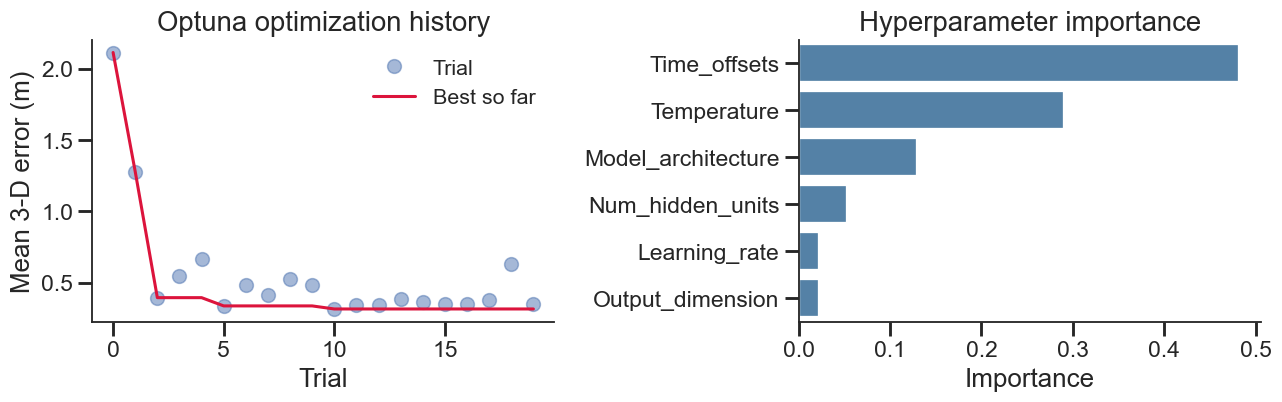

In [13]:
# === CEBRA hyperparameter search (Optuna) over the high-impact set ===
# TPE search minimising mean 3-D KNN-decoding error of position (same KNN_N /
# cosine readout as Fig 1g/h). Axes: num_hidden_units & output_dimension (same
# options as the coarse grid) plus temperature, time_offsets, learning_rate and
# the encoder receptive-field (offset) architecture. Each trial trains one
# unified CEBRA model, cached by _hp_tag(); the study is pickled (run-once).
# NOTE: cold cost ~= N_TRIALS CEBRA trainings (minus _hp_tag cache hits).
if CEBRA_OK:
    try:
        import optuna
    except ImportError:
        optuna = None
        print('optuna not installed; skipping CEBRA hyperparameter search')

    if optuna is not None:
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        HU_GRID = [32, 64, 128]                 # num_hidden_units (encoder width)
        OD_GRID = [3, 8, 32, 64]                # output_dimension (embedding dim)
        TO_GRID = [1, 5, 10, 20]                # time_offsets (positive-pair lag)
        ARCH_GRID = ['offset5-model', 'offset10-model', 'offset36-model']  # receptive field
        N_TRIALS = 20

        def _decode_score(model):
            """KNN-decode 3-D position from a fitted unified solver; per-point df."""
            tr, te = unified_embed_split(model, 'train'), unified_embed_split(model, 'test')
            recs = []
            for s in session_names:
                Etr = np.vstack([e for e, _ in tr[s]]); Ytr = np.vstack([f['pos'] for _, f in tr[s]])
                knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
                for emb, f in te[s]:
                    pred, true = np.asarray(knn.predict(emb)), f['pos']
                    e3 = np.sqrt(((true - pred) ** 2).sum(1))
                    for i in range(len(true)):
                        recs.append(dict(bat=parse_bat(s), session=s, flight_id=f['flight_id'],
                                         t_idx=int(f['t_idx'][i]),
                                         x_true=true[i, 0], y_true=true[i, 1], z_true=true[i, 2],
                                         x_pred=pred[i, 0], y_pred=pred[i, 1], z_pred=pred[i, 2],
                                         err_3d=float(e3[i])))
            return pd.DataFrame(recs)

        def objective(trial):
            CEBRA_HP['num_hidden_units'] = trial.suggest_categorical('num_hidden_units', HU_GRID)
            CEBRA_HP['output_dimension'] = trial.suggest_categorical('output_dimension', OD_GRID)
            CEBRA_HP['time_offsets'] = trial.suggest_categorical('time_offsets', TO_GRID)
            CEBRA_HP['model_architecture'] = trial.suggest_categorical('model_architecture', ARCH_GRID)
            CEBRA_HP['temperature'] = trial.suggest_float('temperature', 0.1, 1.0, log=True)
            CEBRA_HP['learning_rate'] = trial.suggest_float('learning_rate', 1e-4, 1e-3, log=True)
            path = (f'{OUT_DIR}/unified_{UNI_VARIANT}__{_hp_tag()}__it{CEBRA_MAX_ITER}'
                    f'__seed{seed}__s{len(session_names)}_{_sess_tag}.pt')
            try:
                model = fit_unified(Xs, Ys, path)
                dfc = _decode_score(model)
            except Exception as exc:
                print(f'  [prune] hu={CEBRA_HP["num_hidden_units"]} od={CEBRA_HP["output_dimension"]} '
                      f'arch={CEBRA_HP["model_architecture"]}: {type(exc).__name__}: {exc}')
                raise optuna.TrialPruned()
            trial.set_user_attr('median_frechet', float(frechet_per_flight(dfc)['frechet_3d'].median()))
            trial.set_user_attr('median_err_3d', float(dfc['err_3d'].median()))
            return float(dfc['err_3d'].mean())

        study_path = CEBRA_STUDY_PATH
        if os.path.exists(study_path):
            with open(study_path, 'rb') as fh:
                study = pickle.load(fh)
            print(f'loaded cached CEBRA study ({len(study.trials)} trials)')
        else:
            def _progress(study, trial):
                try:
                    best = f'{study.best_value:.3f} m'
                except ValueError:
                    best = 'n/a'
                err = f'{trial.value:.3f} m' if trial.value is not None else trial.state.name
                ps = ', '.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}'
                               for k, v in trial.params.items())
                print(f'[trial {trial.number + 1}/{N_TRIALS}] err={err} | best={best} | {ps}', flush=True)

            set_random_state(seed)
            study = optuna.create_study(direction='minimize',
                                        sampler=optuna.samplers.TPESampler(seed=seed))
            print(f'CEBRA hyperparameter search: {N_TRIALS} trials...', flush=True)
            study.optimize(objective, n_trials=N_TRIALS, callbacks=[_progress])
            with open(study_path, 'wb') as fh:
                pickle.dump(study, fh)
        CEBRA_HP.clear(); CEBRA_HP.update(study.best_params)  # lock CEBRA_HP to the best trial

        res = study.trials_dataframe(attrs=('number', 'value', 'params', 'user_attrs', 'state'))
        print(res.to_string(index=False))
        print('\nBest mean 3-D error: %.3f m' % study.best_value)
        for k, v in study.best_params.items():
            print(f'  {k}: {v}')

        _done = sorted((t for t in study.trials if t.value is not None), key=lambda t: t.number)
        _vals = [t.value for t in _done]
        fig_o, axo = plt.subplots(1, 2, figsize=(12, 4))
        axo[0].plot(range(len(_vals)), _vals, 'o', alpha=0.5, label='trial')
        axo[0].plot(range(len(_vals)), np.minimum.accumulate(_vals), '-', color='crimson', label='best so far')
        axo[0].set_xlabel('trial'); axo[0].set_ylabel('mean 3-D error (m)')
        axo[0].set_title('Optuna optimization history'); axo[0].legend(frameon=False)
        try:
            imp = optuna.importance.get_param_importances(study)
            sns.barplot(x=list(imp.values()), y=list(imp.keys()), color='steelblue', ax=axo[1])
            axo[1].set_xlabel('importance'); axo[1].set_title('Hyperparameter importance')
        except Exception as exc:
            axo[1].text(0.5, 0.5, f'importance n/a\n{exc}', ha='center', va='center', transform=axo[1].transAxes)
        fig_o.tight_layout(); ph.save_fig(fig_o, 'cebra_hparam_optuna'); plt.show()
else:
    print('CEBRA unavailable; skipping hyperparameter search')

In [14]:
# === Multi-session CEBRA hyperparameter search (Optuna; ED Fig 1 only) ===
# Documents/regenerates the tuning of the multi-session CEBRA decoder (the ED Fig 1
# 'CEBRA (multi)' rung), which is SEPARATE from the unified CEBRA above. 6-param TPE
# search at reduced iterations, minimising mean 3-D kNN-decoding error; the best
# trial is pickled to the exact path that the ladder's _compute_cebra_multi()
# auto-loads. Run-once & non-destructive: an existing study is loaded (never
# overwritten); raise MS_N_TRIALS above the completed-trial count to add more.
try:
    import optuna
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    from cebra import CEBRA
    from sklearn.neighbors import KNeighborsRegressor
    _MS_OK = True
except Exception as _exc:
    _MS_OK = False
    print(f'[skip multi-session CEBRA search] {type(_exc).__name__}: {_exc}')

if _MS_OK:
    MS_TUNE_ITER, MS_KNN_N, MS_N_TRIALS = 2000, 36, 20  # raise MS_N_TRIALS to extend
    MS_STUDY_PATH = f'./out/cebra/cebra_optuna_cebra_pos_seed{seed}_it{MS_TUNE_ITER}_6p.pkl'

    def _ms_flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool); spike = batch.spike.numpy()
            pos_z = batch.behavior[:, :, :3].numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append((spike[b, sel].astype(np.float32),
                            (pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32)))
        return out

    def _ms_embed(model, fl, sid):
        req = len(model.offset_); out = []
        for X, y in fl:
            Z = X if len(X) >= req else np.vstack([X, np.zeros((req - len(X), X.shape[1]), X.dtype)])
            out.append((model.transform(Z, session_id=sid)[:len(X)], y))
        return out

    def _ms_score(hp):
        set_random_state(seed)
        model = CEBRA(conditional='time_delta', max_iterations=MS_TUNE_ITER, batch_size=512,
                      distance='cosine', device='cuda_if_available', verbose=False, **hp)
        model.fit(_MS_XS, _MS_YS)
        errs = []
        for sid, s in enumerate(session_names):
            etr, ete = _ms_embed(model, _MS_TR[s], sid), _ms_embed(model, _MS_TE[s], sid)
            Etr = np.vstack([e for e, _ in etr]); Ytr = np.vstack([y for _, y in etr])
            knn = KNeighborsRegressor(n_neighbors=MS_KNN_N, metric='cosine').fit(Etr, Ytr)
            for emb, y in ete:
                errs.append(np.sqrt(((y - np.asarray(knn.predict(emb))) ** 2).sum(1)))
        return float(np.concatenate(errs).mean())

    def _ms_objective(trial):
        hp = dict(
            num_hidden_units=trial.suggest_categorical('num_hidden_units', [32, 64, 128]),
            output_dimension=trial.suggest_categorical('output_dimension', [3, 8, 32, 64]),
            time_offsets=trial.suggest_categorical('time_offsets', [1, 5, 10, 20]),
            model_architecture=trial.suggest_categorical('model_architecture',
                                                         ['offset5-model', 'offset10-model', 'offset36-model']),
            temperature=trial.suggest_float('temperature', 0.1, 1.0, log=True),
            learning_rate=trial.suggest_float('learning_rate', 1e-4, 1e-3, log=True))
        try:
            return _ms_score(hp)
        except Exception as exc:
            print(f'  [prune] {type(exc).__name__}: {exc}')
            raise optuna.TrialPruned()

    def _ms_progress(study, trial):
        try:
            best = f'{study.best_value:.3f} m'
        except ValueError:
            best = 'n/a'
        err = f'{trial.value:.3f} m' if trial.value is not None else trial.state.name
        print(f'[ms-trial {trial.number + 1}] err={err} | best={best} | '
              + ', '.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}'
                          for k, v in trial.params.items()), flush=True)

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    if os.path.exists(MS_STUDY_PATH):
        ms_study = pickle.load(open(MS_STUDY_PATH, 'rb'))
        print(f'loaded cached multi-session CEBRA study ({len(ms_study.trials)} trials)')
    else:
        ms_study = optuna.create_study(direction='minimize',
                                       sampler=optuna.samplers.TPESampler(seed=seed))

    _ms_done = sum(t.value is not None for t in ms_study.trials)
    if _ms_done < MS_N_TRIALS:
        # Only touch the data / GPU when trials actually need to run.
        _MS_TR = {s: _ms_flights(s, 'train') for s in session_names}
        _MS_TE = {s: _ms_flights(s, 'test') for s in session_names}
        _MS_XS = [np.vstack([X for X, _ in _MS_TR[s]]) for s in session_names]
        _MS_YS = [np.vstack([y for _, y in _MS_TR[s]]) for s in session_names]
        set_random_state(seed)
        print(f'running {MS_N_TRIALS - _ms_done} more multi-session CEBRA trials '
              f'@ {MS_TUNE_ITER} iters...', flush=True)
        ms_study.optimize(_ms_objective, n_trials=MS_N_TRIALS - _ms_done, callbacks=[_ms_progress])
        os.makedirs(os.path.dirname(MS_STUDY_PATH), exist_ok=True)
        pickle.dump(ms_study, open(MS_STUDY_PATH, 'wb'))
        print('saved', MS_STUDY_PATH)
    else:
        print(f'already >= {MS_N_TRIALS} completed trials; not retuning '
              f'(raise MS_N_TRIALS to extend).')

    print('\nBest multi-session CEBRA mean 3-D error: %.3f m' % ms_study.best_value)
    for _k, _v in ms_study.best_params.items():
        print(f'  {_k}: {_v}')
    print(f'ED Fig 1 loads these via _compute_cebra_multi(); if the best params change, '
          f'clear ./out/ed1_decoders/cebra_multi_seed_{seed}.pkl to rebuild that rung.')

loaded cached multi-session CEBRA study (40 trials)
already >= 20 completed trials; not retuning (raise MS_N_TRIALS to extend).

Best multi-session CEBRA mean 3-D error: 0.459 m
  model_architecture: offset10-model
  learning_rate: 0.0015218129447839347
  temperature: 0.7195109602105707
  time_offsets: 10
  output_dimension: 8
  num_hidden_units: 128
ED Fig 1 loads these via _compute_cebra_multi(); if the best params change, clear ./out/ed1_decoders/cebra_multi_seed_1.pkl to rebuild that rung.


In [15]:
# === Fig 1g: decoding accuracy for NB (place), unified CEBRA, joint ===
DECODE_LABELS = {'naive_bayes': 'Naive Bayes', 'cebra': 'Unified CEBRA', 'joint': OUR_MODEL}
DECODE_ORDER = ['naive_bayes', 'cebra', 'joint']

# Assemble per-flight Fréchet (1g) across decoders.
_fr = [joint_frechet.assign(decoder='joint'), nb_frechet.assign(decoder='naive_bayes')]
if cebra_frechet is not None:
    _fr.append(cebra_frechet.assign(decoder='cebra'))

decode_frechet_df = pd.concat(_fr, ignore_index=True)
present = [d for d in DECODE_ORDER if d in set(decode_frechet_df['decoder'])]
decode_frechet_df['decoder'] = pd.Categorical(decode_frechet_df['decoder'], present, ordered=True)

# decode_frechet_df drawn in the merged Fig 1 cell below (panel g).


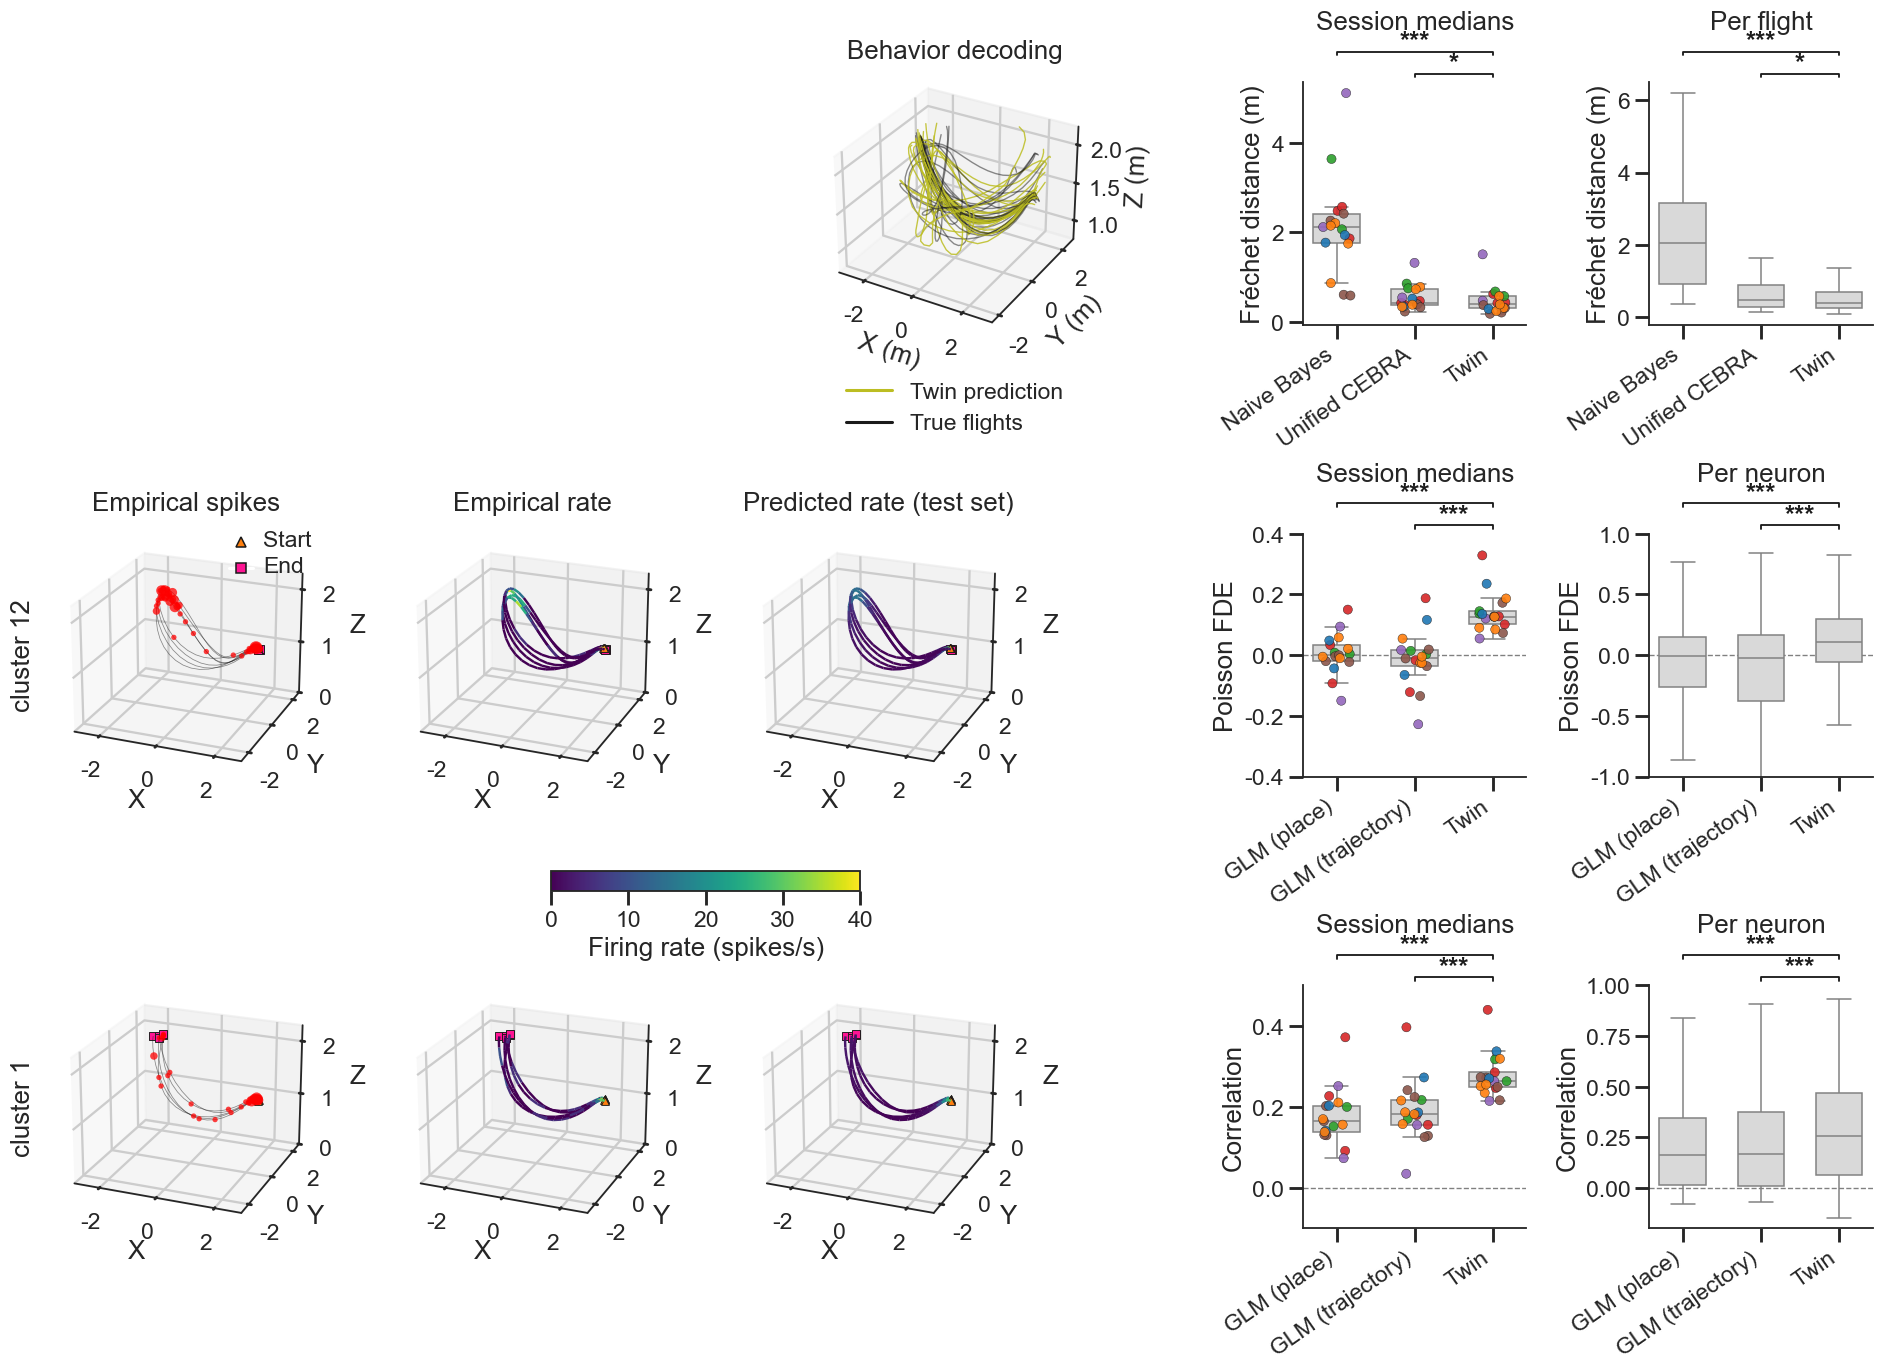


Fig 1d FDE - session-level Wilcoxon vs Twin:
    model    vs  n  median_diff         p stars         P
glm_place joint 17       0.1314 1.526e-05   *** P < 0.001
 glm_traj joint 17       0.1412 1.526e-05   *** P < 0.001

Fig 1e Pearson r - session-level Wilcoxon vs Twin:
    model    vs  n  median_diff         p stars         P
glm_place joint 17       0.1087 1.526e-05   *** P < 0.001
 glm_traj joint 17      0.09091 1.526e-05   *** P < 0.001

Fig 1g Frechet - session-level Wilcoxon vs Twin:
      model    vs  n  median_diff         p stars         P
naive_bayes joint 17        1.642 1.526e-05   *** P < 0.001
      cebra joint 17      0.07054   0.03954     * P = 0.040


In [16]:
# === Figure 1 (c-g) on a single canvas ===
# a-b are external schematics. Layout (3 rows x 5 cols):
#   row 1: .  | .  | f (decoded 3D) | g(sess) g(flight)   -- right-aligned with the 3 cols below
#   row 2: c | d | e (spikes | empirical | predicted, route 1) | FDE(sess) FDE(neuron)
#   row 3: c | d | e (spikes | empirical | predicted, route 2) | r(sess)  r(neuron)
# Panels: c-e = dual-field example (one per map column); d = Poisson FDE;
#   e = Pearson r; f = decoding example; g = Fréchet distance.
# Font sizes are applied per-panel at the end (see _apply_panel_fonts) so every
# individual title / axis label / tick label / legend is the same size, whether
# or not ph.set_pub_style() was re-run this session.
FS_TITLE, FS_LABEL, FS_TICK, FS_LEG = 17, 17, 15, 15

fig1 = plt.figure(figsize=(23, 14))
gs1 = fig1.add_gridspec(3, 5, hspace=0.6, wspace=0.55)

# f: example decoded 3-D trajectory (row 1, col 2; cols 0-1 are left as a gap)
ax_f = fig1.add_subplot(gs1[0, 2], projection='3d')
for _, gfl in (joint_decode_test[joint_decode_test['session'] == zoom_session]
               .sort_values('t_idx').groupby('flight_id')):
    ax_f.plot(gfl['x_true'], gfl['y_true'], gfl['z_true'], color='k', lw=0.9, alpha=0.5)
    ax_f.plot(gfl['x_pred'], gfl['y_pred'], gfl['z_pred'], color='tab:olive', lw=0.9, alpha=0.85)
ax_f.set_xlabel('x (m)', fontsize=FS_LABEL); ax_f.set_ylabel('y (m)', fontsize=FS_LABEL)
ax_f.set_zlabel('z (m)', fontsize=FS_LABEL)
ax_f.set_title('Behavior decoding')
# legend below the axes
ax_f.legend(handles=[plt.Line2D([], [], color='tab:olive', label=f'{OUR_MODEL} prediction'),
                     plt.Line2D([], [], color='k', label='true flights')],
            loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=1, fontsize=FS_LEG)

# g: decoding accuracy as per-flight 3-D Fréchet distance (row 1, cols 3-4)
axg = (fig1.add_subplot(gs1[0, 3]), fig1.add_subplot(gs1[0, 4]))
_, ptab_g = ph.compare_models_fig(
    decode_frechet_df, 'frechet_3d', present, ref='joint', labels=DECODE_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight', higher_is_better=False,
    star_style='bracket', star_kw={'star_gap': -0.012}, title_y=1.18, axes=axg)

# c-e: dual-field example unit, 3-D maps (rows 2-3, cols 1-3); columns are the
# c (spikes), d (empirical rate), e (predicted rate) panels. Assumes 2 routes.
ax_c = np.array([[fig1.add_subplot(gs1[r + 1, cc], projection='3d') for cc in range(3)]
                 for r in range(len(pk['clusters']))], dtype=object)
sm_c = plot_dual_field_cell(pk['flights'], pk['neuron'], pk['clusters'], dt, pk['r_lim'],
                            peaks=pk['peaks'], axes3d=ax_c, col_title_fs=FS_TITLE, row_label_fs=FS_LABEL)
# shrink horizontal gaps between the 3 map columns to match the comparison-pair pull:
# pull the outer columns (c spikes, e predicted) toward the fixed centre (d empirical)
_MAP_PULL = 0.03
for _r in range(ax_c.shape[0]):
    for _cc, _sh in ((0, _MAP_PULL), (2, -_MAP_PULL)):
        _pm = ax_c[_r, _cc].get_position()
        ax_c[_r, _cc].set_position([_pm.x0 + _sh, _pm.y0, _pm.width, _pm.height])
# horizontal rate colourbar between the two map rows, below the right two (empirical,
# predicted) map columns
_p0, _p0b = ax_c[0, 1].get_position(), ax_c[0, 2].get_position()
_cbw = (_p0b.x1 - _p0.x0) / 2
_ymid = (_p0.y0 + ax_c[1, 1].get_position().y1) / 2
_cax = fig1.add_axes([_p0.x0 + _cbw / 2, _ymid - 0.013 / 2, _cbw, 0.013])
fig1.colorbar(sm_c, cax=_cax, orientation='horizontal', label='firing rate (spikes/s)')

# d, e: encoding fit (rows 2-3, cols 4-5) -- d = Poisson FDE, e = Pearson r
axd = (fig1.add_subplot(gs1[1, 3]), fig1.add_subplot(gs1[1, 4]))
_, ptab_d = ph.compare_models_fig(
    encode_metrics_df, 'fde', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Poisson FDE', unit_name='neuron', clip=(-1, 1), zero_line=True, sess_ylim=(-0.4, 0.4),
    star_style='bracket', star_kw={'star_gap': -0.012}, title_y=1.18, axes=axd)
axe = (fig1.add_subplot(gs1[2, 3]), fig1.add_subplot(gs1[2, 4]))
_, ptab_e = ph.compare_models_fig(
    encode_metrics_df, 'corr', ENC_ORDER, ref='joint', labels=ENC_LABELS,
    ylabel='Correlation', unit_name='neuron', clip=(-0.2, 1), zero_line=True, sess_ylim=(-0.1, 0.5),
    star_style='bracket', star_kw={'star_gap': -0.012}, title_y=1.18, axes=axe)

# shrink the 2-D comparison panels so they match the (margin-padded) 3-D panels and
# their tick labels don't collide with neighbours
def _shrink(ax, fx=0.82, fy=0.86):
    p = ax.get_position()
    ax.set_position([p.x0 + p.width * (1 - fx) / 2, p.y0 + p.height * (1 - fy) / 2,
                     p.width * fx, p.height * fy])
for _pair in (axd, axe, axg):
    for _ax in _pair:
        _shrink(_ax)
# slightly shrink the intra-pair gap (session | per-unit) by pulling each pair's two
# panels toward each other
_GAP_PULL = 0.015
for _sess_ax, _unit_ax in (axd, axe, axg):
    _ps, _pu = _sess_ax.get_position(), _unit_ax.get_position()
    _sess_ax.set_position([_ps.x0 + _GAP_PULL, _ps.y0, _ps.width, _ps.height])
    _unit_ax.set_position([_pu.x0 - _GAP_PULL, _pu.y0, _pu.width, _pu.height])

# Enforce a single consistent font size on every panel individually (titles, x/y/z
# axis labels, tick labels, and legend text), so nothing depends on the global
# rcParams having been refreshed by ph.set_pub_style() this session.
def _apply_panel_fonts(ax):
    ax.title.set_fontsize(FS_TITLE)
    ax.xaxis.label.set_fontsize(FS_LABEL)
    ax.yaxis.label.set_fontsize(FS_LABEL)
    if hasattr(ax, 'zaxis'):
        ax.zaxis.label.set_fontsize(FS_LABEL)
    ax.tick_params(labelsize=FS_TICK)
    _lg = ax.get_legend()
    if _lg is not None:
        for _t in _lg.get_texts():
            _t.set_fontsize(FS_LEG)
        if _lg.get_title() is not None:
            _lg.get_title().set_fontsize(FS_LEG)
for _ax in fig1.get_axes():
    _apply_panel_fonts(_ax)

ph.save_fig(fig1, 'fig1_full'); plt.show()
for _n, _pt in [('1d FDE', ptab_d), ('1e Pearson r', ptab_e), ('1g Frechet', ptab_g)]:
    print(f'\nFig {_n} - session-level Wilcoxon vs {OUR_MODEL}:'); ph.p_table(_pt.to_dict('records'))


**Figure 1 | Transformer-based encoding/decoding models outperform standard approaches on hippocampal data.**
**a–b**, Model schematics (masking scheme; dual-branch architecture), drawn separately.
**c**, An example unit with spatially separated place fields on two different flight routes (3-D views). For each unit and route: observed spikes (red, area ∝ count) on the flight path, the empirical firing-rate map, and the joint model's predicted-rate map (empirical and predicted share a colour scale).
**d–e**, Encoding fit quantified as per-neuron Poisson fraction deviance explained (**d**) and Pearson correlation (**e**) between predicted and observed spike trains on held-out flights, for a place GLM, a trajectory-specific-place GLM, and the joint transformer. Left, session medians (points = sessions, coloured by bat); right, all neurons pooled. Boxes show median and IQR; whiskers 1.5× IQR.
**f**, Representative decoded (olive) versus true (black) 3-D flight trajectories from the joint decoder for one session.
**g**, Decoding accuracy as per-flight 3-D discrete Fréchet distance for a naïve-Bayes place decoder, unified CEBRA, and the joint decoder.
Stars denote two-sided Wilcoxon signed-rank tests on paired per-session medians versus the joint model (*P* < 0.05 *, *P* < 0.01 **, *P* < 0.001 ***); n.s. comparisons are unmarked. Exact *P* values are printed in the tables above each panel. FDE axes are clipped to [−1, 1] for display; all statistics use raw values.

---
## Extended Data Figure 1 — full model ladders

**a–b** Per-neuron encoding fit (Poisson FDE, Pearson r) for every model in `model_comparison.ipynb`. **c** Per-flight decoding accuracy (3-D Fréchet distance) for the full decoder ladder in `decode-position-comparison.ipynb`. Stars: session-level Wilcoxon vs the joint model. (`GLM + lags + kin` is omitted — it requires the kinematics-augmented behaviour, incompatible with the position-only single load; re-enable with a separate kinematics loader if needed.)

In [17]:
# === ED Fig 1a/b: all encoding models (per-neuron FDE + corr) ===
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.former_defaults import (make_model_config, make_model_name,
                                              DEFAULT_LR, DEFAULT_WEIGHT_DECAY)
from digitalbat.models.glm import make_symmetric_raised_cosine_basis

# Temporal-filter bases (match model_comparison.ipynb).
HIST_N_BASIS, COUP_N_BASIS, ACAUSAL_N_BASIS = 6, 4, 6
hist_basis, _, _ = make_log_raised_cosine_basis(HIST_N_BASIS, N_LAGS, bin_width)
coup_basis, _, _ = make_log_raised_cosine_basis(COUP_N_BASIS, N_LAGS, bin_width, include_zero_lag=True)
acausal_basis, _, _ = make_symmetric_raised_cosine_basis(ACAUSAL_N_BASIS, N_LAGS, bin_width)
glm_lags = np.arange(-1.0, 1.0 + 1e-9, 0.2).tolist()
DATA_TAG, GLM_TAG = '_acc50_preln_17_sess', '_acc50_default17'


def build_glm(name, cond):
    ck = cluster_keys_by_session if cond == 'joint' else None
    if name == 'GLM' and cond == 'position':
        return GLM_3DCosineBasis(**_glm_common, output_dim_dict=unit_num_dict)
    if name == 'GLM + lags':
        return GLM_3DCosineBasis(**_glm_common, output_dim_dict=unit_num_dict, lag_seconds=glm_lags)
    return GLM_Coupled(output_dim_dict=unit_num_dict, **_glm_common,
                       hist_basis=hist_basis if 'hist' in name else None,
                       coup_basis=coup_basis if 'coup' in name else None,
                       acausal_basis=acausal_basis if 'acausal' in name else None,
                       n_lags=N_LAGS, cluster_keys=ck)


def glm_ckpt(name, cond):
    tag = name.lower().replace(' + ', '_').replace(' ', '_')
    return f'./out/bat_glm/bat_{tag}_{cond}_seed_{seed}_optuna{GLM_TAG}.pth'


# Full-arch transformer config from the pre-LN Optuna search.
import json as _json
_ep = f'./out/bat_former/former_best_params{DATA_TAG}_seed_{seed}.json'
_arch = ({k: _json.load(open(_ep))[k] for k in ('latent_dim', 'ff_dim', 'num_layers', 'dropout_prob')
          if k in _json.load(open(_ep))} if os.path.exists(_ep) else {})
base_cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict, **_arch)


def build_former(kind):
    if kind == 'transformer':
        return Bat_Transformer(**base_cfg)
    if kind == 'mlp':
        return Bat_Transformer(**{**base_cfg, 'use_attention': False})
    return Bat_Transformer(**{**base_cfg, 'latent_dim': 32, 'ff_dim': 32, 'num_layers': 1})


@torch.no_grad()
def eval_former_metrics(model):
    model = model.to(device).eval()
    rows = []
    for sn, sd in dataloaders['test'].items():
        yv, yp = [], []
        for b in sd:
            m = b.mask.to(device)
            out = model(sn, b.behavior.to(device), m)
            v = m == 1.0
            yv.append(b.spike.to(device)[v].cpu().numpy()); yp.append(out[v].cpu().numpy())
        yv, yp = np.vstack(yv), np.vstack(yp)
        c, f = corr(yv, yp, axis=0), poisson_fde_population(yv, yp)
        for u in range(yv.shape[1]):
            rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, corr=float(c[u]), fde=float(f[u])))
    return pd.DataFrame(rows)


# Registry: (display label, kind, spec). Joint GLMs get a '(joint)' suffix.
ED1_MODELS = [
    ('GLM (place)',                    'glm',    ('GLM', 'position')),
    ('GLM + lags (place)',             'glm',    ('GLM + lags', 'position')),
    ('GLM + hist (place)',             'glm',    ('GLM + hist', 'position')),
    ('GLM + coup (place)',             'glm',    ('GLM + coup', 'position')),
    ('GLM + hist + coup (place)',      'glm',    ('GLM + hist + coup', 'position')),
    ('GLM + acausal (place)',          'glm',    ('GLM + acausal', 'position')),
    ('GLM (trajectory)',               'glm',    ('GLM', 'joint')),
    ('GLM + hist (trajectory)',        'glm',    ('GLM + hist', 'joint')),
    ('GLM + coup (trajectory)',        'glm',    ('GLM + coup', 'joint')),
    ('GLM + hist + coup (trajectory)', 'glm',    ('GLM + hist + coup', 'joint')),
    ('GLM + acausal (trajectory)',     'glm',    ('GLM + acausal', 'joint')),
    ('MLP only',                       'former', 'mlp'),
    (OUR_MODEL,                       'joint',  None),
]
ED1_ORDER = [m[0] for m in ED1_MODELS]

_pieces = []
for label, kind, spec in ED1_MODELS:
    try:
        if kind == 'glm':
            name, cond = spec
            gm = ensure_glm(glm_ckpt(name, cond), lambda: build_glm(name, cond),
                            cond=cond, search_alpha=('coup' in name))
            df = eval_glm_metrics(gm, joint_cond=(cond == 'joint'))
        elif kind == 'former':
            ck = make_model_name(seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                                 out_dir={'transformer': './out/bat_former', 'mlp': './out/bat_former_no_attn',
                                          'small': './out/bat_former_small'}[spec], suffix=DATA_TAG)
            fm = ensure_former(ck, lambda: build_former(spec))
            df = eval_former_metrics(fm)
        else:
            df = encode_eval_records(bat_former, dataloaders, device)
        _pieces.append(df.assign(model=label))
        print(f'  ok: {label}')
    except Exception as exc:
        print(f'  [skip {label}] {type(exc).__name__}: {exc}')

ed1_encode_df = pd.concat(_pieces, ignore_index=True)
ed1_present = [m for m in ED1_ORDER if m in set(ed1_encode_df['model'])]
ed1_encode_df['model'] = pd.Categorical(ed1_encode_df['model'], ed1_present, ordered=True)
print('ED1 encode models:', ed1_present)

  ok: GLM (place)
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
  ok: GLM + lags (place)
  ok: GLM + hist (place)
  ok: GLM + coup (place)
  ok: GLM + hist + coup (place)
  ok: GLM + acausal (place)
  ok: GLM (trajectory)
  ok: GLM + hist (trajectory)
  ok: GLM + coup (trajectory)
  ok: GLM + hist + coup (trajectory)
  ok: GLM + acausal (trajectory)
  ok: MLP only
  ok: Twin
ED1 encode models: ['GLM (place)', 'GLM + lags (place)', 'GLM + hist (place)', 'GLM + coup (place)', 'GLM + hist + coup (place)', 'GLM + acausal (place)', 'GLM (trajectory)', 'GLM + hist (trajectory)', 'GLM + coup (trajectory)', 'GLM + hist + coup (trajectory)', 'GLM + acausal (trajectory)', 'MLP only', 'Twin']


In [18]:
# === Tampuu et al. (2019) LSTM-RNN decoder: Optuna search + train (ED Fig 1) ===
# Reference implementation: github.com/NeuroCSUT/RatGPS (ratlstm.py / ratdata.py).
# Their decoder is a many-to-one LSTM (2x512 units, dropout 0.5, linear head,
# MSE loss, RMSprop) fed a sequence of spike-count vectors and asked to predict
# the position at the last timestep. We port it to the multi-session bat setting
# as the ED Fig 1 'LSTM-RNN' rung: a per-session linear readin (neurons ->
# hidden -- the minimal change needed to share one recurrent core across
# sessions with different neuron counts) feeds a UNIDIRECTIONAL LSTM (causal, as
# in Tampuu, who explicitly reject bidirectional), and a shared linear head maps
# each timestep's hidden state to z-scored 3D position. Because the loss/eval are
# masked over every valid timestep of a flight (rather than one per sequence),
# the causal LSTM is effectively "many-to-one at every timestep". Training reuses
# the package `bat_decoder_trainer` (round-robin across sessions, masked loss).
# Hyperparameters are Optuna-tuned (TPE, N_TRIALS=20) to minimise mean 3-D error
# in metres on the validation flights. Run-once & non-destructive: an existing
# study/checkpoint is loaded; raise LSTM_N_TRIALS to add trials.
from digitalbat.models.decoder import bat_decoder_trainer

LSTM_OUT_DIR = './out/lstm_rnn'
os.makedirs(LSTM_OUT_DIR, exist_ok=True)
LSTM_STUDY_PATH = f'{LSTM_OUT_DIR}/lstm_rnn_optuna_seed{seed}.pkl'
LSTM_CKPT = f'{LSTM_OUT_DIR}/lstm_rnn_decoder_seed{seed}.pth'
LSTM_N_TRIALS, LSTM_MAX_EPOCHS, LSTM_PATIENCE = 20, 1000, 30
# Tampuu et al.'s published config, mapped into our search space (their weight
# decay 0 -> the log-range floor; readin_dropout is our multi-session addition).
# Enqueued as the FIRST trial so the paper's exact architecture is always
# evaluated -- a faithful baseline alongside the tuned best.
LSTM_TAMPUU_DEFAULT = dict(hidden_size=512, num_layers=2, dropout_prob=0.5,
                          readin_dropout=0.1, input_transform='identity',
                          loss_name='mse', lr=1e-3, weight_decay=1e-5)


class LSTMDecoder(nn.Module):
    """Tampuu et al. (2019) style RNN decoder: spikes -> z-scored 3D position.

    Per-session ``nn.Linear(K_session, hidden_size)`` readin (analogue of the
    transformer decoder's readins) feeds a unidirectional multi-layer LSTM; a
    shared linear head maps every timestep's hidden state to position. The
    ``forward`` signature mirrors ``Bat_Transformer_Decoder`` (extra attention
    kwargs are accepted and ignored) so it is a drop-in for ``bat_decoder_trainer``.
    """

    def __init__(self, input_dim_dict, output_dim=3, hidden_size=256, num_layers=2,
                 dropout_prob=0.5, readin_dropout=0.1, input_transform='identity'):
        super().__init__()
        if input_transform not in ('identity', 'sqrt'):
            raise ValueError(f"input_transform must be 'identity' or 'sqrt', got {input_transform!r}")
        self.input_transform = input_transform
        self.readins = nn.ModuleDict({
            s: nn.Linear(k, hidden_size) for s, k in input_dim_dict.items()})
        self.readin_dropout = nn.Dropout(readin_dropout)
        self.lstm = nn.LSTM(hidden_size, hidden_size, num_layers=num_layers,
                            dropout=(dropout_prob if num_layers > 1 else 0.0),
                            batch_first=True)
        self.head = nn.Linear(hidden_size, output_dim)

    def forward(self, session_name, spikes, mask, **kwargs):
        """spikes: (B, T, K_session). mask: (B, T) float, 1.0 valid. -> (B, T, 3)."""
        if self.input_transform == 'sqrt':
            spikes = torch.sqrt(torch.clamp(spikes, min=0.0))
        x = self.readin_dropout(self.readins[session_name](spikes))
        x = x * mask.to(x.dtype).unsqueeze(-1)   # zero padded (tail) steps
        x, _ = self.lstm(x)
        return self.head(x)


_LSTM_ARCH_KEYS = ('hidden_size', 'num_layers', 'dropout_prob', 'readin_dropout', 'input_transform')


def _build_lstm(hp):
    return LSTMDecoder(unit_num_dict, output_dim=3,
                       **{k: hp[k] for k in _LSTM_ARCH_KEYS if k in hp})


def _lstm_loss(hp):
    return nn.MSELoss() if hp.get('loss_name', 'huber') == 'mse' else nn.SmoothL1Loss()


def _lstm_val_err_m(model):
    """Mean 3-D decoding error (metres) over the validation flights, un-z-scored
    per session (comparable across sessions, unlike the pooled z-scored error the
    trainer uses for early stopping). Difference in dim d scales by that dim's std."""
    model.eval(); errs = []
    with torch.no_grad():
        for sn, sd in dataloaders['valid'].items():
            bs = np.asarray(meta_info_dict['behavior_std'][sn]).squeeze()[:3]
            for batch in sd:
                m = batch.mask.to(device)
                yp = model(sn, batch.spike.to(device), m)[m == 1.0].cpu().numpy()
                yt = batch.behavior[:, :, :3].to(device)[m == 1.0].cpu().numpy()
                errs.append(np.sqrt((((yt - yp) * bs[None]) ** 2).sum(1)))
    return float(np.concatenate(errs).mean())


def _lstm_train(hp, save_path=None):
    set_random_state(seed)
    model = _build_lstm(hp).to(device)
    bat_decoder_trainer(
        model=model, dataloaders=dataloaders, device=device, pos_dims=3,
        n_epochs=LSTM_MAX_EPOCHS, lr=hp['lr'], weight_decay=hp['weight_decay'],
        loss_fn=_lstm_loss(hp), valid_fn=lambda yt, yp: -np.sqrt(((yt - yp) ** 2).sum(1)),
        valid_stat='median', early_stopping_patience=LSTM_PATIENCE,
        save_model=save_path is not None, model_name=save_path or 'best_lstm_weights.pth')
    return model


def _lstm_objective(trial):
    hp = dict(
        hidden_size=trial.suggest_categorical('hidden_size', [128, 256, 512]),
        num_layers=trial.suggest_categorical('num_layers', [1, 2, 3]),
        dropout_prob=trial.suggest_float('dropout_prob', 0.0, 0.5),
        readin_dropout=trial.suggest_float('readin_dropout', 0.0, 0.3),
        input_transform=trial.suggest_categorical('input_transform', ['identity', 'sqrt']),
        loss_name=trial.suggest_categorical('loss_name', ['mse', 'huber']),
        lr=trial.suggest_float('lr', 1e-4, 3e-3, log=True),
        weight_decay=trial.suggest_float('weight_decay', 1e-5, 1e-1, log=True))
    return _lstm_val_err_m(_lstm_train(hp))


optuna.logging.set_verbosity(optuna.logging.WARNING)
if os.path.exists(LSTM_STUDY_PATH):
    lstm_study = pickle.load(open(LSTM_STUDY_PATH, 'rb'))
    print(f'loaded cached LSTM-RNN study ({len(lstm_study.trials)} trials)')
else:
    lstm_study = optuna.create_study(direction='minimize',
                                     sampler=optuna.samplers.TPESampler(seed=seed))
    lstm_study.enqueue_trial(LSTM_TAMPUU_DEFAULT)  # paper's config runs first

_lstm_done = sum(t.value is not None for t in lstm_study.trials)
if _lstm_done < LSTM_N_TRIALS:
    print(f'running {LSTM_N_TRIALS - _lstm_done} more LSTM-RNN trials '
          f'@ up to {LSTM_MAX_EPOCHS} epochs (patience {LSTM_PATIENCE})...', flush=True)
    lstm_study.optimize(_lstm_objective, n_trials=LSTM_N_TRIALS - _lstm_done,
                        callbacks=[_optuna_progress])
    os.makedirs(os.path.dirname(LSTM_STUDY_PATH), exist_ok=True)
    pickle.dump(lstm_study, open(LSTM_STUDY_PATH, 'wb'))
    print('saved', LSTM_STUDY_PATH)
else:
    print(f'already >= {LSTM_N_TRIALS} completed trials; not retuning '
          f'(raise LSTM_N_TRIALS to extend).')

LSTM_BEST_HP = dict(lstm_study.best_params)
print('\nBest LSTM-RNN mean 3-D error: %.3f m' % lstm_study.best_value)
for _k, _v in LSTM_BEST_HP.items():
    print(f'  {_k}: {_v}')

# Train (once) the final multi-session model at the best hyperparameters and cache
# its weights; the ED Fig 1 ladder's _compute_lstm_rnn() loads these for inference.
if not os.path.exists(LSTM_CKPT):
    print(f'[train LSTM-RNN] {os.path.basename(LSTM_CKPT)}', flush=True)
    _lstm_train(LSTM_BEST_HP, save_path=LSTM_CKPT)
    print('saved', LSTM_CKPT)
else:
    print(f'loaded cached LSTM-RNN checkpoint {os.path.basename(LSTM_CKPT)} '
          f'(delete to retrain after changing best params).')


loaded cached LSTM-RNN study (20 trials)
already >= 20 completed trials; not retuning (raise LSTM_N_TRIALS to extend).

Best LSTM-RNN mean 3-D error: 0.520 m
  hidden_size: 256
  num_layers: 2
  dropout_prob: 0.2486802489214906
  readin_dropout: 0.2040839264573858
  input_transform: sqrt
  loss_name: mse
  lr: 0.0026196864929531713
  weight_decay: 0.010759383459438353
loaded cached LSTM-RNN checkpoint lstm_rnn_decoder_seed1.pth (delete to retrain after changing best params).


In [19]:
# === ED Fig 1c/d: decoder ladder (9 decoders) ===
# Ladder vs Twin, in the order requested for ED Fig 1c/d:
#   NB (place), NB (place)+continuity, NB (trajectory), NB (trajectory)+continuity,
#   GLM + coup (place), GLM + hist + coup (place), CEBRA (multi), Unified CEBRA,
#   Twin.
# The bespoke decoders (trajectory-cluster NB, GLM-inversion MAP, multi-session
# CEBRA) are ported from decode-position-comparison.ipynb (real-data path, 3D
# only). Each heavy fit runs ONCE, is pickled under ./out/ed1_decoders/, and is
# loaded on re-run (same run-once/save/load pattern as the GLM / NB / CEBRA
# checkpoints elsewhere in this notebook).
import copy as _copy
from digitalbat.models.decoder import (NaiveBayes_Continuity_Decoder, GLM_MAP_Decoder)
from digitalbat.models.glm import GLM_Coupled

ED1_DEC_DIR = './out/ed1_decoders'
os.makedirs(ED1_DEC_DIR, exist_ok=True)


def _cache_records(path, compute):
    """Run ``compute() -> DataFrame`` once, pickle it, and load on later runs."""
    if os.path.exists(path):
        return pd.read_pickle(path)
    df = compute()
    df.to_pickle(path)
    return df


def make_nb_continuity(ndim, r_lim, c_speed, nb_hp):
    n_bins = ((nb_hp['n_bins_x'], nb_hp['n_bins_y'], nb_hp['n_bins_z']) if ndim == 3
              else (nb_hp['n_bins_x'], nb_hp['n_bins_y']))
    return NaiveBayes_Continuity_Decoder(
        c_speed=c_speed, sigma_min=0.02, sigma_max=5.0, n_bins=n_bins,
        lims=[tuple(r_lim[d]) for d in range(ndim)], sigma=nb_hp['sigma'],
        dt=bin_width, min_occupancy=nb_hp['min_occupancy'],
        use_uniform_prior=nb_hp['use_uniform_prior'])


# Continuity speed factor (shared by NB+continuity and the GLM-inversion warm start).
with open(f'./out/nb_decoder/nb_cont_decoder_3d_seed_{seed}_optuna.pkl', 'rb') as _fh:
    C_SPEED_3D = pickle.load(_fh).best_params['c_speed']


def _records_3d(arr, pred3, session, bat):
    """Per-timestep decode-schema records (x/y/z true+pred, err_3d)."""
    te3 = np.column_stack([arr['pos_x'], arr['pos_y'], arr['pos_z']])
    out = []
    for i in np.flatnonzero(~np.isnan(pred3[:, 0])):
        out.append(dict(bat=bat, session=session, flight_id=int(arr['flight_id'][i]),
                        t_idx=int(arr['t_idx'][i]),
                        x_true=float(te3[i, 0]), y_true=float(te3[i, 1]), z_true=float(te3[i, 2]),
                        x_pred=float(pred3[i, 0]), y_pred=float(pred3[i, 1]), z_pred=float(pred3[i, 2]),
                        err_3d=float(np.sqrt(((te3[i] - pred3[i]) ** 2).sum()))))
    return out


def _compute_nb_cont():
    """NB (place) + continuity, 3D — same c_speed / nb_best as elsewhere."""
    recs = []
    for sn in dataloaders['test']:
        bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
        r_lim = meta_info_dict['r_lim'][sn]
        tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
            continue
        tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
        nbc = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
            tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
        pred3, _ = nbc.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'])
        recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
    return pd.DataFrame(recs)


def _gather_with_cluster(loader, bm, bs):
    """gather_session_arrays + per-timestep train-only ``flight_type_index``."""
    spk, beh, msk, fpi, fti = [], [], [], [], []
    for batch in loader:
        spk.append(batch.spike.numpy()); beh.append(batch.behavior.numpy())
        msk.append(batch.mask.numpy().astype(bool))
        fpi.append(batch.flight_path_index.numpy()); fti.append(batch.flight_type_index.numpy())
    spk = np.concatenate(spk); beh = np.concatenate(beh)
    msk = np.concatenate(msk); fpi = np.concatenate(fpi); fti = np.concatenate(fti)
    bm_a, bs_a = np.asarray(bm).squeeze(), np.asarray(bs).squeeze()
    pos = beh[..., :3] * bs_a[None, None, :3] + bm_a[None, None, :3]
    B, T = msk.shape
    fpi_t = np.broadcast_to(fpi[:, None], (B, T)); fti_t = np.broadcast_to(fti[:, None], (B, T))
    tix = np.broadcast_to(np.arange(T)[None, :], (B, T))
    return dict(spikes=spk[msk], pos_x=pos[..., 0][msk], pos_y=pos[..., 1][msk],
                pos_z=pos[..., 2][msk], flight_id=fpi_t[msk].astype(int),
                flight_type=fti_t[msk].astype(int), t_idx=tix[msk].astype(int))


# ---------------------------------------------------------------------------
# (1) trajectory-cluster NB (naive_bayes_cluster) + continuity variant, 3D.
#     Per flight-cluster rate maps, routed by flight_type at decode time.
# ---------------------------------------------------------------------------
MIN_CLUSTER_FLIGHTS = 3


def _major_clusters(arr):
    seen, counts = set(), {}
    for fid, c in zip(arr['flight_id'], arr['flight_type']):
        if fid in seen:
            continue
        seen.add(fid); counts[int(c)] = counts.get(int(c), 0) + 1
    return {c for c, n in counts.items() if n >= MIN_CLUSTER_FLIGHTS}


def _subset(arr, m):
    return {k: (v[m] if isinstance(v, np.ndarray) else v) for k, v in arr.items()}


def _fit_per_cluster(train, r_lim, continuity):
    major = _major_clusters(train)
    preds = {}
    for c in list(major) + ['other']:
        m = (~np.isin(train['flight_type'], list(major)) if c == 'other'
             else train['flight_type'] == c)
        if m.sum() < 50:
            continue
        sub = _subset(train, m)
        pos3 = np.column_stack([sub['pos_x'], sub['pos_y'], sub['pos_z']])
        try:
            if continuity:
                preds[c] = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
                    sub['spikes'], pos3, flight_id=sub['flight_id'], t_idx=sub['t_idx'], dt=bin_width)
            else:
                preds[c] = make_nb(3, r_lim, nb_best[3]).fit(sub['spikes'], pos3)
        except Exception:
            continue
    return preds


def _route_predict(arr, preds, continuity):
    if not preds:
        return None
    pred = np.full((arr['spikes'].shape[0], 3), np.nan)
    for c in np.unique(arr['flight_type']):
        m = arr['flight_type'] == c
        nb_c = preds.get(int(c)) or preds.get('other')
        if nb_c is None:
            continue
        if continuity:
            p, _ = nb_c.predict(arr['spikes'][m], flight_id=arr['flight_id'][m], t_idx=arr['t_idx'][m])
        else:
            p, _ = nb_c.predict(arr['spikes'][m])
        pred[m] = p
    return pred


def _compute_cluster_nb(continuity):
    def _fn():
        recs = []
        for sn in dataloaders['test']:
            bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
            r_lim = meta_info_dict['r_lim'][sn]
            tr = _gather_with_cluster(dataloaders['train'][sn], bm, bs)
            te = _gather_with_cluster(dataloaders['test'][sn], bm, bs)
            if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
                continue
            preds = _fit_per_cluster(tr, r_lim, continuity)
            pred3 = _route_predict(te, preds, continuity)
            if pred3 is not None:
                recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
        return pd.DataFrame(recs)
    return _fn


# ---------------------------------------------------------------------------
# (2) GLM-inversion MAP decoders (glm_map = GLM+hist+coup, glm_map_coup = coup
#     only), position conditioning, 3D. Invert the fixed real-trained encoders
#     with an NB+continuity warm start (same c_speed as nb_continuity).
# ---------------------------------------------------------------------------
def _load_glm_encoder(ckpt, with_hist):
    kw = dict(output_dim_dict=unit_num_dict, **_glm_common, coup_basis=coup_basis, n_lags=N_LAGS)
    if with_hist:
        kw['hist_basis'] = hist_basis
    glm = GLM_Coupled(**kw)
    miss, _ = glm.load_state_dict(torch.load(ckpt, map_location=device), strict=False)
    assert not miss, f'{ckpt} missing required keys: {miss[:5]}'
    return glm.to(device).eval()


def _compute_glm_map(ckpt, with_hist):
    def _fn():
        enc = _load_glm_encoder(ckpt, with_hist)
        recs = []
        for sn in dataloaders['test']:
            bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
            r_lim = meta_info_dict['r_lim'][sn]
            tr = gather_session_arrays(dataloaders['train'][sn], bm, bs)
            te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
            if tr['spikes'].shape[0] < 100 or te['spikes'].shape[0] < 10:
                continue
            tr3 = np.column_stack([tr['pos_x'], tr['pos_y'], tr['pos_z']])
            warm_nb = make_nb_continuity(3, r_lim, C_SPEED_3D, nb_best[3]).fit(
                tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
            dec = GLM_MAP_Decoder(enc, sn, bm, bs, device=device).fit(
                tr['spikes'], tr3, flight_id=tr['flight_id'], t_idx=tr['t_idx'], dt=bin_width)
            warm, _ = warm_nb.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'])
            pred3, _ = dec.predict(te['spikes'], flight_id=te['flight_id'], t_idx=te['t_idx'],
                                   warm_start=warm)
            recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
        return pd.DataFrame(recs)
    return _fn


# ---------------------------------------------------------------------------
# (3) multi-session CEBRA (position-informed, kNN read-out). Reuses the cached
#     Optuna-tuned multi-session checkpoint (never retrained here).
# ---------------------------------------------------------------------------
def _compute_cebra_multi():
    import hashlib
    from sklearn.neighbors import KNeighborsRegressor
    sys.path.insert(0, os.path.expanduser('~/Documents/code/CEBRA'))
    from cebra import CEBRA
    OUT_DIR, MAX_ITER, KNN_N = './out/cebra', 6000, 36
    HP = dict(model_architecture='offset10-model', learning_rate=3e-4, temperature=1.0,
              time_offsets=10, output_dimension=3, num_hidden_units=32)
    study_path = f'{OUT_DIR}/cebra_optuna_cebra_pos_seed{seed}_it2000_6p.pkl'
    if os.path.exists(study_path):
        HP.update(pickle.load(open(study_path, 'rb')).best_params)
    a = HP['model_architecture'].replace('-model', '')
    tag = (f"{a}_lr{HP['learning_rate']:.0e}_t{HP['temperature']:.2g}_to{HP['time_offsets']}"
           f"_d{HP['output_dimension']}_h{HP['num_hidden_units']}")
    _st = hashlib.md5('|'.join(session_names).encode()).hexdigest()[:8]
    path = f'{OUT_DIR}/multisession_cebra_pos__{tag}__it{MAX_ITER}__seed{seed}__s{len(session_names)}_{_st}.pt'

    def flights(session, split):
        bm = np.asarray(meta_info_dict['behavior_mean'][session]).squeeze()[:3]
        bs = np.asarray(meta_info_dict['behavior_std'][session]).squeeze()[:3]
        out = []
        for batch in dataloaders[split][session]:
            m = batch.mask.numpy().astype(bool); spike = batch.spike.numpy()
            pos_z = batch.behavior[:, :, :3].numpy(); fpi = batch.flight_path_index.numpy()
            for b in range(m.shape[0]):
                sel = m[b]
                if sel.sum() == 0:
                    continue
                out.append(dict(spike=spike[b, sel].astype(np.float32),
                                pos=(pos_z[b, sel] * bs[None] + bm[None]).astype(np.float32),
                                flight_id=int(fpi[b]), t_idx=np.flatnonzero(sel).astype(int)))
        return out

    train_by = {s: flights(s, 'train') for s in session_names}
    Xs = [np.vstack([f['spike'] for f in train_by[s]]) for s in session_names]
    Ys = [np.vstack([f['pos'] for f in train_by[s]]) for s in session_names]
    if os.path.exists(path):
        model = CEBRA.load(path)
    else:
        set_random_state(seed)
        model = CEBRA(conditional='time_delta', max_iterations=MAX_ITER, batch_size=512,
                      distance='cosine', device='cuda_if_available', verbose=False, **HP)
        model.fit(Xs, Ys); model.save(path)
    assert model.num_sessions_ == len(session_names), 'CEBRA session-count mismatch; delete + retrain.'

    def embed(fl, sid):
        req = len(model.offset_)
        out = []
        for f in fl:
            X = f['spike']
            if len(X) < req:
                X = np.vstack([X, np.zeros((req - len(X), X.shape[1]), X.dtype)])
            out.append((model.transform(X, session_id=sid)[:len(f['spike'])], f))
        return out

    recs = []
    for sid, s in enumerate(session_names):
        etr, ete = embed(train_by[s], sid), embed(flights(s, 'test'), sid)
        Etr = np.vstack([e for e, _ in etr]); Ytr = np.vstack([f['pos'] for _, f in etr])
        knn = KNeighborsRegressor(n_neighbors=KNN_N, metric='cosine').fit(Etr, Ytr)
        for emb, f in ete:
            recs.extend(_records_3d(dict(pos_x=f['pos'][:, 0], pos_y=f['pos'][:, 1],
                                         pos_z=f['pos'][:, 2], flight_id=np.full(len(f['pos']), f['flight_id']),
                                         t_idx=f['t_idx']), np.asarray(knn.predict(emb)), s, parse_bat(s)))
    return pd.DataFrame(recs)


def _compute_lstm_rnn():
    """Tampuu et al. (2019) LSTM-RNN rung: run the Optuna-tuned multi-session
    LSTM (trained/cached in the ``lstm_rnn_search`` cell) per session on test.
    Iterating each test loader in the same order as ``gather_session_arrays``
    keeps predictions row-aligned with the truth records."""
    model = _build_lstm(LSTM_BEST_HP).to(device)
    model.load_state_dict(torch.load(LSTM_CKPT, map_location=device))
    model.eval()
    recs = []
    for sn in dataloaders['test']:
        bm = meta_info_dict['behavior_mean'][sn]
        bs = meta_info_dict['behavior_std'][sn]
        te = gather_session_arrays(dataloaders['test'][sn], bm, bs)
        if te['spikes'].shape[0] < 10:
            continue
        bs3 = np.asarray(bs).squeeze()[:3]
        bm3 = np.asarray(bm).squeeze()[:3]
        preds = []
        with torch.no_grad():
            for batch in dataloaders['test'][sn]:
                m = batch.mask.to(device)
                yp = model(sn, batch.spike.to(device), m)
                preds.append(yp[m == 1.0].cpu().numpy())
        pred3 = np.vstack(preds) * bs3[None] + bm3[None]
        recs.extend(_records_3d(te, pred3, sn, parse_bat(sn)))
    return pd.DataFrame(recs)


# --- assemble the ladder (each guarded: a missing decoder is simply skipped) ---
_GLM_HIST_COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50_full_v2.pth'
_GLM_COUP_CKPT = './out/bat_glm/bat_glm_coup_position_seed_1_optuna_acc50_full_v2.pth'

ed1_dec_sources = [
    ('naive_bayes',           lambda: nb_decode_test),
    ('nb_continuity',         lambda: _cache_records(f'{ED1_DEC_DIR}/nb_continuity_seed_{seed}.pkl',
                                                     _compute_nb_cont)),
    ('naive_bayes_cluster',   lambda: _cache_records(f'{ED1_DEC_DIR}/nb_cluster_seed_{seed}.pkl',
                                                     _compute_cluster_nb(False))),
    ('nb_continuity_cluster', lambda: _cache_records(f'{ED1_DEC_DIR}/nb_cont_cluster_seed_{seed}.pkl',
                                                     _compute_cluster_nb(True))),
    ('glm_map_coup',          lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_coup_seed_{seed}.pkl',
                                                     _compute_glm_map(_GLM_COUP_CKPT, with_hist=False))),
    ('glm_map',               lambda: _cache_records(f'{ED1_DEC_DIR}/glm_map_seed_{seed}.pkl',
                                                     _compute_glm_map(_GLM_HIST_COUP_CKPT, with_hist=True))),
    ('lstm_rnn',              lambda: _cache_records(f'{ED1_DEC_DIR}/lstm_rnn_seed_{seed}.pkl',
                                                     _compute_lstm_rnn)),
    ('cebra_multi',           lambda: _cache_records(f'{ED1_DEC_DIR}/cebra_multi_seed_{seed}.pkl',
                                                     _compute_cebra_multi)),
    ('cebra',                 lambda: cebra_decode_test),
    ('joint',                 lambda: joint_decode_test),
]

ed1_fr = []
for _key, _src in ed1_dec_sources:
    try:
        _df = _src()
        if _df is None or len(_df) == 0:
            print(f'  [skip {_key}] no records'); continue
        ed1_fr.append(frechet_per_flight(_df).assign(decoder=_key))
        print(f'  ok: {_key} ({len(_df)} points)')
    except Exception as _exc:
        print(f'  [skip {_key}] {type(_exc).__name__}: {_exc}')

ED1_DEC_LABELS = {
    'naive_bayes': 'NB (place)', 'nb_continuity': 'NB (place) + continuity',
    'naive_bayes_cluster': 'NB (trajectory)', 'nb_continuity_cluster': 'NB (trajectory) + continuity',
    'glm_map_coup': 'GLM + coup (place)', 'glm_map': 'GLM + hist + coup (place)',
    'lstm_rnn': 'LSTM-RNN',
    'cebra_multi': 'CEBRA (multi)', 'cebra': 'Unified CEBRA', 'joint': OUR_MODEL}
ED1_DEC_ORDER = ['naive_bayes', 'nb_continuity', 'naive_bayes_cluster', 'nb_continuity_cluster',
                 'glm_map_coup', 'glm_map', 'lstm_rnn', 'cebra_multi', 'cebra', 'joint']
ed1_frechet = pd.concat(ed1_fr, ignore_index=True)
ed1_dec_present = [d for d in ED1_DEC_ORDER if d in set(ed1_frechet['decoder'])]
ed1_frechet['decoder'] = pd.Categorical(ed1_frechet['decoder'], ed1_dec_present, ordered=True)

# (plotting for ED Fig 1a-d assembled on one canvas in the next cell)


  ok: naive_bayes (8072 points)
  ok: nb_continuity (8072 points)
  ok: naive_bayes_cluster (8072 points)
  ok: nb_continuity_cluster (8072 points)
  ok: glm_map_coup (8072 points)
  ok: glm_map (8072 points)
  ok: lstm_rnn (8072 points)
  ok: cebra_multi (8072 points)
  ok: cebra (8072 points)
  ok: joint (8072 points)


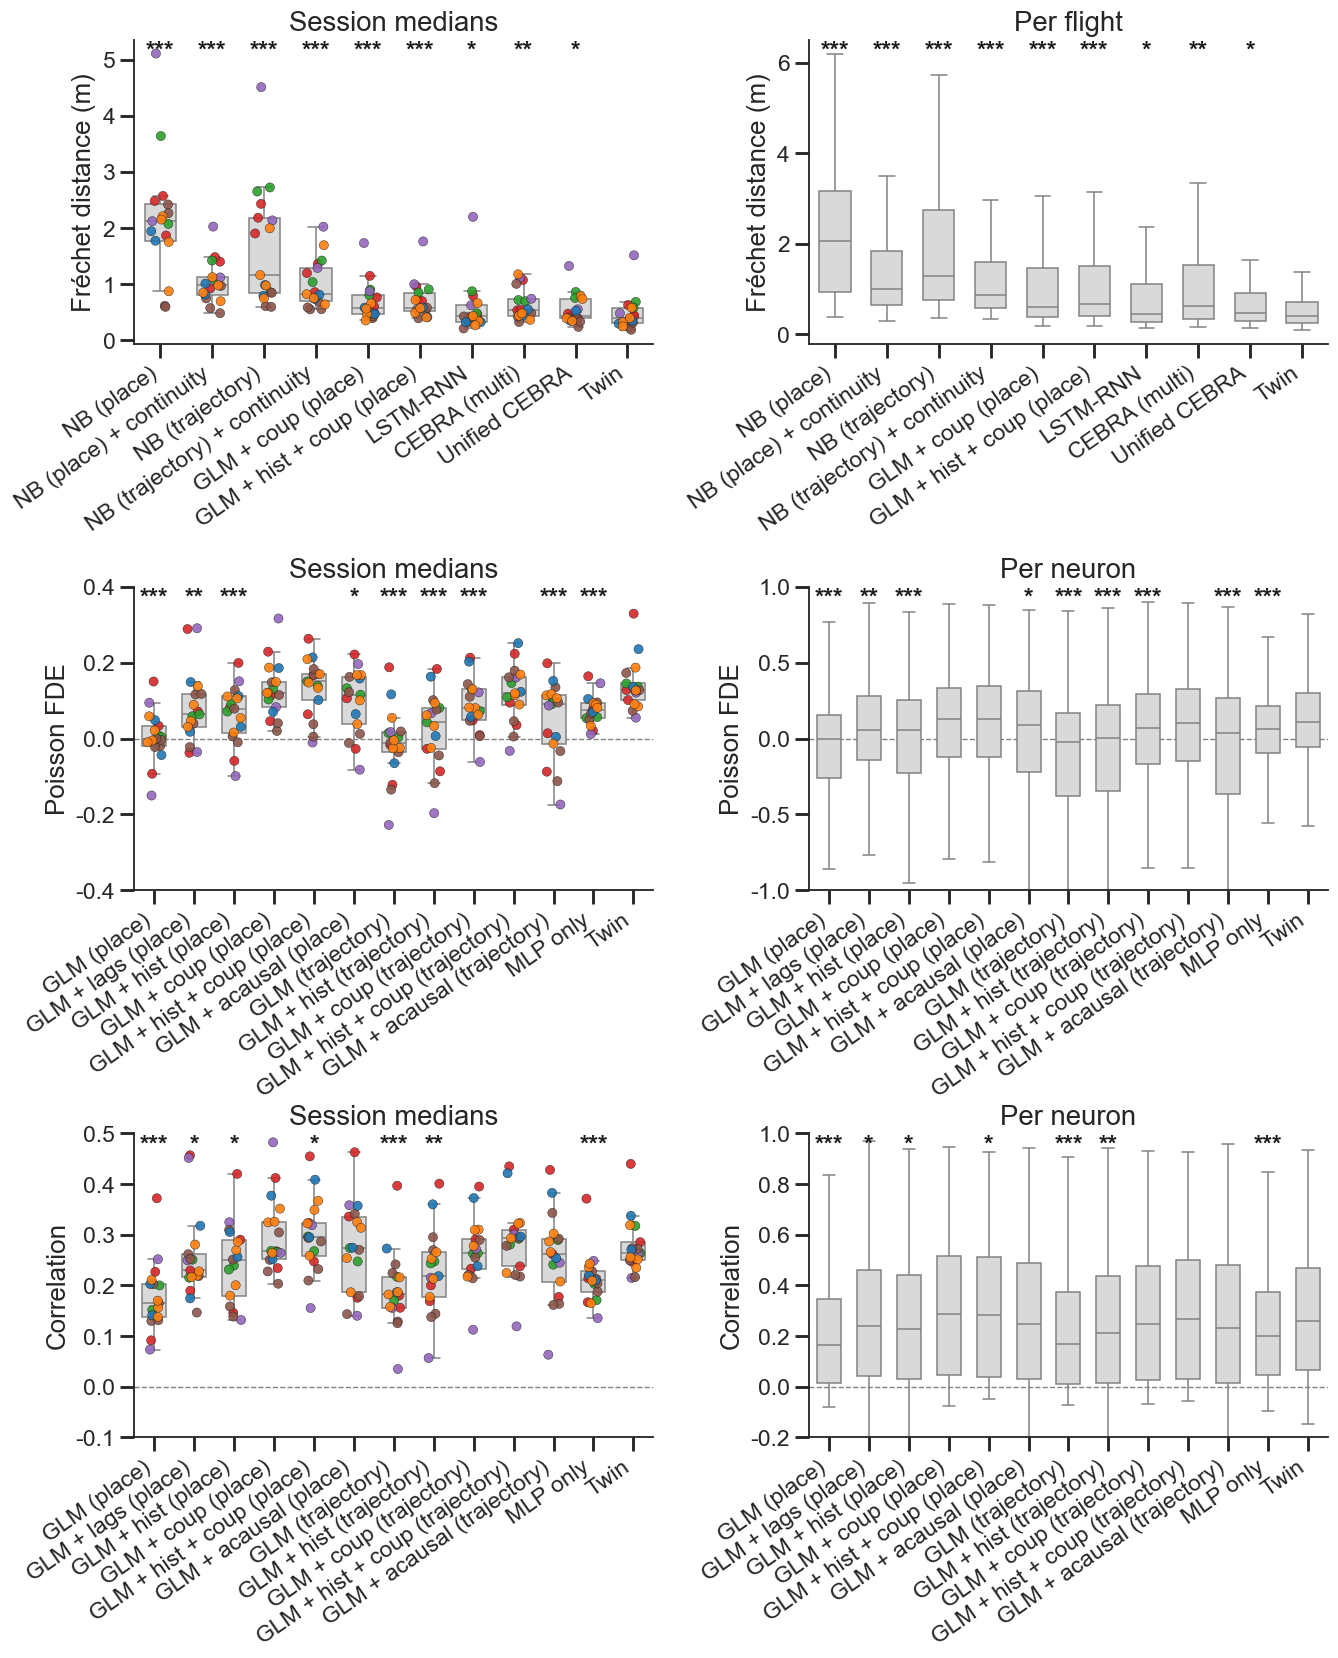


ED Fig 1a Fréchet — session-level Wilcoxon vs Twin:
                model    vs  n  median_diff         p stars         P
          naive_bayes joint 17        1.642 1.526e-05   *** P < 0.001
        nb_continuity joint 17        0.528 1.526e-05   *** P < 0.001
  naive_bayes_cluster joint 17       0.8419 1.526e-05   *** P < 0.001
nb_continuity_cluster joint 17       0.4571 1.526e-05   *** P < 0.001
         glm_map_coup joint 17       0.1707 1.526e-05   *** P < 0.001
              glm_map joint 17       0.2311 1.526e-05   *** P < 0.001
             lstm_rnn joint 17      0.03518   0.01286     * P = 0.013
          cebra_multi joint 17        0.118  0.001678    ** P = 0.002
                cebra joint 17      0.07054   0.03954     * P = 0.040

ED Fig 1b FDE — session-level Wilcoxon vs Twin:
                         model   vs  n  median_diff         p stars         P
                   GLM (place) Twin 17       0.1314 1.526e-05   *** P < 0.001
            GLM + lags (place) Twin 17    

In [20]:
# === Extended Data Figure 1 (a-c) on a single canvas ===
# 3 rows x 2 cols; each row is one panel = a (session, per-unit) pair from
# compare_models_fig, giving each panel the full canvas width. Decoding first, then
# encoding.
#   row 1: a = decoding Fréchet
#   row 2: b = encoding FDE        row 3: c = encoding corr
fig_ed1 = plt.figure(figsize=(14, 16.5))
gs_ed1 = fig_ed1.add_gridspec(3, 2, hspace=0.8, wspace=0.3)

ax_a = (fig_ed1.add_subplot(gs_ed1[0, 0]), fig_ed1.add_subplot(gs_ed1[0, 1]))
_, ptab_ed1a = ph.compare_models_fig(
    ed1_frechet, 'frechet_3d', ed1_dec_present, ref='joint', labels=ED1_DEC_LABELS,
    model_col='decoder', ylabel='Fréchet distance (m)', unit_name='flight', higher_is_better=False, axes=ax_a)

ax_b = (fig_ed1.add_subplot(gs_ed1[1, 0]), fig_ed1.add_subplot(gs_ed1[1, 1]))
_, ptab_ed1b = ph.compare_models_fig(
    ed1_encode_df, 'fde', ed1_present, ref=OUR_MODEL, ylabel='Poisson FDE',
    unit_name='neuron', clip=(-1, 1), zero_line=True, sess_ylim=(-0.4, 0.4), axes=ax_b)

ax_c = (fig_ed1.add_subplot(gs_ed1[2, 0]), fig_ed1.add_subplot(gs_ed1[2, 1]))
_, ptab_ed1c = ph.compare_models_fig(
    ed1_encode_df, 'corr', ed1_present, ref=OUR_MODEL, ylabel='Correlation',
    unit_name='neuron', clip=(-0.2, 1), zero_line=True, sess_ylim=(-0.1, 0.5), axes=ax_c)

ph.save_fig(fig_ed1, 'edfig1_full'); plt.show()
for _n, _pt in [('1a Fréchet', ptab_ed1a), ('1b FDE', ptab_ed1b),
                ('1c corr', ptab_ed1c)]:
    print(f'\nED Fig {_n} — session-level Wilcoxon vs {OUR_MODEL}:'); ph.p_table(_pt.to_dict('records'))

**Extended Data Figure 1 | Full model ladders.** **a**, Per-flight 3-D Fréchet distance for the decoder ladder (naïve-Bayes place, NB + continuity, transformer decoder, unified CEBRA, joint). **b–c**, Per-neuron encoding fit (Poisson FDE, Pearson r) on held-out flights for the complete model set: place and temporal-filter GLMs (history, coupling, acausal self-filter) under position and trajectory-cluster conditioning, an attention-free MLP, a small encoder-only transformer, the full transformer, and the joint model. Points are session medians coloured by bat (left panels) and pooled neurons/flights (right panels); stars are two-sided Wilcoxon signed-rank tests on paired per-session medians versus the joint model; exact *P* values are printed above. FDE axes clipped to [−1, 1] for display; statistics use raw values. `GLM + lags + kin` (needs kinematics) and the SVM / GLM-inversion decoders (bespoke classes) are omitted here.

---
## Extended Data Figure 2 — synthetic & shuffle controls

**a–b** Per-neuron encoding **cost** — Δ(synthetic-trained − real-trained) in Poisson FDE (**a**) and Pearson r (**b**) — with the *entire* ED Fig 1a model ladder **retrained on synthetic place-cell spikes** (per-session smoothed 3-D rate maps, same architecture/hyperparameters) and scored on the **real** held-out test set. On purely place-driven training data the transformer's edge over place GLMs collapses, isolating the real-neural structure it exploits. **c–e** Decoding **cost** = metric(mode) − metric(real), per flight, comparing `GLM + hist + coup (place)`, `GLM + hist + coup (trajectory)` and `Twin` at matched complexity: 3-D Fréchet cost, one row per surrogate training mode — trial-shuffle (**c**), synthetic place-only (**d**), synthetic trajectory (**e**); per-flight Δ, Wilcoxon anchored on the `Twin` joint decoder. The real decoder ladder vs `Twin` (3-D Fréchet) is **not repeated here — see ED Fig 1c/d**.

> **Sources.** Panels a–b retrain the ED Fig 1a ladder on synthetic spikes from `digitalbat.datasets.synthetic.make_synthetic_train_dataloaders` (train-if-missing, `_synth` checkpoints; the joint model via `joint_trainer.train_joint` with the consensus params) and score on real test — mirroring `internals.ipynb` / `preprocess-data-v0j-share.ipynb`. Panels c–e import the per-flight surrogate-mode tables exported by `decode-position-comparison.ipynb` §5 → `./out/decode_costs/ed2_decode_costs_seed_{seed}.pkl`; if the pkl is absent (or predates the Twin column) this notebook regenerates it via `digitalbat.decoding.cost_pipeline.generate_ed2_decode_costs` — which now trains one Twin joint decoder per surrogate mode (`build_joint_decoders`) alongside the GLM-inversion decoders — else degrades to placeholders.

In [21]:
# === ED Fig 2a/b: encode ladder RETRAINED on synthetic place-cell spikes, eval on real ===
# Replace each session's TRAIN spikes with samples from its smoothed 3-D rate map
# (valid/test stay real by reference), retrain the full ED Fig 1a/b ladder with the
# SAME architecture/hyperparameters (train-if-missing, `_synth` checkpoints), then
# score per-neuron FDE/corr on the REAL held-out test set. Mirrors internals.ipynb /
# preprocess-data-v0j-share.ipynb, extended from the transformer to the whole ladder.
from digitalbat.datasets.synthetic import make_synthetic_train_dataloaders
from digitalbat.training.joint_trainer import train_joint, scheme_weights
import re as _re

SYNTH_MODE = 'empirical'   # matches decode-position-comparison SYNTH_SAMPLING ('empirical' resample)
SYNTH_TAG = f'_synth_{SYNTH_MODE}'

# The joint universe's meta stats are 13-D (kinematic); the position-only view is
# 3-D. Slice behaviour mean/std to xyz for the synthetic rate-map fit (matches how
# gather_session_arrays / joint_decode un-z-score position elsewhere).
_meta_pos3 = dict(meta_info_dict)
_meta_pos3['behavior_mean'] = {s: np.asarray(v).reshape(-1)[:3]
                               for s, v in meta_info_dict['behavior_mean'].items()}
_meta_pos3['behavior_std'] = {s: np.asarray(v).reshape(-1)[:3]
                              for s, v in meta_info_dict['behavior_std'].items()}
syn_loaders, syn_simulators = make_synthetic_train_dataloaders(
    dataloaders, _meta_pos3, dt=bin_width, mode=SYNTH_MODE, seed=seed)
assert syn_loaders['valid'] is dataloaders['valid'] and syn_loaders['test'] is dataloaders['test']


def _synth_ckpt(path):
    root, ext = os.path.splitext(path)
    return f'{root}{SYNTH_TAG}{ext}'


def _joint_synth_params():
    """Consensus joint hyperparameters (parsed from JOINT_CKPT + cached study)."""
    p = dict(num_layers=JOINT_PARAMS['num_layers'], latent_dim=JOINT_PARAMS['latent_dim'],
             ff_dim=JOINT_PARAMS['ff_dim'], dropout=JOINT_PARAMS['dropout'],
             lr=3e-3, weight_decay=1e-2, w_encode=1.0, w_decode=1.0, w_aux=1.0,
             lam=1.0, pos_weight=1.0)
    base = os.path.basename(JOINT_CKPT)
    for k, rgx in dict(lam=r'_lam([0-9.]+)', pos_weight=r'_pw([0-9.]+)', w_encode=r'_we([0-9.]+)',
                       w_decode=r'_wd([0-9.]+)', w_aux=r'_wa([0-9.]+)').items():
        mm = _re.search(rgx, base)
        if mm:
            p[k] = float(mm.group(1))
    study_path = './out/joint/joint_optuna_v2_kin0.pkl'
    if os.path.exists(study_path):
        try:
            p.update(pickle.load(open(study_path, 'rb')).best_params)
        except Exception as _e:
            print(f'  [joint-synth] could not read study ({_e}); using parsed/default params')
    return p


def _ensure_joint_synth(loaders):
    """Retrain the joint transformer on synthetic train spikes (same params)."""
    p = _joint_synth_params()
    ckpt = _synth_ckpt(JOINT_CKPT.replace('_infillft', ''))
    set_random_state(seed)
    jm = JointMaskedTransformer(
        unit_num_dict, behavior_dim=3, latent_dim=p['latent_dim'], num_heads=4,
        ff_dim=p['ff_dim'], num_layers=p['num_layers'], dropout=p['dropout'],
        input_transform=INPUT_TRANSFORM, session_to_room=session_to_room).to(device)
    if os.path.exists(ckpt):
        jm.load_state_dict(torch.load(ckpt, map_location=device))
    else:
        print(f'  [train joint-synth] {os.path.basename(ckpt)}')
        jm, _b, _ = train_joint(jm, loaders, device, meta_info_dict, seed=seed, n_epochs=1000,
                                lr=p['lr'], weight_decay=p['weight_decay'], lam=p['lam'],
                                pos_weight=p['pos_weight'], scheme_p=scheme_weights(p),
                                select='joint', fde_weight=0.5, err_ref=0.3, fde_ref=0.1)
        torch.save(jm.state_dict(), ckpt)
    return jm.eval()


# Retrain the ladder on synthetic train (rebind the notebook's global `dataloaders`
# so the ED Fig 1 ensure_*/train_glm helpers train on synthetic + validate on real),
# then evaluate on the REAL test set. syn_loaders['test'] is the real test by reference.
_real_loaders = dataloaders
_syn_pieces = []
try:
    dataloaders = syn_loaders
    for label, kind, spec in ED1_MODELS:
        try:
            if kind == 'glm':
                name, cond = spec
                gm = ensure_glm(_synth_ckpt(glm_ckpt(name, cond)),
                                lambda: build_glm(name, cond), cond=cond,
                                search_alpha=('coup' in name))
                df = eval_glm_metrics(gm, joint_cond=(cond == 'joint'))
            elif kind == 'former':
                ck = _synth_ckpt(make_model_name(
                    seed, DEFAULT_LR, DEFAULT_WEIGHT_DECAY,
                    out_dir={'transformer': './out/bat_former', 'mlp': './out/bat_former_no_attn',
                             'small': './out/bat_former_small'}[spec], suffix=DATA_TAG))
                fm = ensure_former(ck, lambda: build_former(spec), loaders=syn_loaders)
                df = eval_former_metrics(fm)
            else:  # joint / Twin
                jm = _ensure_joint_synth(syn_loaders)
                df = encode_eval_records(JointEncoderAdapter(jm, unit_num_dict).to(device).eval(),
                                         _real_loaders, device)
            _syn_pieces.append(df.assign(model=label))
            print(f'  ok (synthetic): {label}')
        except Exception as exc:
            print(f'  [skip synthetic {label}] {type(exc).__name__}: {exc}')
finally:
    dataloaders = _real_loaders

ed2_encode_df = pd.concat(_syn_pieces, ignore_index=True)
ed2_enc_present = [m for m in ED1_ORDER if m in set(ed2_encode_df['model'])]
ed2_encode_df['model'] = pd.Categorical(ed2_encode_df['model'], ed2_enc_present, ordered=True)
print('ED2 synthetic-encode models:', ed2_enc_present)

  ok (synthetic): GLM (place)
GLM: 11 lags x 4096 spatial = 45056 features, lag_bins=[-10, -8, -6, -4, -2, 0, 2, 4, 6, 8, 10]
  ok (synthetic): GLM + lags (place)
  ok (synthetic): GLM + hist (place)
  ok (synthetic): GLM + coup (place)
  ok (synthetic): GLM + hist + coup (place)
  ok (synthetic): GLM + acausal (place)
  ok (synthetic): GLM (trajectory)
  ok (synthetic): GLM + hist (trajectory)
  ok (synthetic): GLM + coup (trajectory)
  ok (synthetic): GLM + hist + coup (trajectory)
  ok (synthetic): GLM + acausal (trajectory)
  ok (synthetic): MLP only
  ok (synthetic): Twin
ED2 synthetic-encode models: ['GLM (place)', 'GLM + lags (place)', 'GLM + hist (place)', 'GLM + coup (place)', 'GLM + hist + coup (place)', 'GLM + acausal (place)', 'GLM (trajectory)', 'GLM + hist (trajectory)', 'GLM + coup (trajectory)', 'GLM + hist + coup (trajectory)', 'GLM + acausal (trajectory)', 'MLP only', 'Twin']


In [22]:
# === ED Fig 2c-h data: decoding cost (mode - real) from decode-position-comparison ===
# Per-flight surrogate-mode decode tables exported by decode-position-comparison.ipynb
# (§5 export cell) -> paired per-flight costs metric(mode) - metric(real). The decoder
# subset shown in ED Fig 2 matches the ED Fig 1c/d nomenclature (GLM-inversion place
# variants) and is anchored on the Twin joint decoder (NOT Bat_Transformer_Decoder).
ED2_COST_PATH = f'./out/decode_costs/ed2_decode_costs_seed_{seed}.pkl'

# Surrogate modes shown as cost panels (one row each).
ED2_COST_MODES = [('trial_shuffled', 'Trial-shuffle'),
                  ('synthetic', 'Synthetic (place)'),
                  ('synthetic_traj', 'Synthetic (trajectory)')]
# Decoders compared in each cost panel, in ED Fig 1a/c order; last = Twin (the
# joint masked encoder/decoder used as a decoder), the anchor for the Wilcoxon test.
# Three decoders at matched complexity: GLM + hist + coup for place vs trajectory
# (place x traj-cluster) conditioning, plus Twin (the joint masked encoder/decoder
# used as a decoder) — the last is the Wilcoxon anchor. All three appear in every mode,
# so the cost panels share one x-axis. Note the temporal filters HURT a GLM-inversion
# decoder (they explain firing that would otherwise pin down position), so glm_map_joint_hc
# has a poorer real baseline and small, sometimes negative synthetic costs; its trial-shuffle
# cost stays strongly positive (it relies on the coupling that trial-shuffle destroys).
ED2_COST_MODELS = ['glm_map', 'glm_map_joint_hc', 'joint']
ED2_COST_REF = 'joint'
ED2_COST_LABELS = {'glm_map': 'GLM + hist + coup (place)',
                   'glm_map_joint_hc': 'GLM + hist + coup (trajectory)', 'joint': OUR_MODEL}


def _mode_cost(flightdf, value_col, mode):
    """Per-flight paired cost = value(mode) - value(real), matched on flight+model.
    Test flights are the real held-out flights (by reference) in every asymmetric
    mode, so the join is 1:1."""
    keys = ['bat', 'session', 'flight_id', 'model']
    real = flightdf[flightdf['data'] == 'real'][keys + [value_col]]
    surr = flightdf[flightdf['data'] == mode][keys + [value_col]]
    m = surr.merge(real, on=keys, suffixes=('_surr', '_real'))
    m['value'] = m[f'{value_col}_surr'] - m[f'{value_col}_real']
    m = m[m['model'].isin(ED2_COST_MODELS)].copy()
    present = [c for c in ED2_COST_MODELS if c in set(m['model'])]
    m['model'] = pd.Categorical(m['model'], present, ordered=True)
    return m


def _pkl_has_joint(path):
    """True iff the cached export carries the models ED Fig 2 needs (Twin +
    the GLM + hist + coup trajectory inversion)."""
    try:
        have = set(pd.read_pickle(path)['frechet_by_mode']['model'])
        return {'joint', 'glm_map_joint_hc'} <= have
    except Exception:
        return False


# Regenerate the per-flight surrogate-mode decode tables in-place if missing OR if the
# cached pkl predates the Twin column (run-once cache; heavy — trains one joint
# decoder per mode plus the GLM-inversion / transformer decoders). The generation logic
# is the single-sourced package pipeline decode-position-comparison.ipynb also uses.
if not os.path.exists(ED2_COST_PATH) or not _pkl_has_joint(ED2_COST_PATH):
    try:
        from digitalbat.decoding.cost_pipeline import generate_ed2_decode_costs
        from digitalbat.datasets.defaults import (
            DEFAULT_SESSION_NAMES as _ED2_DSN, make_data_config as _ed2_mdc)
        _ed2_decode_cfg = _ed2_mdc(
            session_names=[s for s in _ED2_DSN if s != 'Dataset_3_14543_240419'])
        _why = 'missing' if not os.path.exists(ED2_COST_PATH) else 'lacks Twin'
        print(f'[ED2 c-h] {ED2_COST_PATH} {_why} — regenerating via '
              'cost_pipeline.generate_ed2_decode_costs (cached ckpts under ./out) …')
        generate_ed2_decode_costs(_ed2_decode_cfg, device=device, seed=seed,
                                  out_path=ED2_COST_PATH, joint_params=JOINT_PARAMS,
                                  joint_input_transform=INPUT_TRANSFORM)
    except Exception as _ed2_exc:
        print(f'[ED2 c-h] regeneration failed ({type(_ed2_exc).__name__}: {_ed2_exc}); '
              'cost panels will show placeholders.')


ed2_cost = None
if os.path.exists(ED2_COST_PATH):
    _exp = pd.read_pickle(ED2_COST_PATH)
    _fr = _exp['frechet_by_mode']
    ed2_cost = {}
    for mode, _lab in ED2_COST_MODES:
        ed2_cost[('frechet_3d', mode)] = _mode_cost(_fr, 'frechet_3d', mode)
    print('ED2 cost tables (rows):', {f'{k[0]}|{k[1]}': len(v) for k, v in ed2_cost.items()})
    if not _pkl_has_joint(ED2_COST_PATH):
        print('[ED2 c-h] WARNING: cached pkl still lacks Twin — last column will be empty.')
else:
    print(f'[ED2 c-h] could not produce {ED2_COST_PATH}; cost panels show placeholders.')


ED2 cost tables (rows): {'frechet_3d|trial_shuffled': 834, 'frechet_3d|synthetic': 834, 'frechet_3d|synthetic_traj': 834}


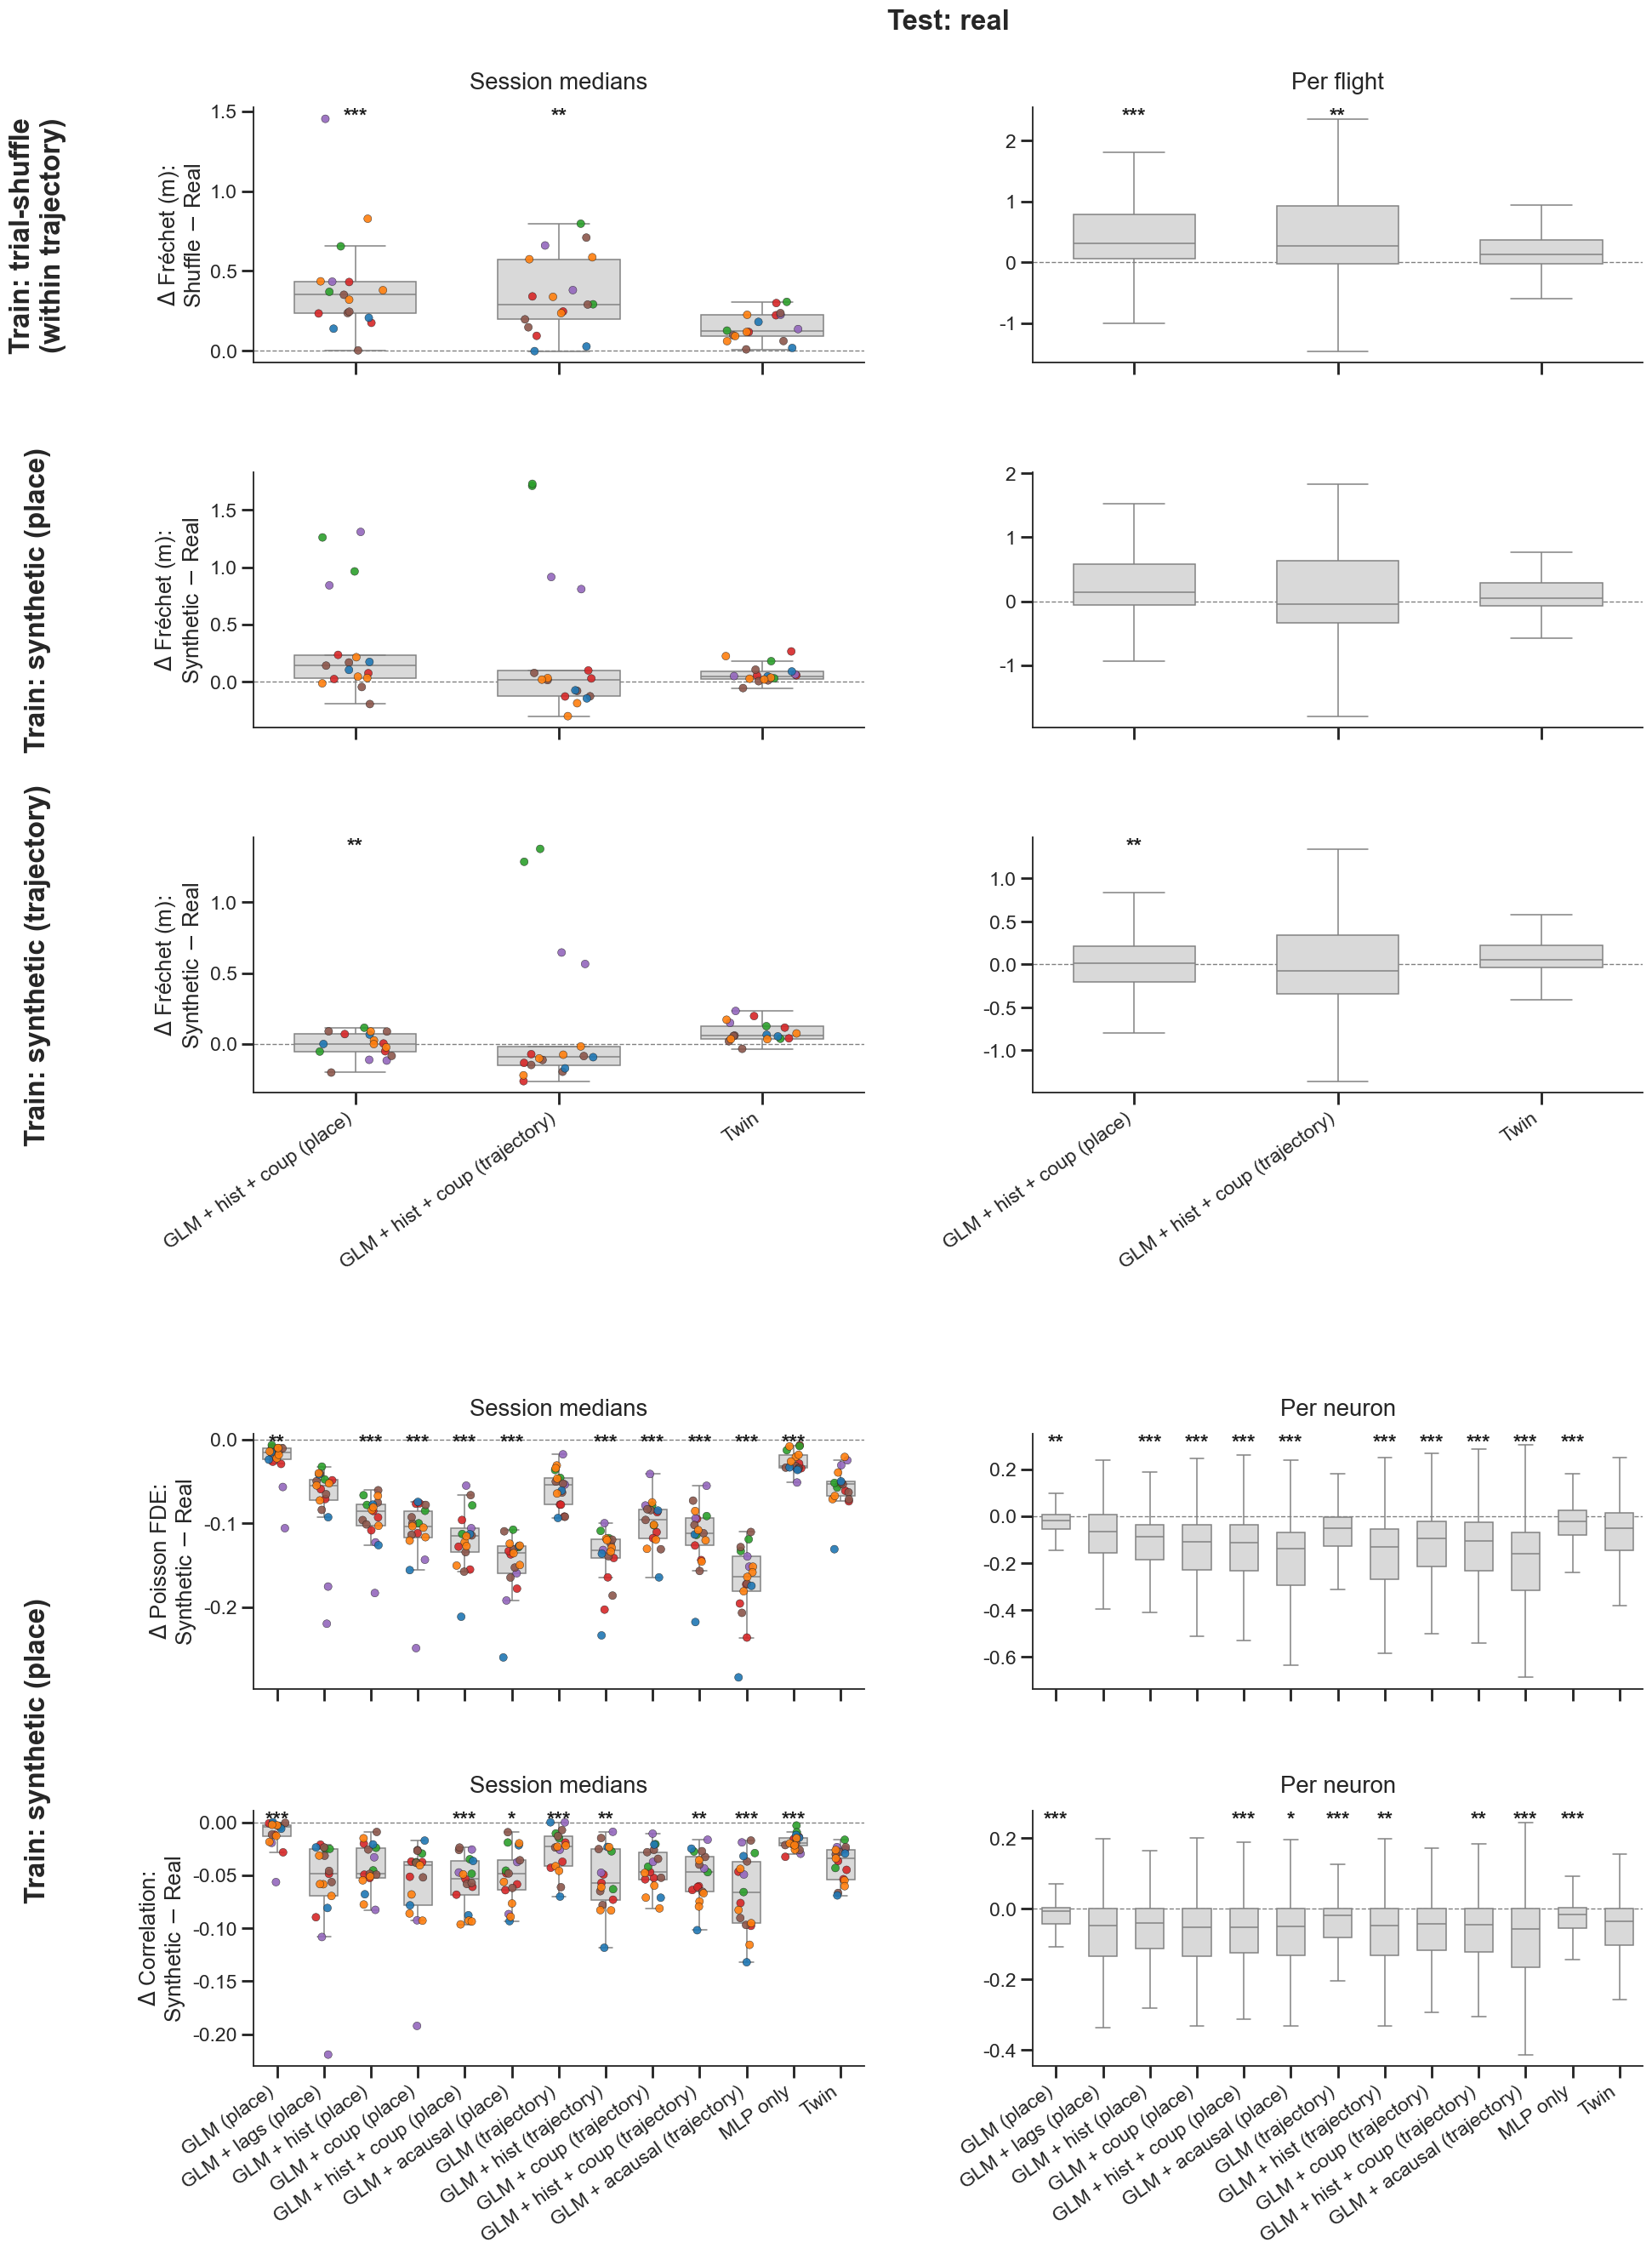


ED Fig 2a Trial-shuffle frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff         p stars         P
         glm_map joint 17        0.154 0.0001068   *** P < 0.001
glm_map_joint_hc joint 17       0.2196   0.00209    ** P = 0.002

ED Fig 2b Synthetic (place) frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff       p stars         P
         glm_map joint 17      0.05661 0.09837       P = 0.098
glm_map_joint_hc joint 17     -0.02458    0.89       P = 0.890

ED Fig 2c Synthetic (trajectory) frechet_3d cost — session-level Wilcoxon:
           model    vs  n  median_diff        p stars         P
         glm_map joint 17     -0.09794 0.009338    ** P = 0.009
glm_map_joint_hc joint 17      -0.1579   0.4874       P = 0.487

ED Fig 2d ΔFDE — session-level Wilcoxon:
                         model   vs  n  median_diff         p stars         P
                   GLM (place) Twin 17     -0.04107  0.004639    ** P = 0.005
            

In [23]:
# === Extended Data Figure 2 on a single canvas — decode-cost (top) + encode-cost ===
# Everything is a "surrogate minus real-trained" delta, matched per unit/flight.
#   Rows A,B,C DECODE cost (per FLIGHT): Δ Fréchet =
#             metric(decoder trained on surrogate) − metric(trained on real). One row per
#             surrogate mode, full-width (session-median | per flight) pair. Wilcoxon
#             anchored on Twin.
#   Rows D,E  ENCODE cost (per NEURON): Δ Poisson FDE / Δ Pearson r =
#             metric(ladder retrained on synthetic place spikes) − metric(real-trained
#             ladder), both scored on the real test set. Full-width (session-median | per
#             neuron) pair; each metric its own row with its own titles, nested below the
#             three decode rows.

# ---- Encode delta: synthetic-trained − real-trained, matched per (session, unit, model) ----
_e2 = ed2_encode_df.assign(model=ed2_encode_df['model'].astype(str))
_e1 = ed1_encode_df.assign(model=ed1_encode_df['model'].astype(str))
_enc_delta = _e2.merge(_e1[['session', 'unit', 'model', 'fde', 'corr']],
                       on=['session', 'unit', 'model'], suffixes=('_syn', '_real'))
_enc_delta['fde'] = _enc_delta['fde_syn'] - _enc_delta['fde_real']
_enc_delta['corr'] = _enc_delta['corr_syn'] - _enc_delta['corr_real']
_enc_present = [m for m in ed2_enc_present if m in set(_enc_delta['model'])]
_enc_delta['model'] = pd.Categorical(_enc_delta['model'], _enc_present, ordered=True)

# ---- Manual axis geometry (figure fraction). Panels short, gaps generous (esp. central). ----
fig_ed2 = plt.figure(figsize=(18, 26))
_L, _R, _TOP, _BOT = 0.16, 0.985, 0.955, 0.038
_UW = _R - _L
_g_enc = 0.100                                   # full-width rows: 2 axes, wide central gutter
_w_full = (_UW - _g_enc) / 2
_x_enc = [_L, _L + _w_full + _g_enc]

_h = 0.105                                       # ~30% shorter than the previous 0.150
_ROW_GAPS = [0.045, 0.045, 0.140, 0.050]         # gaps below A,B,C,D; big C->D for the decode-ladder ticks, tight decode rows
_NR = 5
_rowy, _y = [], _TOP
for r in range(_NR):
    _y -= _h
    _rowy.append(_y)
    if r < _NR - 1:
        _y -= _ROW_GAPS[r]


def _mk(cols, r):
    return [fig_ed2.add_axes([x, _rowy[r], w, _h]) for x, w in cols]


_full_pair = [(_x_enc[0], _w_full), (_x_enc[1], _w_full)]
_axC = _mk(_full_pair, 0)   # trial-shuffle (decode)
_axD = _mk(_full_pair, 1)   # synthetic (place) (decode)
_axE = _mk(_full_pair, 2)   # synthetic (trajectory) (decode)
_axA = _mk(_full_pair, 3)   # Δ FDE (encode)
_axB = _mk(_full_pair, 4)   # Δ r (encode)

ptabs_ed2 = {}

# ---- Rows A/B/C: decode cost, full-width Fréchet pair per surrogate mode (on top) ----
# (row axes, mode label, mode key, ylabel suffix — "Shuffle − Real" for shuffle, else "Synthetic")
_dec_rows = [(_axC, 'Trial-shuffle', 'trial_shuffled', 'Shuffle $-$ Real'),
             (_axD, 'Synthetic (place)', 'synthetic', 'Synthetic $-$ Real'),
             (_axE, 'Synthetic (trajectory)', 'synthetic_traj', 'Synthetic $-$ Real')]
_cost_specs = [('frechet_3d', 'flight', '$\\Delta$ Fréchet (m)', (0, 1))]
_letters = 'abc'
for ri, (axrow, mlabel, mode, sub) in enumerate(_dec_rows):
    show_titles = (ri == 0)                                   # titles only on trial-shuffle
    show_xticks = (ri == len(_dec_rows) - 1)                  # shared x-axis: labels on bottom decode row only
    for mi, (metric, unit, stem, (ca, cb)) in enumerate(_cost_specs):
        ax_pair = (axrow[ca], axrow[cb])
        tab = ed2_cost.get((metric, mode)) if ed2_cost else None
        if tab is not None and len(tab):
            _, pt = ph.compare_models_fig(
                tab, 'value', ED2_COST_MODELS, ref=ED2_COST_REF, labels=ED2_COST_LABELS,
                model_col='model', ylabel=f'{stem}:\n{sub}', unit_name=unit,
                higher_is_better=False, zero_line=True, axes=ax_pair,
                show_titles=show_titles, title_y=1.04, show_xticklabels=show_xticks,
                show_unit_ylabel=False)
            ptabs_ed2[f'2{_letters[ri]} {mlabel} {metric} cost'] = pt
        else:
            for a in ax_pair:
                a.set_axis_off()
            ax_pair[0].text(0.5, 0.5, f'{mlabel}\n{metric} cost:\nrun decode export cell',
                            ha='center', va='center', transform=ax_pair[0].transAxes)

# ---- Rows D/E: encode delta (full-width pair; each keeps its own titles), below decode ----
_, ptabs_ed2['2d ΔFDE'] = ph.compare_models_fig(
    _enc_delta, 'fde', _enc_present, ref=OUR_MODEL,
    ylabel='$\\Delta$ Poisson FDE:\nSynthetic $-$ Real', unit_name='neuron',
    zero_line=True, higher_is_better=True, axes=(_axA[0], _axA[1]),
    show_titles=True, title_y=1.04, show_xticklabels=False, show_unit_ylabel=False)
_, ptabs_ed2['2e Δr'] = ph.compare_models_fig(
    _enc_delta, 'corr', _enc_present, ref=OUR_MODEL,
    ylabel='$\\Delta$ Correlation:\nSynthetic $-$ Real', unit_name='neuron',
    zero_line=True, higher_is_better=True, axes=(_axB[0], _axB[1]),
    show_titles=True, title_y=1.04, show_xticklabels=True, show_unit_ylabel=False)

# ---- Left-gutter "Train:" labels (encode block spans its two rows -> one label) ----
_posA, _posB = _axA[0].get_position(), _axB[0].get_position()
fig_ed2.text(0.032, (_posA.y1 + _posB.y0) / 2, 'Train: synthetic (place)', rotation=90,
             ha='center', va='center', fontsize='large', fontweight='bold')
for axrow, lab in [(_axC, 'Train: trial-shuffle\n(within trajectory)'),
                   (_axD, 'Train: synthetic (place)'),
                   (_axE, 'Train: synthetic (trajectory)')]:
    _p = axrow[0].get_position()
    fig_ed2.text(0.032, (_p.y0 + _p.y1) / 2, lab, rotation=90,
                 ha='center', va='center', fontsize='large', fontweight='bold')

fig_ed2.text((_L + _R) / 2, 0.990, 'Test: real', ha='center', va='center',
             fontsize='large', fontweight='bold')

ph.save_fig(fig_ed2, 'edfig2_full')
plt.show()
for _n, _pt in ptabs_ed2.items():
    if _pt is None or not len(_pt):
        continue
    print(f'\nED Fig {_n} — session-level Wilcoxon:')
    ph.p_table(_pt.to_dict('records'))

---
## Extended Data Figure 3 — context window size

**a–b** Effect of the training context-window size on encoding fit (FDE, correlation): models retrained at window sizes {1, 3, 5, 7, 9, 11, full} with `window_size=W` flight tiling, evaluated on the matching windowed test set. **c** As **a–b** for decoding (3-D Fréchet). Panel **c** trains a `Bat_Transformer_Decoder` per window size on the tiled loaders on the first run (cached to `out/bat_decoder_ctxlen/`) and reload thereafter — the same load-or-train pattern used for every other model.

In [24]:
# === ED Fig 3a/b: encoding fit vs context window — JOINT model ===
# The context sweep now trains one JOINT model per window size (window_size=W tiling),
# not the old Bat_Transformer. Metrics are precomputed by `tmp/train_joint_context.py`
# (per-neuron FDE/corr); the 'full' context reuses the main joint model's Fig 1d/e fit.
CTX_WINDOWS = [1, 3, 5, 7, 9, 11]
_ctx_enc_p = './out/transfer_joint/context/ctx_encode.pkl'
if not os.path.exists(_ctx_enc_p):
    ctx_df = None
    print('ED Fig 3: no joint context-encode results — run `python tmp/train_joint_context.py` first.')
else:
    ctx_pieces = [pd.read_pickle(_ctx_enc_p)]                       # windowed joint models
    # 'full' context = the main joint model's per-neuron encode fit (Fig 1d/e).
    ctx_pieces.append(encode_metrics_df[encode_metrics_df['model'] == 'joint']
                      [['session', 'bat', 'unit', 'corr', 'fde']].assign(context='full', context_x=13))
    ctx_df = pd.concat(ctx_pieces, ignore_index=True)
    print(f'ED Fig 3a/b: joint context-encode loaded ({ctx_df["context_x"].nunique()} context sizes)')

# (plotting for ED Fig 3a-d assembled on one canvas below)


ED Fig 3a/b: joint context-encode loaded (7 context sizes)


In [25]:
# === ED Fig 3c/d: decoding vs context window — JOINT model ===
# Same joint windowed models as ED Fig 3a/b, scored on the decode task (behaviour masked,
# spikes seen): per-flight 3-D Fréchet distance. Precomputed by
# `tmp/train_joint_context.py`; the 'full' context reuses the main joint decoder (Fig 1f).
_ctx_fr_p = './out/transfer_joint/context/ctx_decode_fr.pkl'
if not os.path.exists(_ctx_fr_p):
    fr_all = None
    print('ED Fig 3: no joint context-decode results — run `python tmp/train_joint_context.py` first.')
else:
    fr_pieces = [pd.read_pickle(_ctx_fr_p)]                         # per-flight Fréchet, windowed joint
    # 'full' context = the main joint decoder (Fig 1f).
    fr_pieces.append(joint_frechet[['bat', 'session', 'flight_id', 'frechet_3d']].assign(context_x=13))
    fr_all = pd.concat(fr_pieces, ignore_index=True)
    print(f'ED Fig 3c: joint context-decode loaded ({fr_all["context_x"].nunique()} context sizes)')

# (plotting for ED Fig 3a-c assembled on one canvas below)


ED Fig 3c: joint context-decode loaded (7 context sizes)


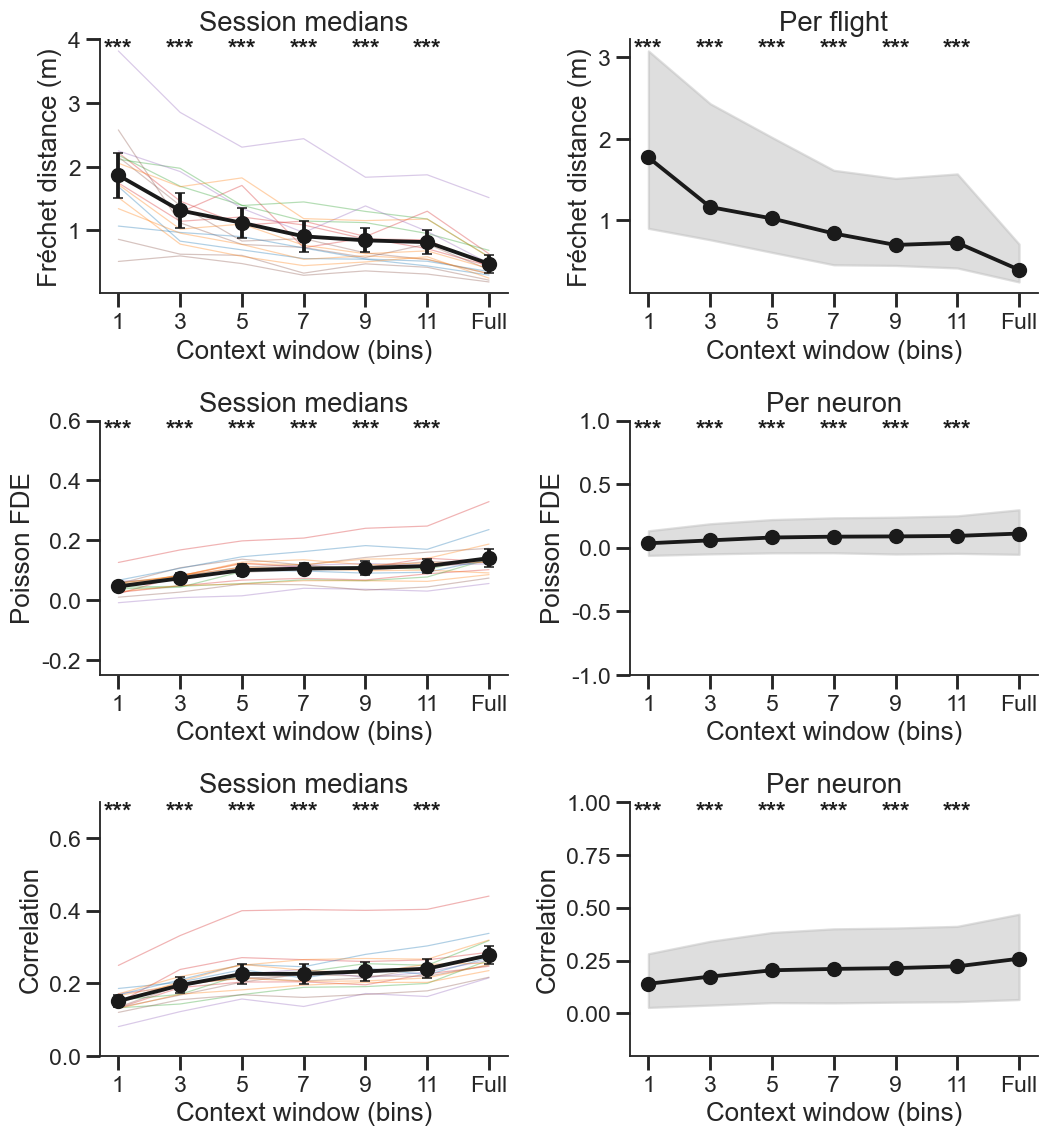

ED Fig 3 — joint decoding/encoding fit vs training context window (session medians + per flight/neuron). Stars: session-level Wilcoxon vs full context.
ED Fig 3 — context-window vs full, session-level Wilcoxon:
 context  n         p               metric stars         P
       1 17 1.526e-05 Fréchet distance (m)   *** P < 0.001
       3 17 1.526e-05 Fréchet distance (m)   *** P < 0.001
       5 17 1.526e-05 Fréchet distance (m)   *** P < 0.001
       7 17 1.526e-05 Fréchet distance (m)   *** P < 0.001
       9 17 1.526e-05 Fréchet distance (m)   *** P < 0.001
      11 17 1.526e-05 Fréchet distance (m)   *** P < 0.001
       1 17 1.526e-05          Poisson FDE   *** P < 0.001
       3 17 1.526e-05          Poisson FDE   *** P < 0.001
       5 17 0.0001068          Poisson FDE   *** P < 0.001
       7 17 0.0002136          Poisson FDE   *** P < 0.001
       9 17 7.629e-05          Poisson FDE   *** P < 0.001
      11 17 0.0006561          Poisson FDE   *** P < 0.001
       1 17 1.526e-05 

In [26]:
# === Extended Data Figure 3 — decoding/encoding fit vs training context window (JOINT) ===
# 3 rows (3-D Fréchet, Poisson FDE, Pearson r) x 2 cols; decoding first, then encoding.
# Col 0 = session medians vs context (per-session lines + mean 95% CI across sessions);
# col 1 = per-flight (decoding) / per-neuron (encoding) distribution vs context (median + IQR
# band). Decoding data = fr_all (per-flight Fréchet); encoding = ctx_df.
# Harmonised with Fig 1 labels/titles.
# Stars over each context window (not 'full') mark session-level Wilcoxon signed-rank of
# that window vs the full-context model (per-session median, paired across sessions).
if ctx_df is None or fr_all is None:
    print('ED Fig 3: context results missing — run `python tmp/train_joint_context.py` first.')
else:
    fig_ed5 = plt.figure(figsize=(11, 12))
    gs_ed5 = fig_ed5.add_gridspec(3, 2, hspace=0.5, wspace=0.3)
    _CTX_TICKS = CTX_WINDOWS + [13]
    _CTX_LABELS = [str(w) for w in CTX_WINDOWS] + ['full']

    def _ctx_pvals(df, col):
        """Session-level Wilcoxon signed-rank of each context window vs 'full'
        (context_x=13): per-session median, paired across sessions. Returns
        ({context_x: p}, list-of-records)."""
        pvals, recs = {}, []
        for w in CTX_WINDOWS:
            res = ph.paired_session_test(df, col, 'context_x', w, 13)
            if np.isfinite(res['p']):
                pvals[w] = res['p']
            recs.append(dict(context=w, n=res['n'], p=res['p']))
        return pvals, recs

    def _ctx_stars(ax, pvals, frac=0.96):
        """One 3-tier star per context window (vs full) near the top of `ax`, at x=context_x."""
        lo, hi = ax.get_ylim()
        y = lo + frac * (hi - lo)
        for w, p in pvals.items():
            s = ph.stars_for_p(p)
            if s:
                ax.text(w, y, s, ha='center', va='center', fontsize=16,
                        fontweight='bold', color='k')

    def _ctx_sess_panel(ax, df, col, ylab, pvals, ylim=None):
        """Col 0: per-session faint lines + mean +/- 95% CI across sessions."""
        per = df.groupby(['context_x', 'session'])[col].median().reset_index()
        for sn, g in per.groupby('session'):
            g = g.sort_values('context_x')
            ax.plot(g['context_x'], g[col], color=BAT_PALETTE.get(parse_bat(sn), '0.6'),
                    lw=0.8, alpha=0.35)
        agg = per.groupby('context_x')[col].agg(['mean', 'std', 'count'])
        ci = 1.96 * agg['std'] / np.sqrt(agg['count'])
        ax.errorbar(agg.index, agg['mean'], yerr=ci, fmt='o-', color='k', lw=2.5, capsize=3, zorder=5)
        ax.set(xlabel='context window (bins)', ylabel=ylab, title='session medians',
               xticks=_CTX_TICKS, xticklabels=_CTX_LABELS)
        if ylim:
            ax.set_ylim(*ylim)
        _ctx_stars(ax, pvals)
        sns.despine(ax=ax)

    def _ctx_unit_panel(ax, df, col, ylab, unit_keys, unit_name, pvals, ylim=None):
        """Col 1: per-unit (neuron / flight) median + 25-75% IQR band vs context."""
        per_unit = df.groupby(['context_x'] + unit_keys)[col].median().reset_index()
        q = per_unit.groupby('context_x')[col].quantile([0.25, 0.5, 0.75]).unstack()
        ax.fill_between(q.index, q[0.25], q[0.75], color='0.75', alpha=0.5, zorder=1)
        ax.plot(q.index, q[0.5], 'o-', color='k', lw=2.5, zorder=5)
        ax.set(xlabel='context window (bins)', ylabel=ylab, title=f'per {unit_name}',
               xticks=_CTX_TICKS, xticklabels=_CTX_LABELS)
        if ylim:
            ax.set_ylim(*ylim)
        _ctx_stars(ax, pvals)
        sns.despine(ax=ax)

    # (df, value, ylabel, unit_keys, unit_name, session-col ylim, per-unit-col ylim)
    _ED5_ROWS = [
        (fr_all, 'frechet_3d', 'Fréchet distance (m)', ['session', 'flight_id'], 'flight', None, None),
        (ctx_df, 'fde', 'Poisson FDE', ['session', 'unit'], 'neuron', (-0.25, 0.6), (-1, 1)),
        (ctx_df, 'corr', 'Correlation', ['session', 'unit'], 'neuron', (0, 0.7), (-0.2, 1)),
    ]
    ed5_p = []
    for ri, (df, col, ylab, ukeys, uname, sylim, uylim) in enumerate(_ED5_ROWS):
        pvals, recs = _ctx_pvals(df, col)
        for r in recs:
            r['metric'] = ylab
        ed5_p.extend(recs)
        _ctx_sess_panel(fig_ed5.add_subplot(gs_ed5[ri, 0]), df, col, ylab, pvals, sylim)
        _ctx_unit_panel(fig_ed5.add_subplot(gs_ed5[ri, 1]), df, col, ylab, ukeys, uname, pvals, uylim)
    ph.save_fig(fig_ed5, 'edfig3_full'); plt.show()
    print('ED Fig 3 — joint decoding/encoding fit vs training context window '
          '(session medians + per flight/neuron). Stars: session-level Wilcoxon vs full context.')
    print('ED Fig 3 — context-window vs full, session-level Wilcoxon:'); ph.p_table(ed5_p)

---
## Extended Data Figure 4 — foundation-model transfer

Per leave-one-out fold the joint (NEDS) model is retrained on the held-out target under three regimes — **scratch** (target only, no pre-training), **frozen** (foundation core + behaviour read-in/read-out frozen; only the target's neural read-in/read-out trained), and **fine-tune** (core + behaviour adapted at 0.1× learning rate) — alongside the **full** joint model trained on all 17 sessions including the target (Fig 1d–f). **Top two rows** encoding fit (per-neuron Poisson FDE, Pearson r); **bottom row** decoding accuracy (per-flight 3-D Fréchet distance). **Left pair** 17-fold leave-one-session-out CV; **right pair** 6-fold leave-one-bat-out CV. Each panel shows per-session aggregates (points coloured by bat) beside the per-unit distribution. Brackets connect **from-scratch** training to each of the other three conditions, with 3-tier stars for the session-level Wilcoxon signed-rank test vs scratch (n.s. labelled). Loaded from the cached transfer tables (`out/transfer_joint/*/results_*.pkl`); regenerate with `python tmp/train_joint_transfer.py`.

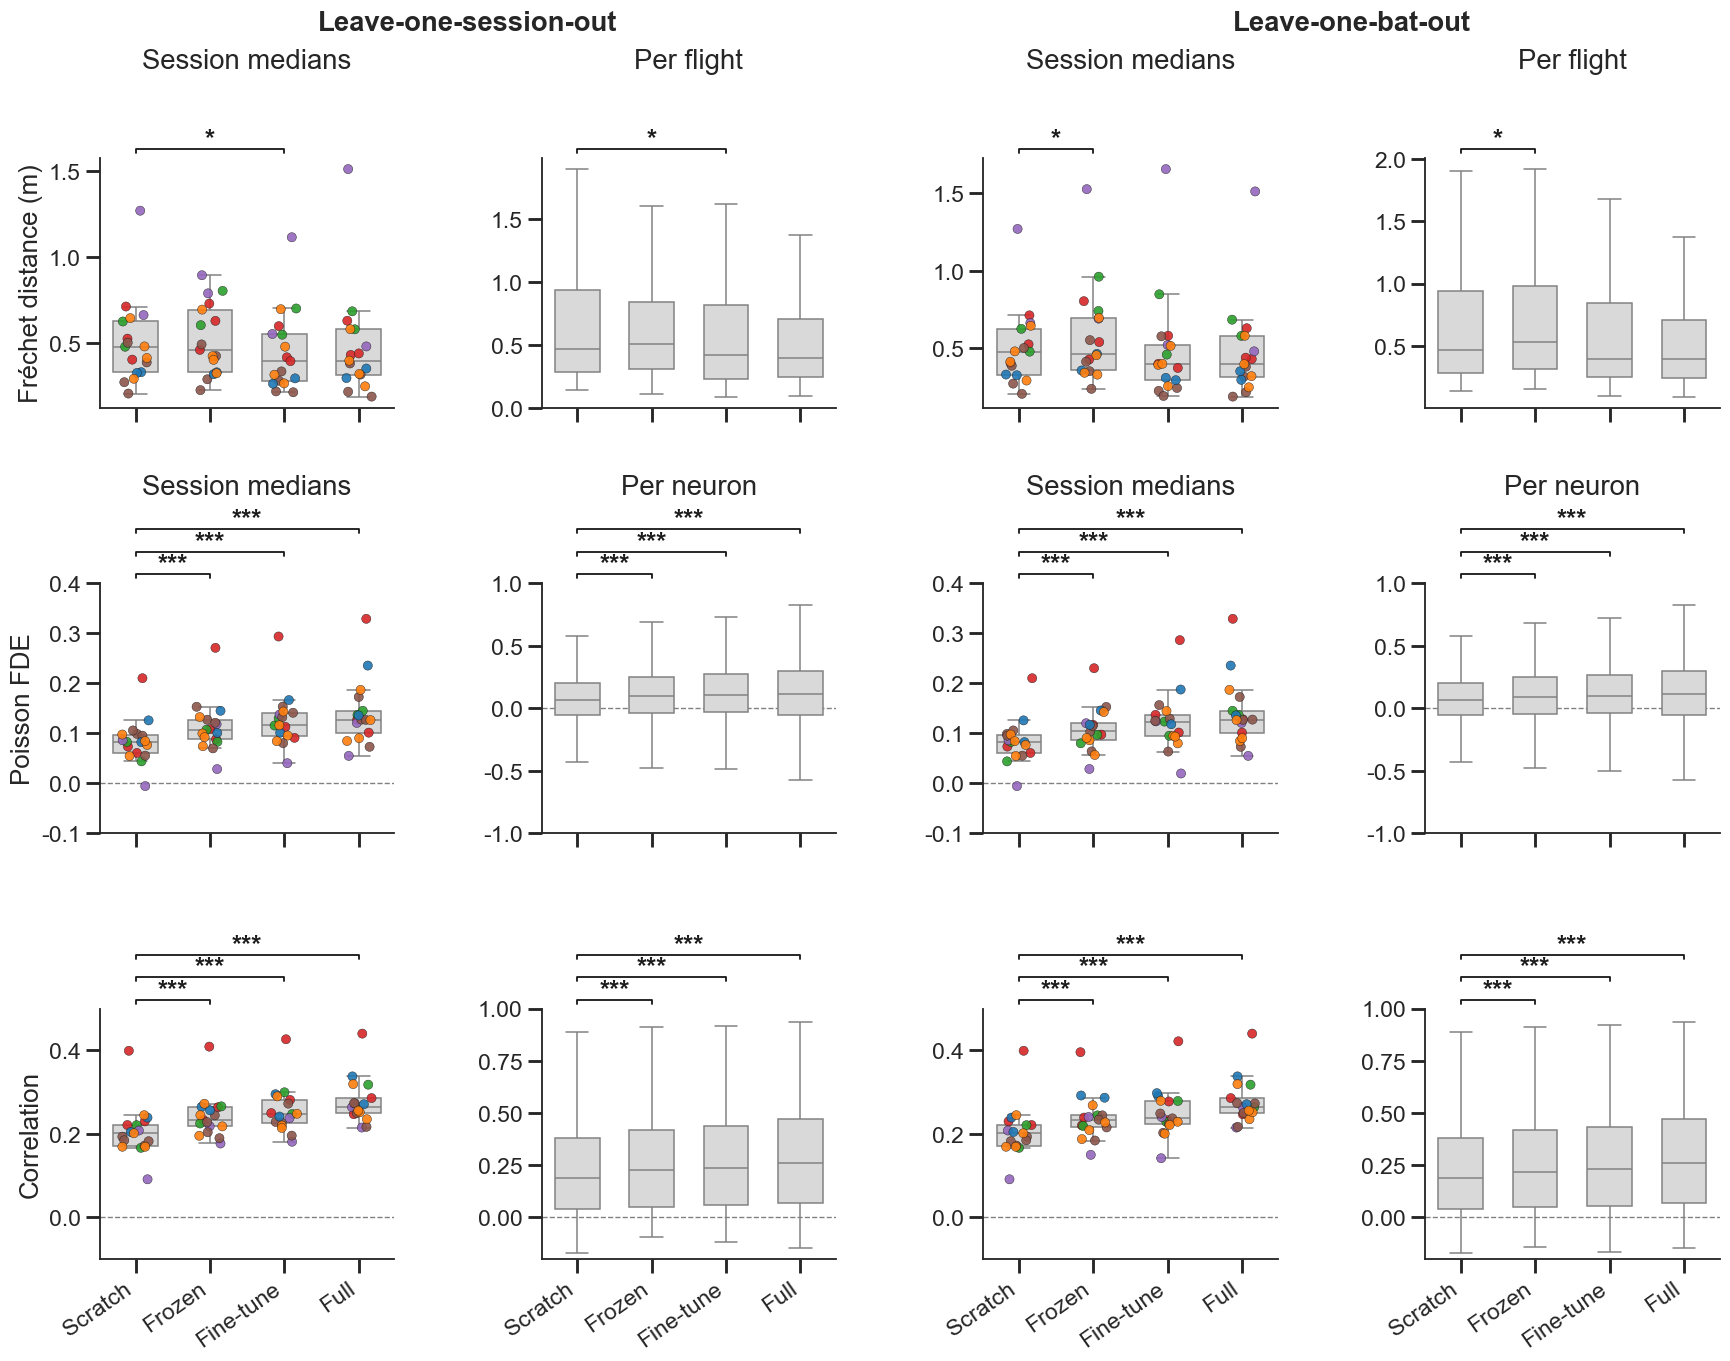

ED Fig 4 — joint-model transfer, session-level Wilcoxon vs scratch:
                   cv               metric     model      vs  n  median_diff         p stars         P
Leave-one-session-out Fréchet distance (m)    frozen scratch 17      0.01987    0.1089       P = 0.109
Leave-one-session-out Fréchet distance (m) fine-tune scratch 17     -0.05853   0.02016     * P = 0.020
Leave-one-session-out Fréchet distance (m)      full scratch 17     -0.04381    0.1594       P = 0.159
Leave-one-session-out          Poisson FDE    frozen scratch 17     -0.02731 1.526e-05   *** P < 0.001
Leave-one-session-out          Poisson FDE fine-tune scratch 17     -0.03928 1.526e-05   *** P < 0.001
Leave-one-session-out          Poisson FDE      full scratch 17     -0.05325 1.526e-05   *** P < 0.001
Leave-one-session-out          Correlation    frozen scratch 17     -0.03395 1.526e-05   *** P < 0.001
Leave-one-session-out          Correlation fine-tune scratch 17     -0.04509 1.526e-05   *** P < 0.001
Leave

In [27]:
# === ED Fig 4: foundation-transfer with the JOINT model — decoding + encoding ===
# Joint (NEDS) model retrained single-stage (6 masking schemes, fixed HP, no Optuna) per
# leave-one-out fold: scratch / frozen (core + behaviour read-in/read-out frozen; only the
# target's neural read-in+read-out trained) / fine-tune (core+behaviour at 0.1x LR) / full
# (the main joint model trained on all 17 sessions incl. target; Fig 1d–f — the skyline,
# shown as its own boxplot). 3 rows — decoding (3-D Fréchet; per flight) then encoding
# (Poisson FDE, Pearson r; per neuron) — x 2 CV schemes, each session
# medians + per unit (titles top two rows, x-labels bottom row, y-labels left column only).
# Brackets connect from-scratch training to each other condition (n.s. hidden); 3-tier
# stars = session-level Wilcoxon vs scratch. Regenerate: `python tmp/train_joint_transfer.py`.
TJ_ROOT = './out/transfer_joint'
TJ_GROUPS = [('session', 'Leave-one-session-out'), ('bat', 'Leave-one-bat-out')]
MODE_ORDER = ['scratch', 'frozen', 'fine-tune', 'full']
MODE_LABELS = {m: m for m in MODE_ORDER}
# (kind, col, ylabel, unit_name, higher_is_better, clip, sess_ylim, zero_line)
TJ_ROWS = [
    ('decode', 'frechet_3d', 'Fréchet distance (m)', 'flight', False, None, None, False),
    ('encode', 'fde', 'Poisson FDE', 'neuron', True, (-1, 1), (-0.1, 0.4), True),
    ('encode', 'corr', 'Correlation', 'neuron', True, (-0.2, 1), (-0.1, 0.5), True),
]


def _load_tj(g, kind):
    p = f'{TJ_ROOT}/{g}/results_{g}_{kind}.pkl'
    return pd.read_pickle(p) if os.path.exists(p) else pd.DataFrame()


# Full model as a 4th category (mode='full'): per-neuron encode fit + per-flight decode
# from the main joint model already evaluated above (Fig 1d–f).
_full_enc = (encode_metrics_df[encode_metrics_df['model'] == 'joint']
             [['session', 'bat', 'unit', 'corr', 'fde']].assign(mode='full'))
_full_dec = joint_frechet[['session', 'bat', 'flight_id', 'frechet_3d']].assign(mode='full')
_FULL_DF = {'encode': _full_enc, 'decode': _full_dec}

_tj = {(g, k): _load_tj(g, k) for g, _ in TJ_GROUPS for k in ('encode', 'decode')}
if all(df.empty for df in _tj.values()):
    print('ED Fig 4: no joint-transfer results on disk — '
          'run `python tmp/train_joint_transfer.py` first.')
else:
    fig_ed3 = plt.figure(figsize=(19, 13))
    gs_ed3 = fig_ed3.add_gridspec(3, 4, hspace=0.7, wspace=0.5)
    ed3_p, _hdr_axes = [], {}
    for gi, (grp, gtitle) in enumerate(TJ_GROUPS):
        for ri, (kind, col, ylab, uname, hib, clip, sylim, zl) in enumerate(TJ_ROWS):
            axs = fig_ed3.add_subplot(gs_ed3[ri, 2 * gi])
            axu = fig_ed3.add_subplot(gs_ed3[ri, 2 * gi + 1])
            base = _tj[(grp, kind)]
            if base.empty:
                axs.set_visible(False); axu.set_visible(False); continue
            df = pd.concat([base, _FULL_DF[kind]], ignore_index=True)   # append the 'full' box
            _, pt = ph.compare_models_fig(
                df, col, MODE_ORDER, ref='scratch', labels=MODE_LABELS, model_col='mode',
                ylabel=ylab, unit_name=uname, clip=clip, sess_ylim=sylim, zero_line=zl,
                higher_is_better=hib, star_style='bracket', star_kw={'star_gap': -0.012},
                show_titles=(ri <= 1), title_y=1.32,
                show_xticklabels=(ri == len(TJ_ROWS) - 1),
                show_sess_ylabel=(gi == 0), show_unit_ylabel=False,
                axes=(axs, axu))
            ed3_p += [dict(cv=gtitle, metric=ylab, **r) for r in pt.to_dict('records')]
            if ri == 0:
                _hdr_axes[gi] = (axs, axu)
    # CV-scheme header at a FIXED height above the top row (decoupled from the panel
    # titles, so title_y lifts only 'session medians'/'per neuron', not these).
    fig_ed3.canvas.draw()
    _hdr_y = max(a.get_position().y1 for a, _ in _hdr_axes.values()) + 0.085
    for gi, (_, gtitle) in enumerate(TJ_GROUPS):
        if gi not in _hdr_axes:
            continue
        axs, axu = _hdr_axes[gi]
        p0, p1 = axs.get_position(), axu.get_position()
        fig_ed3.text((p0.x0 + p1.x1) / 2, _hdr_y, gtitle, ha='center', va='bottom',
                     fontsize=18, fontweight='bold')
    ph.save_fig(fig_ed3, 'edfig4_transfer'); plt.show()
    print('ED Fig 4 — joint-model transfer, session-level Wilcoxon vs scratch:')
    ph.p_table(ed3_p)

---
## Figure 2 — Transformer latents warp physical space to emphasise route identity

Physical XYZ, the 64-d transformer latent (PCA→3D), and the unified-CEBRA latent, each coloured by **x-coordinate** (top row) and by **flight route** (bottom row). Restricted to the indoor lab room (Datasets 1 & 3). The latent-extraction cell below is reused by Figure 4.

In [28]:
# --- Shared latent extraction: per-timepoint encode-space latents (neural tokens
# x[:, :T]) from BOTH the encode and decode passes, position, route/cluster/spikes.
from notebook_helpers import DIST_THRESH, get_target_locs


@torch.no_grad()
def extract_latents(split='test'):
    """Concatenate encode-pass latents + metadata across all sessions.

    Returns a dict with arrays aligned per valid timepoint: `latent` (N, d),
    `pred` (N, K_session — ragged, so returned per-session too), `xyz` (N, 3),
    `session`, `bat`, `flight_id`, `rel_t`, `cluster`, per-point `route`/`origin`/`dest`,
    and `spike_by_flight` (ragged {(session, flight_id): spikes}).
    """
    lat, lat_dec, xyz, sess, batv, fid, relt, clu = [], [], [], [], [], [], [], []
    spike_by_flight = {}
    per_session_latent = {}
    for sn in session_names:
        bm = meta_info_dict['behavior_mean'][sn][0, 0, :3]
        bs = meta_info_dict['behavior_std'][sn][0, 0, :3]
        sl = []
        for batch in dataloaders[split][sn]:
            X = batch.behavior.to(device)
            m = batch.mask.to(device)
            B, T, _ = X.shape
            spike0 = X.new_zeros(B, T, unit_num_dict[sn])
            _, _, xf = joint_model(sn, spike0, X, m, m, torch.zeros_like(m))
            h_n = xf[:, :T].cpu().numpy()  # encode space: neural tokens x[:, :T]
            # decode pass: real spikes visible, behaviour masked -> decode latent
            _, _, xf_d = joint_model(sn, batch.spike.to(device), X, m, torch.zeros_like(m), m)
            h_d = xf_d[:, :T].cpu().numpy()  # encode space too: neural tokens x[:, :T] (decode pass)
            Xn = batch.behavior.numpy()
            mn = batch.mask.numpy() == 1.0
            fpi = batch.flight_path_index.numpy(); fti = batch.flight_type_index.numpy()
            spn = batch.spike.numpy()
            for b in range(B):
                v = mn[b]
                nv = int(v.sum())
                if nv == 0:
                    continue
                lat.append(h_n[b, v]); sl.append(h_n[b, v])
                lat_dec.append(h_d[b, v])
                pos = Xn[b, :, :3] * bs + bm
                xyz.append(pos[v])
                sess.append(np.full(nv, sn)); batv.append(np.full(nv, parse_bat(sn)))
                fid.append(np.full(nv, int(fpi[b]))); clu.append(np.full(nv, int(fti[b])))
                spike_by_flight[(sn, int(fpi[b]))] = spn[b, v]
                relt.append(np.arange(nv) / max(nv - 1, 1))
        per_session_latent[sn] = np.concatenate(sl) if sl else np.empty((0, joint_model.latent_dim))
    out = dict(latent=np.concatenate(lat), latent_decode=np.concatenate(lat_dec), xyz=np.vstack(xyz),
               session=np.concatenate(sess), bat=np.concatenate(batv),
               flight_id=np.concatenate(fid), rel_t=np.concatenate(relt),
               cluster=np.concatenate(clu), spike_by_flight=spike_by_flight,
               per_session_latent=per_session_latent)

    # Per-(session, flight) origin/destination endpoint classes -> route id.
    origin = np.zeros(len(out['session']), int)
    dest = np.zeros_like(origin)
    key = np.char.add(np.char.add(out['session'], '|'), out['flight_id'].astype(str))
    for k in np.unique(key):
        m = key == k
        sn = out['session'][m][0]
        rew, perch = get_target_locs(sn)
        order = np.argsort(out['rel_t'][m])
        pos = out['xyz'][m][order]
        o = ph.endpoint_class(pos[0], rew, perch, DIST_THRESH)
        d = ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH)
        origin[m] = o; dest[m] = d
    out['origin'] = origin
    out['dest'] = dest
    out['route'] = np.array([ph.route_id(o, d) for o, d in zip(origin, dest)])
    return out


emb = extract_latents('test')
print('latent points:', len(emb['session']), '| latent dim:', emb['latent'].shape[1])

latent points: 8072 | latent dim: 64


In [29]:
# === Figure 2 RSA data (2c): representational similarity across the four spaces ===
# Built straight from `emb`, so the Twin encode/decode latents here are the SAME
# per-flight embeddings visualised in Fig 2b (identical data). For every TEST flight we
# form four per-flight reps mirroring the four columns: (1) physical XYZ, (2) unified
# CEBRA (Optuna-best HP), (3) Twin decode latent, (4) Twin encode latent -- both raw
# joint-model embeddings. CEBRA and both Twin latents are reduced to their shared
# min(cebra_dim, neds_latent_dim) top PCs (Physical stays raw XYZ; PCA centres away
# CEBRA's near-constant sphere offset with no normalisation), averaged over the whole
# flight to one point, per-session z-scored for Physical XYZ (CEBRA/NEDS already
# PC-centred), then Pearson-correlated between flights. All four share one ordering.
from sklearn.decomposition import PCA

# Per-(session, flight_id) reps grouped straight from `emb` -> identical to Fig 2b.
rsa_recs = {}
_rkey = np.char.add(np.char.add(emb['session'], '|'), emb['flight_id'].astype(str))
for _k in np.unique(_rkey):
    v = np.where(_rkey == _k)[0]
    v = v[np.argsort(emb['rel_t'][v])]
    sn = str(emb['session'][v[0]]); fid = int(emb['flight_id'][v[0]])
    rsa_recs[(sn, fid)] = dict(
        session=sn, bat=parse_bat(sn), flight_id=fid,
        cluster=int(emb['cluster'][v[0]]), indoor=ph.is_indoor(sn),
        route=int(emb['route'][v[0]]),
        xyz=emb['xyz'][v], h_n=emb['latent'][v], h_d=emb['latent_decode'][v],
        spike=emb['spike_by_flight'][(sn, fid)])

# CEBRA condition: Optuna-best unified per-flight embeddings (guarded on availability).
cebra_by_key = None
if cebra_frechet is not None:
    cebra_by_key = {(s, f['flight_id']): np.asarray(e) for s in session_names for e, f in uni_te[s]}

# Flights present in every available representation.
rsa_keys = [k for k in rsa_recs if cebra_by_key is None or k in cebra_by_key]

# Shared ordering: environment (indoor, outdoor) -> route -> bat -> session -> cluster.
_bat_idx = {b: i for i, b in enumerate(ph.bat_order())}
_sess_idx = {s: i for i, s in enumerate(sorted(session_names))}
rsa_order = sorted(rsa_keys, key=lambda k: (
    0 if rsa_recs[k]['indoor'] else 1, rsa_recs[k]['route'],
    _bat_idx.get(rsa_recs[k]['bat'], 99), _sess_idx[rsa_recs[k]['session']],
    rsa_recs[k]['cluster']))


def _rsa_matrix(getter, n_pc=None, zsession=False):
    """[top-n_pc PCs if n_pc] -> mean over the whole flight -> one point
    [-> per-session z-score across flights] -> Pearson."""
    arrs = [np.asarray(getter(k), float) for k in rsa_order]
    if n_pc is not None:
        comp = PCA(n_components=n_pc, random_state=seed).fit(np.vstack(arrs))
        arrs = [comp.transform(a) for a in arrs]
    pts = np.vstack([a.mean(0) for a in arrs])          # single flight-averaged point
    if zsession:
        # Physical XYZ only: z-score flights within each session so room offset/scale
        # don't dominate. CEBRA/NEDS are already PC-centred, so are left as-is.
        _sess = np.array([rsa_recs[k]['session'] for k in rsa_order])
        for _c in range(pts.shape[1]):
            pts[:, _c] = ph.zscore_by_session(pts[:, _c], _sess)
    return np.corrcoef(pts)


# Order MATCHES the Fig 2 columns: Physical XYZ, Unified CEBRA, decode, encode.
rsa_conditions = [('Physical XYZ', lambda k: rsa_recs[k]['xyz'])]
if cebra_by_key is not None:
    rsa_conditions.append(('Unified CEBRA', lambda k: cebra_by_key[k]))
rsa_conditions += [('Twin neural latent: decode', lambda k: rsa_recs[k]['h_d']),
                   ('Twin neural latent: encode', lambda k: rsa_recs[k]['h_n'])]
# CEBRA and both Twin latents share the same subspace size: the smaller of the
# CEBRA embedding dim and the Twin latent dim (Physical XYZ stays raw 3-D).
_neds_dim = int(next(iter(rsa_recs.values()))['h_d'].shape[1])
_rsa_pc = (min(int(next(iter(cebra_by_key.values())).shape[1]), _neds_dim)
           if cebra_by_key is not None else _neds_dim)
rsa_mats = {name: _rsa_matrix(fn, n_pc=(None if name == 'Physical XYZ' else _rsa_pc),
                              zsession=(name == 'Physical XYZ'))
            for name, fn in rsa_conditions}

# Per-flight metadata (row-aligned to rsa_order) for the barber-pole strips.
rsa_meta = dict(
    env=np.array([0 if rsa_recs[k]['indoor'] else 1 for k in rsa_order]),
    route=np.array([rsa_recs[k]['route'] for k in rsa_order]),
    bat=np.array([rsa_recs[k]['bat'] for k in rsa_order]),
    session=np.array([_sess_idx[rsa_recs[k]['session']] for k in rsa_order]),
    cluster=np.array([rsa_recs[k]['cluster'] for k in rsa_order]))
print(f'RSA: {len(rsa_order)} test flights | {_rsa_pc}-PC CEBRA/NEDS | '
      f'conditions: {[n for n, _ in rsa_conditions]}')
for _nm, _M in rsa_mats.items():
    _off = ~np.eye(len(rsa_order), dtype=bool)
    _same = _off & (rsa_meta['route'][:, None] == rsa_meta['route'][None, :])
    print(f'  {_nm:20s} within-route r={_M[_same].mean():+.3f}  '
          f'between-route r={_M[_off & ~_same].mean():+.3f}')

RSA: 278 test flights | 64-PC CEBRA/NEDS | conditions: ['Physical XYZ', 'Unified CEBRA', 'Twin decode', 'Twin encode']
  Physical XYZ         within-route r=+0.118  between-route r=-0.033
  Unified CEBRA        within-route r=+0.132  between-route r=-0.014
  Twin decode          within-route r=+0.230  between-route r=-0.066
  Twin encode          within-route r=+0.199  between-route r=-0.069


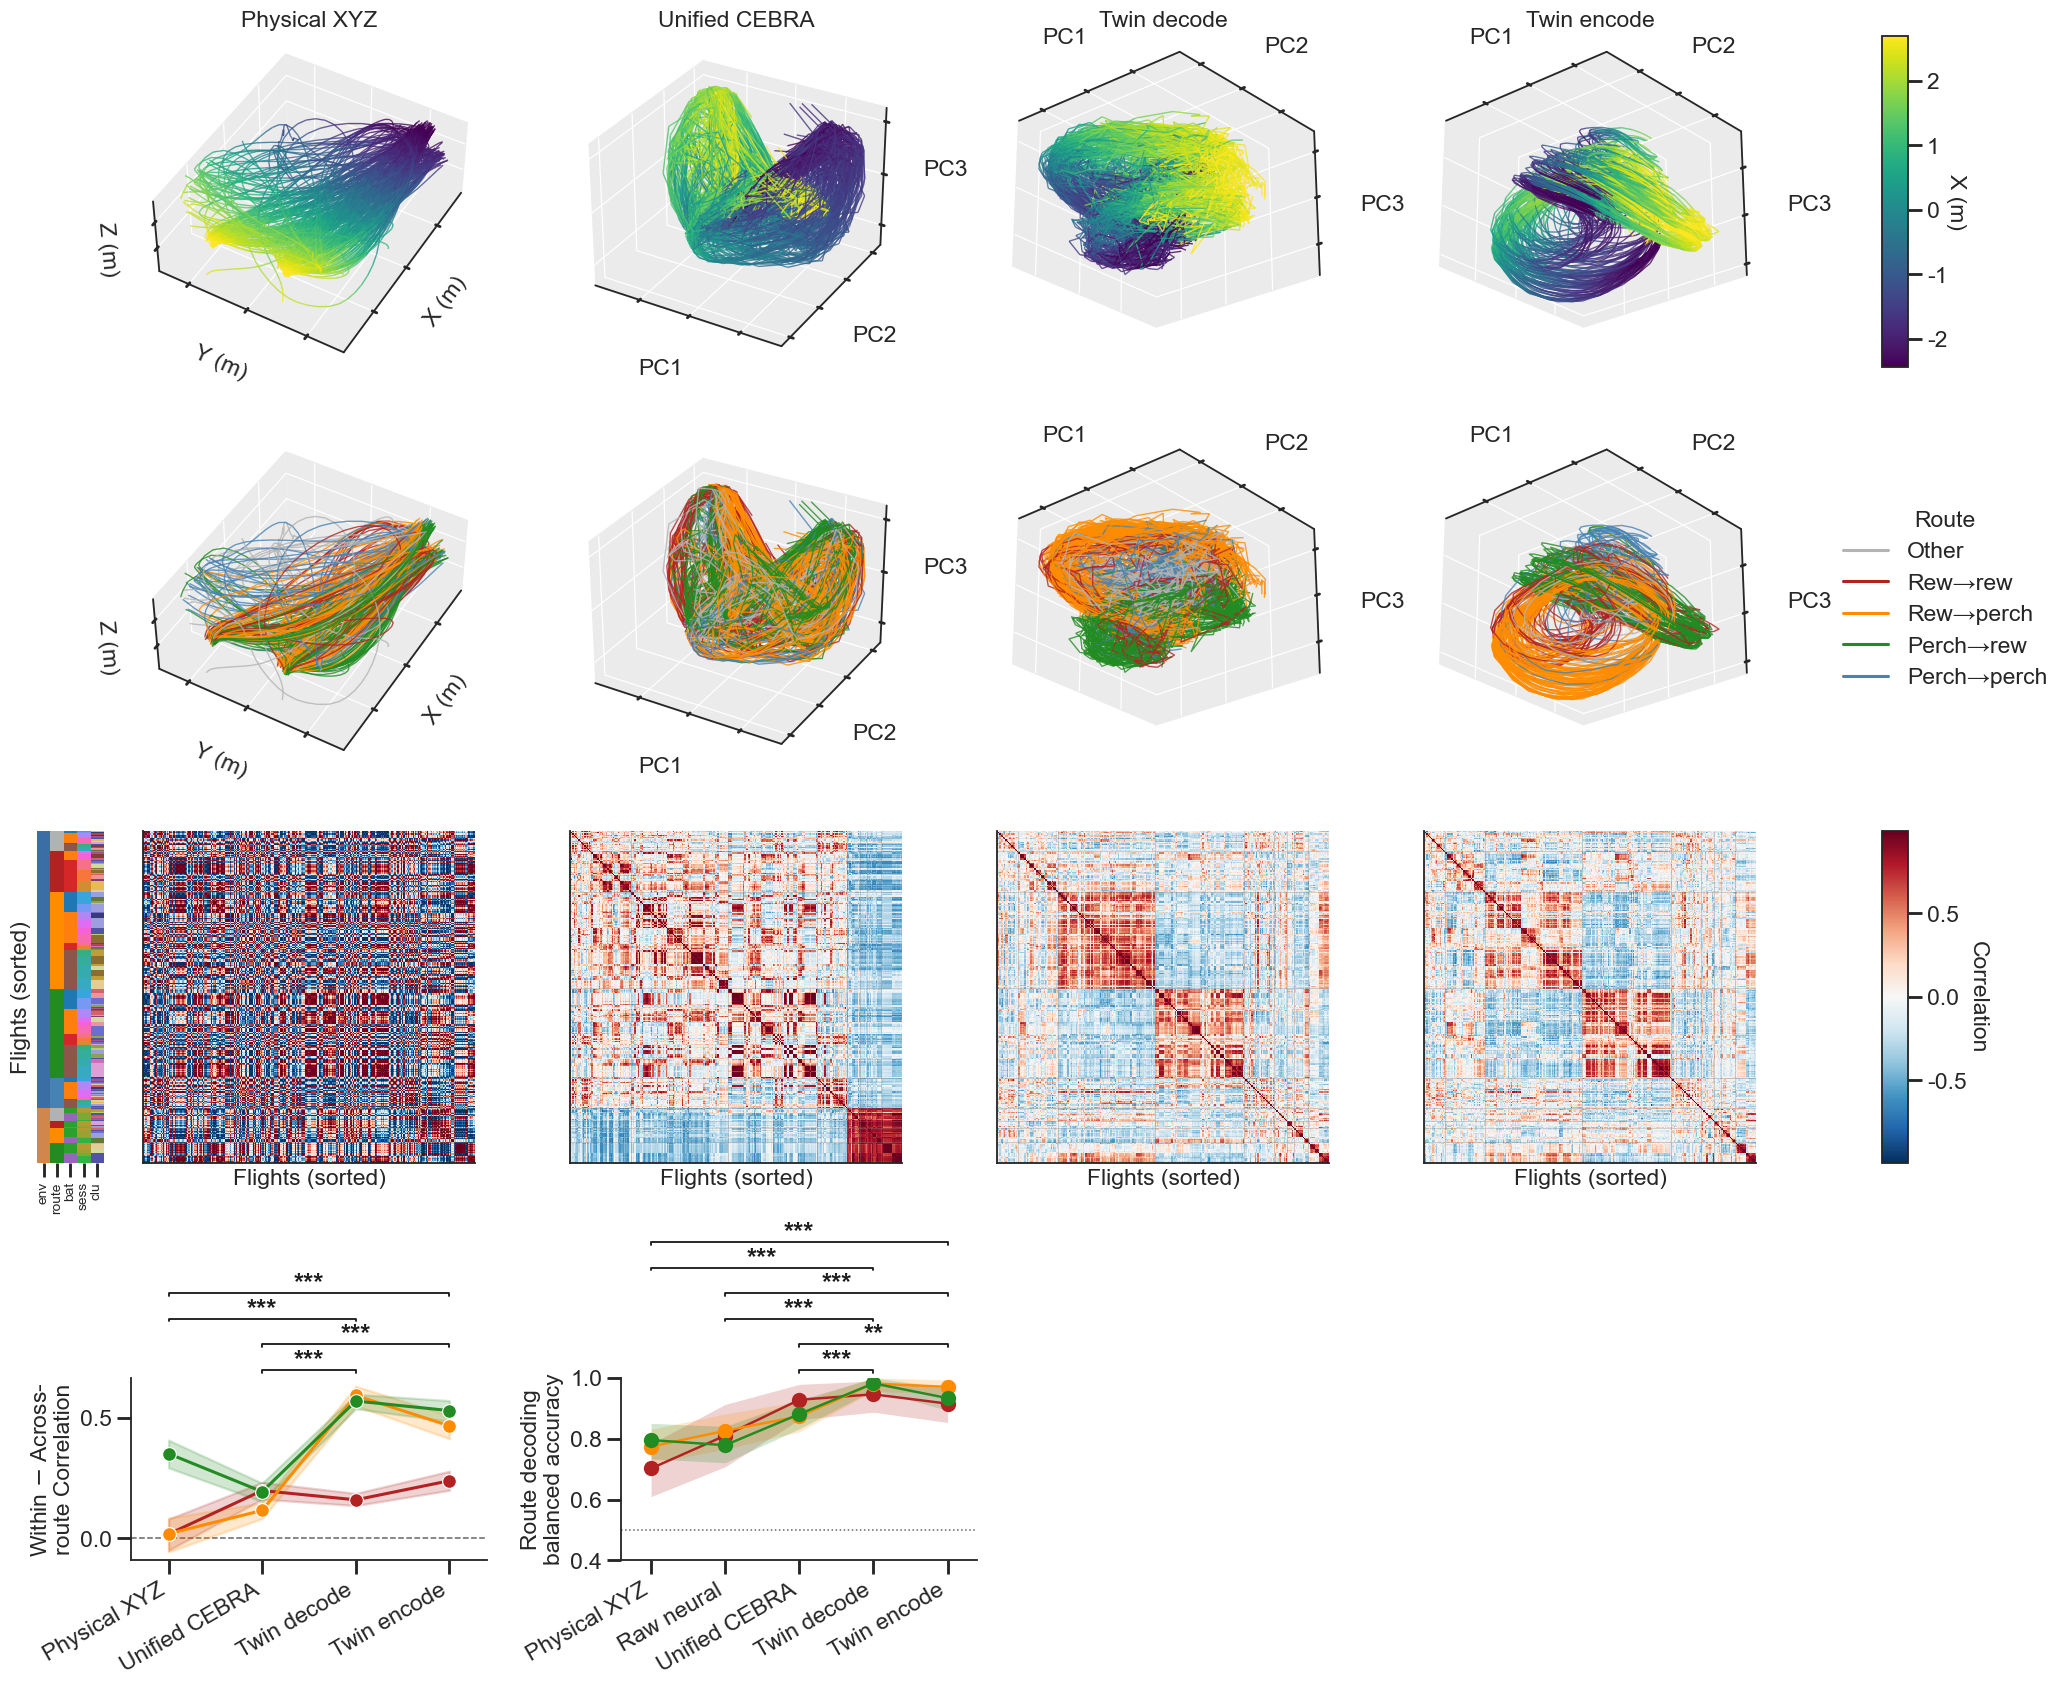

Fig 2 row 4 (indoor, RR/RP/PR) — mean within−across-route r & one-vs-rest balanced decoding accuracy (chance 0.5):
               mean_align  mean_bal_acc
space                                  
Physical XYZ        0.150         0.757
Twin decode         0.506         0.970
Twin encode         0.451         0.940
Unified CEBRA       0.161         0.894
Raw neural            NaN         0.805
Pooled paired comparisons (Twin decode/encode vs Physical XYZ / Unified CEBRA / Raw neural):
  Twin decode        vs Physical XYZ    align p=8.85e-28   decode p=3.41e-25
  Twin decode        vs Unified CEBRA   align p=4.6e-28   decode p=6.91e-08
  Twin decode        vs Raw neural      align p=nan   decode p=4.95e-13
  Twin encode        vs Physical XYZ    align p=2.34e-20   decode p=3.73e-19
  Twin encode        vs Unified CEBRA   align p=2.85e-27   decode p=0.0025
  Twin encode        vs Raw neural      align p=nan   decode p=1.94e-08


In [53]:
# === Figure 2: physical / CEBRA / Twin embeddings as 3-D trajectories ===
# internals.ipynb style: every flight is one connected 3-D polyline (no bare
# points). Columns: Physical XYZ, Unified CEBRA (3-D), Twin latent (PCA-3
# of the 64-d latent). Top row colours each trajectory by the animal's
# x-coordinate (continuous); row 2 by flight route (categorical); row 3 shows the
# RSA matrices; row 4 quantifies cross-bat route alignment two ways (see below).
from sklearn.decomposition import PCA

MAX_FLIGHTS = 250
_rng = np.random.default_rng(seed)

# --- Physical XYZ + Twin latent: per-flight trajectories from `emb` (indoor) ---
_ind_pt = np.array([ph.is_indoor(s) for s in emb['session']])
# Shared PCA-3: fit ONE basis on encode+decode latents (concatenated) so the two
# Twin branches live in the exact same PC space (PC1/2/3) and are comparable.
# (same fit_shared_latent_pca functionality as ED Fig 5, on a different subset).
_pca3 = nh.fit_shared_latent_pca(emb['latent'][_ind_pt], emb['latent_decode'][_ind_pt], n_components=3, random_state=seed)
_lat3 = _pca3.transform(emb['latent'])
_latd3 = _pca3.transform(emb['latent_decode'])
_colx = emb['xyz'][:, 0]  # raw metres, matching the physical x-axis
_key = np.char.add(np.char.add(emb['session'], '|'), emb['flight_id'].astype(str))

phys_trajs, lat_trajs, latd_trajs, xcol, routes = [], [], [], [], []
for k in np.unique(_key[_ind_pt]):
    m = np.where(_key == k)[0]
    o = m[np.argsort(emb['rel_t'][m])]
    phys_trajs.append(emb['xyz'][o]); lat_trajs.append(_lat3[o]); latd_trajs.append(_latd3[o])
    xcol.append(_colx[o]); routes.append(int(emb['route'][o[0]]))

# --- Unified CEBRA: per-flight 3-D embeddings from uni_te (guarded on CEBRA) ---
cebra_trajs, cebra_xcol, cebra_routes = [], [], []
if cebra_frechet is not None:
    _tmp, _cx, _cs = [], [], []
    for s in session_names:
        if not ph.is_indoor(s):
            continue
        rew, perch = get_target_locs(s)
        for embp, f in uni_te[s]:
            pos = f['pos']
            oc = ph.endpoint_class(pos[0], rew, perch, DIST_THRESH)
            dc = ph.endpoint_class(pos[-1], rew, perch, DIST_THRESH)
            _tmp.append((np.asarray(embp), ph.route_id(oc, dc)))
            _cx.append(pos[:, 0]); _cs.append(np.full(len(pos), s))
    _zx = np.concatenate(_cx)  # raw metres
    _parts = np.split(_zx, np.cumsum([len(x) for x in _cx])[:-1])
    # PCA the CEBRA outputs to 3-D (best model has output_dimension > 3), same as
    # the Twin latent: fit on all indoor CEBRA points, transform per flight.
    if _tmp:
        _cpca = PCA(n_components=3, random_state=seed).fit(np.vstack([e for e, _ in _tmp]))
        _tmp = [(_cpca.transform(e), r) for e, r in _tmp]
    for (embp, r), zxi in zip(_tmp, _parts):
        cebra_trajs.append(embp); cebra_xcol.append(zxi); cebra_routes.append(r)


def _subsample(*lists, n=MAX_FLIGHTS):
    L = len(lists[0])
    if L <= n:
        return lists
    sel = np.sort(_rng.choice(L, n, replace=False))
    return tuple([lst[i] for i in sel] for lst in lists)


phys_trajs, lat_trajs, latd_trajs, xcol, routes = _subsample(phys_trajs, lat_trajs, latd_trajs, xcol, routes)
if cebra_trajs:
    cebra_trajs, cebra_xcol, cebra_routes = _subsample(cebra_trajs, cebra_xcol, cebra_routes)

# --- Columns in the requested order (CEBRA in the middle when available) ---
columns = [('Physical XYZ', phys_trajs, xcol, routes, ('x (m)', 'y (m)', 'z (m)'))]
if cebra_trajs:
    columns.append(('Unified CEBRA', cebra_trajs, cebra_xcol, cebra_routes,
                    ('PC1', 'PC2', 'PC3')))
columns.append(('Twin neural latent: decode', latd_trajs, xcol, routes, ('PC1', 'PC2', 'PC3')))
columns.append(('Twin neural latent: encode', lat_trajs, xcol, routes, ('PC1', 'PC2', 'PC3')))

ncol = len(columns)
NROW = 4          # rows 1-2: 3-D trajectories, 3: RSA matrices, 4: route-alignment quantification
xvlim = tuple(np.nanpercentile(np.concatenate(xcol), [2, 98]))
fig2 = plt.figure(figsize=(4.8 * ncol, 18.0))
top_axes, bot_axes, sm, LBL = [], [], None, 15


# Per-column 3-D view orientation (both rows of a column share one view):
#   Physical XYZ  -> 90 deg about z (y to front, x right) + slight top-down tilt
#   Unified CEBRA -> default view (no rotation)
#   Twin    -> figure-8 view found interactively (internals Plotly readout)
def _set_view(ax, col):
    if col == 'Physical XYZ':
        ax.view_init(elev=ax.elev + 15, azim=ax.azim + 90)   # y front, x right, more top-down
    elif col.startswith('Twin'):
        ax.view_init(elev=-25.5, azim=130.6)   # figure-8 view (interactive readout)


def _ref_grid(ax):
    """White reference gridlines on grey panes (applied to every 3-D panel)."""
    from matplotlib.ticker import MaxNLocator
    ax.xaxis.set_major_locator(MaxNLocator(4)); ax.yaxis.set_major_locator(MaxNLocator(4))
    ax.zaxis.set_major_locator(MaxNLocator(3))
    ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
    for _axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        _axis.set_pane_color((0.92, 0.92, 0.92, 1.0))
        _axis._axinfo['grid'].update(color='white', linewidth=0.8)
    ax.grid(True)


for j, (title, trajs, xc, rt, axl) in enumerate(columns):
    ax0 = fig2.add_subplot(NROW, ncol, j + 1, projection='3d'); top_axes.append(ax0)
    sm = ph.plot_trajectories_3d(ax0, trajs, xc, cmap='viridis', vlim=xvlim, lw=0.9, show_endpoints=False)
    _set_view(ax0, title); _ref_grid(ax0)
    ax0.set_title(title, fontsize=LBL)
    ax0.set_xlabel(axl[0], fontsize=LBL); ax0.set_ylabel(axl[1], fontsize=LBL); ax0.set_zlabel(axl[2], fontsize=LBL)
    ax1 = fig2.add_subplot(NROW, ncol, ncol + j + 1, projection='3d'); bot_axes.append(ax1)
    ph.plot_trajectories_3d(ax1, trajs, rt, categorical=True, cat_colors=ph.ROUTE_COLORS, lw=0.9, show_endpoints=False)
    _set_view(ax1, title); _ref_grid(ax1)
    ax1.set_xlabel(axl[0], fontsize=LBL); ax1.set_ylabel(axl[1], fontsize=LBL); ax1.set_zlabel(axl[2], fontsize=LBL)
    if title == 'Physical XYZ':
        _box = tuple(np.vstack([np.asarray(t) for t in trajs]).max(0)
                     - np.vstack([np.asarray(t) for t in trajs]).min(0))
        ax0.set_box_aspect(_box); ax1.set_box_aspect(_box)
    if j == 0:
        # tuck the z-axis label inward; the row label sits outside (left of) it
        ax0.set_zlabel('z (m)', fontsize=LBL, labelpad=-4)
        ax1.set_zlabel('z (m)', fontsize=LBL, labelpad=-4)

# Dedicated colorbar axes to the right of the top row: unlike colorbar(ax=top_axes),
# this steals no width from the panels, so the three columns stay aligned on both rows.
_ptr = top_axes[-1].get_position()
_cax = fig2.add_axes([_ptr.x1 + 0.06, _ptr.y0, 0.012, _ptr.height])
cb = fig2.colorbar(sm, cax=_cax)
cb.set_label('x (m)', fontsize=LBL, rotation=270, labelpad=12)
handles = [plt.Line2D([], [], color=ph.ROUTE_COLORS[k], lw=2, label=ph.ROUTE_LABELS[k])
           for k in range(len(ph.ROUTE_LABELS))]
# offset right (past the PC3 z-axis label) so the legend doesn't overlap it
_leg = bot_axes[-1].legend(handles=handles, title='route', loc='center left',
                     bbox_to_anchor=(1.2, 0.5), frameon=False, fontsize=LBL)
_leg.get_title().set_fontsize(LBL)

# --- Row 3: RSA matrices, one directly below each column above ---
from matplotlib.colors import to_rgb
_env_pal = ph.env_palette()
_env_colors = {0: _env_pal['indoor'], 1: _env_pal['outdoor']}   # indoor / outdoor
_route_pal = ph.route_palette()
_n_clu = int(rsa_meta['cluster'].max()) + 1
_clu_pal = list(ph.flight_cluster_palette(range(max(_n_clu, 3))).values())
_sess_pal = list(ph.session_palette(sorted(session_names)).values())
_bars = np.zeros((len(rsa_order), 5, 3))                          # env, route, bat, sess, clu
for _i in range(len(rsa_order)):
    _bars[_i, 0] = to_rgb(_env_colors[int(rsa_meta['env'][_i])])
    _bars[_i, 1] = to_rgb(_route_pal[int(rsa_meta['route'][_i])])
    _bars[_i, 2] = to_rgb(BAT_PALETTE.get(rsa_meta['bat'][_i], '0.5'))
    _bars[_i, 3] = to_rgb(_sess_pal[int(rsa_meta['session'][_i])])
    _bars[_i, 4] = to_rgb(_clu_pal[int(rsa_meta['cluster'][_i]) % len(_clu_pal)])
# shared colour scale across the four matrices (diagonal saturates at 1)
_off = np.concatenate([M[~np.eye(len(M), dtype=bool)] for M in rsa_mats.values()])
_vmin, _vmax = np.percentile(_off, [1, 99])
# route-block boundaries: rows where (env, route) changes under the shared ordering
_er = np.column_stack([rsa_meta['env'], rsa_meta['route']])
_route_bnd = 1 + np.where((_er[1:] != _er[:-1]).any(axis=1))[0]
rsa_axes, _im = [], None
for j, (name, _fn) in enumerate(rsa_conditions):
    axr = fig2.add_subplot(NROW, ncol, 2 * ncol + j + 1); rsa_axes.append(axr)
    _im = axr.imshow(rsa_mats[name], vmin=_vmin, vmax=_vmax, cmap='RdBu_r', interpolation='nearest')
    axr.set_xticks([]); axr.set_yticks([])
    axr.set_xlabel('Flights (sorted)', fontsize=LBL)
    for _b in _route_bnd:                       # faint grey route dividers (within env)
        axr.axhline(_b - 0.5, color='0.5', lw=0.4, alpha=0.5)
        axr.axvline(_b - 0.5, color='0.5', lw=0.4, alpha=0.5)
    if j == 0:
        # barber-pole strips (environment, route, bat, session, cluster) + row label
        bax = axr.inset_axes([-0.32, 0.0, 0.20, 1.0])
        bax.imshow(_bars, aspect='auto', interpolation='nearest')
        bax.set_xticks(range(5)); bax.set_xticklabels(['env', 'route', 'bat', 'sess', 'clu'],
                                                      rotation=90, fontsize=9)
        bax.set_yticks([]); bax.set_ylabel('Flights (sorted)', fontsize=LBL)
        for _sp in bax.spines.values():
            _sp.set_visible(False)

# RSA colourbar to the right of the last matrix (mirrors the x colourbar above)
_rp = rsa_axes[-1].get_position()
_rcax = fig2.add_axes([_rp.x1 + 0.06, _rp.y0, 0.012, _rp.height])
_rcb = fig2.colorbar(_im, cax=_rcax); _rcb.set_label('Correlation', fontsize=LBL, rotation=270, labelpad=14)

# --- Row 4: cross-bat route alignment quantified two ways, INDOOR flights only, over
#     routes RR / RP / PR (drop 'other' and 'perch->perch'). Two panels, each the width
#     of one RSA matrix above (together half a row): x = embedding space, hue = route
#     (shared route palette + the route legend above; no new legend).
#   (A) within-route minus across-route Pearson r. Per route = the RSA block-diagonal
#       mean (within-route flight pairs) minus that route's cross-"L" mean (its pairs
#       with the OTHER routes only). Per flight = (block-row mean) - (L-row mean).
#   (B) route decoded from the time-averaged representation with a basic RBF SVC. The
#       shared-latent / physical spaces use one classifier over all indoor flights; the
#       extra "Raw neural" space decodes from time-averaged spikes fit PER SESSION
#       (neuron spaces differ), then pooled across flights the same way.
#   Brackets (both panels): Twin decode & encode vs Physical XYZ and Unified CEBRA,
#   pooling all pictured RR/RP/PR flights (paired Wilcoxon for r; McNemar for accuracy).
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score
from scipy.stats import wilcoxon
from statsmodels.stats.contingency_tables import mcnemar

_KEEP_ROUTES = [1, 2, 3]                            # rew->rew, rew->perch, perch->rew
_route_pal = ph.route_palette()                    # {route_id: rgb}, shared with rows above
_env_arr, _route_arr = rsa_meta['env'], rsa_meta['route']
_V = np.where((_env_arr == 0) & np.isin(_route_arr, _KEEP_ROUTES))[0]   # indoor, RR/RP/PR
_rv = _route_arr[_V]
_align_spaces = [n for n, _ in rsa_conditions]     # Physical XYZ, [CEBRA], decode, encode
_getter = dict(rsa_conditions)
_align_pos = {n: i for i, n in enumerate(_align_spaces)}
_HD, _HE = f'{OUR_MODEL} neural latent: decode', f'{OUR_MODEL} neural latent: encode'
_refs = [n for n in ('Physical XYZ', 'Unified CEBRA') if n in _align_spaces]
_MIN_PER_CLASS = 3

# (A) within - across-route Pearson r, per flight (indoor, RR/RP/PR)
_arows = []
for _name in _align_spaces:
    _S = rsa_mats[_name][np.ix_(_V, _V)]
    for _p in range(len(_V)):
        _R = _rv[_p]
        _wi = (_rv == _R).copy(); _wi[_p] = False          # block row: same-route pairs
        _ac = _rv != _R                                     # L row: pairs with other routes
        if _wi.sum() < 1 or _ac.sum() < 1:
            continue
        _arows.append(dict(space=_name, route=int(_R), flight=int(_V[_p]),
                           pos=_align_pos[_name], metric=float(_S[_p, _wi].mean() - _S[_p, _ac].mean())))
align_df = pd.DataFrame(_arows)


def _binary_oof(X, ybin):
    """Out-of-fold predictions from a basic fixed-C RBF SVC for a one-vs-rest (yes/no)
    route label. Needs >= _MIN_PER_CLASS of each class; returns predictions or None."""
    cnt = np.bincount(ybin, minlength=2)
    if cnt.min() < _MIN_PER_CLASS:
        return None
    ns = int(min(5, cnt.min()))                          # <= members in the smaller class
    cv = StratifiedKFold(n_splits=ns, shuffle=True, random_state=seed)
    clf = Pipeline([('scaler', StandardScaler()),
                    ('svc', SVC(kernel='rbf', class_weight='balanced', C=1.0))])
    return cross_val_predict(clf, X, ybin, cv=cv)


# (B) route decoding: one binary (yes/no) one-vs-rest classifier PER route (RR, RP, PR),
# so chance is 50% (balanced accuracy) and a session missing one of the three routes can
# still contribute to the other two. Shared/physical spaces pool all indoor flights; Raw
# neural is fit per session (per route) then its predictions pooled across flights.
_drows = []
for _name in _align_spaces:
    _g = _getter[_name]
    _X = np.vstack([np.asarray(_g(rsa_order[i]), float).mean(0) for i in _V])
    for _R in _KEEP_ROUTES:
        _yb = (_rv == _R).astype(int)
        _pred = _binary_oof(_X, _yb)
        if _pred is None:
            continue
        for _j in range(len(_V)):
            _drows.append(dict(space=_name, route=_R, flight=int(_V[_j]),
                               y_true=int(_yb[_j]), y_pred=int(_pred[_j])))
_keys = [rsa_order[i] for i in _V]
_sess = np.array([rsa_recs[k]['session'] for k in _keys])
for _sn in sorted(set(_sess.tolist())):
    _sel = np.where(_sess == _sn)[0]
    _Xs = np.vstack([np.sqrt(np.clip(rsa_recs[_keys[i]]['spike'], 0, None)).mean(0) for i in _sel])
    _rsel = _rv[_sel]
    for _R in _KEEP_ROUTES:
        _yb = (_rsel == _R).astype(int)
        _pred = _binary_oof(_Xs, _yb)
        if _pred is None:
            continue
        for _j in range(len(_sel)):
            _drows.append(dict(space='Raw neural', route=_R, flight=int(_V[_sel[_j]]),
                               y_true=int(_yb[_j]), y_pred=int(_pred[_j])))
decode_df = pd.DataFrame(_drows)
decode_df['correct'] = (decode_df['y_true'] == decode_df['y_pred']).astype(float)
_decode_spaces = list(_align_spaces)                       # Raw neural sits between Physical & CEBRA
_decode_spaces.insert(_decode_spaces.index('Physical XYZ') + 1, 'Raw neural')
_decode_pos = {n: i for i, n in enumerate(_decode_spaces)}


def _bacc_ci(yt, yp, n_boot=1000):
    """Balanced accuracy + class-stratified bootstrap 95% CI (chance = 0.5)."""
    yt, yp = np.asarray(yt), np.asarray(yp)
    ba = balanced_accuracy_score(yt, yp)
    _i0, _i1 = np.where(yt == 0)[0], np.where(yt == 1)[0]
    _rng = np.random.default_rng(seed)
    _bs = np.array([balanced_accuracy_score(
        yt[_s], yp[_s]) for _s in (np.concatenate([_rng.choice(_i0, len(_i0)),
                                                    _rng.choice(_i1, len(_i1))]) for _ in range(n_boot))])
    return ba, float(np.percentile(_bs, 2.5)), float(np.percentile(_bs, 97.5))


_bacc_rows = []
for (_sp, _R), _sub in decode_df.groupby(['space', 'route']):
    if _sub['y_true'].nunique() < 2:
        continue
    _ba, _lo, _hi = _bacc_ci(_sub['y_true'].values, _sub['y_pred'].values)
    _bacc_rows.append(dict(space=_sp, route=int(_R), pos=_decode_pos[_sp], bal=_ba, lo=_lo, hi=_hi))
bacc_df = pd.DataFrame(_bacc_rows)


def _pool_wilcoxon(a, b):                          # paired over pooled flights (alignment)
    w = align_df.pivot_table(index='flight', columns='space', values='metric')
    if a not in w or b not in w:
        return np.nan
    d = w[[a, b]].dropna()
    if len(d) < 2 or np.all(d[a].values == d[b].values):
        return np.nan
    return float(wilcoxon(d[a].values, d[b].values).pvalue)


def _pool_mcnemar(a, b):                           # paired binary over pooled (flight, route) tasks
    w = decode_df.pivot_table(index=['flight', 'route'], columns='space', values='correct')
    if a not in w or b not in w:
        return np.nan
    d = w[[a, b]].dropna()
    n01 = int(((d[a] == 0) & (d[b] == 1)).sum()); n10 = int(((d[a] == 1) & (d[b] == 0)).sum())
    if n01 + n10 == 0:
        return np.nan
    return float(mcnemar([[0, n01], [n10, 0]], exact=(n01 + n10) < 25).pvalue)


def _style_brackets(ax, spaces, posmap, pfun, *, chance=None, zeroline=False, fix_ylim=None):
    """Shared styling + Twin decode/encode-vs-reference brackets for a half-matrix
    panel (references: Physical XYZ, Unified CEBRA, and -- decoding only -- Raw neural).
    Brackets float in the margin ABOVE the axes (the panels are shortened to leave room);
    returns the axes-fraction y at which the title should sit, clear of the brackets."""
    if zeroline:
        ax.axhline(0, color='0.4', lw=1, ls='--', zorder=0)
    if chance is not None:
        ax.axhline(chance, color='0.4', lw=1, ls=':', zorder=0)
    ax.set_xticks(range(len(spaces)))
    ax.set_xticklabels(spaces, rotation=30, ha='right', fontsize=LBL)   # match the axis label
    ax.set_xlim(-0.4, len(spaces) - 0.6)
    if fix_ylim is not None:
        ax.set_ylim(*fix_ylim)
    _brefs = [n for n in ('Physical XYZ', 'Unified CEBRA', 'Raw neural') if n in posmap]
    _comps = sorted([(r, t) for t in (_HD, _HE) if t in posmap for r in _brefs],
                    key=lambda c: -abs(posmap[c[1]] - posmap[c[0]]))   # longest span first (top)
    _step = 0.14                                           # bracket spacing (further apart)
    _base = 1.03 + (len(_comps) - 1) * _step               # brackets stack in the margin above
    for _lvl, (_r, _t) in enumerate(_comps):
        ph.sig_bracket(ax, posmap[_r], posmap[_t], pfun(_r, _t), level=_lvl,
                       base=_base, step=_step, star_gap=-0.02)   # stars close to their bracket
    return _base + 0.12


# Both row-4 panels are shortened (anchored at their bottom) so the brackets/asterisks
# have room above them, in the gap below the RSA matrices.
_PANEL_FRAC = 0.55


def _shrink(ax):
    _p = ax.get_position()
    ax.set_position([_p.x0, _p.y0, _p.width, _p.height * _PANEL_FRAC])


# Panel A: alignment -- per-flight mean +/- 95% CI, x=embedding space, hue=route.
_axA = fig2.add_subplot(NROW, ncol, 3 * ncol + 1)      # row 4, col 1 (width of one matrix)
_shrink(_axA)
_a_rts = sorted(align_df['route'].unique())
sns.lineplot(data=align_df, x='pos', y='metric', hue='route', hue_order=_a_rts,
             palette={r: _route_pal[r] for r in _a_rts}, marker='o', err_style='band',
             legend=False, ax=_axA)
_style_brackets(_axA, _align_spaces, _align_pos, _pool_wilcoxon, zeroline=True)
_axA.set_ylabel('Within $-$ Across-\nroute Correlation', fontsize=LBL)
_axA.set_xlabel('')

# Panel B: decoding -- one-vs-rest balanced accuracy per route (chance 0.5), line +
# bootstrap 95% CI per route across embedding spaces. Nudged right for a wider gap.
_axB = fig2.add_subplot(NROW, ncol, 3 * ncol + 2)      # row 4, col 2 (next matrix width)
_shrink(_axB)
_pB = _axB.get_position(); _axB.set_position([_pB.x0 + 0.03, _pB.y0, _pB.width, _pB.height])
for _R in sorted(bacc_df['route'].unique()):
    _sub = bacc_df[bacc_df['route'] == _R].sort_values('pos')
    _axB.plot(_sub['pos'], _sub['bal'], marker='o', lw=1.6, color=_route_pal[_R], zorder=3)
    _axB.fill_between(_sub['pos'], _sub['lo'], _sub['hi'], color=_route_pal[_R], alpha=0.2, lw=0)
_style_brackets(_axB, _decode_spaces, _decode_pos, _pool_mcnemar, chance=0.5, fix_ylim=(0.4, 1.0))
_axB.set_ylabel('Route decoding\nbalanced accuracy', fontsize=LBL)
_axB.set_xlabel('')

ph.save_fig(fig2, 'fig2_embeddings'); plt.show()

# summary: mean within-across alignment / one-vs-rest balanced accuracy per space + p-values
print('Fig 2 row 4 (indoor, RR/RP/PR) — mean within−across-route r & one-vs-rest '
      'balanced decoding accuracy (chance 0.5):')
_al = align_df.groupby('space')['metric'].mean().rename('mean_align')
_de = bacc_df.groupby('space')['bal'].mean().rename('mean_bal_acc')
print(pd.concat([_al, _de], axis=1).round(3).to_string())
print(f'Pooled paired comparisons ({OUR_MODEL} decode/encode vs Physical XYZ / Unified '
      'CEBRA / Raw neural):')
_cmp_refs = _refs + (['Raw neural'] if 'Raw neural' in _decode_pos else [])
for _t in (_HD, _HE):
    for _r in _cmp_refs:
        print(f'  {_t:18s} vs {_r:14s}  align p={_pool_wilcoxon(_r, _t):.3g}   '
              f'decode p={_pool_mcnemar(_r, _t):.3g}')

**Figure 2 | The transformer latent embedding warps physical space to emphasise flight-route identity and align across animals.** Each point is one held-out flight time-bin from the indoor lab sessions (Datasets 1 & 3). Columns: true 3-D position (top-down x–y), the 64-dimensional transformer latent projected to 2-D (PCA followed by a rotation that separates the two dominant route lobes horizontally), and the unified-CEBRA latent (same rotation procedure). **a–c**, coloured by (per-session z-scored) x-coordinate. **d–f**, coloured by flight route (origin→destination endpoint class). Unlike physical space and the CEBRA embedding, the transformer latent segregates flights primarily by route identity rather than by instantaneous position.

---
## Extended Data Figure 5 — encode/decode latent and read-out subspace geometry


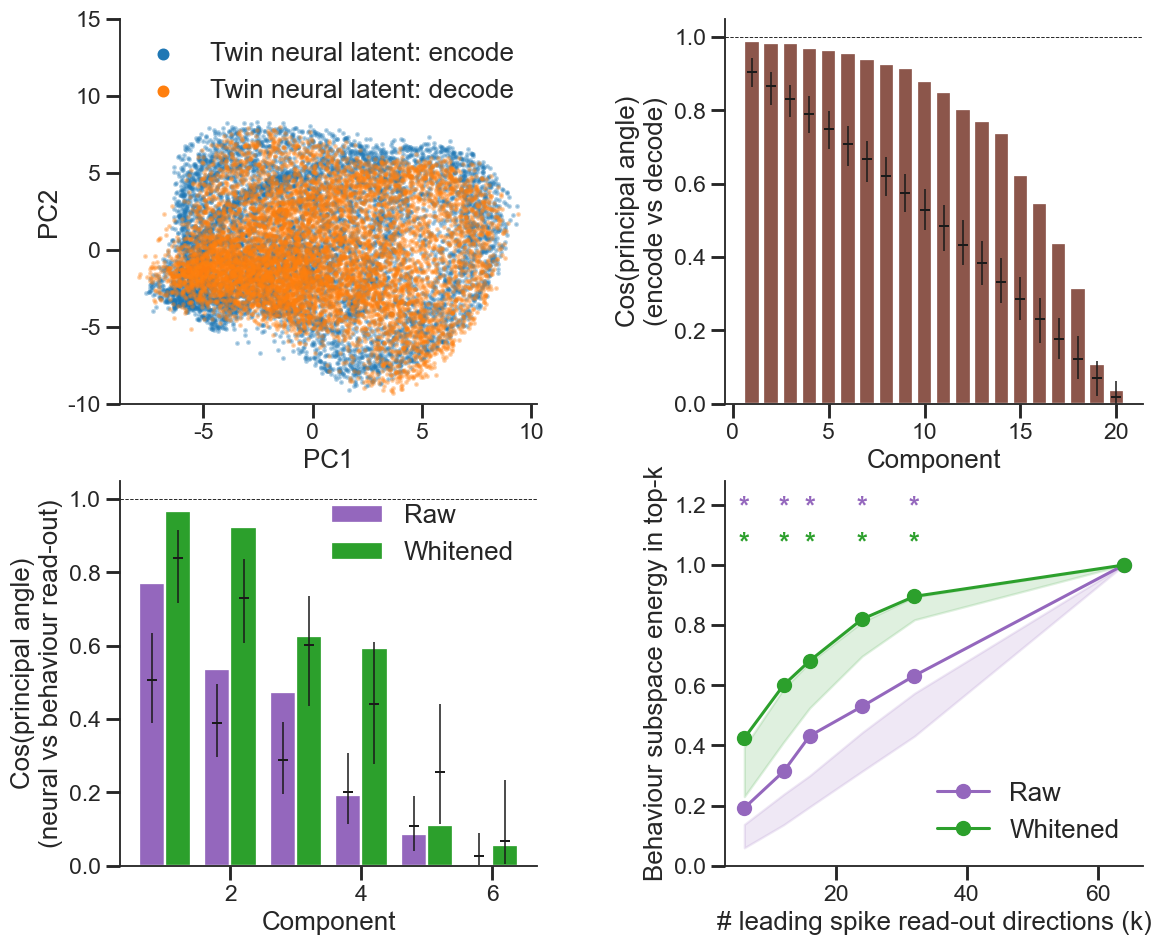

participation ratio: encode=20.4 decode=21.1 (d_sub=20); behaviour read-out rank d_ro=6
encode/decode mean cos²=0.628 (chance 0.312)
read-out mean cos²: raw=0.192  whitened=0.425


In [78]:
# === ED Fig 5: Twin neural latent (encode vs decode) + read-out subspace geometry ===
# Both latents are the neural-token half x[:, :T] (Fig 2 convention): encode = neural
# predicted from behaviour, decode = neural extracted from observed spikes.
# a) PC1 vs PC2 of the pre-read-out latent (encode vs decode, both x[:, :T]);
# b) cos(principal angle) between encode/decode activation subspaces vs component;
# c) cos(principal angle) between the dominant spike vs behaviour read-out
#    directions, raw and whitened, with random-read-out null CIs;
# d) behaviour-subspace energy captured by the top-k spike read-out directions,
#    raw and whitened, with null CIs. (Ports joint-encode-decode.ipynb §9.)
from sklearn.decomposition import PCA


@torch.no_grad()
def _collect_enc_dec_latents(model, loaders, device):
    """Row-aligned pre-read-out encode (h_n) and decode (h_b) latents over a split.
    encode: spikes masked, behaviour seen -> xfull[:, :T]; decode: behaviour masked,
    spikes seen -> ALSO xfull[:, :T] here (Fig-2 convention), not xfull[:, T:]."""
    model.eval(); Le, Ld = [], []
    for s, sd in loaders.items():
        for b in sd:
            m = b.mask.to(device); T = b.spike.shape[1]
            sp, bh = b.spike.to(device), b.behavior.to(device)
            nt = b.mask.clone().to(device)
            _, _, xe = model(s, sp, bh, m, nt, torch.zeros_like(nt))
            bt = b.mask.clone().to(device)
            _, _, xd = model(s, sp, bh, m, torch.zeros_like(bt), bt)
            mk = b.mask.numpy().astype(bool)
            Le.append(nh.masked_latent(xe, T, 'encode').cpu().numpy()[mk])  # neural tokens x[:, :T]
            Ld.append(xd[:, :T].cpu().numpy()[mk])  # decode in the SAME encode space x[:, :T] (Fig 2)
    return np.vstack(Le), np.vstack(Ld)


L_enc, L_dec = _collect_enc_dec_latents(joint_model, joint_loaders['test'], device)
_D = L_enc.shape[1]


def _pca_basis(L, d):
    _, _, Vt = np.linalg.svd(L - L.mean(0), full_matrices=False); return Vt[:d].T


def participation_ratio(L):
    s = np.linalg.svd(L - L.mean(0), compute_uv=False) ** 2
    return float(s.sum() ** 2 / (s ** 2).sum())


def principal_angles_cos(A, B):
    return np.clip(np.linalg.svd(A.T @ B, compute_uv=False), 0.0, 1.0)


def _svd_basis(W, d):
    _, _, Vt = np.linalg.svd(W, full_matrices=False); return Vt[:d].T


def _energy_in(Q, V):
    return float(np.trace(Q.T @ V @ V.T @ Q) / Q.shape[1])


def _null_pa_cos(d1, d2, D, n=300, seed_=1):
    rng = np.random.default_rng(seed_); out = []
    for _ in range(n):
        A = np.linalg.qr(rng.standard_normal((D, d1)))[0]
        B = np.linalg.qr(rng.standard_normal((D, d2)))[0]
        out.append(np.clip(np.linalg.svd(A.T @ B, compute_uv=False), 0.0, 1.0))
    return np.array(out)


# encode/decode activation subspaces, matched to the participation ratio
pr_enc, pr_dec = participation_ratio(L_enc), participation_ratio(L_dec)
d_sub = max(2, int(round(min(pr_enc, pr_dec))))
Venc, Vdec = _pca_basis(L_enc, d_sub), _pca_basis(L_dec, d_sub)
ang_ed = principal_angles_cos(Venc, Vdec)


def _readout_rows(mod):
    mods = mod.values() if isinstance(mod, nn.ModuleDict) else [mod]
    return np.vstack([m.weight.detach().cpu().numpy() for m in mods])


W_spk = _readout_rows(joint_model.spike_readout)     # (sum_K, D)
W_beh = _readout_rows(joint_model.beh_readout)       # (3*n_rooms, D)
d_ro = int(np.linalg.matrix_rank(W_beh))             # behaviour read-out rank (<= 3*n_rooms)
Qb, Qs = _svd_basis(W_beh, d_ro), _svd_basis(W_spk, d_ro)
ang_ro = principal_angles_cos(Qs, Qb)

# whitened (functional) read-out directions: W @ C^{1/2}, C = pooled latent covariance
Cz = np.cov(np.vstack([L_enc, L_dec]), rowvar=False)
_ev, _evec = np.linalg.eigh(Cz)
C_half = (_evec * np.sqrt(np.clip(_ev, 0.0, None))) @ _evec.T


def _whiten_basis(W, d):
    return np.linalg.svd(W @ C_half, full_matrices=False)[2][:d].T


Qs_w, Qb_w = _whiten_basis(W_spk, d_ro), _whiten_basis(W_beh, d_ro)
ang_w = principal_angles_cos(Qs_w, Qb_w)

ks = sorted({min(k, _D) for k in [d_ro, 2 * d_ro, 4 * d_ro, 16, 32, 64, _D]})
spk_top_raw = {k: _svd_basis(W_spk, k) for k in ks}
spk_top_w = {k: _whiten_basis(W_spk, k) for k in ks}
curve_raw = [_energy_in(Qb, spk_top_raw[k]) for k in ks]
curve_w = [_energy_in(Qb_w, spk_top_w[k]) for k in ks]

# empirical null: random behaviour read-out of matched Frobenius norm, same pipeline
_rng4 = np.random.default_rng(seed); N_NULL = 300
null_pa = {'raw': [], 'whitened': []}; null_curve = {'raw': [], 'whitened': []}
for _ in range(N_NULL):
    R = _rng4.standard_normal(W_beh.shape); Wb = R * (np.linalg.norm(W_beh) / np.linalg.norm(R))
    for tag, whiten, Qsx, tops in [('raw', False, Qs, spk_top_raw),
                                   ('whitened', True, Qs_w, spk_top_w)]:
        M = Wb @ C_half if whiten else Wb
        Qbx = np.linalg.svd(M, full_matrices=False)[2][:d_ro].T
        null_pa[tag].append(principal_angles_cos(Qsx, Qbx))
        null_curve[tag].append([_energy_in(Qbx, tops[k]) for k in ks])

# --- figure ---
def _sig_row(ax, xs, obs, lo, hi, y, color):
    """Row of significance stars at height y: '*' where obs is outside the null [lo, hi]."""
    for _x, _o, _l, _h in zip(xs, obs, lo, hi):
        if _o > _h or _o < _l:
            ax.text(_x, y, '*', color=color, ha='center', va='center', fontsize=18, fontweight='bold', clip_on=False)


Z = np.vstack([L_enc, L_dec]); task = np.array([0] * len(L_enc) + [1] * len(L_dec))
_sub = np.sort(_rng4.choice(len(Z), min(len(Z), 40000), replace=False))
Z2 = nh.fit_shared_latent_pca(L_enc, L_dec, n_components=3, random_state=seed).transform(Z)[_sub]
tsub = task[_sub]

fig_ed4, axes = plt.subplots(2, 2, figsize=(12, 10))
_lgnd_fs = axes[0, 0].xaxis.label.get_fontsize()  # match legend text to axis-label size
# a) PC1 vs PC2, encode vs decode
for tk, col, lab in [(0, 'tab:blue', 'Twin neural latent: encode'), (1, 'tab:orange', 'Twin neural latent: decode')]:
    mk = tsub == tk
    axes[0, 0].scatter(Z2[mk, 0], Z2[mk, 1], s=3, alpha=0.3, color=col, label=lab, rasterized=True)
axes[0, 0].set(xlabel='PC1', ylabel='PC2', ylim=(-10, 15))
_leg_a = axes[0, 0].legend(fontsize=_lgnd_fs, loc='upper right')
for _lh in _leg_a.legend_handles:
    _lh.set_alpha(1.0); _lh.set_sizes([40])
# b) encode vs decode subspace principal angles
null_ed = _null_pa_cos(d_sub, d_sub, _D, seed_=seed)
_lo, _med, _hi = np.percentile(null_ed, [2.5, 50, 97.5], axis=0); xr = np.arange(1, d_sub + 1)
axes[0, 1].bar(xr, ang_ed, color='tab:brown')
axes[0, 1].vlines(xr, _lo, _hi, color='k', lw=1)
axes[0, 1].plot(xr, _med, '_', color='k', ms=7, mew=1.3)
axes[0, 1].axhline(1, ls='--', color='k', lw=0.6)
axes[0, 1].set(xlabel='component', ylabel='cos(principal angle)\n(encode vs decode)', ylim=(0, 1.05))
# c) spike vs behaviour read-out angles, raw + whitened, with null CIs
xp, wbar = np.arange(1, d_ro + 1), 0.4
for ang_v, col, off, tag in [(ang_ro, 'tab:purple', -wbar / 2, 'raw'),
                             (ang_w, 'tab:green', wbar / 2, 'whitened')]:
    axes[1, 0].bar(xp + off, ang_v, width=wbar, color=col, label=tag)
    nlo, nmed, nhi = np.percentile(np.array(null_pa[tag]), [2.5, 50, 97.5], axis=0)
    axes[1, 0].vlines(xp + off, nlo, nhi, color='k', lw=1)
    axes[1, 0].plot(xp + off, nmed, '_', color='k', ms=7, mew=1.3)
axes[1, 0].axhline(1, ls='--', color='k', lw=0.6)
axes[1, 0].set(xlabel='component', ylabel='cos(principal angle)\n(neural vs behaviour read-out)', ylim=(0, 1.05))
axes[1, 0].legend(fontsize=_lgnd_fs, loc='upper right')
# d) behaviour subspace energy in top-k spike read-out dirs, raw + whitened, with CIs
_cv_ci = {}
for tag, cv, col in [('raw', curve_raw, 'tab:purple'), ('whitened', curve_w, 'tab:green')]:
    lo, hi = np.percentile(np.array(null_curve[tag]), [2.5, 97.5], axis=0); _cv_ci[tag] = (lo, hi)
    axes[1, 1].plot(ks, cv, 'o-', color=col, label=tag)
    axes[1, 1].fill_between(ks, lo, hi, color=col, alpha=0.15)
axes[1, 1].set(xlabel='# leading spike read-out directions (k)',
               ylabel='behaviour subspace energy in top-k', ylim=(0, 1.28))
axes[1, 1].legend(fontsize=_lgnd_fs)
_sig_row(axes[1, 1], ks, curve_raw, *_cv_ci['raw'], 1.19, 'tab:purple')
_sig_row(axes[1, 1], ks, curve_w, *_cv_ci['whitened'], 1.07, 'tab:green')
fig_ed4.subplots_adjust(wspace=0.45)  # more horizontal room between columns
ph.save_fig(fig_ed4, 'edfig5_subspaces'); plt.show()
print(f'participation ratio: encode={pr_enc:.1f} decode={pr_dec:.1f} (d_sub={d_sub}); '
      f'behaviour read-out rank d_ro={d_ro}')
print(f'encode/decode mean cos²={np.mean(ang_ed ** 2):.3f} (chance {d_sub / _D:.3f})')
print(f'read-out mean cos²: raw={np.mean(ang_ro ** 2):.3f}  whitened={np.mean(ang_w ** 2):.3f}')


**Extended Data Figure 5 | Encode/decode latent and read-out subspace geometry.** **a**, First two principal components of the pre-read-out latent for the encode (neural, h_n) and decode (behaviour, h_b) tasks. **b**, Cosine of the principal angles between the encode and decode activation subspaces (matched to the participation ratio d_sub) versus component, with a random-subspace null (2.5–97.5%). **c**, Cosine of the principal angles between the dominant spike and behaviour read-out directions (matched to the behaviour read-out rank d_ro), for raw and covariance-whitened weights, each against a norm-matched random-read-out null. **d**, Fraction of the behaviour output subspace captured by the top-k spike read-out directions (raw and whitened), shaded bands are the 2.5–97.5% random-read-out null. Note d_ro (=6, the 3-coordinate × 2-room output count) is the read-out rank, distinct from the ~32-dim activation participation ratio in b.


---
## Figure 3 — Same route, different paths: route-progress vs absolute-space sequences

Two flight clusters that share **origin and destination** but take geometrically
different 3-D paths between them (large Fréchet distance, small endpoint gaps).
The common coordinate is each path's own cumulative arc length ("route progress").
If place cells fire at the same *fraction* of the route on both detours, the
population sequence is preserved (schematic/topological coding); if they fire at
absolute 3-D positions, the alternate-path sequence is scrambled. Example index 0.

Data are loaded from raw spike times (native `Fs`) via `Data_Prep_for_Raw`, a
separate pipeline from the binned dataloaders (ported from
`investigate_similar_trajectories.ipynb`).

In [32]:
# === Figure 3 data: raw-spike cache + same-route different-path pairs ===
from scipy.interpolate import interp1d as _interp1d
from scipy.io import loadmat as _loadmat
from itertools import combinations as _combinations
import glob as _glob
from digitalbat.utility.utils import frechet_distance as _frechet_d
from digitalbat.datasets.data import Data_Prep_for_Raw as _DPR
from notebook_helpers import get_target_locs as _get_target_locs

AP_PARENT = data_config['parent_folder']
N_DS_AP, MIN_DUR_AP, MIN_CLU_AP, MAX_ACC_AP = 100, 1.0, 3, 50.0


def _ap_load_session(sn):
    """Raw behaviour + spike times (native Fs) for one session, via Data_Prep_for_Raw."""
    folder = AP_PARENT + sn
    su = AP_PARENT + 'To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    prep = _DPR(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
                use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
                use_ripple_flag=False, only_flight_flag=True, spike_count_flag=True,
                bin_width=0.10, max_acceleration=MAX_ACC_AP)
    prep.get_all_behavior(); prep.get_all_spike(); prep.get_flight_cluster()
    fc = prep.flight_cluster_results
    bhv = _loadmat(_glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    t_bhv = bhv['t'][:, 0] if 'Dataset_2' in sn else bhv['t'][0, :]
    Fs = float(bhv['Fs'][0, 0])
    # raw spike times + merge (mirrors Data_Prep_for_Raw.get_all_spike)
    su_paths = sorted(_glob.glob(su))
    times, cids, ptypes = [], [], []
    for p in su_paths:
        gu = _loadmat(p)['out_Gunits']
        cids.append(np.array([x[0][0, 0] for x in gu['cluster_id']]))
        times.append([x[0][:, 0] / 1e6 for x in gu['spikeTimes_usec']])
        ptypes.append(list(np.array([np.squeeze(x[0]).item() if np.squeeze(x[0]).ndim == 0
                       else np.squeeze(x[0]) for x in gu['pType']], dtype=object)))
    mg = _loadmat(_glob.glob(folder + '/merges_Dataset_*.mat')[0])['merges']
    refractory = 0.001
    for ii in range(len(su_paths)):
        if len(mg[ii][0]):
            to_merge = mg[ii][0][0][0][0]
            cl, tl = cids[ii], times[ii]
            midx = [np.where(cl == cid)[0][0] for cid in to_merge]
            merged = np.sort(np.concatenate([tl[k] for k in midx]))
            clean = [merged[0]]
            for s_ in merged[1:]:
                if s_ - clean[-1] > refractory:
                    clean.append(s_)
            tl[midx[0]] = np.array(clean)
            for k in midx[1:]:
                tl[k] = np.array([])
            valid = [i for i, st in enumerate(tl) if len(st) > 0]
            times[ii] = [tl[i] for i in valid]; cids[ii] = cl[valid]
            ptypes[ii] = [ptypes[ii][i] for i in valid]
    spike_times = [st for probe in times for st in probe]
    pType = np.array([pt for probe in ptypes for pt in probe], dtype=object)
    return dict(r=bhv['r'], t=t_bhv, Fs=Fs, v=bhv['v'], spike_times=spike_times,
                pType=pType, fc_results=fc)


def _ds_traj(r, fs, fe, n=N_DS_AP):
    fs, fe = int(fs), int(fe); traj = r[fs:fe + 1]
    to = np.linspace(0, 1, traj.shape[0]); td = np.linspace(0, 1, n)
    return np.column_stack([_interp1d(to, traj[:, d])(td) for d in range(3)])


session_data_cache = {}
for sn in session_names:
    try:
        d = _ap_load_session(sn)
    except Exception as exc:
        print(f'  [Fig3 skip {sn}] {type(exc).__name__}: {exc}'); continue
    fc, Fs = d['fc_results'], d['Fs']
    recs = []
    for i in range(fc['N']):
        dur = (fc['stop_frame'][i] - fc['start_frame'][i]) / Fs
        if dur < MIN_DUR_AP:
            continue
        pos = d['r'][fc['start_frame'][i]:fc['stop_frame'][i] + 1]
        acc = np.gradient(np.gradient(pos, 1.0 / Fs, axis=0), 1.0 / Fs, axis=0)
        if np.linalg.norm(acc, axis=1).max() > MAX_ACC_AP:
            continue
        recs.append(dict(cluster_id=int(fc['id'][i]), f_start=int(fc['start_frame'][i]),
                         f_stop=int(fc['stop_frame'][i]), duration=dur))
    dff = pd.DataFrame(recs)
    ci = {}
    for cid, grp in dff.groupby('cluster_id'):
        if len(grp) < MIN_CLU_AP:
            continue
        trajs = np.stack([_ds_traj(d['r'], row.f_start, row.f_stop) for _, row in grp.iterrows()])
        ci[int(cid)] = dict(n_flights=len(grp), mean_traj=np.nanmean(trajs, 0))
    session_data_cache[sn] = dict(data=d, df_flights=dff, cluster_info=ci)
    print(f'  {sn}: {len(dff)} flights, {len(ci)} clusters')

# --- same-route, different-path candidate pairs (shared endpoints, high Fréchet) ---
AP_ENDPOINT_THRESH, AP_MIN_FRECHET, AP_MIN_FLIGHTS, AP_LABEL_THRESH = 0.6, 1.0, 5, 1.0


def _endpoint_label(sess, xyz):
    rew, perch = _get_target_locs(sess)
    dr = float(np.min(np.linalg.norm(rew - xyz, axis=1)))
    dp = float(np.min(np.linalg.norm(perch - xyz, axis=1)))
    if min(dr, dp) > AP_LABEL_THRESH:
        return 'other'
    return 'reward' if dr <= dp else 'perch'


_apc = []
for sess, cached in session_data_cache.items():
    big = {c: i for c, i in cached['cluster_info'].items() if i['n_flights'] >= AP_MIN_FLIGHTS}
    for a, b in _combinations(big, 2):
        ta, tb = big[a]['mean_traj'], big[b]['mean_traj']
        sg, eg = float(np.linalg.norm(ta[0] - tb[0])), float(np.linalg.norm(ta[-1] - tb[-1]))
        if max(sg, eg) > AP_ENDPOINT_THRESH:
            continue
        fr = float(_frechet_d(ta, tb))
        if fr < AP_MIN_FRECHET:
            continue
        _apc.append(dict(session=sess, bat=parse_bat(sess), cluster_a=a, cluster_b=b,
                         n_flights_a=big[a]['n_flights'], n_flights_b=big[b]['n_flights'],
                         start_gap=sg, end_gap=eg, frechet=fr,
                         score=min(big[a]['n_flights'], big[b]['n_flights']) * fr))
df_altpath = pd.DataFrame(_apc)
if len(df_altpath):
    df_altpath['route_type'] = [
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][0]) + '→' +
        _endpoint_label(s, session_data_cache[s]['cluster_info'][a]['mean_traj'][-1])
        for s, a in zip(df_altpath.session, df_altpath.cluster_a)]
    df_altpath = df_altpath.sort_values('score', ascending=False).reset_index(drop=True)
print(f'\n{len(df_altpath)} same-route different-path pairs')
df_altpath.head(8)


  Acceleration filter: removed 1/136 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_14543_240420: 130 flights, 4 clusters
  Dataset_3_14543_240421: 113 flights, 5 clusters
  Acceleration filter: removed 9/154 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240402: 137 flights, 6 clusters
  Acceleration filter: removed 4/131 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240403: 124 flights, 5 clusters
  Acceleration filter: removed 1/79 flights (peak |acc| > 50.0 m/s²)
  Dataset_3_29959_240404: 77 flights, 3 clusters
  Acceleration filter: removed 1/78 flights (peak |acc| > 50.0 m/s²)
  Dataset_2_14445_231208: 76 flights, 4 clusters
  Acceleration filter: removed 1/77 flights (peak |acc| > 50.0 m/s²)
  Dataset_2_14445_231209: 75 flights, 4 clusters
  Acceleration filter: removed 4/82 flights (peak |acc| > 50.0 m/s²)
  Dataset_1_32622_231009: 78 flights, 7 clusters
  Dataset_1_32622_231010: 94 flights, 5 clusters
  Acceleration filter: removed 1/98 flights (peak |acc| > 50.0 m/s²)


,session,bat,cluster_a,cluster_b,n_flights_a,n_flights_b,start_gap,end_gap,frechet,score,route_type
0,Dataset_1_32622_231010,32622,10,11,43,13,0.126042,0.103677,1.974863,25.673225,reward→reward
1,Dataset_1_32622_231009,32622,15,16,10,19,0.025309,0.042311,1.740129,17.401289,reward→reward
2,Dataset_2_14445_231209,14445,2,3,6,28,0.210797,0.056653,2.357523,14.145136,reward→perch
3,Dataset_2_14445_231209,14445,1,3,5,28,0.208222,0.175107,2.334816,11.674081,reward→perch
4,Dataset_3_00000_240405,00000,28,31,5,29,0.254355,0.196951,1.823405,9.117027,reward→perch


In [33]:
# === Figure 3 analysis + composite plot for one route pair (reused by ED Fig 6) ===
from scipy.stats import wilcoxon as _wilcoxon, spearmanr as _spearmanr

AP_N_PROG, AP_N_TIME, AP_ACTIVE_HZ = 40, 40, 1.0
AP_N_SHUF_PC, AP_N_SHUF_SEQ = 100, 2000
_pe = np.linspace(0, 1, AP_N_PROG + 1); _pc = (_pe[:-1] + _pe[1:]) / 2
_te = np.linspace(0, 1, AP_N_TIME + 1); _tc = (_te[:-1] + _te[1:]) / 2


def _prog(pos):
    s = np.concatenate([[0], np.cumsum(np.linalg.norm(np.diff(pos, axis=0), axis=1))])
    return s / max(s[-1], 1e-9)


def _route_example(idx, seed_=1):
    """Compute maps, cross-validated place cells, PV correlation + lag, and the three
    sequence-preservation tests for df_altpath row `idx`. Returns a results dict."""
    rng = np.random.default_rng(seed_)
    row = df_altpath.iloc[idx]
    sess, a, b = row.session, int(row.cluster_a), int(row.cluster_b)
    d = session_data_cache[sess]['data']; dff = session_data_cache[sess]['df_flights']
    ci = session_data_cache[sess]['cluster_info']
    REF, ALT = (a, b) if ci[a]['n_flights'] >= ci[b]['n_flights'] else (b, a)
    nu = len(d['spike_times']); dt = 1.0 / d['Fs']
    ref_len = float(np.sum(np.linalg.norm(np.diff(ci[REF]['mean_traj'], axis=0), axis=1)))

    def maps(fldf, offsets=None, space_only=False):
        occ = np.zeros(AP_N_PROG); sp = np.zeros((nu, AP_N_PROG)); rt = np.zeros((nu, AP_N_TIME)); nfl = 0
        for i, (_, fr) in enumerate(fldf.iterrows()):
            fs, fe = int(fr.f_start), int(fr.f_stop); ft = d['t'][fs:fe + 1]
            prog = _prog(d['r'][fs:fe + 1]); rel_t = ft - ft[0]; dur = ft[-1] - ft[0]
            off = 0.0 if offsets is None else offsets[i]; tbin = dur / AP_N_TIME
            occ += np.histogram(prog, bins=_pe)[0] * dt; nfl += 1
            for u in range(nu):
                st = d['spike_times'][u]; st = st[(st >= ft[0]) & (st <= ft[-1])]
                if len(st) == 0:
                    continue
                rel = (st - ft[0] + off) % dur
                sp[u] += np.histogram(np.interp(rel, rel_t, prog), bins=_pe)[0]
                if not space_only:
                    rt[u] += np.histogram((st - ft[0]) / dur, bins=_te)[0] / tbin
        return dict(rate_prog=sp / np.maximum(occ, 1e-9), occ=occ, rate_time=rt / max(nfl, 1), n=nfl)

    def _si(rate, occ):
        p = occ / occ.sum(); lam = (p * rate).sum()
        if lam <= 0:
            return 0.0
        nz = rate > 0
        return float((p[nz] * rate[nz] * np.log2(rate[nz] / lam)).sum() / lam)

    def _rowcorr(M1, M2):
        A = M1 - M1.mean(1, keepdims=True); B = M2 - M2.mean(1, keepdims=True)
        den = np.sqrt((A ** 2).sum(1) * (B ** 2).sum(1))
        return np.where(den > 0, (A * B).sum(1) / np.maximum(den, 1e-12), np.nan)

    # cross-validated place cells on the reference route-progress map
    ref_all = dff[dff.cluster_id == REF].sample(frac=1.0, random_state=seed_).reset_index(drop=True)
    nR = len(ref_all); j1, j2 = int(round(0.5 * nR)), int(round(0.75 * nR))
    tr, va, te = ref_all.iloc[:j1], ref_all.iloc[j1:j2], ref_all.iloc[j2:]
    tr_m = maps(tr); held = maps(pd.concat([va, te]), space_only=True)
    si = np.array([_si(tr_m['rate_prog'][u], tr_m['occ']) for u in range(nu)])
    r_obs = _rowcorr(tr_m['rate_prog'], held['rate_prog'])
    hd = [d['t'][int(fr.f_stop)] - d['t'][int(fr.f_start)] for _, fr in pd.concat([va, te]).iterrows()]
    r_null = np.empty((AP_N_SHUF_PC, nu))
    for s_ in range(AP_N_SHUF_PC):
        hm = maps(pd.concat([va, te]), offsets=[rng.uniform(0, x) for x in hd], space_only=True)
        r_null[s_] = _rowcorr(tr_m['rate_prog'], hm['rate_prog'])
    pcv = np.nanmean(r_null >= r_obs[None, :], axis=0)
    peak_tr = tr_m['rate_prog'].max(1)
    place = (pcv < 0.025) & (peak_tr >= AP_ACTIVE_HZ) & (si > 0) & np.isfinite(r_obs)
    pc = np.where(place)[0]

    ref_vt = maps(pd.concat([va, te])); alt = maps(dff[dff.cluster_id == ALT])
    order = pc[np.argsort(tr_m['rate_time'][pc].argmax(1))] if len(pc) else pc

    # PV corr (ref x alt, normalized time) + mean PV corr vs lag
    def _norm(M):
        return M / np.maximum(M.max(1, keepdims=True), 1e-9)
    Rr, Ra = _norm(ref_vt['rate_time']), _norm(alt['rate_time'])
    A = Rr[pc] - Rr[pc].mean(0); B = Ra[pc] - Ra[pc].mean(0)
    PV = (A.T @ B) / (np.outer(np.linalg.norm(A, axis=0), np.linalg.norm(B, axis=0)) + 1e-9)
    nlag = PV.shape[0]; lags = np.arange(-nlag + 1, nlag)
    pv_lag = np.array([np.nanmean(np.diagonal(PV, offset=k)) for k in lags])
    peak_lag = lags[np.nanargmax(pv_lag)] / nlag

    # three preservation tests (normalized time, place cells), one-sided shuffle p
    def _pv(A_, B_):
        Az, Bz = A_ - A_.mean(0), B_ - B_.mean(0)
        den = np.sqrt((Az ** 2).sum(0) * (Bz ** 2).sum(0))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(0) / den, np.nan)))

    def _mc(A_, B_):
        Az, Bz = A_ - A_.mean(1, keepdims=True), B_ - B_.mean(1, keepdims=True)
        den = np.sqrt((Az ** 2).sum(1) * (Bz ** 2).sum(1))
        return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))

    def _roll(M):
        return np.array([np.roll(M[i], rng.integers(M.shape[1])) for i in range(len(M))])

    def _p(obs, null):
        return float((1 + np.sum(np.asarray(null) >= obs)) / (len(null) + 1))

    rr, ra = ref_vt['rate_time'][pc], alt['rate_time'][pc]
    tests = None
    if len(pc) >= 4:
        po, pa = rr.argmax(1), ra.argmax(1)
        rho = float(_spearmanr(po, pa)[0])
        p1 = _p(rho, [float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)])
        Rrn, Ran = _norm(rr), _norm(ra)
        pv = _pv(Rrn, Ran); p2 = _p(pv, [_pv(Rrn, _roll(Ran)) for _ in range(AP_N_SHUF_SEQ)])
        mc = _mc(rr, ra); p3 = _p(mc, [_mc(rr, _roll(ra)) for _ in range(AP_N_SHUF_SEQ)])
        tests = dict(rho=rho, p_order=p1, pv=pv, p_pv=p2, mc=mc, p_mapcorr=p3,
                     null1=[float(_spearmanr(po, rng.permutation(pa))[0]) for _ in range(AP_N_SHUF_SEQ)],
                     null2=[_pv(Rrn, _roll(Ran)) for _ in range(500)],
                     null3=[_mc(rr, _roll(ra)) for _ in range(500)])
    return dict(idx=idx, session=sess, bat=parse_bat(sess), REF=REF, ALT=ALT,
                route=row.get('route_type', '?'), frechet=row.frechet,
                traj_ref=ci[REF]['mean_traj'], traj_alt=ci[ALT]['mean_traj'],
                ref_time=ref_vt['rate_time'], alt_time=alt['rate_time'], order=order,
                n_place=len(pc), PV=PV, lags=lags / nlag, pv_lag=pv_lag, peak_lag=peak_lag,
                ref_len=ref_len, tests=tests)


def plot_route_example(res, save_name):
    """Two-row composite arranged [[a, b, b], [d, e, f]]:
    a = top-down view, b = Path 1/Path 2 sequence heatmaps, d = PV-corr matrix,
    e = mean PV corr vs lag (asterisks = PV zero-lag test), f = Spearman-order test."""
    pal = sns.color_palette()  # deep: [2]=green, [5]=brown
    ta, tb = res['traj_ref'], res['traj_alt']
    t = res['tests']
    _stars = lambda p: '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''
    fig = plt.figure(figsize=(16, 9))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1], hspace=0.4, wspace=0.45)
    # --- (a) top-down trajectories ---
    ax_a = fig.add_subplot(gs[0, 0])
    for tt, c, lab in [(ta, pal[2], 'Path 1'), (tb, pal[5], 'Path 2')]:
        ax_a.plot(tt[:, 0], tt[:, 1], '-', color=c, lw=2.5, label=lab)
        m = len(tt) // 2
        ax_a.annotate('', xy=tt[m + 3, :2], xytext=tt[m - 3, :2],
                      arrowprops=dict(arrowstyle='->', color=c, lw=2))
    ax_a.scatter(*ta[0, :2], marker='^', s=70, facecolors='#ff7f0e', edgecolors='k', linewidths=0.6, zorder=5)
    ax_a.scatter(*ta[-1, :2], marker='s', s=70, facecolors='deeppink', edgecolors='k', linewidths=0.6, zorder=5)
    ax_a.set_aspect('equal'); ax_a.set(xlabel='x (m)', ylabel='y (m)')
    ax_a.text(0.5, 1.07, 'Top-down view', transform=ax_a.transAxes, ha='center', va='bottom',
              fontsize=plt.rcParams['axes.titlesize'], fontweight=plt.rcParams['axes.titleweight'])
    ax_a.legend(loc='upper right', bbox_to_anchor=(1.02, -0.52), ncol=2, fontsize=15, frameon=False)
    # --- (b) two sequence heatmaps spanning the right two columns, shared colorbar ---
    order = res['order']  # order chosen from TRAIN; heatmaps plot held-out val+test
    hm_gs = gs[0, 1:].subgridspec(1, 3, width_ratios=[1, 1, 0.05], wspace=0.1)
    hm_axes = [fig.add_subplot(hm_gs[0, 0]), fig.add_subplot(hm_gs[0, 1])]
    cax = fig.add_subplot(hm_gs[0, 2])
    for k, (M, name) in enumerate([(res['ref_time'], 'Path 1 (val + test)'), (res['alt_time'], 'Path 2')]):
        ax = hm_axes[k]
        H = M[order] / np.maximum(M[order].max(1, keepdims=True), 1e-9) if len(order) else M[:0]
        sns.heatmap(H, ax=ax, cmap='magma', vmin=0, vmax=1, cbar=False, xticklabels=False, yticklabels=False)
        ax.set(xlabel='normalized time', title=name)
        nt = H.shape[1]
        ax.set_xticks([0, nt / 2, nt]); ax.set_xticklabels(['0', '0.5', '1'], rotation=0)
        if k == 0 and len(order):
            ax.set_ylabel('Place cells,\nsorted by Path 1 (train)')
            ax.set_yticks([0.5, len(order) - 0.5]); ax.set_yticklabels(['1', str(len(order))], rotation=0)
        else:
            ax.set_ylabel('')
    if len(order):
        cb = fig.colorbar(hm_axes[1].collections[0], cax=cax)
        cb.set_label('normalized firing', rotation=270, labelpad=12, va='bottom')
    else:
        cax.axis('off')
    # --- (d) PV-corr matrix ---
    ax_d = fig.add_subplot(gs[1, 0])
    sns.heatmap(res['PV'], ax=ax_d, cmap='coolwarm', center=0, xticklabels=False, yticklabels=False, cbar_kws=dict(label='PV corr'))
    ax_d.collections[0].colorbar.set_label('PV corr', rotation=270, labelpad=4, va='bottom')
    ax_d.set(xlabel='Path 2 (norm time)', ylabel='Path 1 (norm time)')
    ax_d.text(0.5, 1.10, 'Population vector correlation across paths', transform=ax_d.transAxes,
              ha='center', va='bottom', fontsize=plt.rcParams['axes.titlesize'], fontweight=plt.rcParams['axes.titleweight'])
    _npv = res['PV'].shape[0]
    ax_d.set_xticks([0, _npv / 2, _npv]); ax_d.set_xticklabels(['0', '0.5', '1'], rotation=0)
    ax_d.set_yticks([0, _npv / 2, _npv]); ax_d.set_yticklabels(['0', '0.5', '1'], rotation=0)
    ax_d.set_box_aspect(1)
    # --- (e) mean PV corr vs lag; asterisks from the PV zero-lag permutation test ---
    recs = []
    ax_e = fig.add_subplot(gs[1, 1])
    ax_e.plot(res['lags'], res['pv_lag'], color='k')
    ax_e.axvline(0, color='black', ls='--', zorder=4)  # tau=0 reference
    ax_e.set(xlabel='lag (\u03c4)', ylabel='mean PV corr')
    if t is not None:
        ax_e.text(0.5, 1.02, _stars(t['p_pv']), transform=ax_e.transAxes, ha='center', va='bottom',
                  color='black', fontsize=ax_e.xaxis.label.get_fontsize())
        recs.append(dict(session=res['session'], test='PV zero-lag corr', obs=round(t['pv'], 3), p=t['p_pv'], n_place=res['n_place']))
    # --- (f) Spearman rho (order) shuffle test ---
    ax_f = fig.add_subplot(gs[1, 2])
    if t is not None:
        sns.histplot(t['null1'], bins=30, ax=ax_f, color='lightgray', stat='density')
        ax_f.axvline(t['rho'], color='red', lw=2)
        ax_f.set(xlabel='Spearman \u03c1 (order)')
        ax_f.text(0.5, 1.02, _stars(t['p_order']), transform=ax_f.transAxes, ha='center', va='bottom',
                  color='black', fontsize=ax_f.xaxis.label.get_fontsize())
        recs.append(dict(session=res['session'], test='Spearman \u03c1 (order)', obs=round(t['rho'], 3), p=t['p_order'], n_place=res['n_place']))
    else:
        ax_f.axis('off')
    ph.save_fig(fig, save_name); plt.show()
    return recs


/tmp/ipykernel_112044/1394012243.py:95: RuntimeWarning: invalid value encountered in divide
  return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))


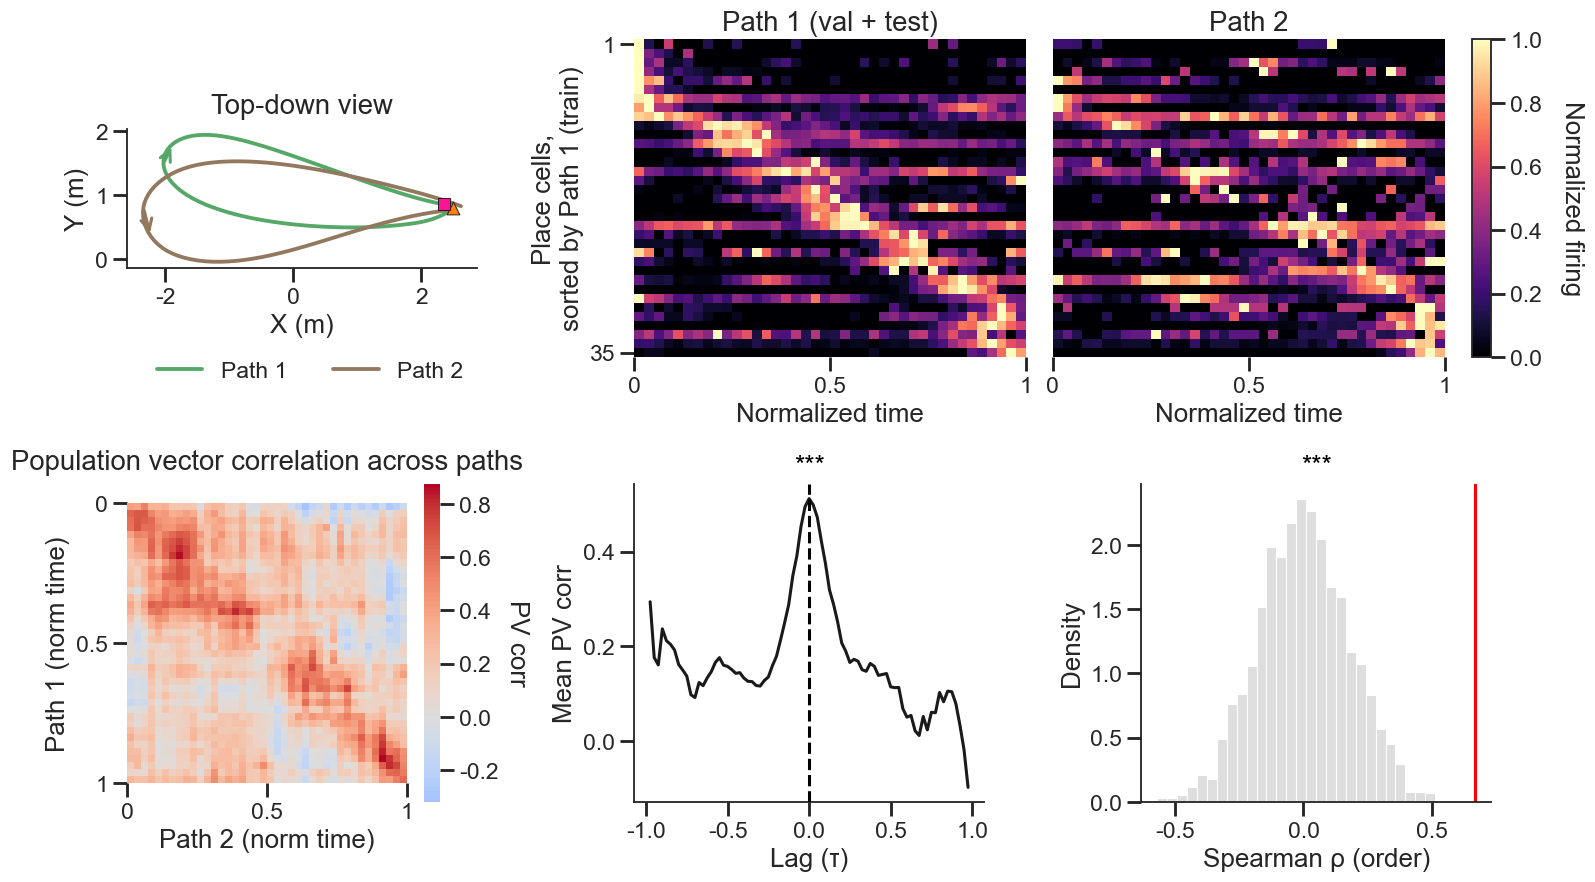

Figure 3 — Dataset_1_32622_231010 (bat 32622): Path 1 = cl 10 vs Path 2 = cl 11 [reward→reward], Fréchet 2.0 m, 35 place cells. Bottom row: observed statistic (red) vs shuffle null (grey).
Sequence-preservation tests (one-sided shuffle p):
               session               test   obs         p  n_place stars         P
Dataset_1_32622_231010   PV zero-lag corr 0.512 0.0004998       35   *** P < 0.001
Dataset_1_32622_231010 Spearman ρ (order) 0.669 0.0004998       35   *** P < 0.001


,session,test,obs,p,n_place,stars,P
0,Dataset_1_32622_231010,PV zero-lag corr,0.512,0.0005,35,***,P < 0.001
1,Dataset_1_32622_231010,Spearman ρ (order),0.669,0.0005,35,***,P < 0.001


In [34]:
# Figure 3: example index 0
res0 = _route_example(0)
p3 = plot_route_example(res0, 'fig3_route_example0')
print(f'Figure 3 — {res0["session"]} (bat {res0["bat"]}): Path 1 = cl {res0["REF"]} vs '
      f'Path 2 = cl {res0["ALT"]} [{res0["route"]}], Fréchet {res0["frechet"]:.1f} m, '
      f'{res0["n_place"]} place cells. Bottom row: observed statistic (red) vs shuffle null (grey).')
print('Sequence-preservation tests (one-sided shuffle p):')
ph.p_table(p3)

**Figure 3 | Same route, different paths — the population sequence follows route progress.** Two flight clusters (ref = more flights, alt) share origin (green) and destination (red) but take geometrically different 3-D paths. **a**, Mean 3-D trajectories. **b**, Top-down projection. **c**, Place-cell firing-rate sequences in normalized flight time on the reference (held-out) and alternate paths, sorted by reference-path peak time; a preserved diagonal on the alternate path indicates route-progress coding. **d**, Population-vector correlation between reference and alternate paths across normalized time. **e**, Mean PV correlation vs lag, peaking near zero when the sequence is preserved. **f–h**, Three sequence-preservation tests against shuffle nulls (grey): Spearman rank correlation of firing-time order, zero-lag population-vector correlation (per-cell circular-roll null), and mean per-cell tuning-curve correlation (roll null). Place cells are identified by significant cross-validated route-progress spatial information on the reference path. Exact *P* values are printed above.

---
## Extended Data Figure 6 — same route, different paths (other examples)

The other four same-route different-path pairs, each arranged identically to
Figure 3 and labelled by bat.

/tmp/ipykernel_112044/1394012243.py:95: RuntimeWarning: invalid value encountered in divide
  return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))


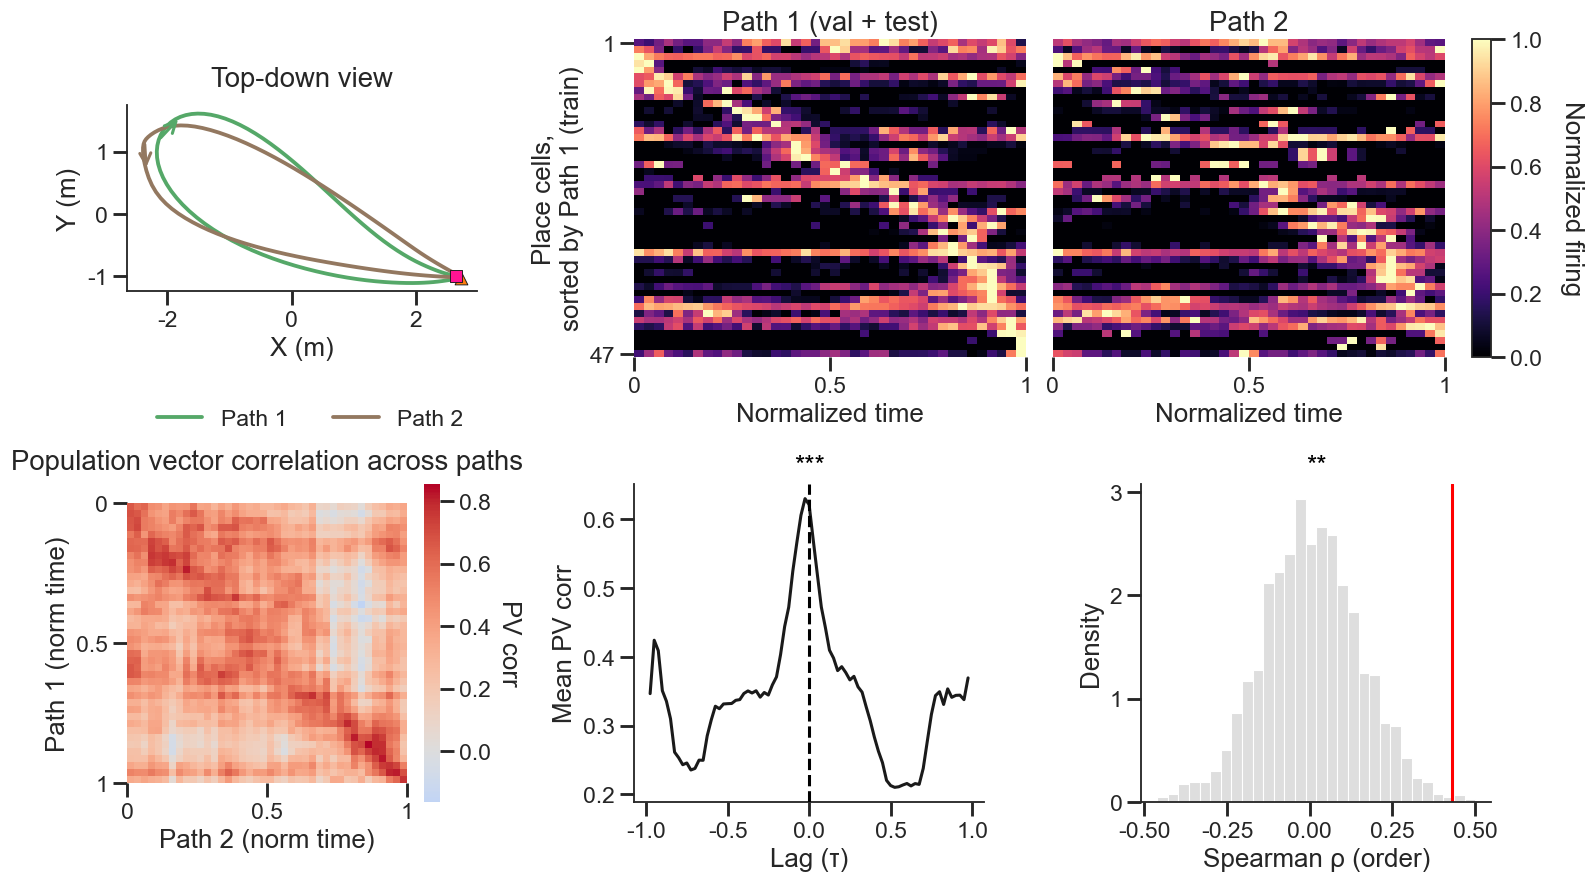

/tmp/ipykernel_112044/1394012243.py:95: RuntimeWarning: invalid value encountered in divide
  return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))


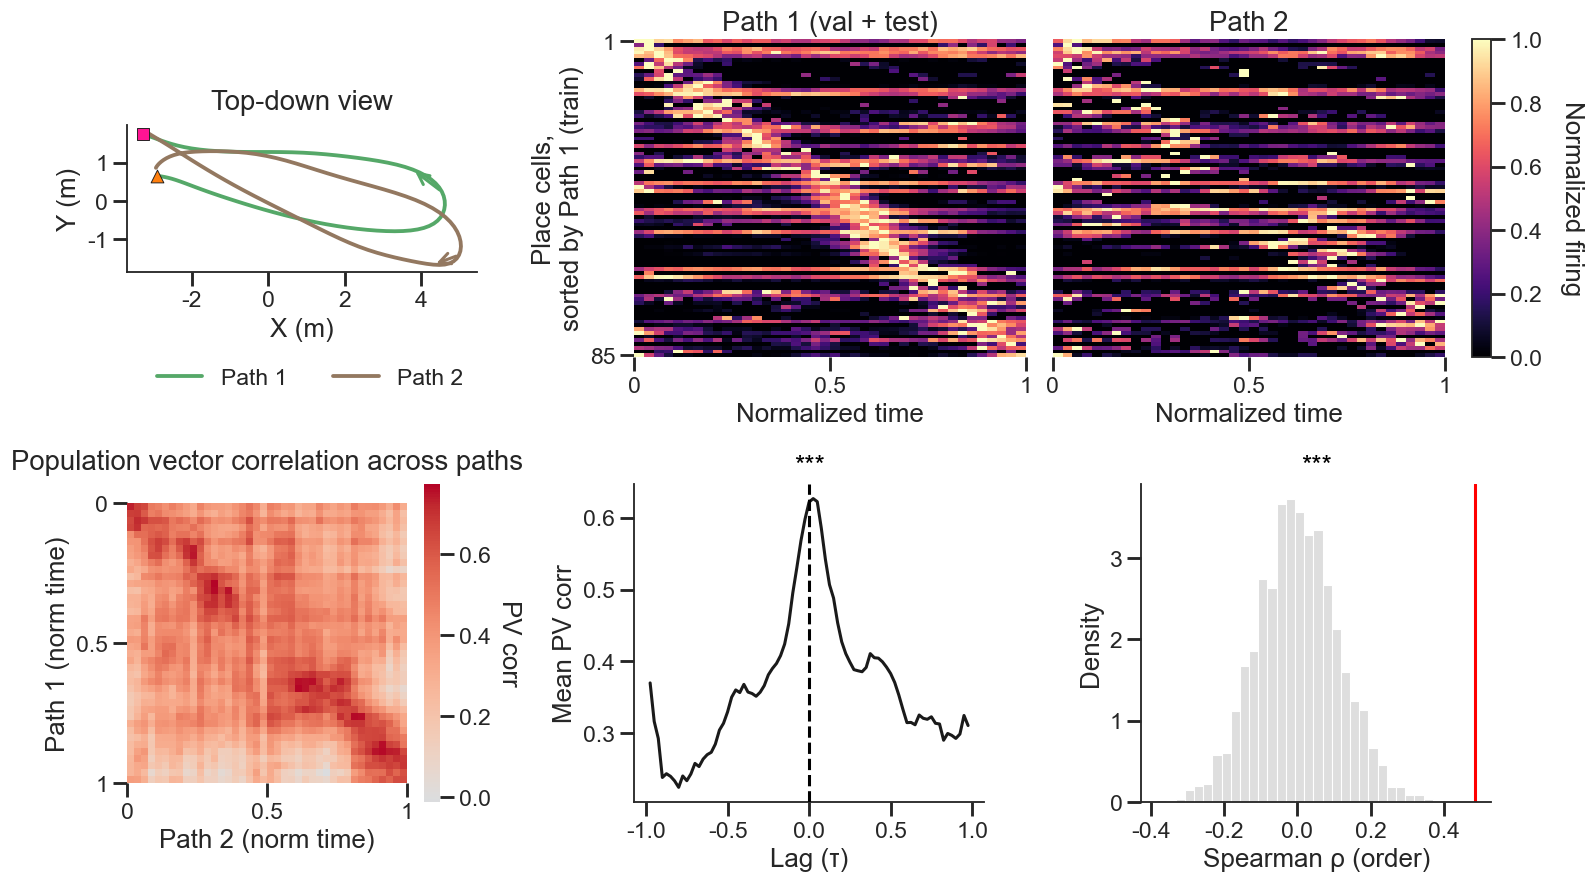

/tmp/ipykernel_112044/1394012243.py:95: RuntimeWarning: invalid value encountered in divide
  return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))


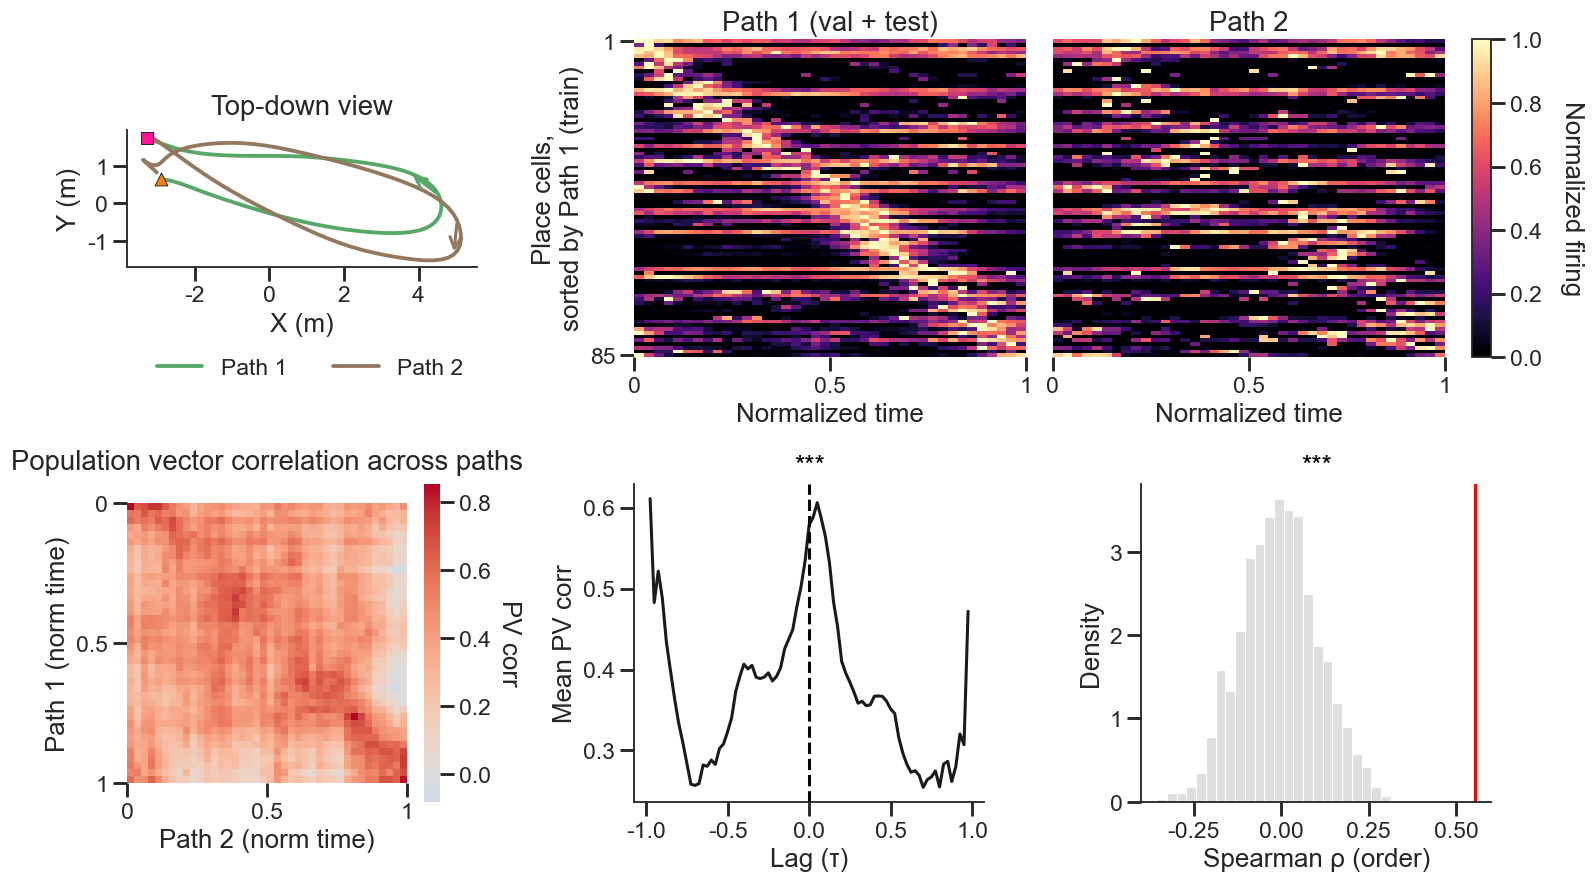

/tmp/ipykernel_112044/1394012243.py:95: RuntimeWarning: invalid value encountered in divide
  return float(np.nanmean(np.where(den > 0, (Az * Bz).sum(1) / den, np.nan)))


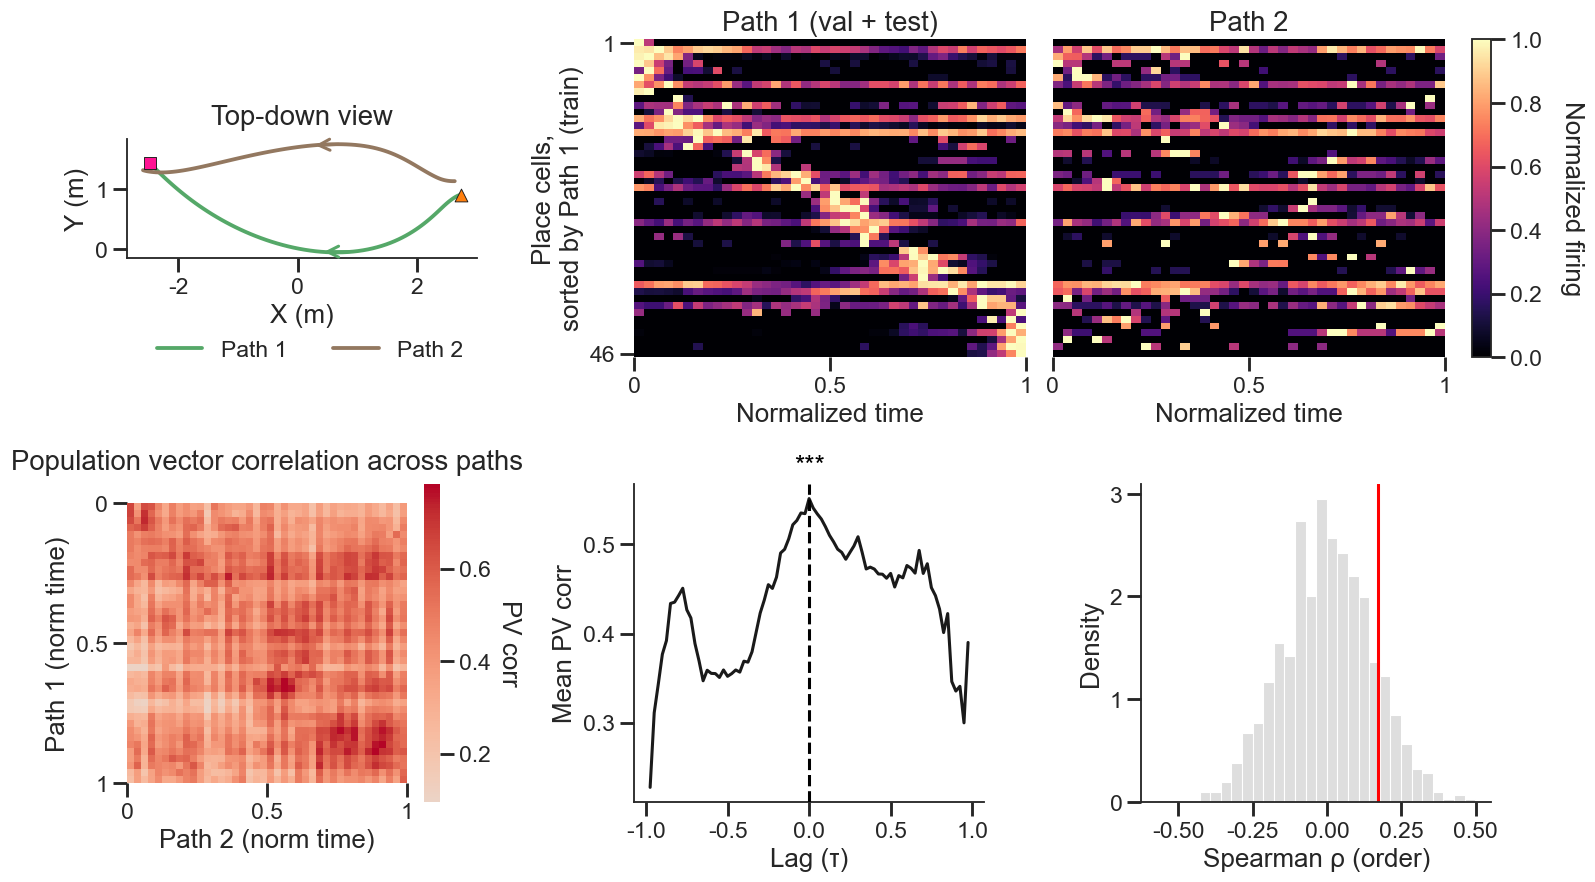

ED Fig 6 — sequence-preservation tests (one-sided shuffle p):
               session               test   obs         p  n_place stars         P
Dataset_1_32622_231009   PV zero-lag corr 0.621 0.0004998       47   *** P < 0.001
Dataset_1_32622_231009 Spearman ρ (order) 0.429  0.002499       47    ** P = 0.002
Dataset_2_14445_231209   PV zero-lag corr 0.622 0.0004998       85   *** P < 0.001
Dataset_2_14445_231209 Spearman ρ (order) 0.487 0.0004998       85   *** P < 0.001
Dataset_2_14445_231209   PV zero-lag corr 0.578 0.0004998       85   *** P < 0.001
Dataset_2_14445_231209 Spearman ρ (order) 0.555 0.0004998       85   *** P < 0.001
Dataset_3_00000_240405   PV zero-lag corr 0.551 0.0004998       46   *** P < 0.001
Dataset_3_00000_240405 Spearman ρ (order)  0.17    0.1484       46       P = 0.148


In [35]:
# ED Fig 6: the other four route examples (indices 1-4), identical layout, bat-labelled.
ed6_records = []
for _i in range(1, min(5, len(df_altpath))):
    _res = _route_example(_i)
    ed6_records.extend(plot_route_example(_res, f'edfig6_route_example{_i}'))
if ed6_records:
    print('ED Fig 6 — sequence-preservation tests (one-sided shuffle p):')
    ph.p_table(ed6_records)


**Extended Data Figure 6 | Same route, different paths — additional examples.** Panels as in Figure 3, for the remaining four same-route different-path cluster pairs (one composite per pair, titled with session and bat id). Each shows the two 3-D paths, top-down projection, reference/alternate sequence heatmaps, population-vector correlation and lag, and the three sequence-preservation tests with shuffle nulls.

---
## Figure 4 — Readout weights surface correlations in spatial and non-spatial activity

**a** PC1 of the readout-weight correlation vs mean firing rate, per session. **b** Residual-readout hierarchical clustering as a vertical stack (dendrogram over the cosine-similarity matrix over the residual readout-weight matrix, 64-d latent vertical). **c** Example sleep-matched session: Non-flight FR, Sleep FR (near-identical), residual readout, rate-map and coupling similarity matrices. **d–f, h** Mantel / partial-Mantel line plots (one line per session, coloured by bat) of the residual readout against non-flight rest, controlling for rate map and coupling. **g** Residual readouts predict CA1 vs CA3 membership (per-session SVM swarm vs shuffle null). **i** Spatial information per cluster. **j–k** Attribution matrices (example; future−past by cluster).

> Panels **c–f, h, i** build the rate-map, non-flight-rest and coupling similarity streams directly (rate maps from flight spikes; non-flight from a per-session `Data_Prep` load; coupling from the GLM+history+coupling checkpoint). The **sleep** matrix (2nd panel of **c**) matches flight units to Dataset_0 sleep units via UnitMatch `MatchTable.csv` files (guarded — skipped if those / the Dataset_0 spike files are absent); panel **c** is restricted to those matched neurons so Non-flight FR and Sleep FR are directly comparable.

In [134]:
# === Figure 4 foundation: per-neuron readout weights + metadata + subregion ===
from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram

# Per-neuron table: unit-normed readout rows, pType, probe, position, mean FR.
_rows, _W = [], []
for sn in dataloaders['test']:
    W = bat_former.readouts[sn][0].weight.detach().cpu().numpy()   # (K, D)
    pos = np.asarray(meta_info_dict['neuron_position'][sn])
    ptype = np.asarray(meta_info_dict['pType'][sn])
    probe = np.asarray(meta_info_dict['probe_id'][sn])
    # mean FR from test spikes
    yl, ml = [], []
    for b in dataloaders['test'][sn]:
        yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
    ya, ma = np.vstack(yl), np.vstack(ml)
    mfr = ya[ma == 1.0].mean(0) / bin_width
    for u in range(W.shape[0]):
        pt = ptype[u] if not isinstance(ptype[u], np.ndarray) else 'filtered'
        _rows.append(dict(session=sn, bat=parse_bat(sn), unit=u, pType=str(pt),
                          probe_id=int(probe[u]), lateral=float(pos[u, 0]),
                          depth=float(pos[u, 1]), mean_fr=float(mfr[u])))
    _W.append(W)
readout_df = pd.DataFrame(_rows)
W_all = np.vstack(_W)
readout_df['readout_weight'] = list(W_all / np.linalg.norm(W_all, axis=1, keepdims=True))

# Attach joint per-neuron corr/FDE (computed for Fig 1d/e).
_jm = encode_metrics_df[encode_metrics_df['model'] == 'joint'][['session', 'unit', 'corr', 'fde']]
readout_df = readout_df.merge(_jm.rename(columns={'corr': 'corr_all', 'fde': 'fde_all'}),
                              on=['session', 'unit'], how='left')


# --- Subregion (CA1/CA3) from per-(bat,probe) depth clumps (internals recipe) ---
CLUMP_HW, PEAK_DIST, HBIN, SM_SIGMA, PROM = 300, 450, 25, 200, 0.04


def detect_clumps(depths):
    if len(depths) < 5:
        return np.array([])
    lo = np.floor(depths.min() / HBIN) * HBIN
    hi = np.ceil(depths.max() / HBIN) * HBIN + HBIN
    counts, edges = np.histogram(depths, bins=np.arange(lo, hi, HBIN))
    centers = 0.5 * (edges[:-1] + edges[1:])
    sm = gaussian_filter1d(counts.astype(float), sigma=SM_SIGMA / HBIN)
    if sm.max() == 0:
        return np.array([])
    padded = np.concatenate([[0.0], sm, [0.0]])
    pk, _ = find_peaks(padded, distance=max(1, PEAK_DIST // HBIN), prominence=PROM * sm.max())
    pk = pk - 1
    pk = pk[(pk >= 0) & (pk < len(sm))]
    if len(pk) == 0:
        pk = np.array([int(np.argmax(sm))])
    if len(pk) > 2:
        pk = pk[np.argsort(sm[pk])[::-1][:2]]
    return np.sort(centers[pk])


def _window(peak, lo, hi):
    a, b = peak - CLUMP_HW, peak + CLUMP_HW
    if b > hi:
        b, a = hi, hi - 2 * CLUMP_HW
    elif a < lo:
        a, b = lo, lo + 2 * CLUMP_HW
    return a, b


readout_df['subregion'] = None
for (bat, probe), grp in readout_df.groupby(['bat', 'probe_id']):
    d = grp['depth'].values
    peaks = detect_clumps(d)
    if len(d) == 0 or len(peaks) == 0:
        continue
    dlo, dhi = float(np.nanmin(d)), float(np.nanmax(d))
    labels = np.array([None] * len(d), dtype=object)
    if len(peaks) == 1:
        a, b = _window(peaks[0], dlo, dhi)
        labels[(d >= a) & (d <= b)] = 'CA1'
    else:
        ventral, dorsal = peaks[0], peaks[-1]
        la, lb = _window(dorsal, dlo, dhi)
        va, vb = _window(ventral, dlo, dhi)
        if vb > la:
            vb, va = la, la - 2 * CLUMP_HW
        labels[(d >= la) & (d <= lb)] = 'CA1'
        labels[(d >= va) & (d <= vb)] = 'CA3'
    readout_df.loc[grp.index, 'subregion'] = labels


def residual_readout(W, fr):
    """Orthogonalize unit-normed readout rows W against the population mean-FR axis (rank-1 deflation), renormalise."""
    ax = W.T @ (fr - fr.mean())
    n = np.linalg.norm(ax)
    Wr = W - np.outer(W @ (ax / n), ax / n) if n > 0 else W.copy()
    rn = np.linalg.norm(Wr, axis=1, keepdims=True); rn[rn == 0] = 1.0
    return Wr / rn


# Well-fit cells (fde_all > 0: encoding model beats the mean-rate baseline), residual readout per session.
clu_df = readout_df[readout_df['fde_all'] > 0.0].copy().reset_index(drop=True)
clu_df['readout_weight_residual'] = clu_df['readout_weight']
for _, grp in clu_df.groupby('session'):
    Wr = residual_readout(np.stack(grp['readout_weight'].values), grp['mean_fr'].values)
    for j, ix in zip(range(len(grp)), grp.index):
        clu_df.at[ix, 'readout_weight_residual'] = Wr[j]
print('readout_df:', len(readout_df), 'neurons |', readout_df['subregion'].notna().sum(),
      'with subregion | clu_df well-fit:', len(clu_df))

readout_df: 3080 neurons | 2938 with subregion | clu_df well-fit: 2147


In [135]:
# === Figure 4b clustering step (compute once; the plotting cell only draws) ===
# Hierarchical clustering of the firing-rate-residual read-out weights across well-fit
# neurons. Produces the leaf order, per-neuron cluster labels, ordered similarity /
# weight matrices, and the dendrogram link-colour map consumed by the Fig 4 plotting
# cell (and by ED Fig 7, which reuses CLUSTER_ORDER / CLUSTER_PALETTE / clu_df['cluster']).
from scipy.cluster.hierarchy import fcluster
from scipy.spatial.distance import pdist
import matplotlib.colors as mcolors

Wr = np.stack(clu_df['readout_weight_residual'].values)       # (N, D), unit-normed
dist = pdist(Wr, metric='cosine')
Z = linkage(dist, method='average')
# Cut the tree fine, then keep only well-populated clusters (matches internals.ipynb:
# the residual read-outs over-split into many singletons, so a low fixed N_CLUSTERS
# lumps distinct groups together). CLUSTER_ORDER is the `included` subset (clusters with
# >= MIN_NEURONS members); every other cluster is greyed out in the dendrogram/strip and
# dropped from the per-cluster panels (here + ED Fig 7, which reuse CLUSTER_ORDER).
N_CLUSTERS = 12
MIN_NEURONS = 200
clu_df['cluster'] = fcluster(Z, t=N_CLUSTERS, criterion='maxclust')
_clu_sizes = clu_df['cluster'].value_counts()
CLUSTER_ORDER = sorted(_clu_sizes[_clu_sizes >= MIN_NEURONS].index.astype(int).tolist())
CLUSTER_PALETTE = ph.cluster_palette(CLUSTER_ORDER)
CLUSTER_GREY = (0.7, 0.7, 0.7)
order = dendrogram(Z, no_plot=True)['leaves']
sim_ord = (Wr @ Wr.T)[np.ix_(order, order)]
Wr_ord = Wr[order]
clus_ord = clu_df['cluster'].values[order]
N, D = Wr_ord.shape                                            # neurons, latent dims (64)
XSPAN = 10 * N                                                 # scipy leaf spacing (5,15,...)
# Colour each dendrogram link by its cluster, but only for `included` clusters (grey
# otherwise), so the tree matches the strip + boxplots. A merge keeps a cluster colour
# only when both of its children carry that same cluster label.
_labels_clu = clu_df['cluster'].values
_n_leaf = Z.shape[0] + 1
_node_clu = {i: int(_labels_clu[i]) for i in range(_n_leaf)}
for _i in range(Z.shape[0]):
    _ca, _cb = _node_clu.get(int(Z[_i, 0])), _node_clu.get(int(Z[_i, 1]))
    _node_clu[_n_leaf + _i] = _ca if (_ca is not None and _ca == _cb) else None


def _dendro_link_color(k):
    """Cluster colour for dendrogram link `k`; grey for excluded/mixed clusters."""
    c = _node_clu.get(k)
    return mcolors.to_hex(CLUSTER_PALETTE[c]) if c in CLUSTER_PALETTE else '0.6'


print('cluster sizes:', clu_df['cluster'].value_counts().sort_index().to_dict())
print(f'included clusters (>= {MIN_NEURONS} neurons): {CLUSTER_ORDER}')


cluster sizes: {1: 464, 2: 40, 3: 29, 4: 308, 5: 151, 6: 134, 7: 315, 8: 46, 9: 14, 10: 410, 11: 217, 12: 19}
included clusters (>= 200 neurons): [1, 4, 7, 10, 11]


In [136]:
# === Fig 4d/e data: neural->position attribution (input-gradient Jacobian) ===
# Ported from internals.ipynb (prosp_attribution / attr_example_matrix). The encoder is a
# NON-causal transformer, so rate at time i can draw on position at past AND future j. For
# each test flight we take the input-gradient attribution A[i, n, j] = ||d rate(i,n)/d pos(j)||
# (norm over x,y,z), and summarise each neuron by the scale-free future-past contrast
# (UP - LO)/(UP + LO) of the upper (future, j>i) vs lower (past) triangle, excluding
# |i-j| <= EXCL bins around the diagonal. UP/LO sums are POOLED across all test flights.
# >0 = prospective.
#
# CACHED under ./out/fig4_cache/ in TWO parts: the expensive per-neuron future-past sweep
# (fig4_attr_lookup) and the cheap single-flight example matrix (fig4_attr_example). Splitting
# them means changing the example selection does NOT invalidate the costly sweep. Keys capture
# the joint checkpoint (path + size + mtime), the test session set, T_MAX / EXCL, bin width,
# and (for the lookup) the well-fit neuron list. Set FIG4_FORCE = True to force recompute.
import os, pickle, hashlib
import torch
T_MAX, EXCL = 200, 2
attr_excl_s = float(EXCL * bin_width)   # exclusion half-band (s) either side of the diagonal (= 200 ms)

FIG4_CACHE_DIR = './out/fig4_cache'
os.makedirs(FIG4_CACHE_DIR, exist_ok=True)
FIG4_FORCE = globals().get('FIG4_FORCE', False)


def _ckpt_sig(path):
    if path and os.path.exists(path):
        st = os.stat(path)
        return (os.path.basename(path), int(st.st_size), int(st.st_mtime))
    return (path, None, None)


def _fig4_cache(name, key, compute):
    """Load ./out/fig4_cache/<name>.pkl iff its stored key matches `key`; else compute + save."""
    path = os.path.join(FIG4_CACHE_DIR, name + '.pkl')
    if os.path.exists(path) and not FIG4_FORCE:
        blob = pickle.load(open(path, 'rb'))
        if blob.get('key') == key:
            print(f'  [cache hit] {name}')
            return blob['value']
        print(f'  [cache stale] {name} - recomputing')
    value = compute()
    with open(path, 'wb') as fh:
        pickle.dump(dict(key=key, value=value), fh)
    print(f'  [cache saved] {name}')
    return value


def _cuda_clear():
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def _flight_attr_sums(sn, x0, m0, vi):
    """Per-neuron pooled future(UP)/past(LO) position-attribution sums for one flight."""
    rows_t = torch.as_tensor(vi, device=x0.device)

    def _f(x):
        return bat_former(sn, x.unsqueeze(0), m0)[0].index_select(0, rows_t)   # (Tv, n)

    J = torch.autograd.functional.jacobian(_f, x0, vectorize=True)             # (Tv, n, T, beh)
    A = J[..., :3].norm(dim=-1)[:, :, vi].detach().cpu().numpy()               # (Tv, n, Tv)
    del J, rows_t
    _cuda_clear()
    Tv = len(vi)
    jj = np.arange(Tv)[None, :] - np.arange(Tv)[:, None]      # j - i
    up, lo = jj > EXCL, jj < -EXCL                            # future / past position
    return (A * up[:, None, :]).sum((0, 2)), (A * lo[:, None, :]).sum((0, 2))


def _flight_attr_matrix(sn, x0, m0, vi):
    rows_t = torch.as_tensor(vi, device=x0.device)

    def _f(x):
        return bat_former(sn, x.unsqueeze(0), m0)[0].index_select(0, rows_t)

    J = torch.autograd.functional.jacobian(_f, x0, vectorize=True)
    A = J[..., :3].norm(dim=-1)[:, :, vi].detach().cpu().numpy()
    del J, rows_t
    _cuda_clear()
    return A


# --- Part 1: per-neuron future-past index over every test flight (expensive; cached) ---
_lookup_key = dict(
    kind='fig4_attr_lookup_v1', joint=_ckpt_sig(JOINT_CKPT),
    sessions=sorted(dataloaders['test'].keys()),
    t_max=int(T_MAX), excl=int(EXCL), bin_width=float(bin_width),
    units=tuple((str(s), int(u)) for s, u in zip(clu_df['session'], clu_df['unit'])),
)


def _compute_lookup():
    bat_former.eval()
    attr_lookup = {}
    for sn in dataloaders['test']:
        up_tot = lo_tot = None
        n_done = 0
        for batch in dataloaders['test'][sn]:
            Xb, Mb = batch.behavior.to(device), batch.mask.to(device)
            for b in range(Xb.shape[0]):
                vi = np.where(batch.mask[b].numpy() == 1.0)[0]
                if len(vi) < 2 * EXCL + 3:
                    continue
                vi = vi[:T_MAX]
                try:
                    us, ls = _flight_attr_sums(sn, Xb[b].detach(), Mb[b:b + 1], vi)
                except RuntimeError as e:
                    print(f'    {sn} flight {n_done}: skipped ({str(e)[:40]})')
                    _cuda_clear()
                    continue
                up_tot = us if up_tot is None else up_tot + us
                lo_tot = ls if lo_tot is None else lo_tot + ls
                n_done += 1
            del Xb, Mb
            _cuda_clear()
        if up_tot is not None:
            with np.errstate(divide='ignore', invalid='ignore'):
                attr_lookup[sn] = np.where(up_tot + lo_tot > 0,
                                           (up_tot - lo_tot) / (up_tot + lo_tot), np.nan)
        print(f'  {sn}: attribution over {n_done} flights')
    return attr_lookup


attr_lookup = _fig4_cache('fig4_attr_lookup', _lookup_key, _compute_lookup)
clu_df['future_idx'] = [attr_lookup[s][int(u)] if (s in attr_lookup and int(u) < len(attr_lookup[s]))
                        else np.nan for s, u in zip(clu_df['session'], clu_df['unit'])]

# --- Part 2: example matrix — illustrative neuron FIXED BY HAND, longest valid test flight
#     in that session (cheap; cached per selected neuron). Chosen: Dataset_3_00000_240404
#     neuron 5 (cluster 5, future_idx ~ +0.11) as a clear prospective example. ---
attr_ex_sn, attr_ex_unit = 'Dataset_3_00000_240404', 5
_exq = clu_df[(clu_df['session'] == attr_ex_sn) & (clu_df['unit'] == attr_ex_unit)]
_ex = _exq.iloc[0] if len(_exq) else dict(future_idx=np.nan)
_ex_key = dict(kind='fig4_attr_example_v1', joint=_ckpt_sig(JOINT_CKPT),
               sn=attr_ex_sn, unit=attr_ex_unit, t_max=int(T_MAX), bin_width=float(bin_width))


def _compute_example():
    bat_former.eval()
    _best = None
    for batch in dataloaders['test'][attr_ex_sn]:
        for b in range(batch.behavior.shape[0]):
            vi = np.where(batch.mask[b].numpy() == 1.0)[0]
            if _best is None or len(vi) > _best[0]:
                _best = (len(vi), batch.behavior[b].detach().to(device),
                         batch.mask[b:b + 1].to(device), vi[:T_MAX])
    A = _flight_attr_matrix(attr_ex_sn, _best[1], _best[2], _best[3])
    return A[:, attr_ex_unit, :]


attr_ex_matrix = np.asarray(_fig4_cache('fig4_attr_example', _ex_key, _compute_example))
attr_ex_ext = float(attr_ex_matrix.shape[0] * bin_width)   # seconds (scalar for imshow extent)
print(f'attribution example: {attr_ex_sn} neuron {attr_ex_unit} '
      f'(future_idx={float(_ex["future_idx"]):+.3f}, fixed example); '
      f'{int(clu_df["future_idx"].notna().sum())} neurons with attribution')

  [cache hit] fig4_attr_lookup
  [cache hit] fig4_attr_example
attribution example: Dataset_3_00000_240404 neuron 5 (future_idx=+0.130, fixed example); 2147 neurons with attribution


In [ ]:
# === Fig 4 data streams (panels c, g–l): rate maps, non-flight rest corr, coupling ===
# Ported from internals.ipynb (rate maps, non-flight Data_Prep load, coupling GLM).
from digitalbat.datasets.data import Data_Prep_for_Raw
from notebook_helpers import loc_bin_width_rm

# (1) Per-neuron 2D rate maps (observed spikes / occupancy) per session.
session_rate_maps, session_occ = {}, {}
for sn, sd in dataloaders['test'].items():
    Xl, yl, ml = [], [], []
    for b in sd:
        Xl.append(b.behavior.numpy()); yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
    Xa, ya, ma = np.vstack(Xl), np.vstack(yl), np.vstack(ml)
    bm, bs = meta_info_dict['behavior_mean'][sn], meta_info_dict['behavior_std'][sn]
    xlim, ylim = meta_info_dict['r_lim'][sn][0], meta_info_dict['r_lim'][sn][1]
    xe = np.arange(xlim[0], xlim[1] + loc_bin_width_rm, loc_bin_width_rm)
    ye = np.arange(ylim[0], ylim[1] + loc_bin_width_rm, loc_bin_width_rm)
    v = ma == 1.0
    lx = Xa[:, :, 0][v] * bs[0, 0, 0] + bm[0, 0, 0]
    ly = Xa[:, :, 1][v] * bs[0, 0, 1] + bm[0, 0, 1]
    spk = ya[v]
    occ, _, _ = np.histogram2d(lx, ly, bins=[xe, ye])
    under = occ < 3
    maps = np.full((spk.shape[1], (len(xe) - 1) * (len(ye) - 1)), np.nan)
    for u in range(spk.shape[1]):
        sm, _, _ = np.histogram2d(lx, ly, bins=[xe, ye], weights=spk[:, u])
        with np.errstate(divide='ignore', invalid='ignore'):
            rm = sm / (occ * bin_width)
        rm[under] = np.nan
        maps[u] = rm.ravel()
    session_rate_maps[sn] = maps
    session_occ[sn] = occ.ravel()

# (2) Non-flight rest correlation matrices (sqrt counts) per session.
nonflight_corr = {}
for sn in session_names:
    folder = data_config['parent_folder'] + sn
    su = data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat'
    kw = dict(parent_folder=folder, su_file_path=su, use_speed_head_dir=False,
              use_IMU_flag=False, use_click_flag=False, use_LFP_flag=False,
              use_ripple_flag=False, spike_count_flag=True, bin_width=bin_width)
    try:
        dpf = Data_Prep_for_Raw(only_flight_flag=True, **kw)
        dpf.get_all_behavior(); dpf.get_all_spike()
        dpa = Data_Prep_for_Raw(only_flight_flag=False, **kw)
        dpa.get_all_behavior(); allspk = dpa.get_all_spike()
        nf = np.setdiff1d(np.arange(allspk.shape[1]), dpf.flight_ind)
        nonflight_corr[sn] = np.corrcoef(np.sqrt(allspk[:, nf]))
    except Exception as exc:
        print(f'  [nonflight skip {sn}] {type(exc).__name__}: {exc}')

# (3) Pairwise coupling similarity from the GLM+hist+coupling checkpoint.
session_coupling_sim = {}
COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna_acc50_full_v2.pth'
if os.path.exists(COUP_CKPT):
    cs = torch.load(COUP_CKPT, map_location='cpu', weights_only=False)
    kint = cs['coup_basis'].numpy().sum(0) * bin_width
    for k, v in cs.items():
        if k.startswith('coup_weights.'):
            K = v.numpy() @ kint
            np.fill_diagonal(K, 0.0)
            Csym = 0.5 * (K + K.T); np.fill_diagonal(Csym, 0.0)
            session_coupling_sim[k.split('coup_weights.', 1)[1]] = Csym
print(f'streams: {len(session_rate_maps)} rate-map, {len(nonflight_corr)} non-flight, '
      f'{len(session_coupling_sim)} coupling sessions')


def ratemap_corr_matrix(maps):
    """Pairwise Pearson r between neurons' rate maps over jointly-valid bins."""
    n = maps.shape[0]
    C = np.full((n, n), np.nan)
    for i in range(n):
        for j in range(i, n):
            m = np.isfinite(maps[i]) & np.isfinite(maps[j])
            if m.sum() >= 5 and maps[i, m].std() > 0 and maps[j, m].std() > 0:
                C[i, j] = C[j, i] = np.corrcoef(maps[i, m], maps[j, m])[0, 1]
    return C


session_sleep_corr = {}   # populated by the sleep-matching cell below


def session_matrices(sn):
    """Well-fit-neuron submatrices (nonflight, residual readout, rate map, coupling)
    for one session, all ordered by the session's clu_df units. Missing streams -> None."""
    grp = clu_df[clu_df['session'] == sn]
    units = grp['unit'].to_numpy()
    if len(units) < 6 or sn not in nonflight_corr:
        return None
    Wr = np.stack(grp['readout_weight_residual'].values)
    out = dict(units=units, grp=grp,
               nonflight=nonflight_corr[sn][np.ix_(units, units)],
               residual=Wr @ Wr.T,
               ratemap=ratemap_corr_matrix(session_rate_maps[sn][units]),
               coupling=(session_coupling_sim[sn][np.ix_(units, units)]
                         if sn in session_coupling_sim else None),
               sleep=session_sleep_corr.get(sn))
    return out


In [ ]:
# === Fig 4g sleep matrix: match flight units to Dataset_0 sleep units (UnitMatch) ===
# Ported from internals.ipynb. For each flight session with a sleep pair, map its
# Kilosort cluster ids to the sleep-session (Dataset_0) cluster ids via UnitMatch
# MatchTables, bin the sleep spikes, and build a per-session sleep FR-correlation
# matrix over the well-fit (clu_df) neurons (NaN where unmatched / silent). Guarded:
# sessions without MatchTable / Dataset_0 SU files are skipped.
from pathlib import Path
from scipy.io import loadmat

UM_ROOT = Path('/mnt/s5adam/Angelo/NP_datasets/UnitMatch')
SLEEP_PAIRS = {
    'Dataset_3_00000_240403': 'Dataset_0_00000_240403',
    'Dataset_3_00000_240404': 'Dataset_0_00000_240404',
    'Dataset_3_14543_240420': 'Dataset_0_14543_240420',
    'Dataset_3_29959_240403': 'Dataset_0_29959_240403',
    'Dataset_3_29959_240404': 'Dataset_0_29959_240404',
}


def _load_match_table(animal, date, probe):
    p = UM_ROOT / 'matches' / f'{animal}_{date}' / f'probe{probe}' / 'MatchTable.csv'
    return pd.read_csv(p) if p.is_file() else None


def _build_flight_to_sleep_map(animal, date):
    mapping = {}
    for probe in (1, 2, 3):
        df = _load_match_table(animal, date, probe)
        if df is None:
            continue
        cross = df[(df['RecSes 1'] != df['RecSes 2']) & (df['Matches'] == 1) & (df['RecSes 1'] == 1)]
        best = cross.sort_values('UM Probabilities', ascending=False).drop_duplicates('ID2', keep='first')
        for _, r in best.iterrows():
            mapping[(probe, int(r['ID2']))] = int(r['ID1'])
    return mapping


def _flight_cluster_ids(sn):
    dp = Data_Prep_for_Raw(
        parent_folder=data_config['parent_folder'] + '/' + sn,
        su_file_path=data_config['parent_folder'] + '/To_transfer/out_Gunits_probe*_' + sn + '_with_metrics.mat',
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False,
        use_LFP_flag=False, use_ripple_flag=False, spike_count_flag=True,
        bin_width=bin_width, only_flight_flag=True)
    dp.get_all_behavior(); dp.get_all_spike()
    return dp.cluster_id, dp.probe_id + 1   # data.py 0-indexed; UnitMatch uses probe 1..3


def _bin_ds0_spikes(ds0_session, sleep_clu_per_probe):
    binned = {}
    for probe in (1, 2, 3):
        wanted = sleep_clu_per_probe.get(probe)
        if not wanted:
            continue
        path = f"{data_config['parent_folder']}/To_transfer/out_Gunits_probe{probe}_{ds0_session}.mat"
        if not Path(path).is_file():
            continue
        ou = loadmat(path)['out_Gunits']
        all_cids = np.array([int(x[0][0, 0]) for x in ou['cluster_id']])
        all_times_s = [x[0][:, 0] / 1e6 for x in ou['spikeTimes_usec']]
        t_end = max((t.max() for t in all_times_s if len(t)), default=0.0) + bin_width
        edges = np.arange(0, t_end + bin_width, bin_width)
        out = np.zeros((len(wanted), len(edges) - 1), dtype=np.int32)
        for i, cid in enumerate(wanted):
            idx = np.where(all_cids == cid)[0]
            if len(idx):
                out[i] = np.histogram(all_times_s[idx[0]], bins=edges)[0]
        binned[probe] = out
    if not binned:
        return {}
    common = min(a.shape[1] for a in binned.values())
    return {p: a[:, :common] for p, a in binned.items()}


for sn, ds0 in SLEEP_PAIRS.items():
    grp = clu_df[clu_df['session'] == sn]
    if len(grp) < 3:
        continue
    animal, date = sn.split('_')[2], sn.split('_')[3]
    try:
        cid_full, pid_full = _flight_cluster_ids(sn)
        units = grp['unit'].to_numpy()
        if units.max() >= len(cid_full):
            continue
        fcid, fpid = cid_full[units], pid_full[units]
        fts = _build_flight_to_sleep_map(animal, date)
        if not fts:
            print(f'  [sleep skip {sn}] no MatchTable'); continue
        matched = [fts.get((int(fpid[i]), int(fcid[i]))) for i in range(len(units))]
        pos = [i for i, m in enumerate(matched) if m is not None]
        if len(pos) < 3:
            print(f'  [sleep {sn}] only {len(pos)} matched'); continue
        per_probe = {p: [] for p in (1, 2, 3)}
        for i in pos:
            per_probe[int(fpid[i])].append(int(matched[i]))
        binned = _bin_ds0_spikes(ds0, {p: l for p, l in per_probe.items() if l})
        if not binned:
            print(f'  [sleep skip {sn}] no Dataset_0 SU mats'); continue
        rows, cur = [], {p: 0 for p in (1, 2, 3)}
        for i in pos:
            p = int(fpid[i]); rows.append(binned[p][cur[p]]); cur[p] += 1
        sleep_mat = np.vstack(rows)
        C = np.full((len(units), len(units)), np.nan)
        var = sleep_mat.var(1); nz = var > 0
        idx_pos = np.array(pos)[nz]
        if len(idx_pos) >= 2:
            C[np.ix_(idx_pos, idx_pos)] = np.corrcoef(np.sqrt(sleep_mat[nz]))
        session_sleep_corr[sn] = C
        print(f'  sleep {sn}: {len(pos)} matched, {sleep_mat.shape[1] * bin_width / 60:.1f} min')
    except Exception as exc:
        print(f'  [sleep skip {sn}] {type(exc).__name__}: {exc}')
print(f'sleep matrices for {len(session_sleep_corr)} sessions')


  sleep Dataset_3_00000_240403: 57 matched, 71.3 min
  sleep Dataset_3_00000_240404: 37 matched, 71.4 min
  sleep Dataset_3_14543_240420: 43 matched, 85.2 min
  sleep Dataset_3_29959_240403: 68 matched, 71.3 min
  [sleep Dataset_3_29959_240404] only 1 matched
sleep matrices for 4 sessions


In [ ]:
# === Figure 4f statistics: CA1/CA3 SVM (permutation) + shared cache helpers ===
# CA1 vs CA3 balanced-accuracy SVM (500-shuffle null) for panel f, plus the cache helpers and
# content hashes reused by the MRM cell (fig4_mrm_r2). The Mantel / partial-Mantel analysis has
# been REPLACED by MRM (multiple regression on distance matrices); see the fig4_mrm_r2 cell.
#
# CACHED under ./out/fig4_cache/fig4_svm.pkl. The key captures the joint checkpoint (path+size+
# mtime), the sessions, and a content hash of the residual readouts / subregion labels; retrain
# or change population -> recompute, otherwise load instantly. Set FIG4_FORCE = True to force.
import os, pickle, hashlib
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV,
                                     cross_val_predict, cross_val_score)
from sklearn.metrics import balanced_accuracy_score

FIG4_CACHE_DIR = './out/fig4_cache'
os.makedirs(FIG4_CACHE_DIR, exist_ok=True)
FIG4_FORCE = globals().get('FIG4_FORCE', False)


def _ckpt_sig(path):
    """(basename, size, mtime) of a checkpoint file (None if missing) — cheap identity."""
    if path and os.path.exists(path):
        st = os.stat(path)
        return (os.path.basename(path), int(st.st_size), int(st.st_mtime))
    return (path, None, None)


def _arr_hash(a):
    return hashlib.md5(np.ascontiguousarray(np.asarray(a, dtype=float)).tobytes()).hexdigest()


def _fig4_cache(name, key, compute):
    """Load ./out/fig4_cache/<name>.pkl iff its stored key matches `key`; else compute and
    save. Nothing is recomputed unless the key (model ckpt / params / population) changes."""
    path = os.path.join(FIG4_CACHE_DIR, name + '.pkl')
    if os.path.exists(path) and not FIG4_FORCE:
        blob = pickle.load(open(path, 'rb'))
        if blob.get('key') == key:
            print(f'  [cache hit] {name}')
            return blob['value']
        print(f'  [cache stale] {name} - recomputing')
    value = compute()
    with open(path, 'wb') as fh:
        pickle.dump(dict(key=key, value=value), fh)
    print(f'  [cache saved] {name}')
    return value


SUB_MIN_NEURONS = 10  # min neurons per (session, subregion) for a stable per-subregion MRM
_COUP_CKPT = COUP_CKPT if 'COUP_CKPT' in dir() else None
_residuals_hash = _arr_hash(np.vstack(clu_df['readout_weight_residual'].values))
_subregion_sig = tuple(clu_df['subregion'].fillna('none').astype(str).tolist())


# --- Panel f: CA1 vs CA3 SVM ---
SVM_N_REPEATS = 20   # repeated stratified CV so per-session accuracy isn't hostage to one split
_svm_key = dict(
    kind='fig4_svm_v2',
    joint=_ckpt_sig(JOINT_CKPT),
    sessions=sorted(nonflight_corr.keys()),
    seed=int(seed), n_shuffle=500, n_repeats=int(SVM_N_REPEATS),
    svm=f'rbf|class_weight=balanced|GridSearchCV(C=logspace(-3,3,7))|'
        f'RepeatedStratifiedKFold(n_repeats={SVM_N_REPEATS})+cross_val_score|rs={int(seed)}',
    residuals=_residuals_hash, subregion=_subregion_sig,
)


def _compute_svm():
    # g: residual readouts predict CA1 vs CA3 membership. Per session, nested-CV RBF SVM
    # with class_weight='balanced', C tuned by inner GridSearchCV over logspace(-3, 3, 7).
    # The observed per-session balanced accuracy is the MEAN over a RepeatedStratifiedKFold
    # outer loop (SVM_N_REPEATS repeats) so it does not hinge on a single fold split. On top
    # we add a per-session 500-shuffle permutation null (fixed-C balanced RBF SVC on a single
    # split, for tractability; the exact C is immaterial under shuffled labels) for the band.
    _rng_g = np.random.default_rng(seed)
    g_rows, g_null = [], []
    for sn, grp in clu_df[clu_df['subregion'].isin(['CA1', 'CA3'])].groupby('session'):
        y = (grp['subregion'] == 'CA1').astype(int).values
        if len(np.unique(y)) < 2 or np.bincount(y).min() < 3:
            continue
        Xg = np.stack(grp['readout_weight_residual'].values)
        n_splits = int(min(5, np.bincount(y).min()))
        inner_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        outer_cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=SVM_N_REPEATS,
                                           random_state=seed)
        _pipe = Pipeline([('scaler', StandardScaler()),
                          ('svc', SVC(kernel='rbf', class_weight='balanced'))])
        _nested = GridSearchCV(_pipe, {'svc__C': np.logspace(-3, 3, 7)}, cv=inner_cv,
                               scoring='balanced_accuracy', n_jobs=-1)
        obs = float(cross_val_score(_nested, Xg, y, cv=outer_cv,
                                    scoring='balanced_accuracy').mean())
        g_rows.append(dict(session=sn, bat=parse_bat(sn), bal_acc=obs))
        _null_clf = Pipeline([('scaler', StandardScaler()),
                              ('svc', SVC(kernel='rbf', class_weight='balanced', C=1.0))])
        null_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for _ in range(500):
            yp = _rng_g.permutation(y)
            g_null.append(balanced_accuracy_score(yp, cross_val_predict(_null_clf, Xg, yp, cv=null_cv)))
    return dict(g_df=pd.DataFrame(g_rows), g_null=g_null)


_svm = _fig4_cache('fig4_svm', _svm_key, _compute_svm)
g_df = _svm['g_df']
g_null = _svm['g_null']

print(f'Fig 4 stats ready: {len(g_df)} SVM sessions')

  [cache hit] fig4_svm
Fig 4 stats ready: 16 SVM sessions


In [ ]:
# === Figure 4 h–l data: MRM (R^2 / unique R^2) — replaces the (partial) Mantel analysis ===
# Multiple regression on distance matrices (MRM). For every session the non-flight rest noise-
# correlation (upper triangle, rank-z) is regressed on the three flight predictors — residual-
# readout cosine, rate-map correlation, symmetric coupling — and we report, per predictor:
#   * marginal R^2  -- predictor entered ALONE (simple rank R^2 of that similarity matrix)
#   * unique  R^2   -- semipartial: full 3-predictor model minus the model with that predictor
#                      dropped, i.e. its contribution "holding the other two fixed"
# All vectors are rank-standardized (nh.zrank), so the MRM is the multiple-regression
# generalization of the Spearman Mantel. This is the COVARIATE-ONLY MRM (conditioning is on the
# three flight predictors; no probe/distance/FR nuisance regressors). CA1/CA3 rows repeat the
# joint MRM within each subregion (unique R^2 per predictor). Cached under ./out/fig4_cache/.
from notebook_helpers import zrank as _zrank, ols_r2 as _ols_r2

MRM_MIN_PAIRS = 30
_MRM_PREDS = ['residual readout', 'rate map', 'coupling']


def _mrm_session_r2(y_vec, pred_vecs, min_pairs=MRM_MIN_PAIRS):
    """Marginal + unique (semipartial) R^2 for each of the 3 flight predictors (intercept-only
    base; no nuisance). Rank-z everything on jointly-finite pairs; None if too few pairs."""
    stack = [y_vec] + [pred_vecs[k] for k in _MRM_PREDS]
    ok = np.all(np.isfinite(np.column_stack(stack)), axis=1)
    if ok.sum() < min_pairs:
        return None
    y = _zrank(y_vec[ok])
    P = {k: _zrank(pred_vecs[k][ok]) for k in _MRM_PREDS}
    base = [np.ones(int(ok.sum()))]
    r2_full = _ols_r2(y, np.column_stack(base + [P[k] for k in _MRM_PREDS]))
    rec = dict(total=r2_full, n_pairs=int(ok.sum()))
    for k in _MRM_PREDS:
        others = [P[m] for m in _MRM_PREDS if m != k]
        rec[f'unique_{k}'] = r2_full - _ols_r2(y, np.column_stack(base + others))
        rec[f'marginal_{k}'] = _ols_r2(y, np.column_stack(base + [P[k]]))
    return rec


_mrm_r2_key = dict(
    kind='fig4_mrm_r2_covonly_v1',
    joint=_ckpt_sig(JOINT_CKPT), coupling=_ckpt_sig(_COUP_CKPT),
    sessions=sorted(nonflight_corr.keys()),
    bin_width=float(bin_width), min_pairs=int(MRM_MIN_PAIRS), sub_floor=int(SUB_MIN_NEURONS),
    residuals=_residuals_hash, subregion=_subregion_sig,
)


def _compute_mrm_r2():
    main_rows, region_rows = [], []
    for sn in nonflight_corr:
        M = session_matrices(sn)
        if M is None or M['coupling'] is None or M['ratemap'] is None:
            continue
        n = M['nonflight'].shape[0]
        iu, ju = np.triu_indices(n, 1)
        rec = _mrm_session_r2(M['nonflight'][iu, ju],
                              {'residual readout': M['residual'][iu, ju],
                               'rate map': M['ratemap'][iu, ju],
                               'coupling': M['coupling'][iu, ju]})
        if rec is not None:
            for k in _MRM_PREDS:
                for metric in ('marginal', 'unique'):
                    main_rows.append(dict(session=sn, bat=parse_bat(sn), metric=metric,
                                          predictor=k, r2=rec[f'{metric}_{k}']))

        # --- CA1/CA3-restricted joint MRM (unique R^2 per predictor) ---
        grp = clu_df[clu_df['session'] == sn]
        for sr in ('CA1', 'CA3'):
            g = grp[grp['subregion'] == sr]
            if len(g) < SUB_MIN_NEURONS or sn not in session_coupling_sim:
                continue
            units = g['unit'].to_numpy()
            iu2, ju2 = np.triu_indices(len(units), 1)
            Wr = np.stack(g['readout_weight_residual'].values)
            rec = _mrm_session_r2(nonflight_corr[sn][np.ix_(units, units)][iu2, ju2],
                                  {'residual readout': (Wr @ Wr.T)[iu2, ju2],
                                   'rate map': ratemap_corr_matrix(session_rate_maps[sn][units])[iu2, ju2],
                                   'coupling': session_coupling_sim[sn][np.ix_(units, units)][iu2, ju2]})
            if rec is None:
                continue
            for k in _MRM_PREDS:
                region_rows.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                                        predictor=k, metric='unique', r2=rec[f'unique_{k}']))
    main = pd.DataFrame(main_rows)
    region = pd.DataFrame(region_rows)
    for df in (main, region):
        if len(df):
            df['predictor'] = pd.Categorical(df['predictor'], _MRM_PREDS, ordered=True)
    return dict(mrm_r2_main=main, mrm_r2_region=region)


_mrm_r2_blob = _fig4_cache('fig4_mrm_r2', _mrm_r2_key, _compute_mrm_r2)
mrm_r2_main = _mrm_r2_blob['mrm_r2_main']
mrm_r2_region = _mrm_r2_blob['mrm_r2_region']
print(f'MRM R^2 ready: {mrm_r2_main["session"].nunique()} sessions (main), '
      f'{mrm_r2_region["session"].nunique()} sessions with CA1/CA3 breakdown.')

  [cache hit] fig4_mrm_r2
MRM R^2 ready: 17 sessions (main), 17 sessions with CA1/CA3 breakdown.


In [ ]:
# === Figure 4 (a-k) on a single canvas ===
# Layout (two bands):
#   row 1 : [ a | f | g g g g g (cbar) ]   a=PC1/FR, f=CA1/CA3 SVC (half-width each); g=5 sim matrices
#   row 2 : [ b | c/d/e | MRM-vars (h,i) | MRM-subregions (j,k,l) ]   b=dendrogram/cosine(square)/weights stacked;
#           i/j/k = spatial info / attribution example / attribution index (moved next to b); then the
#           MRM panels: marginal + unique R^2 across predictors (one spot left empty), then CA1/CA3.
# Clustering (Z, order, sim_ord, Wr_ord, clus_ord, N, D, XSPAN, CLUSTER_ORDER, CLUSTER_PALETTE,
# CLUSTER_GREY, _dendro_link_color) comes from the fig4_cluster cell; the SVM stats (g_df, g_null)
# from fig4_stats; the MRM R^2 (mrm_r2_main, mrm_r2_region) from the fig4_mrm_r2 cell; the attribution
# (attr_ex_matrix, attr_ex_ext, attr_excl_s, clu_df['future_idx']) from the fig4_attribution cell.
from itertools import combinations
from sklearn.decomposition import PCA as _PCA
from scipy.spatial.distance import squareform
from scipy.stats import kruskal as _kw, mannwhitneyu as _mwu, wilcoxon as _wil

FS = dict(title=22, label=22, tick=19, star=22)
plt.rcParams['mathtext.fontset'] = 'dejavusans'   # Arial-like math font (matches body text)
PRED_ORDER = ['residual readout', 'rate map', 'coupling']


def _star_only(ax, p, x=0, yfrac=1.02):
    """Significance asterisk (no bracket) near the top of the data."""
    s = ph.stars_for_p(p)
    if s:
        lo, hi = ax.get_ylim()
        ax.text(x, lo + yfrac * (hi - lo), s, ha='center', va='bottom',
                fontsize=FS['star'], fontweight='bold')


def _pairwise_cluster_brackets(ax, df, val_col, order, *, base=1.05, step=0.075):
    """Holm-corrected pairwise Mann-Whitney across clusters. Significant pairs are drawn as
    ph.sig_bracket, packed onto as few horizontal levels as possible: a bracket reuses a level
    only if its x-span does not overlap any bracket already placed there (else it goes higher)."""
    pv = {}
    for a, b in combinations(range(len(order)), 2):
        xa = df.loc[df['cluster'] == order[a], val_col].dropna().values
        xb = df.loc[df['cluster'] == order[b], val_col].dropna().values
        pv[(a, b)] = (_mwu(xa, xb, alternative='two-sided').pvalue
                      if len(xa) >= 3 and len(xb) >= 3 else np.nan)
    real = sorted([(k, p) for k, p in pv.items() if np.isfinite(p)], key=lambda kv: kv[1])
    run, adj = 0.0, {}
    for i, (k, p) in enumerate(real):
        run = max(run, (len(real) - i) * p)
        adj[k] = min(run, 1.0)
    sig = sorted([k for k in adj if adj[k] < 0.05], key=lambda k: (k[1] - k[0], k))
    levels = []                                        # each entry = list of (a, b) spans on that line
    for (a, b) in sig:
        lvl = next((i for i, spans in enumerate(levels)
                    if all(b < s or a > e for (s, e) in spans)), None)
        if lvl is None:
            levels.append([(a, b)]); lvl = len(levels) - 1
        else:
            levels[lvl].append((a, b))
        ph.sig_bracket(ax, a, b, adj[(a, b)], base=base + lvl * step, star_gap=-0.020)   # tight star + compact stack
    return adj


def _cluster_dist(ax, df, val_col, ylabel, *, bracket_base=1.02):
    """Identical per-cluster box + individual-neuron dots + pairwise brackets style,
    shared by the spatial-info (i) and future-past (k) panels."""
    ph.cat_boxplot(ax, df, 'cluster', val_col, CLUSTER_ORDER, CLUSTER_PALETTE)
    sns.stripplot(data=df, x='cluster', y=val_col, order=CLUSTER_ORDER, color='k',
                  size=3, alpha=0.4, jitter=0.25, ax=ax)
    _pairwise_cluster_brackets(ax, df, val_col, CLUSTER_ORDER, base=bracket_base)
    ax.set_xlabel('cluster', fontsize=FS['label'])
    ax.set_ylabel(ylabel, fontsize=FS['label'])
    ax.tick_params(labelsize=FS['tick'])


fig4 = plt.figure(figsize=(28, 22))
outer = fig4.add_gridspec(2, 1, height_ratios=[1.0, 4.2], hspace=0.18)

# ---- row 1: a (half) | f (half) | g (5 matrices + dedicated cbar) ----
gs_top = outer[0].subgridspec(1, 3, width_ratios=[1, 1, 10], wspace=0.16)
ax_a = fig4.add_subplot(gs_top[0, 0])
ax_g = fig4.add_subplot(gs_top[0, 1])
gs_c = gs_top[0, 2].subgridspec(1, 6, width_ratios=[1, 1, 1, 1, 1, 0.13], wspace=0.18)
ax_c = [fig4.add_subplot(gs_c[0, i]) for i in range(5)]
cax_c = fig4.add_subplot(gs_c[0, 5])                          # dedicated cbar axes (keeps coupling full size)

# ---- row 2: b (square sim) | spacer | c/d/e | MRM-vars | MRM-subregions ----
gs_mid = outer[1].subgridspec(1, 5, width_ratios=[7.6, 0.1, 3.06, 2.1, 1.75], wspace=0.42)  # b | small gap | ijk | MRM cols
gs_b = gs_mid[0, 0].subgridspec(3, 1, height_ratios=[0.28, 1.6, 0.48], hspace=0.08)   # dendro + weights shortened further
axb_dendro = fig4.add_subplot(gs_b[0])
axb_sim = fig4.add_subplot(gs_b[1])
axb_w = fig4.add_subplot(gs_b[2])
gs_ijk = gs_mid[0, 2].subgridspec(3, 1, height_ratios=[1, 1.3, 1], hspace=1.0)  # spatial info / attribution / index
ax_i = fig4.add_subplot(gs_ijk[0])
ax_j = fig4.add_subplot(gs_ijk[1])
_pj0 = ax_j.get_position()                                  # enlarge attribution matrix ~20% in each dim
ax_j.set_position([_pj0.x0 - 0.1 * _pj0.width, _pj0.y0 - 0.1 * _pj0.height,
                   1.2 * _pj0.width, 1.2 * _pj0.height])
ax_k = fig4.add_subplot(gs_ijk[2])
gs_def = gs_mid[0, 3].subgridspec(3, 1, hspace=0.8)         # MRM vs variables: marginal (top), (empty), unique (bottom)
ax_mrm_marg = fig4.add_subplot(gs_def[0])
ax_mrm_empty = fig4.add_subplot(gs_def[1])
ax_mrm_uniq = fig4.add_subplot(gs_def[2])
for _axm in (ax_mrm_marg, ax_mrm_empty, ax_mrm_uniq):       # nudge the Marginal/Unique R^2 column slightly right
    _pm = _axm.get_position(); _axm.set_position([_pm.x0 + 0.010, _pm.y0, _pm.width, _pm.height])
gs_h = gs_mid[0, 4].subgridspec(3, 1, hspace=0.8)           # MRM subregions: CA1/CA3 unique R^2 per predictor
ax_h = [fig4.add_subplot(gs_h[i]) for i in range(3)]
for _axh in ax_h:                                          # nudge the CA1/CA3 subregion column slightly right
    _ph = _axh.get_position(); _axh.set_position([_ph.x0 + 0.010, _ph.y0, _ph.width, _ph.height])

# --- a: PC1 of readout weights correlates with mean firing rate (vs a random-direction null) ---
_rec = []
for sn, grp in clu_df.groupby('session'):
    W = np.stack(grp['readout_weight'].values)
    if len(grp) < 4:
        continue
    pc1 = _PCA(n_components=1, random_state=seed).fit_transform(W).ravel()
    r = np.corrcoef(pc1, grp['mean_fr'].values)[0, 1]
    _rec.append(dict(session=sn, bat=parse_bat(sn), r=abs(r)))
pc1_fr_df = pd.DataFrame(_rec)
# grey null boxplot: |corr(mean FR, 100 random readout-space directions)| per session
_rng_a = np.random.default_rng(seed)
_null_rows = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 4:
        continue
    Wa = np.stack(grp['readout_weight'].values); fra = grp['mean_fr'].values
    dirs = _rng_a.standard_normal((100, Wa.shape[1]))
    dirs /= np.linalg.norm(dirs, axis=1, keepdims=True)
    proj = Wa @ dirs.T                                        # (K, 100)
    for _kk in range(dirs.shape[0]):
        if proj[:, _kk].std() > 0:
            _null_rows.append(dict(session=sn, r=abs(np.corrcoef(proj[:, _kk], fra)[0, 1])))
null_a_df = pd.DataFrame(_null_rows)
_null_med = null_a_df.groupby('session')['r'].median()
_pc1_ser = pc1_fr_df.set_index('session')['r']
_common = _pc1_ser.index.intersection(_null_med.index)
_p_a = (_wil(_pc1_ser.loc[_common].values - _null_med.loc[_common].values, alternative='two-sided').pvalue
        if len(_common) >= 3 else np.nan)
sns.boxplot(y=null_a_df['r'], color='0.85', width=0.5, showfliers=False, ax=ax_a, zorder=0)
sns.swarmplot(data=pc1_fr_df, y='r', hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(pc1_fr_df['bat'])],
              size=11, edgecolor='k', linewidth=0.4, ax=ax_a, legend=False, zorder=3)
ax_a.set(xlabel='', xticks=[], xlim=(-0.75, 0.75))
ax_a.set_ylabel('|corr(readout PC1, mean FR)|', fontsize=FS['label'], y=0.44)
ax_a.set_ylim(0, 1)
ax_a.tick_params(labelsize=FS['tick'])
ax_a.spines['bottom'].set_visible(False)
_star_only(ax_a, _p_a)                                        # PC1 > random-direction null (bat legend is in Fig 1a)

# --- f: residual readouts predict CA1 vs CA3 membership (per-session SVM swarm + null) ---
# One balanced-accuracy point per session (coloured by bat); chance = 0.5 (dashed);
# the 500-shuffle permutation null 95% CI is drawn as a black bar. Computed in fig4_stats.
if g_null and len(g_df):
    lo, hi = ph.null_ci(g_null)
    _g_obs, _g_null = g_df['bal_acc'].median(), np.asarray(g_null)
    p_perm = (np.sum(np.abs(_g_null - _g_null.mean()) >= np.abs(_g_obs - _g_null.mean())) + 1) / (len(_g_null) + 1)
    sns.swarmplot(data=g_df, y='bal_acc', hue='bat', palette=BAT_PALETTE,
                  hue_order=[b for b in bats if b in set(g_df['bat'])], size=11,
                  edgecolor='k', linewidth=0.4, ax=ax_g, legend=False)
    ax_g.axhline(0.5, color='0.5', ls='--', lw=1, zorder=0)   # chance line (95% CI band removed)
    _res_g = ph.onesample_session_test(g_df, 'bal_acc', popmean=0.5)
    ax_g.set(xlim=(-0.75, 0.75), xticks=[], ylim=(0.4, 0.8))
    _star_only(ax_g, _res_g['p'])
else:                                                          # no session has both regions
    lo = hi = p_perm = np.nan
    _res_g = dict(p=np.nan, n=0)
    ax_g.set_title('(no dual-region session)', fontsize=FS['label'])
ax_g.set_ylabel('Balanced accuracy\n(CA1 vs CA3)', fontsize=FS['label'])
ax_g.tick_params(labelsize=FS['tick'])
ax_g.spines['bottom'].set_visible(False)
_pg = ax_g.get_position()                                    # nudge g rightward, toward the sim matrices
ax_g.set_position([_pg.x0 + 0.02, _pg.y0, _pg.width, _pg.height])

# --- b: residual-readout clustering (dendrogram / cosine similarity / weights, stacked) ---
dendrogram(Z, ax=axb_dendro, no_labels=True, link_color_func=_dendro_link_color)
axb_dendro.set(xlim=(0, XSPAN), ylim=(0.5, 1.0), xticks=[])
axb_dendro.set_yticks([0.5, 1.0]); axb_dendro.set_yticklabels(['0', '1'])   # 0.5 relabelled 0 (axis break)
axb_dendro.set_ylabel('cosine\ndistance', fontsize=FS['label'])
axb_dendro.set_title('Residual readout clustering', fontsize=FS['title'])
axb_dendro.tick_params(labelsize=FS['tick'])
for s in ('top', 'right', 'bottom'):
    axb_dendro.spines[s].set_visible(False)
_bk = dict(transform=axb_dendro.transAxes, color='k', clip_on=False, lw=1.2)   # axis-break marks (bottom)
axb_dendro.plot([-0.008, 0.008], [0.05, 0.085], **_bk)
axb_dendro.plot([-0.008, 0.008], [0.085, 0.12], **_bk)
im = axb_sim.imshow(sim_ord, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto',
                    interpolation='nearest', extent=(0, XSPAN, 0, N), origin='upper')   # diagonal TL->BR
axb_sim.set(xlim=(0, XSPAN), xticks=[])
axb_sim.set_ylabel('neuron', fontsize=FS['label'])
axb_sim.tick_params(labelsize=FS['tick'])
_cb1 = fig4.colorbar(im, cax=axb_sim.inset_axes([1.02, 0.0, 0.012, 1.0]))   # offset further right
_cb1.set_label('Cosine similarity', fontsize=FS['label'], rotation=270, labelpad=26); _cb1.ax.tick_params(labelsize=FS['tick'])
vlim = np.percentile(np.abs(Wr_ord), 98)
imw = axb_w.imshow(Wr_ord.T, cmap='RdBu_r', vmin=-vlim, vmax=vlim, aspect='auto',
                   interpolation='nearest', extent=(0, XSPAN, 0, D), origin='lower')
axb_w.set(xlim=(0, XSPAN), xticks=[])
axb_w.set_xlabel('neuron (clustered)', fontsize=FS['label'])
axb_w.set_ylabel('latent\ndimension', fontsize=FS['label'])
axb_w.tick_params(labelsize=FS['tick'])
_cb2 = fig4.colorbar(imw, cax=axb_w.inset_axes([1.02, 0.0, 0.012, 1.0]))    # offset further right
_cb2.set_label('Weight', fontsize=FS['label'], rotation=270, labelpad=26); _cb2.ax.tick_params(labelsize=FS['tick'])

# --- g: example sleep-matched session — 5 similarity matrices, common (non-flight) order ---
# Restrict to neurons matched to the sleep (Dataset_0) session so Non-flight FR and Sleep FR
# are on IDENTICAL neurons/order (they should be near-indistinguishable). All five share the
# [-1, 1] scale, sorted by the non-flight-rest clustering; a single "similarity" colourbar.


def _matched_idx(sn):
    M = session_matrices(sn)
    if M is None or M.get('sleep') is None:
        return None
    good = np.isfinite(np.diag(M['sleep']))
    return np.where(good)[0] if good.sum() >= 3 else None


_c_cand = [(s, _matched_idx(s)) for s in session_sleep_corr]
_c_cand = [(s, idx) for s, idx in _c_cand if idx is not None]
c_last_im = None
if _c_cand:
    ex_session, ex_idx = max(_c_cand, key=lambda t: len(t[1]))
    Mc = session_matrices(ex_session)

    def _sub(m):
        return None if m is None else m[np.ix_(ex_idx, ex_idx)]
    nf_c, sl_c = _sub(Mc['nonflight']), _sub(Mc['sleep'])
    dmat = 1 - np.abs(np.nan_to_num(nf_c, nan=0.0)); np.fill_diagonal(dmat, 0.0)
    order_c = (dendrogram(linkage(squareform(dmat, checks=False), method='average'),
                          no_plot=True)['leaves'] if len(ex_idx) >= 2 else list(range(len(ex_idx))))
    cmats = [('Non-flight FR', nf_c), ('Sleep FR', sl_c), ('Residual readout', _sub(Mc['residual'])),
             ('Rate map', _sub(Mc['ratemap'])), ('GLM coupling', _sub(Mc['coupling']))]
    for ax, (name, mat) in zip(ax_c, cmats):
        if mat is None:
            ax.axis('off'); ax.set_title(f'{name}\n(unavailable)', fontsize=FS['label']); continue
        Mo = mat[np.ix_(order_c, order_c)]
        if name == 'GLM coupling':                      # normalise coupling to [-1, 1]
            _s = np.nanmax(np.abs(Mo)) or 1.0
            Mo = Mo / _s
        c_last_im = ax.imshow(Mo, cmap='RdBu_r', vmin=-1, vmax=1, aspect='equal',
                              interpolation='nearest')
        ax.set(xticks=[], yticks=[])
        ax.set_title(name, fontsize=FS['label'])
    if c_last_im is not None:                           # single shared colourbar, labelled "similarity"
        _cbc = fig4.colorbar(c_last_im, cax=cax_c)      # dedicated axes -> all 5 matrices stay equal-sized
        _cbc.set_label('similarity', fontsize=FS['label'], rotation=270, labelpad=26); _cbc.ax.tick_params(labelsize=FS['tick'])
    _iu = np.triu_indices(len(ex_idx), 1)
    _a, _b = nf_c[np.ix_(order_c, order_c)][_iu], sl_c[np.ix_(order_c, order_c)][_iu]
    _ok = np.isfinite(_a) & np.isfinite(_b)
    _rc = np.corrcoef(_a[_ok], _b[_ok])[0, 1] if _ok.sum() > 2 else np.nan
    print(f'Fig 4c - {ex_session}: non-flight vs sleep FR-corr agreement r={_rc:.3f} '
          f'over {int(_ok.sum())} pairs (should be near 1)')
else:
    for ax in ax_c:
        ax.axis('off')
    cax_c.axis('off')
    ex_session = None
    print('Fig 4c - no sleep-matched session available')

# --- h/i: MRM vs variables — marginal R^2 (h, top) + unique R^2 (i, mid); bottom spot left empty ---
# Paired lines across the three flight predictors, one per session (coloured by bat), with the
# residual-readout reference bracketed against each competitor (session-level paired Wilcoxon).
# marginal = predictor entered alone; unique = its semipartial in the joint 3-predictor model.
_mrm_xlabels = ['Residual\nreadout', 'rate map', 'coupling']
for _ax, _metric, _ylab in [(ax_mrm_marg, 'marginal', 'Marginal $R^2$\n(vs. non-flight)'),
                            (ax_mrm_uniq, 'unique', 'Unique $R^2$\n(vs. non-flight)')]:
    _sub = mrm_r2_main[mrm_r2_main['metric'] == _metric]
    ph.paired_lines(_ax, _sub, 'r2', 'predictor', PRED_ORDER, palette=BAT_PALETTE, jitter=0.04)
    _ax.axhline(0, color='0.6', ls='--', lw=0.8)
    _ax.set(xlabel='')
    _ax.set_ylabel(_ylab, fontsize=FS['label'])
    _ax.set_xlim(-0.55, 2.55)
    _ax.tick_params(labelsize=FS['tick'])
    _ax.set_xticklabels(_mrm_xlabels, rotation=45, ha='right', fontsize=FS['label'])
    _lvl = 0
    for _j, _comp in [(1, 'rate map'), (2, 'coupling')]:
        _r = ph.paired_session_test(_sub, 'r2', 'predictor', 'residual readout', _comp)
        if ph.stars_for_p(_r['p']):
            ph.sig_bracket(_ax, 0, _j, _r['p'], base=1.0 + _lvl * 0.09, star_gap=-0.020); _lvl += 1
ax_mrm_empty.axis('off')   # the two partial-Mantel directions collapse to a single unique-R^2 panel

# --- j/k/l: MRM subregions — CA1 vs CA3 unique R^2 by predictor (residual / rate map / coupling) ---
for k, comp in enumerate(PRED_ORDER):
    ax = ax_h[k]
    d = mrm_r2_region[mrm_r2_region['predictor'] == comp]
    if d.empty:
        ax.axis('off'); continue
    ph.paired_lines(ax, d, 'r2', 'subregion', ['CA1', 'CA3'], palette=BAT_PALETTE)
    res = ph.paired_session_test(d, 'r2', 'subregion', 'CA1', 'CA3')
    ph.sig_bracket(ax, 0, 1, res['p'], show_ns=True, base=0.9, star_gap=-0.006)   # asterisks OR n.s.
    ax.axhline(0, color='0.5', ls='--', lw=1)
    ax.set_title(comp.capitalize(), fontsize=FS['title'], pad=22)   # predictor titles on the middle column
    ax.set_xlabel('')
    ax.set_ylabel('Unique $R^2$\n(vs. non-flight)', fontsize=FS['label'])
    ax.set_xlim(-0.7, 1.7)                                    # pad so ticks aren't at the axis ends
    ax.tick_params(labelsize=FS['tick'])
    ax.set_xticklabels(['CA1', 'CA3'], fontsize=FS['label'])

# --- c: spatial information (bits/spike) per neuron, by readout cluster ---
def spatial_info(rmap, occ):
    p = occ / occ.sum()
    valid = np.isfinite(rmap) & (occ > 0)
    r = rmap[valid]; pv = p[valid]
    mr = np.nansum(pv * r)
    if mr <= 0:
        return np.nan
    ratio = r / mr
    with np.errstate(divide='ignore', invalid='ignore'):
        return float(np.nansum(pv * ratio * np.log2(ratio, where=ratio > 0)))


si_rows = []
for sn, grp in clu_df.groupby('session'):
    maps, occ = session_rate_maps[sn], session_occ[sn]
    for _, row in grp.iterrows():
        si_rows.append(dict(cluster=row['cluster'], bat=row['bat'],
                            si=spatial_info(maps[row['unit']], occ)))
si_df = pd.DataFrame(si_rows).dropna(subset=['si'])
si_df = si_df[si_df['cluster'].isin(CLUSTER_ORDER)]
_cluster_dist(ax_i, si_df, 'si', 'spatial info (bits/spike)', bracket_base=1.05)   # same style as k, dots = neurons
groups = [si_df.loc[si_df['cluster'] == c, 'si'].values for c in CLUSTER_ORDER]
groups = [g for g in groups if len(g) > 1]
p_si = _kw(*groups).pvalue if len(groups) >= 2 else np.nan

# --- d: example neural->position attribution matrix (input-gradient Jacobian) ---
imj = ax_j.imshow(attr_ex_matrix, origin='upper', aspect='equal', cmap='magma',
                  extent=[0, attr_ex_ext, attr_ex_ext, 0], interpolation='nearest')
ax_j.plot([0, attr_ex_ext], [0, attr_ex_ext], color='w', lw=1.0, ls='--', alpha=0.7)          # i = j
ax_j.plot([attr_excl_s, attr_ex_ext], [0, attr_ex_ext - attr_excl_s],                          # +200 ms band
          color='w', lw=0.7, ls=':', alpha=0.6)
ax_j.plot([0, attr_ex_ext - attr_excl_s], [attr_excl_s, attr_ex_ext],                          # -200 ms band
          color='w', lw=0.7, ls=':', alpha=0.6)
ax_j.text(0.96, 0.96, 'upper = future\n(prospective)', transform=ax_j.transAxes,               # top-right
          ha='right', va='top', color='w', fontsize=FS['tick'])
ax_j.text(0.04, 0.04, 'lower = past\n(retrospective)', transform=ax_j.transAxes,               # bottom-left
          ha='left', va='bottom', color='w', fontsize=FS['tick'])
ax_j.set_xlabel('behavior time (s)', fontsize=FS['label'])
ax_j.set_ylabel('neural time (s)', fontsize=FS['label'])
ax_j.set_title('Example attribution', fontsize=FS['title'])
ax_j.tick_params(labelsize=FS['tick'])
_cbj = fig4.colorbar(imj, cax=ax_j.inset_axes([1.15, 0.0, 0.045, 1.0]))   # separate cbar ax (further right)
_cbj.set_label(r'$\left\|\frac{\partial\,\mathrm{rate}}{\partial\,\mathrm{position}}\right\|_2$',
               fontsize=FS['label'], rotation=270, labelpad=56)
_cbj.ax.tick_params(labelsize=FS['tick'])

# --- e: future-past attribution index by readout cluster (>0 prospective) ---
attr_df = clu_df.dropna(subset=['future_idx']).copy()
attr_df = attr_df[attr_df['cluster'].isin(CLUSTER_ORDER)]
ax_k.axhline(0, color='0.5', ls='--', lw=1)
_cluster_dist(ax_k, attr_df, 'future_idx', 'Attribution index', bracket_base=1.1)   # raised above the plot
ax_k.set_ylim(-1.25, 1.25)
ax_k.axhline(1.0, color='0.7', ls=':', lw=0.8); ax_k.axhline(-1.0, color='0.7', ls=':', lw=0.8)
ax_k.set_yticks([-1.0, -0.5, 0.0, 0.5, 1.0])
ax_k.set_yticklabels(['-1\n(Past)', '-0.5', '0', '0.5', '(Future)\n1'], fontsize=FS['tick'])

ph.save_fig(fig4, 'fig4_full'); plt.show()
print('\nFig 4a - |corr(PC1, mean FR)| vs random-direction null (per session, two-sided Wilcoxon):')
ph.p_table([dict(comparison='PC1 corr vs random-dir null', n=len(_common),
                 median=float(_pc1_ser.loc[_common].median()),
                 median_null=float(_null_med.loc[_common].median()), p=_p_a)])
print('\nFig 4 h/i - MRM (covariate) marginal & unique R^2, residual readout vs competitors (per session):')
for _metric in ('marginal', 'unique'):
    _sub = mrm_r2_main[mrm_r2_main['metric'] == _metric]
    ph.p_table([dict(comparison=f'{_metric}: residual vs {_comp}',
                     **{_k: _v for _k, _v in ph.paired_session_test(
                         _sub, 'r2', 'predictor', 'residual readout', _comp).items()
                        if _k in ('n', 'p', 'med_a', 'med_b')})
                for _comp in ('rate map', 'coupling')])
print('\nFig 4 j–l - MRM subregion CA1 vs CA3 unique R^2 (per session):')
ph.p_table([dict(comparison=_comp,
                 **{_k: _v for _k, _v in ph.paired_session_test(
                     mrm_r2_region[mrm_r2_region['predictor'] == _comp], 'r2', 'subregion', 'CA1', 'CA3').items()
                    if _k in ('n', 'p', 'med_a', 'med_b')})
            for _comp in PRED_ORDER])
print('\nFig 4f - CA1/CA3 per-session SVM balanced accuracy vs shuffle null:')
ph.p_table([dict(comparison='SVM CA1 vs CA3', n_sessions=len(g_df),
                 median_bal_acc=float(g_df['bal_acc'].median()) if len(g_df) else np.nan,
                 chance_lo=lo, chance_hi=hi, p_perm=p_perm,
                 **{'p': _res_g['p'], 'wilcoxon_vs_0.5_n': _res_g['n']})])
print('\nFig 4c - spatial info by cluster (Kruskal-Wallis):')
ph.p_table([dict(comparison='spatial info ~ cluster', p=p_si)])
print('\nFig 4e - future-past index, one-sample Wilcoxon vs 0 (per session):')
ph.p_table([dict(comparison='future-past vs 0', **ph.onesample_session_test(attr_df, 'future_idx'))])

**Figure 4 | Readout weights surface correlations in spatial and non-spatial activity.** **a**, First principal component of each session's readout-weight matrix is correlated with mean firing rate (|Pearson r| per session, coloured by bat; star: one-sample Wilcoxon vs 0). **b**, Hierarchical clustering (average linkage, cosine distance) of the firing-rate-residual readout weights (each neuron's unit-normed readout vector orthogonalized against the population mean-firing-rate axis, a rank-1 deflation) across well-fit neurons — dendrogram, neuron×neuron cosine-similarity matrix and the residual readout-weight matrix (latent dimensions vertical), all sharing the cluster-ordered neuron axis. Well-populated clusters (colour) are reused in the cluster-comparison panels; the rest are greyed. **c**, Spatial information per readout cluster (box = neurons; Kruskal–Wallis overall, Holm-corrected pairwise Mann–Whitney brackets). **d**, Example neural→position input-gradient attribution matrix over time for one flight (upper triangle = future position, prospective; lower = past, retrospective). **e**, Future−past attribution index by readout cluster (points = neurons; Holm-corrected pairwise brackets). **f**, A per-session RBF-kernel SVM classifies CA1 vs CA3 membership from residual readouts; one balanced-accuracy point per session (coloured by bat), chance = 0.5 (dashed), 500-shuffle permutation null 95% CI as a black bar (star: session-level Wilcoxon vs 0.5). **g**, Example sleep-matched session: Non-flight FR, Sleep FR, residual-readout, rate-map and GLM-coupling similarity matrices over identical UnitMatch-matched neurons, sorted by the non-flight-rest clustering order on a common colour scale (single "similarity" colourbar). Non-flight and sleep FR correlations should be near-indistinguishable. **h**, Multiple regression on similarity matrices (MRM): marginal R² of each predictor (residual readout, rate map, coupling) entered alone — the rank-standardized upper triangle of the non-flight firing-rate correlation matrix regressed on each similarity matrix; one line per session (coloured by bat; brackets: paired Wilcoxon vs the residual-readout reference). **i**, MRM unique (semipartial) R² of each predictor, holding the other two fixed (joint 3-predictor model). **j–l**, MRM unique R² computed separately within CA1 vs CA3, for residual readout (**j**), rate map (**k**) and coupling (**l**); paired per-session lines (CA1→CA3, coloured by bat; bracket: paired Wilcoxon across sessions). Exact *P* values are printed above each panel.

---
## Extended Data Figure 7 — readout-cluster comparisons

**a** Residual readouts less orthogonal than chance. **b** Orthogonality does not differ CA1 vs CA3. **c–f** Per readout-cluster: mean FR, FDE, corr, fraction CA1. **g–h** Rate-map correlation and physical distance along the shank, within vs across cluster. All panels are on the joint model.

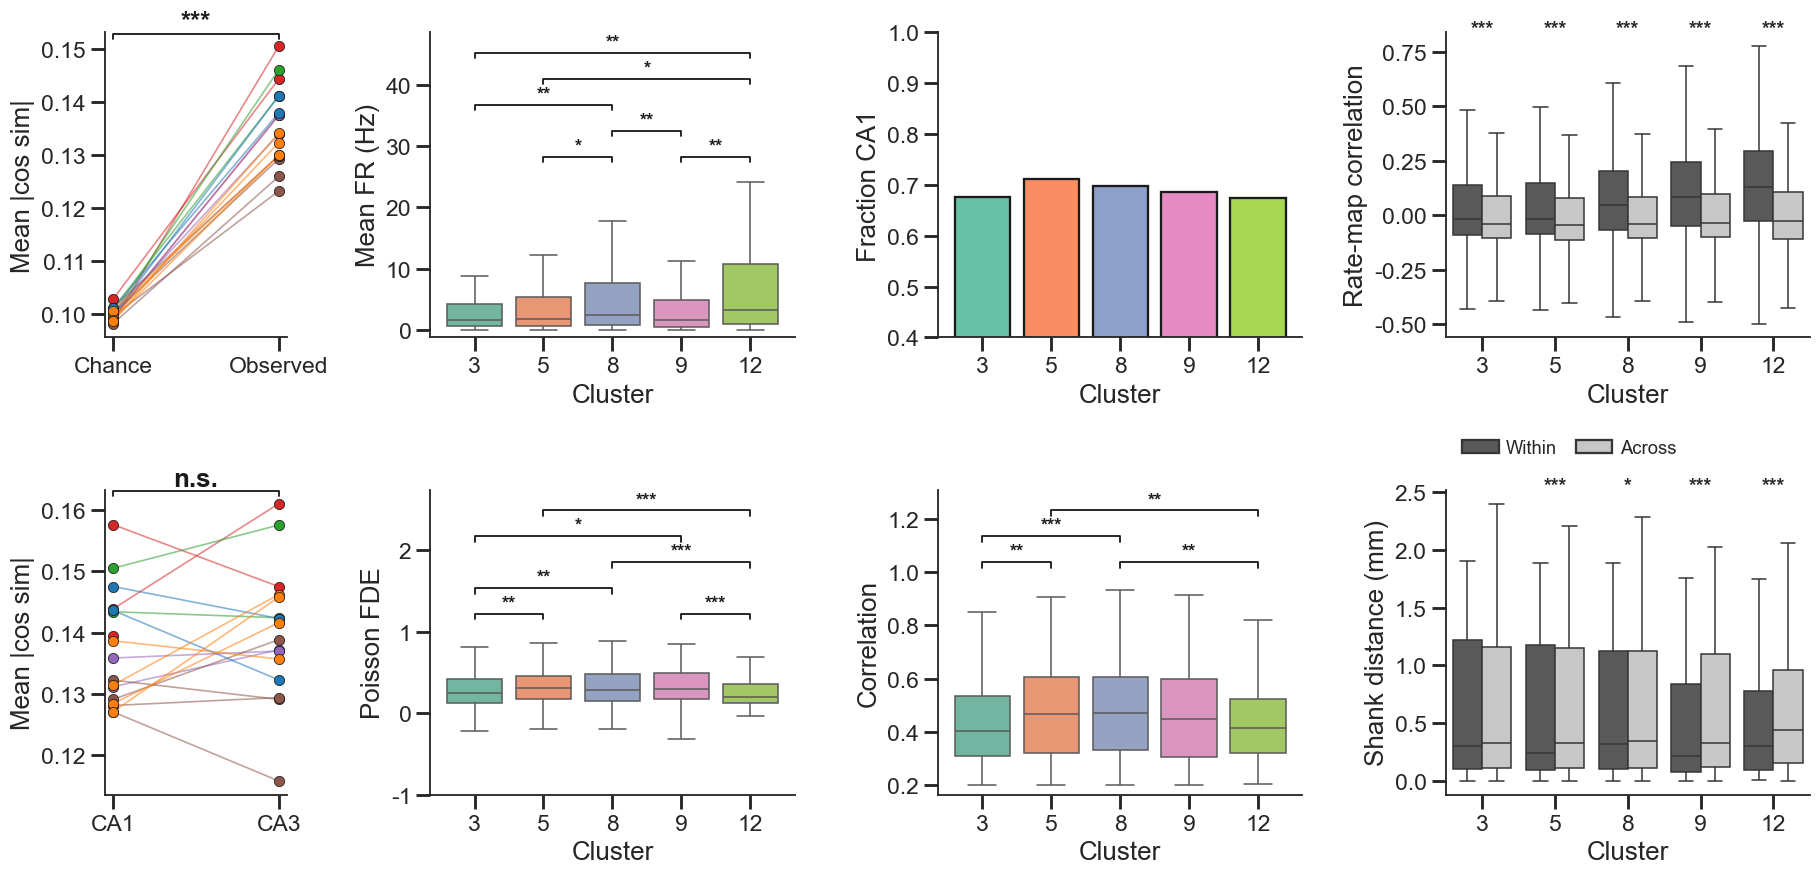

ED Fig 7 — panel statistics:
                  panel         comparison   n          p  stat  med_a   med_b                 test stars         P
                      a observed vs chance  17  1.526e-05     0 0.1341 0.09969                  NaN   *** P < 0.001
                      b         CA3 vs CA1  16     0.3484    49 0.1402  0.1341                  NaN       P = 0.348
           Mean FR (Hz)                NaN NaN  0.0009682   NaN    NaN     NaN       Kruskal-Wallis   *** P < 0.001
           Mean FR (Hz)                NaN NaN      0.391   NaN    NaN     NaN           MWU 3 vs 5       P = 0.391
           Mean FR (Hz)                NaN NaN   0.003907   NaN    NaN     NaN           MWU 3 vs 8    ** P = 0.004
           Mean FR (Hz)                NaN NaN     0.7139   NaN    NaN     NaN           MWU 3 vs 9       P = 0.714
           Mean FR (Hz)                NaN NaN   0.002369   NaN    NaN     NaN          MWU 3 vs 12    ** P = 0.002
           Mean FR (Hz)                NaN 

,panel,comparison,n,p,stat,med_a,med_b,test,stars,P
0,a,observed vs chance,17.0,1.525879e-05,0.0,0.134073,0.099692,NaN,***,P < 0.001
1,b,CA3 vs CA1,16.0,3.483887e-01,49.0,0.140227,0.134051,NaN,,P = 0.348
2,Mean FR (Hz),NaN,NaN,9.682043e-04,NaN,NaN,NaN,Kruskal-Wallis,***,P < 0.001
3,Mean FR (Hz),NaN,NaN,3.909706e-01,NaN,NaN,NaN,MWU 3 vs 5,,P = 0.391
4,Mean FR (Hz),NaN,NaN,3.906723e-03,NaN,NaN,NaN,MWU 3 vs 8,**,P = 0.004
5,Mean FR (Hz),NaN,NaN,7.139395e-01,NaN,NaN,NaN,MWU 3 vs 9,,P = 0.714
6,Mean FR (Hz),NaN,NaN,2.368652e-03,NaN,NaN,NaN,MWU 3 vs 12,**,P = 0.002
7,Mean FR (Hz),NaN,NaN,4.860958e-02,NaN,NaN,NaN,MWU 5 vs 8,*,P = 0.049
8,Mean FR (Hz),NaN,NaN,2.332095e-01,NaN,NaN,NaN,MWU 5 vs 9,,P = 0.233
9,Mean FR (Hz),NaN,NaN,1.761599e-02,NaN,NaN,NaN,MWU 5 vs 12,*,P = 0.018


In [43]:
# === Extended Data Figure 7 (a-h) on a single canvas ===
# Layout [[a, c, e, g], [b, d, f, h]] (column-major lettering); first column
# is half-width and holds the two orthogonality panels:
#   col 0 (half): a orthogonality vs chance | b CA1/CA3 orthogonality
#   col 1       : c mean FR | d FDE   (per readout cluster, pairwise MWU brackets)
#   col 2       : e fraction CA1 | f corr
#   col 3       : g rate-map corr | h shank distance  (within vs across, per cluster)
from itertools import combinations
from scipy.stats import kruskal, mannwhitneyu, fisher_exact, chi2_contingency

WA_PAL = {'within': '0.35', 'across': '0.78'}   # within/across hue (not canonical)


def cluster_brackets(ax, pair_ps):
    """Stacked significance brackets over a categorical (cluster) x-axis.

    ``pair_ps`` is a list of ``(i, j, p)``. Significant pairs (p<.05) are packed
    into rows greedily so brackets spanning non-overlapping x-ranges (e.g.
    adjacent pairs) share a row, and the whole stack floats in the top margin of
    the axes (headroom added below). Stars sit snug just above their own bracket.
    """
    sig = [(i, j, p) for i, j, p in pair_ps if np.isfinite(p) and p < 0.05]
    if not sig:
        return
    rows = []                                    # each row: list of occupied (x1,x2)
    def assign(x1, x2):
        for r, ivs in enumerate(rows):
            if all(x2 < a - 0.25 or x1 > b + 0.25 for a, b in ivs):
                ivs.append((x1, x2)); return r
        rows.append([(x1, x2)]); return len(rows) - 1
    placed = [(i, j, p, assign(i, j))            # short spans first -> lowest rows
              for i, j, p in sorted(sig, key=lambda t: (t[1] - t[0], t[0]))]
    nrows = len(rows)
    row_h, pad, bh = 0.085, 0.04, 0.018
    zone = min(0.55, pad + nrows * row_h)        # axes-fraction reserved above data
    y0, y1 = ax.get_ylim()                        # push data down into (1-zone)
    ax.set_ylim(y0, y0 + (y1 - y0) / (1 - zone))
    trans = ax.get_xaxis_transform()             # x data, y axes-fraction
    ybase = 1 - zone + pad
    for i, j, p, r in placed:
        y = ybase + r * row_h
        ax.plot([i, i, j, j], [y, y + bh, y + bh, y], transform=trans,
                lw=1.2, color='k', clip_on=False)
        ax.text((i + j) / 2, y + bh + 0.004, ph.stars_for_p(p), transform=trans,
                ha='center', va='bottom', fontsize=12, fontweight='bold',
                color='k', clip_on=False)

fig_ed8 = plt.figure(figsize=(20, 9))
gs_ed8 = fig_ed8.add_gridspec(2, 4, width_ratios=[0.5, 1, 1, 1], hspace=0.5, wspace=0.45)
A_a = fig_ed8.add_subplot(gs_ed8[0, 0]); A_b = fig_ed8.add_subplot(gs_ed8[1, 0])
A_c = fig_ed8.add_subplot(gs_ed8[0, 1]); A_d = fig_ed8.add_subplot(gs_ed8[1, 1])
A_e = fig_ed8.add_subplot(gs_ed8[0, 2]); A_f = fig_ed8.add_subplot(gs_ed8[1, 2])
A_g = fig_ed8.add_subplot(gs_ed8[0, 3]); A_h = fig_ed8.add_subplot(gs_ed8[1, 3])
cats = CLUSTER_ORDER
ed8_p = []

# --- a: residual-readout orthogonality (mean |cos|) vs chance ---
rng = np.random.default_rng(seed)
orth = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 4:
        continue
    Wr = np.stack(grp['readout_weight_residual'].values)
    iu = np.triu_indices(len(grp), k=1)
    obs = np.abs((Wr @ Wr.T)[iu]).mean()
    R = rng.standard_normal((len(grp), Wr.shape[1]))
    R /= np.linalg.norm(R, axis=1, keepdims=True)
    cha = np.abs((R @ R.T)[iu]).mean()
    orth.append(dict(session=sn, bat=parse_bat(sn), observed=obs, chance=cha))
orth_df = pd.DataFrame(orth)
orth_long = orth_df.melt(['session', 'bat'], ['chance', 'observed'], 'kind', 'v')
ph.paired_lines(A_a, orth_long, 'v', 'kind', ['chance', 'observed'])
ra = ph.paired_session_test(orth_long, 'v', 'kind', 'observed', 'chance')
ph.sig_bracket(A_a, 0, 1, ra['p'])
A_a.set(ylabel='mean |cos sim|')
ed8_p.append(dict(panel='a', comparison='observed vs chance', **ra))

# --- b: within-subregion orthogonality, CA1 vs CA3 (paired by session) ---
subo = []
for (sn, sr), grp in clu_df[clu_df['subregion'].isin(['CA1', 'CA3'])].groupby(['session', 'subregion']):
    if len(grp) < 3:
        continue
    Wr = np.stack(grp['readout_weight_residual'].values)
    iu = np.triu_indices(len(grp), k=1)
    subo.append(dict(session=sn, bat=parse_bat(sn), subregion=sr,
                     morth=np.abs((Wr @ Wr.T)[iu]).mean()))
subo_df = pd.DataFrame(subo)
ph.paired_lines(A_b, subo_df, 'morth', 'subregion', ['CA1', 'CA3'])
rb = ph.paired_session_test(subo_df, 'morth', 'subregion', 'CA3', 'CA1')
ph.sig_bracket(A_b, 0, 1, rb['p'], show_ns=True)      # annotate n.s.
A_b.set(ylabel='mean |cos sim|')
ed8_p.append(dict(panel='b', comparison='CA3 vs CA1', **rb))

# --- c, d, e: per-cluster mean FR / FDE / corr (Kruskal-Wallis omnibus +
#              pairwise Mann-Whitney brackets between every significant pair) ---
clu_df['is_ca1'] = (clu_df['subregion'] == 'CA1').astype(float)
clu_df.loc[~clu_df['subregion'].isin(['CA1', 'CA3']), 'is_ca1'] = np.nan
for ax, (col, ylab, clip) in zip([A_c, A_d, A_f],
                                 [('mean_fr', 'Mean FR (Hz)', False),
                                  ('fde_all', 'Poisson FDE', True),
                                  ('corr_all', 'Correlation', False)]):
    ph.cat_boxplot(ax, clu_df, 'cluster', col, cats, CLUSTER_PALETTE)
    ax.set(xlabel='cluster', ylabel=ylab)
    if clip:
        ax.set_ylim(-1, 1)                       # FDE display floored at -1
    vals = {c: clu_df.loc[clu_df['cluster'] == c, col].dropna().values for c in cats}
    grps = [vals[c] for c in cats if len(vals[c]) > 1]
    p_kw = kruskal(*grps).pvalue if len(grps) >= 2 else np.nan
    ed8_p.append(dict(panel=ylab, test='Kruskal-Wallis', p=p_kw))
    pair_ps = []
    for i, j in combinations(range(len(cats)), 2):
        a, b = vals[cats[i]], vals[cats[j]]
        if len(a) < 2 or len(b) < 2:
            continue
        pp = mannwhitneyu(a, b, alternative='two-sided').pvalue
        ed8_p.append(dict(panel=ylab, test=f'MWU {cats[i]} vs {cats[j]}', p=pp))
        pair_ps.append((i, j, pp))
    cluster_brackets(ax, pair_ps)

# --- f: fraction CA1 per cluster (y-axis starts at 0.4); per-cluster Fisher ---
frac = clu_df.groupby('cluster')['is_ca1'].mean().reindex(cats)
A_e.bar(range(len(cats)), frac.values, color=[CLUSTER_PALETTE[c] for c in cats], edgecolor='k')
A_e.set(xticks=range(len(cats)), xticklabels=cats, xlabel='cluster', ylabel='Fraction CA1')
A_e.set_ylim(0.4, 1.0)
ca1n = clu_df.groupby('cluster')['is_ca1'].agg(n_ca1='sum', n=lambda s: s.notna().sum())
tot_ca1, tot_n = ca1n['n_ca1'].sum(), ca1n['n'].sum()
tab = np.array([[ca1n.loc[c, 'n_ca1'], ca1n.loc[c, 'n'] - ca1n.loc[c, 'n_ca1']] for c in cats])
p_chi = chi2_contingency(tab)[1] if (tab.sum(1) > 0).all() else np.nan
ed8_p.append(dict(panel='Fraction CA1', test='chi2 across clusters', p=p_chi))
trans_f = A_e.get_xaxis_transform()
for xi, c in enumerate(cats):
    a1 = ca1n.loc[c, 'n_ca1']; a0 = ca1n.loc[c, 'n'] - a1
    b1 = tot_ca1 - a1; b0 = (tot_n - ca1n.loc[c, 'n']) - b1
    p = fisher_exact([[a1, a0], [b1, b0]])[1]
    ed8_p.append(dict(panel=f'Fraction CA1:cluster {c}', test='Fisher vs rest', p=p))
    s = ph.stars_for_p(p)
    if s:
        A_e.text(xi, 0.96, s, transform=trans_f, ha='center', va='bottom',
                 fontsize=12, fontweight='bold', clip_on=False)


def _within_across(ax, data, ycol, ylabel, panel, *, legend=False):
    """Boxplot of within- vs across-cluster values per cluster (x), one star
    over each cluster from a within-vs-across Mann-Whitney (no bracket)."""
    sns.boxplot(data=data, x='cluster', y=ycol, order=cats, hue='kind',
                hue_order=['within', 'across'], palette=WA_PAL,
                showfliers=False, ax=ax)
    trans = ax.get_xaxis_transform()
    for xi, c in enumerate(cats):
        w = data.loc[(data['cluster'] == c) & (data['kind'] == 'within'), ycol].dropna().values
        a = data.loc[(data['cluster'] == c) & (data['kind'] == 'across'), ycol].dropna().values
        p = mannwhitneyu(w, a, alternative='two-sided').pvalue if len(w) > 1 and len(a) > 1 else np.nan
        ed8_p.append(dict(panel=f'{panel}:cluster {c}', test='MWU within vs across', p=p))
        s = ph.stars_for_p(p)
        if s:
            ax.text(xi, 0.98, s, transform=trans, ha='center', va='bottom',
                    fontsize=13, fontweight='bold', clip_on=False)
    ax.set(xlabel='cluster', ylabel=ylabel)
    if legend:
        ax.legend(title='', loc='upper left', bbox_to_anchor=(0.0, -0.28), ncol=2,
                  fontsize=12, frameon=False, columnspacing=1.0, handletextpad=0.4)
    elif ax.legend_ is not None:
        ax.legend_.remove()


# --- g: rate-map correlation, within vs across cluster, per cluster ---
rm_rows = []
for sn, grp in clu_df.groupby('session'):
    if len(grp) < 2:
        continue
    units = grp['unit'].to_numpy(); cl = grp['cluster'].to_numpy()
    Cm = ratemap_corr_matrix(session_rate_maps[sn][units])
    iu, ju = np.triu_indices(len(units), 1)
    v = Cm[iu, ju]; ok = np.isfinite(v)
    for ci, cj, val in zip(cl[iu][ok], cl[ju][ok], v[ok]):
        if ci == cj:
            rm_rows.append((ci, 'within', val))
        else:
            rm_rows.append((ci, 'across', val)); rm_rows.append((cj, 'across', val))
rmc_df = pd.DataFrame(rm_rows, columns=['cluster', 'kind', 'r'])
_within_across(A_g, rmc_df, 'r', 'Rate-map correlation', 'g', legend=True)

# --- h: physical distance along shank, within vs across cluster, per cluster ---
dist_rows = []
for (sn, pr), grp in clu_df.groupby(['session', 'probe_id']):
    if len(grp) < 2:
        continue
    xy = grp[['lateral', 'depth']].to_numpy(); cl = grp['cluster'].to_numpy()
    iu, ju = np.triu_indices(len(grp), k=1)
    d = np.linalg.norm(xy[iu] - xy[ju], axis=1) / 1000.0          # µm -> mm
    for ci, cj, val in zip(cl[iu], cl[ju], d):
        if ci == cj:
            dist_rows.append((ci, 'within', val))
        else:
            dist_rows.append((ci, 'across', val)); dist_rows.append((cj, 'across', val))
dist_df = pd.DataFrame(dist_rows, columns=['cluster', 'kind', 'd'])
_within_across(A_h, dist_df, 'd', 'Shank distance (mm)', 'h')

ph.save_fig(fig_ed8, 'edfig7_full'); plt.show()
print('ED Fig 7 — panel statistics:'); ph.p_table(ed8_p)

**Extended Data Figure 7 | Readout-cluster comparisons.** **a**, Residual readout weights are less orthogonal (higher within-session mean |cosine similarity|) than random unit vectors of matched dimension (per-session medians, paired Wilcoxon). **b**, Orthogonality does not differ between CA1 and CA3 (paired by session; n.s.). **c–d**, Mean firing rate and Poisson FDE per readout cluster (Kruskal–Wallis omnibus across clusters; brackets mark every significant pairwise Mann–Whitney comparison). **e**, Fraction of CA1 neurons per cluster (y-axis from 0.4; χ² omnibus, per-cluster stars from Fisher's exact test of that cluster's CA1/CA3 split versus the pooled remainder). **f**, Correlation per readout cluster (Kruskal–Wallis omnibus across clusters; pairwise Mann–Whitney brackets). **g**, Rate-map correlation within versus across cluster, per cluster. **h**, Physical distance along the shank (mm) within versus across cluster, per cluster (Mann–Whitney within vs across; a star above each cluster marks significance). Exact *P* values printed above; Poisson FDE display floored at −1.

---
## Figure 5 — SWRs are associated with greater flight novelty and less predictable hippocampal activity

**a** SWRs elevated in a 3 s window before takeoff and after landing. **b** SWR rate around non-perch/non-reward ("other") flight edges vs perch and reward. **c** Rarer (unique) flight types are preceded/followed by more SWRs. **d** SWR rate vs cluster size (per-session slopes). **e** Overall SWR rate is stable across the session while peri-flight SWRs decline. **f–g** Increased peri-flight SWRs predict worse encoding (lower FDE) and decoding (higher log Fréchet), beyond session-time and flight-novelty effects (mixed model).

> SWR events are loaded directly from `RPL_converted/RPL_probe*.mat` and flight bouts from `Extracted_Behavior_*.mat` (raw data on the mount) — independent of the shared dataloaders. Restricted to the 17 `DEFAULT_SESSIONS` (`Dataset_3_14543_240419` is excluded for consistency even though it has ripple data).

In [44]:
def edge_class(at_perch, at_rew):
    """Flight-endpoint class from proximity masks: perch / reward / other."""
    return np.where(at_perch, 'perch', np.where(at_rew, 'reward', 'other'))

In [45]:
# === Figure 5 foundation: SWR events + reconstructed per-flight table (w/ clusters) ===
import glob, io, contextlib
from scipy.io import loadmat
import digitalbat.datasets.data as _ddata
from digitalbat.datasets.defaults import DEFAULT_PARENT_FOLDER
from notebook_helpers import compute_target_proximity

PARENT = DEFAULT_PARENT_FOLDER.rstrip('/')
PSTH_WIN, W_PERI = 30.0, 3.0


def load_flight_bouts(sess):
    bhv = loadmat(glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat')[0])
    fly = bhv['bflying'][:, 0] > 0
    t = bhv['t'][:, 0] if 'Dataset_2' in sess else bhv['t'][0, :]
    d = np.diff(fly.astype(np.int8))
    starts = np.where(d == 1)[0] + 1
    stops = np.where(d == -1)[0] + 1
    if fly[0]:
        starts = np.r_[0, starts]
    if fly[-1]:
        stops = np.r_[stops, len(fly)]
    return t[starts], t[stops - 1]


def load_swr_events(sess):
    """Merged (across-probe) ripple event times (s)."""
    t_all, dur_all = [], []
    for f in sorted(glob.glob(f'{PARENT}/RPL_converted/{sess}/RPL_probe*.mat')):
        tbl = np.atleast_1d(loadmat(f, squeeze_me=True, struct_as_record=True)['RPL_out']['table'].item())
        if tbl.size == 0:
            continue
        t_all.append(np.asarray(tbl['t'], dtype=float).ravel())
        dur_all.append(np.asarray(tbl['dur'], dtype=float).ravel())
    if not t_all:
        return np.zeros(0)
    t, dur = np.concatenate(t_all), np.concatenate(dur_all)
    order = np.argsort(t)
    s, e = t[order], (t + dur)[order]
    ms, me = [s[0]], [e[0]]
    for i in range(1, len(s)):
        if s[i] <= me[-1]:
            me[-1] = max(me[-1], e[i])
        else:
            ms.append(s[i]); me.append(e[i])
    return (np.array(ms) + np.array(me)) / 2


def peri_event_diffs(edges, swr_t, window):
    out = [swr_t[np.abs(swr_t - et) <= window] - et for et in edges]
    return np.concatenate(out) if out else np.zeros(0)


def reconstruct_flights(sess):
    """Re-run Data_Prep to recover per-flight cluster id + start/stop times +
    takeoff/landing positions (aligned to the joint model's flight ordering)."""
    folder = f'{PARENT}/{sess}'
    su = f'{PARENT}/To_transfer/out_Gunits_probe*_{sess}_with_metrics.mat'
    dp = _ddata.Data_Prep_for_Raw(
        parent_folder=folder, su_file_path=su, only_flight_flag=True,
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False,
        use_LFP_flag=False, use_ripple_flag=False, spike_count_flag=True,
        bin_width=bin_width, max_acceleration=50)
    with contextlib.redirect_stdout(io.StringIO()):
        dp.get_all_behavior(); dp.get_all_spike(); dp.get_flight_cluster()
    bhv = loadmat(glob.glob(folder + '/Extracted_Behavior_*.mat')[0])
    bt = bhv['t'][:, 0] if 'Dataset_2' in sess else bhv['t'][0, :]
    fcr, atf = dp.flight_cluster_results, dp.all_time_flight
    pre = []
    for cid in np.unique(fcr['id']):
        sel = np.where(fcr['id'] == cid)[0]
        st, sp = bt[fcr['start_frame'][sel]], bt[fcr['stop_frame'][sel]]
        for ii in range(len(st)):
            ind = np.where((atf >= st[ii]) & (atf <= sp[ii]))[0]
            if len(ind):
                pos = dp.all_behavior[:3, ind].T
                acc = np.gradient(np.gradient(pos, bin_width, axis=0), bin_width, axis=0)
                pre.append((int(cid), float(st[ii]), float(sp[ii]), pos[0], pos[-1],
                            float(np.linalg.norm(acc, axis=1).max())))
    kept = [r for r in pre if r[5] <= 50]
    rows = []
    for fpi, (cid, st, sp, toff, land, _) in enumerate(kept):
        rows.append(dict(session=sess, bat=parse_bat(sess), flight_path_index=fpi,
                         flight_type_index=cid, start_t=st, stop_t=sp, dur=sp - st,
                         toff=toff, land=land))
    return pd.DataFrame(rows)


swr_times_by_session, peri_rows, flight_parts = {}, [], []
for sess in session_names:                       # 17 DEFAULT_SESSIONS
    if not (glob.glob(f'{PARENT}/{sess}/Extracted_Behavior_*.mat')
            and os.path.isdir(f'{PARENT}/RPL_converted/{sess}')):
        print(f'skip {sess}: missing behaviour/ripple'); continue
    swr_t = np.sort(load_swr_events(sess))
    if len(swr_t) == 0:
        continue
    swr_times_by_session[sess] = swr_t
    start_t, stop_t = load_flight_bouts(sess)
    for align, edges in (('onset', start_t), ('offset', stop_t)):
        peri_rows.append(pd.DataFrame(dict(session=sess, bat=parse_bat(sess), align=align,
                                           dt=peri_event_diffs(edges, swr_t, PSTH_WIN))))
    fdf = reconstruct_flights(sess)
    for kind in ('toff', 'land'):
        prox = compute_target_proximity(np.vstack(fdf[kind].values), session_name=sess)
        fdf[f'{kind}_class'] = edge_class(prox['at_perch'], prox['at_rew'])
    fdf['pre_takeoff'] = np.searchsorted(swr_t, fdf['start_t']) - np.searchsorted(swr_t, fdf['start_t'] - W_PERI)
    fdf['post_landing'] = np.searchsorted(swr_t, fdf['stop_t'] + W_PERI) - np.searchsorted(swr_t, fdf['stop_t'])
    flight_parts.append(fdf)
    print(f'{sess}: {len(fdf)} flights, {len(swr_t)} SWR')

peri_df = pd.concat(peri_rows, ignore_index=True)
flights = pd.concat(flight_parts, ignore_index=True)
flights['pre_rate'] = flights['pre_takeoff'] / W_PERI
flights['post_rate'] = flights['post_landing'] / W_PERI
flights['cluster_size'] = flights.groupby(['session', 'flight_type_index'])['flight_path_index'].transform('size')
flights['repeated'] = np.where(flights['cluster_size'] > 1, 'repeated', 'unique')
flights = flights.sort_values(['session', 'start_t'])
flights['flight_num'] = flights.groupby('session').cumcount()
flights['flight_frac'] = flights.groupby('session')['flight_num'].transform(lambda s: s / max(s.max(), 1))
print(f'\n{len(flights)} flights, {flights.session.nunique()} sessions, {flights.bat.nunique()} bats')

Dataset_3_14543_240420: 135 flights, 6013 SWR
Dataset_3_14543_240421: 112 flights, 7334 SWR
Dataset_3_29959_240402: 145 flights, 3227 SWR
Dataset_3_29959_240403: 127 flights, 4264 SWR
Dataset_3_29959_240404: 78 flights, 4978 SWR
Dataset_2_14445_231208: 77 flights, 8600 SWR
Dataset_2_14445_231209: 76 flights, 10854 SWR
Dataset_1_32622_231009: 78 flights, 8481 SWR
Dataset_1_32622_231010: 94 flights, 6366 SWR
Dataset_1_32622_231007: 97 flights, 7343 SWR
Dataset_2_14611_231208: 62 flights, 3512 SWR
Dataset_2_14611_231209: 65 flights, 6097 SWR
Dataset_3_00000_240402: 80 flights, 12349 SWR
Dataset_3_00000_240403: 108 flights, 7985 SWR
Dataset_3_00000_240404: 133 flights, 12545 SWR
Dataset_3_00000_240405: 145 flights, 11089 SWR
Dataset_3_29959_240405: 126 flights, 5237 SWR

1738 flights, 17 sessions, 6 bats


In [46]:
# === Fig 5f/g: peri-flight SWRs predict worse encoding (FDE) + decoding (log Fréchet) ===
# Mixed model holding session, flight cluster and normalized session-time fixed.
import statsmodels.formula.api as smf
import statsmodels.api as sm
import warnings
from digitalbat.utility.utils import poisson_fraction_deviance_explained


def _perflight_pop_fde(yt, rate):
    """Population Poisson FDE for one flight: pooled deviance with a PER-NEURON null
    (each neuron's own mean rate over the flight). Passing the 2-D (T, neuron) arrays
    straight to `poisson_fraction_deviance_explained` collapses to a SINGLE global mean
    across neurons, so the model is credited for trivial across-neuron rate differences
    and FDE is badly inflated (a model that only knows each neuron's mean scores ~0.5
    instead of ~0)."""
    eps = 1e-33
    yt = np.clip(np.asarray(yt, float), eps, None)
    rate = np.clip(np.asarray(rate, float), eps, None)
    mu0 = np.clip(yt.mean(0, keepdims=True), eps, None)
    dev = lambda y, mu: 2.0 * np.sum(y * (np.log(y) - np.log(mu)) - (y - mu))
    return 1.0 - dev(yt, rate) / (dev(yt, mu0) + eps)


@torch.no_grad()
def joint_encode_perflight():
    rows = []
    for sn, sd in joint_loaders['test'].items():
        for b in sd:
            m = b.mask.to(device)
            rate, _, _ = joint_model(sn, b.spike.to(device), b.behavior.to(device),
                                     m, m, torch.zeros_like(m))
            rate = rate.cpu().numpy(); yt = b.spike.numpy(); mn = b.mask.numpy().astype(bool)
            fpi = b.flight_path_index.numpy()
            for i in range(rate.shape[0]):
                v = mn[i]
                if v.sum() < 2:
                    continue
                rows.append(dict(session=sn, flight_path_index=int(fpi[i]),
                                 fde=float(_perflight_pop_fde(yt[i, v], rate[i, v]))))
    return pd.DataFrame(rows)


perflight_fde = joint_encode_perflight()
perflight_fr = joint_frechet.rename(columns={'flight_id': 'flight_path_index'})[
    ['session', 'flight_path_index', 'frechet_3d']]
mf = (flights.merge(perflight_fde, on=['session', 'flight_path_index'], how='inner')
             .merge(perflight_fr, on=['session', 'flight_path_index'], how='inner'))
mf['log_frechet'] = np.log(mf['frechet_3d'].clip(lower=1e-3))
print(f'Fig 5f/g merged flights: {len(mf)} (of {len(flights)})')

# (added_variable_panel + all Fig 5 plotting live in the assembly cell below)

Fig 5f/g merged flights: 278 (of 1738)


In [ ]:
# === Figure 5 (a-h) on a single canvas ===
# 4 x 3 grid (left/mid cols = takeoff/landing where split):
#   row 1: a takeoff SWRs | a landing SWRs      | [b endpoint (1/2) + d slope (1/2)]
#   row 2: c takeoff unique-vs-rep | c landing  | e normalized SWR rate vs session time
#   row 3: g encode takeoff | g encode landing  | f peri SWRs vs flight number
#   row 4: h decode takeoff | h decode landing  | (empty)
# g/h significance comes from a Negative-Binomial MIXED model (glmer.nb: count ~ quality +
# flight_frac + offset(log_exp) + (1|bat/session)), falling back to NB GLM if rpy2 is absent.
import contextlib, io
from scipy.stats import friedmanchisquare

fig5 = plt.figure(figsize=(18, 18))
gs5 = fig5.add_gridspec(4, 3, hspace=0.5, wspace=0.35)

# --- a: peri-flight SWR PSTH around takeoff / landing (shared y-axis) ---
n_flights_total = len(flights)
BW = 1.0
bins = np.arange(-PSTH_WIN, PSTH_WIN + BW, BW); ctr = bins[:-1] + BW / 2
axa0 = None
for k, (align, lab) in enumerate([('onset', 'takeoff'), ('offset', 'landing')]):
    ax = fig5.add_subplot(gs5[0, k], sharey=axa0) if k else fig5.add_subplot(gs5[0, k])
    if k == 0:
        axa0 = ax
    dt = peri_df.loc[peri_df['align'] == align, 'dt'].values
    rate = np.histogram(dt, bins=bins)[0] / (n_flights_total * BW)
    lo, hi = (-W_PERI, 0) if k == 0 else (0, W_PERI)  # 3-s peri-flight window
    ax.axvspan(lo, hi, color='0.85', alpha=0.6, zorder=0)
    ax.bar(ctr, rate, width=BW, color='steelblue', alpha=0.85)
    ax.axvline(0, color='crimson', ls='--', lw=1.5)
    ax.set(xlabel=f'time from {lab} (s)', title=f'{lab}',
           ylabel='SWR rate (Hz)' if k == 0 else '')
    if k:
        plt.setp(ax.get_yticklabels(), visible=False)

# --- b (endpoint class) + d (cluster-size slope): two half-width panels in row-1 col-3.
#     Wider wspace shifts b to the left, away from d. ---
gs_bd = gs5[0, 2].subgridspec(1, 2, wspace=1.0)

# b: per-session mean peri-flight SWR rate by endpoint class
edges = pd.concat([
    flights[['session', 'bat', 'pre_rate', 'toff_class']].rename(
        columns={'pre_rate': 'rate', 'toff_class': 'cls'}),
    flights[['session', 'bat', 'post_rate', 'land_class']].rename(
        columns={'post_rate': 'rate', 'land_class': 'cls'})], ignore_index=True)
CLS3 = ['perch', 'reward', 'other']
ps = edges.groupby(['session', 'bat', 'cls'])['rate'].mean().reset_index()
ps['cls'] = pd.Categorical(ps['cls'], CLS3, ordered=True)
axb = fig5.add_subplot(gs_bd[0, 0])
sns.boxplot(data=ps, x='cls', y='rate', order=CLS3, color='0.85', showfliers=False, ax=axb)
sns.stripplot(data=ps, x='cls', y='rate', order=CLS3, hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(ps['bat'])], size=7, jitter=0.12,
              edgecolor='k', linewidth=0.4, ax=axb, legend=False)
wide = ps.pivot_table(index='session', columns='cls', values='rate', observed=False).dropna()
p_omni = friedmanchisquare(*[wide[c].values for c in CLS3])[1] if len(wide) >= 3 else np.nan
b5_p = [dict(comparison='Friedman perch/reward/other', n=len(wide), p=p_omni)]
lvl = 0
for a, b in [(0, 2), (1, 2), (0, 1)]:
    r = ph.paired_session_test(ps.rename(columns={'rate': 'v', 'cls': 'c'}), 'v', 'c', CLS3[a], CLS3[b])
    ph.sig_bracket(axb, a, b, r['p'], level=lvl); lvl += 1
    b5_p.append(dict(comparison=f'{CLS3[a]} vs {CLS3[b]}', **r))
axb.set(xlabel='Endpoint', ylabel='SWR rate (Hz)', title='')
axb.tick_params(axis='x', rotation=45)  # rotate tick labels (font size unchanged)
plt.setp(axb.get_xticklabels(), ha='right', rotation_mode='anchor')

# d: per-session slope of pre-takeoff SWR rate vs cluster size
cd_p = []
axd = fig5.add_subplot(gs_bd[0, 1])
slopes = []
for sn, dgrp in flights.groupby('session'):
    if dgrp['cluster_size'].nunique() < 2 or len(dgrp) < 8:
        continue
    bb = np.polyfit(dgrp['cluster_size'].values, dgrp['pre_rate'].values, 1)[0]
    slopes.append(dict(session=sn, bat=parse_bat(sn), slope=bb))
slope_df = pd.DataFrame(slopes)
sns.stripplot(data=slope_df, y='slope', hue='bat', palette=BAT_PALETTE,
              hue_order=[b for b in bats if b in set(slope_df['bat'])], size=8, jitter=0.15,
              edgecolor='k', linewidth=0.4, ax=axd, legend=False)
axd.axhline(0, color='0.5', ls='--', lw=1)
rd = ph.onesample_session_test(slope_df, 'slope', popmean=0.0)
# significance as asterisks only, no bracket
axd.text(0.5, 0.97, ph.stars_for_p(rd['p']) or 'n.s.', transform=axd.transAxes,
         ha='center', va='top', fontsize=18, fontweight='bold')
axd.set(xticks=[], xlabel='', title='',
        ylabel='Slope: SWR rate vs.\n# flights in cluster')  # 2-line ylabel, broken at 'vs.'
axd.spines[['top', 'right', 'bottom']].set_visible(False)  # remove bottom (x) axis

# --- c: repeated vs unique flights -- takeoff | landing (aligned with a) ---
for k, (col, lab) in enumerate([('pre_rate', 'takeoff'), ('post_rate', 'landing')]):
    axc = fig5.add_subplot(gs5[1, k])
    psc = flights.groupby(['session', 'bat', 'repeated'])[col].mean().reset_index()
    ph.paired_lines(axc, psc.rename(columns={col: 'v'}), 'v', 'repeated', ['unique', 'repeated'])
    rc = ph.paired_session_test(psc.rename(columns={col: 'v'}), 'v', 'repeated', 'unique', 'repeated')
    ph.sig_bracket(axc, 0, 1, rc['p'])
    axc.set_xlim(-0.7, 1.7)  # widen so the two ticks move inward
    axc.set(xlabel='', ylabel='SWR rate (Hz)' if k == 0 else '', title='')
    cd_p.append(dict(comparison=f'unique vs repeated ({lab})', **rc))
cd_p.append(dict(comparison='cluster-size slope vs 0', **rd))

# --- e: overall SWR rate over session deciles, normalized to each session's mean ---
axe = fig5.add_subplot(gs5[1, 2])
NBIN = 10
curves = []
for sn, t in swr_times_by_session.items():
    if len(t) < 3 * NBIN:
        continue
    e = np.linspace(t.min(), t.max(), NBIN + 1)
    r = np.histogram(t, bins=e)[0] / ((t.max() - t.min()) / NBIN)
    curves.append((parse_bat(sn), r / r.mean()))  # normalized to session mean
xb = (np.arange(NBIN) + 0.5) / NBIN
for bt, c in curves:
    axe.plot(xb, c, color=BAT_PALETTE.get(bt, '0.6'), lw=0.8, alpha=0.35)
curve_mat = np.array([c for _, c in curves])
mu = curve_mat.mean(0); ci = 1.96 * curve_mat.std(0) / np.sqrt(len(curve_mat))
axe.plot(xb, mu, color='k', lw=2.5)
axe.fill_between(xb, mu - ci, mu + ci, color='k', alpha=0.2)
axe.axhline(1, color='0.5', ls='--', lw=1)  # match the Slope panel (d) dashed line style
axe.set(xlabel='normalized session time', ylabel='normalized SWR rate', title='')

# --- f: peri-flight SWR rate vs normalized flight number ---
axf = fig5.add_subplot(gs5[2, 2])
fb = np.linspace(0, 1, 9)
idx = np.clip(np.digitize(flights['flight_frac'].values, fb) - 1, 0, len(fb) - 2)
F_COLORS = [('pre_rate', 'before takeoff', '#009E73'),   # teal-green
            ('post_rate', 'after landing', '#CC79A7')]   # reddish-purple (Okabe-Ito pair)
for col, lab, cc in F_COLORS:
    v = flights[col].values
    mu = [v[idx == k].mean() for k in range(len(fb) - 1)]
    se = [v[idx == k].std() / np.sqrt(max((idx == k).sum(), 1)) for k in range(len(fb) - 1)]
    axf.errorbar((fb[:-1] + fb[1:]) / 2, mu, yerr=1.96 * np.array(se), fmt='o-', color=cc, label=lab, capsize=3)
axf.legend(frameon=False, fontsize=16)
axf.set(xlabel='normalized flight number', ylabel='peri-flight SWR rate (Hz)', title='')


# ===================== g / h: Negative-Binomial models =====================
# SWR counts over the actual adjacent rest interval (variable exposure), as in swr.ipynb.
_fl = mf.sort_values(['session', 'start_t']).copy()
_g = _fl.groupby('session')
_fl['prev_stop'] = _g['stop_t'].shift(1); _fl['next_start'] = _g['start_t'].shift(-1)
_fl['exp_pre'] = _fl['start_t'] - _fl['prev_stop']; _fl['exp_post'] = _fl['next_start'] - _fl['stop_t']
_fl['pre_cnt'] = np.nan; _fl['post_cnt'] = np.nan
for _sess, _idx in _fl.groupby('session').groups.items():
    _t = swr_times_by_session[_sess]; _d = _fl.loc[_idx]
    _m1 = _d['prev_stop'].notna().values
    _pc = np.full(len(_d), np.nan)
    _pc[_m1] = np.searchsorted(_t, _d['start_t'].values[_m1]) - np.searchsorted(_t, _d['prev_stop'].values[_m1])
    _fl.loc[_idx, 'pre_cnt'] = _pc
    _m2 = _d['next_start'].notna().values
    _qc = np.full(len(_d), np.nan)
    _qc[_m2] = np.searchsorted(_t, _d['next_start'].values[_m2]) - np.searchsorted(_t, _d['stop_t'].values[_m2])
    _fl.loc[_idx, 'post_cnt'] = _qc
_fl['peri_cnt'] = _fl['pre_cnt'] + _fl['post_cnt']       # pooled takeoff + landing
_fl['exp_peri'] = _fl['exp_pre'] + _fl['exp_post']
_fl['clu_uid'] = _fl['session'] + '_' + _fl['flight_type_index'].astype(str)


def stars_dagger(p):
    """Standard 3-tier asterisks, a dagger for a marginal 0.05 < p < 0.10, else n.s."""
    if p is None or not np.isfinite(p):
        return 'n.s.'
    return ph.stars_for_p(p) or ('†' if p < 0.10 else 'n.s.')


def _lmm_rate(d, xcol):  # Gaussian LMM on the SWR rate (count / exposure)
    m = smf.mixedlm(f'rate ~ {xcol} + flight_frac', d, groups=d['bat'], re_formula='1',
                    vc_formula={'session': '0 + C(session)', 'cluster': '0 + C(clu_uid)'})
    r = m.fit(reml=True, method='lbfgs', maxiter=400)
    return dict(model='LMM rate (Gaussian)', beta=float(r.params[xcol]), p=float(r.pvalues[xcol]))


def _nb_glm(d, xcol):  # NB GLM: log-exposure OFFSET, session-clustered robust SE, NO random effects
    X = sm.add_constant(d[[xcol, 'flight_frac']].astype(float))
    r = sm.NegativeBinomial(d['count'].astype(float), X, offset=d['log_exp'].values).fit(
        disp=0, cov_type='cluster', cov_kwds={'groups': d['bat']})
    return dict(model='NB GLM (offset, cluster-robust SE)', beta=float(r.params[xcol]), p=float(r.pvalues[xcol]))


# NB MIXED (offset + nested random intercepts) via R lme4::glmer.nb (rpy2).
import os as _os
_os.environ.setdefault('R_HOME', '/home/alowet/miniconda3/envs/gpu/lib/R')
try:
    import rpy2.robjects as _ro
    from rpy2.robjects import pandas2ri as _p2r
    import rpy2.rinterface_lib.callbacks as _rcb
    _rcb.consolewrite_print = lambda *a, **k: None
    _rcb.consolewrite_warnerror = lambda *a, **k: None
    _ro.r('suppressMessages(library(lme4))')
    _HAVE_NB_MIXED = True
except Exception as _e:
    _HAVE_NB_MIXED = False
    print('NB mixed (glmer.nb) unavailable — falling back to NB GLM. Reason:', str(_e)[:90])


def _nb_mixed(d, xcol):  # NB MIXED: offset + (1 | bat/session) random intercepts
    sub = d[['count', 'log_exp', 'bat', 'session', 'flight_frac', xcol]].copy()
    with (_ro.default_converter + _p2r.converter).context():
        _ro.globalenv['d'] = sub
        _ro.r('d$bat <- factor(d$bat); d$session <- factor(d$session)')
        _ro.r(f'm <- suppressWarnings(lme4::glmer.nb(count ~ {xcol} + flight_frac + offset(log_exp) '
              f'+ (1|bat/session), data=d))')
        co = np.array(_ro.r('summary(m)$coefficients'))
        rn = list(_ro.r('rownames(summary(m)$coefficients)'))
    i = rn.index(xcol)
    return dict(model='NB mixed (offset + RE)', beta=float(co[i, 0]), p=float(co[i, 3]))


def _prep_counts(d, count_col, exp_col):
    dd = d.dropna(subset=[count_col, exp_col, 'flight_frac']).copy()
    dd = dd[dd[exp_col] > 0]
    dd['count'] = dd[count_col].astype(float)
    dd['log_exp'] = np.log(dd[exp_col].astype(float))
    return dd


def nb_sig(d, quality, count_col, exp_col):
    """NB significance for count ~ quality (+ offset log_exp + flight_frac). Prefers the
    mixed model (glmer.nb); falls back to the NB GLM. All fits fully silenced."""
    dd = _prep_counts(d.dropna(subset=[quality]), count_col, exp_col)
    for fn in ([_nb_mixed] if _HAVE_NB_MIXED else []) + [_nb_glm]:
        try:
            with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()), \
                    contextlib.redirect_stderr(io.StringIO()):
                warnings.simplefilter('ignore')
                res = fn(dd, quality)
            if np.isfinite(res['p']):
                return dd, res['beta'], res['p']
        except Exception:
            continue
    return dd, np.nan, np.nan


def nb_avp_panel(ax, quality, count_col, exp_col, ylabel, xlabel, title=''):
    """Added-variable scatter (residual quality vs residual #SWRs, partialling out
    session + flight_frac + log-exposure) with an NB-mixed significance mark."""
    dd, beta, p = nb_sig(_fl, quality, count_col, exp_col)
    Xc = sm.add_constant(pd.get_dummies(dd['session'], drop_first=True).astype(float)
                         .assign(flight_frac=dd['flight_frac'].values, log_exp=dd['log_exp'].values))
    ry = sm.OLS(dd[quality].values, Xc).fit().resid
    rx = sm.OLS(dd['count'].values, Xc).fit().resid
    ax.scatter(rx, ry, s=8, alpha=0.25, color='0.5', rasterized=True)
    cf = np.polyfit(rx, ry, 1); xs = np.linspace(rx.min(), rx.max(), 50)
    ax.plot(xs, np.polyval(cf, xs), color='firebrick', lw=2.5)
    ax.text(0.5, 0.97, stars_dagger(p), transform=ax.transAxes, va='top', ha='center',
            fontsize=18, fontweight='bold')
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    return dict(comparison=title, beta=beta, p=p, n=len(dd))


# g: encoding (Poisson FDE) row -- takeoff | landing (shared ylabel, no xlabel)
r_g_to = nb_avp_panel(fig5.add_subplot(gs5[2, 0]), 'fde', 'pre_cnt', 'exp_pre',
                      'residual Poisson FDE', '', title='encode · takeoff')
r_g_la = nb_avp_panel(fig5.add_subplot(gs5[2, 1]), 'fde', 'post_cnt', 'exp_post',
                      '', '', title='encode · landing')
# h: decoding (log Fréchet) row -- takeoff | landing (shared ylabel; xlabels on bottom row)
r_h_to = nb_avp_panel(fig5.add_subplot(gs5[3, 0]), 'log_frechet', 'pre_cnt', 'exp_pre',
                      'residual log Fréchet', 'Residual # pre-takeoff SWRs', title='decode · takeoff')
r_h_la = nb_avp_panel(fig5.add_subplot(gs5[3, 1]), 'log_frechet', 'post_cnt', 'exp_post',
                      '', 'Residual # post-landing SWRs', title='decode · landing')

ph.save_fig(fig5, 'fig5_full'); plt.show()
print('Fig 5b — endpoint class comparisons:'); ph.p_table(b5_p)
print('Fig 5c/d — novelty (takeoff/landing) + cluster-size slope:'); ph.p_table(cd_p)
print('Fig 5g/h — NB mixed (#SWRs ~ encode/decode quality | bat, session, exposure, session-time):')
ph.p_table([r_g_to, r_g_la, r_h_to, r_h_la])

# --- Variety of LMEs for #SWRs vs encode/decode quality (mirrors swr.ipynb Task 3):
#     Gaussian LMM (rate) + NB GLM + NB mixed, for encode (FDE) and decode (log & raw
#     Fréchet, to compare the two predictor scalings), pooled AND split takeoff/landing. ---
_SIDES = [('pooled', 'peri_cnt', 'exp_peri'), ('takeoff', 'pre_cnt', 'exp_pre'),
          ('landing', 'post_cnt', 'exp_post')]
_MEASURES = [('fde', 'encode: FDE'), ('log_frechet', 'decode: log Fréchet'),
             ('frechet_3d', 'decode: raw Fréchet')]
_model_fns = [_lmm_rate, _nb_glm] + ([_nb_mixed] if _HAVE_NB_MIXED else [])
_swr_rows = []
for side, ccol, ecol in _SIDES:
    d0 = _prep_counts(_fl, ccol, ecol); d0['rate'] = d0['count'] / d0[ecol]
    for xcol, mlab in _MEASURES:
        dd = d0.dropna(subset=[xcol, 'rate'])
        for fn in _model_fns:
            try:
                with warnings.catch_warnings(), contextlib.redirect_stdout(io.StringIO()), \
                        contextlib.redirect_stderr(io.StringIO()):
                    warnings.simplefilter('ignore')
                    res = fn(dd, xcol)
            except Exception:
                res = dict(model=fn.__name__, beta=np.nan, p=np.nan)
            res.update(measure=mlab, side=side, predictor=xcol, n=len(dd)); _swr_rows.append(res)
swr_glmm = pd.DataFrame(_swr_rows)[['measure', 'side', 'model', 'n', 'beta', 'p']]
swr_glmm['sig'] = swr_glmm['p'].map(stars_dagger)  # asterisks + dagger (0.05<p<0.10)
print('\n=== Fig 5g/h — #SWRs ~ encode/decode quality: variety of LMEs (pooled + takeoff/landing) ===')
print('  count-outcome models use log(adjacent-rest exposure) offset; beta/p are for the quality predictor')
print(swr_glmm.round(4).to_string(index=False))


**Figure 5 | SWRs are associated with greater flight novelty and less predictable hippocampal activity.** **a**, Peri-flight SWR rate (events per flight per second, pooled) rises in the seconds before takeoff and after landing. **b**, Peri-flight SWR rate by flight-endpoint class: elevated around non-perch, non-reward ("other") edges relative to perch and reward (per-session means, coloured by bat; Friedman omnibus + pairwise Wilcoxon). **c**, Rarer (unique) flight clusters are preceded by more SWRs than repeated clusters (paired by session). **d**, Per-session slope of pre-takeoff SWR rate against cluster size is negative (one-sample Wilcoxon vs 0). **e**, Overall SWR rate is stable across the session (thin lines = sessions coloured by bat; black = mean ± 95% CI) while peri-flight SWR rate declines with flight number. **f–g**, Added-variable plots from a linear mixed model (`outcome ~ #peri-flight SWRs + normalized session time`, random intercepts for session, cluster fixed effects): more peri-flight SWRs predict lower encoding FDE (**f**) and higher log Fréchet decoding error (**g**). Exact *P* values (mixed-model coefficient for #SWRs) printed above.

---

## Extended Data Figure 8 — peri-flight SWRs & mixed-model ladders

**a–b** Peri-flight SWR rate around non-reward takeoffs (**a**) and non-reward landings (**b**), reward edges excluded so any modulation can't be attributed to reward delivery/consumption. **c** Decoding error (3-D log Fréchet) vs number of flights in the cluster, controlling for bat (added-variable plot). **d–f** Full mixed-model ladders (naïve pooled → per-session → added-variable) relating encoding fit (Poisson FDE, Pearson r) and decoding accuracy (log Fréchet) to peri-flight SWR counts, with pre-flight (takeoff) and post-flight (landing) SWRs shown separately.

In [48]:
# === ED Fig 8: SWR mixed-model ladders ===
# Extend the Fig 5f/g merged table with per-flight corr (encode).
@torch.no_grad()
def joint_encode_perflight_corr():
    rows = []
    for sn, sd in joint_loaders['test'].items():
        for b in sd:
            m = b.mask.to(device)
            rate, _, _ = joint_model(sn, b.spike.to(device), b.behavior.to(device),
                                     m, m, torch.zeros_like(m))
            rate = rate.cpu().numpy(); yt = b.spike.numpy(); mn = b.mask.numpy().astype(bool)
            fpi = b.flight_path_index.numpy()
            for i in range(rate.shape[0]):
                v = mn[i]
                if v.sum() < 3:
                    continue
                c = corr(yt[i, v], rate[i, v], axis=0)
                rows.append(dict(session=sn, flight_path_index=int(fpi[i]),
                                 corr=float(np.nanmean(c))))
    return pd.DataFrame(rows)


mf2 = mf.merge(joint_encode_perflight_corr(), on=['session', 'flight_path_index'], how='left')

# (lme_p, ladder_row + all ED Fig 8 plotting live in the assembly cell below)


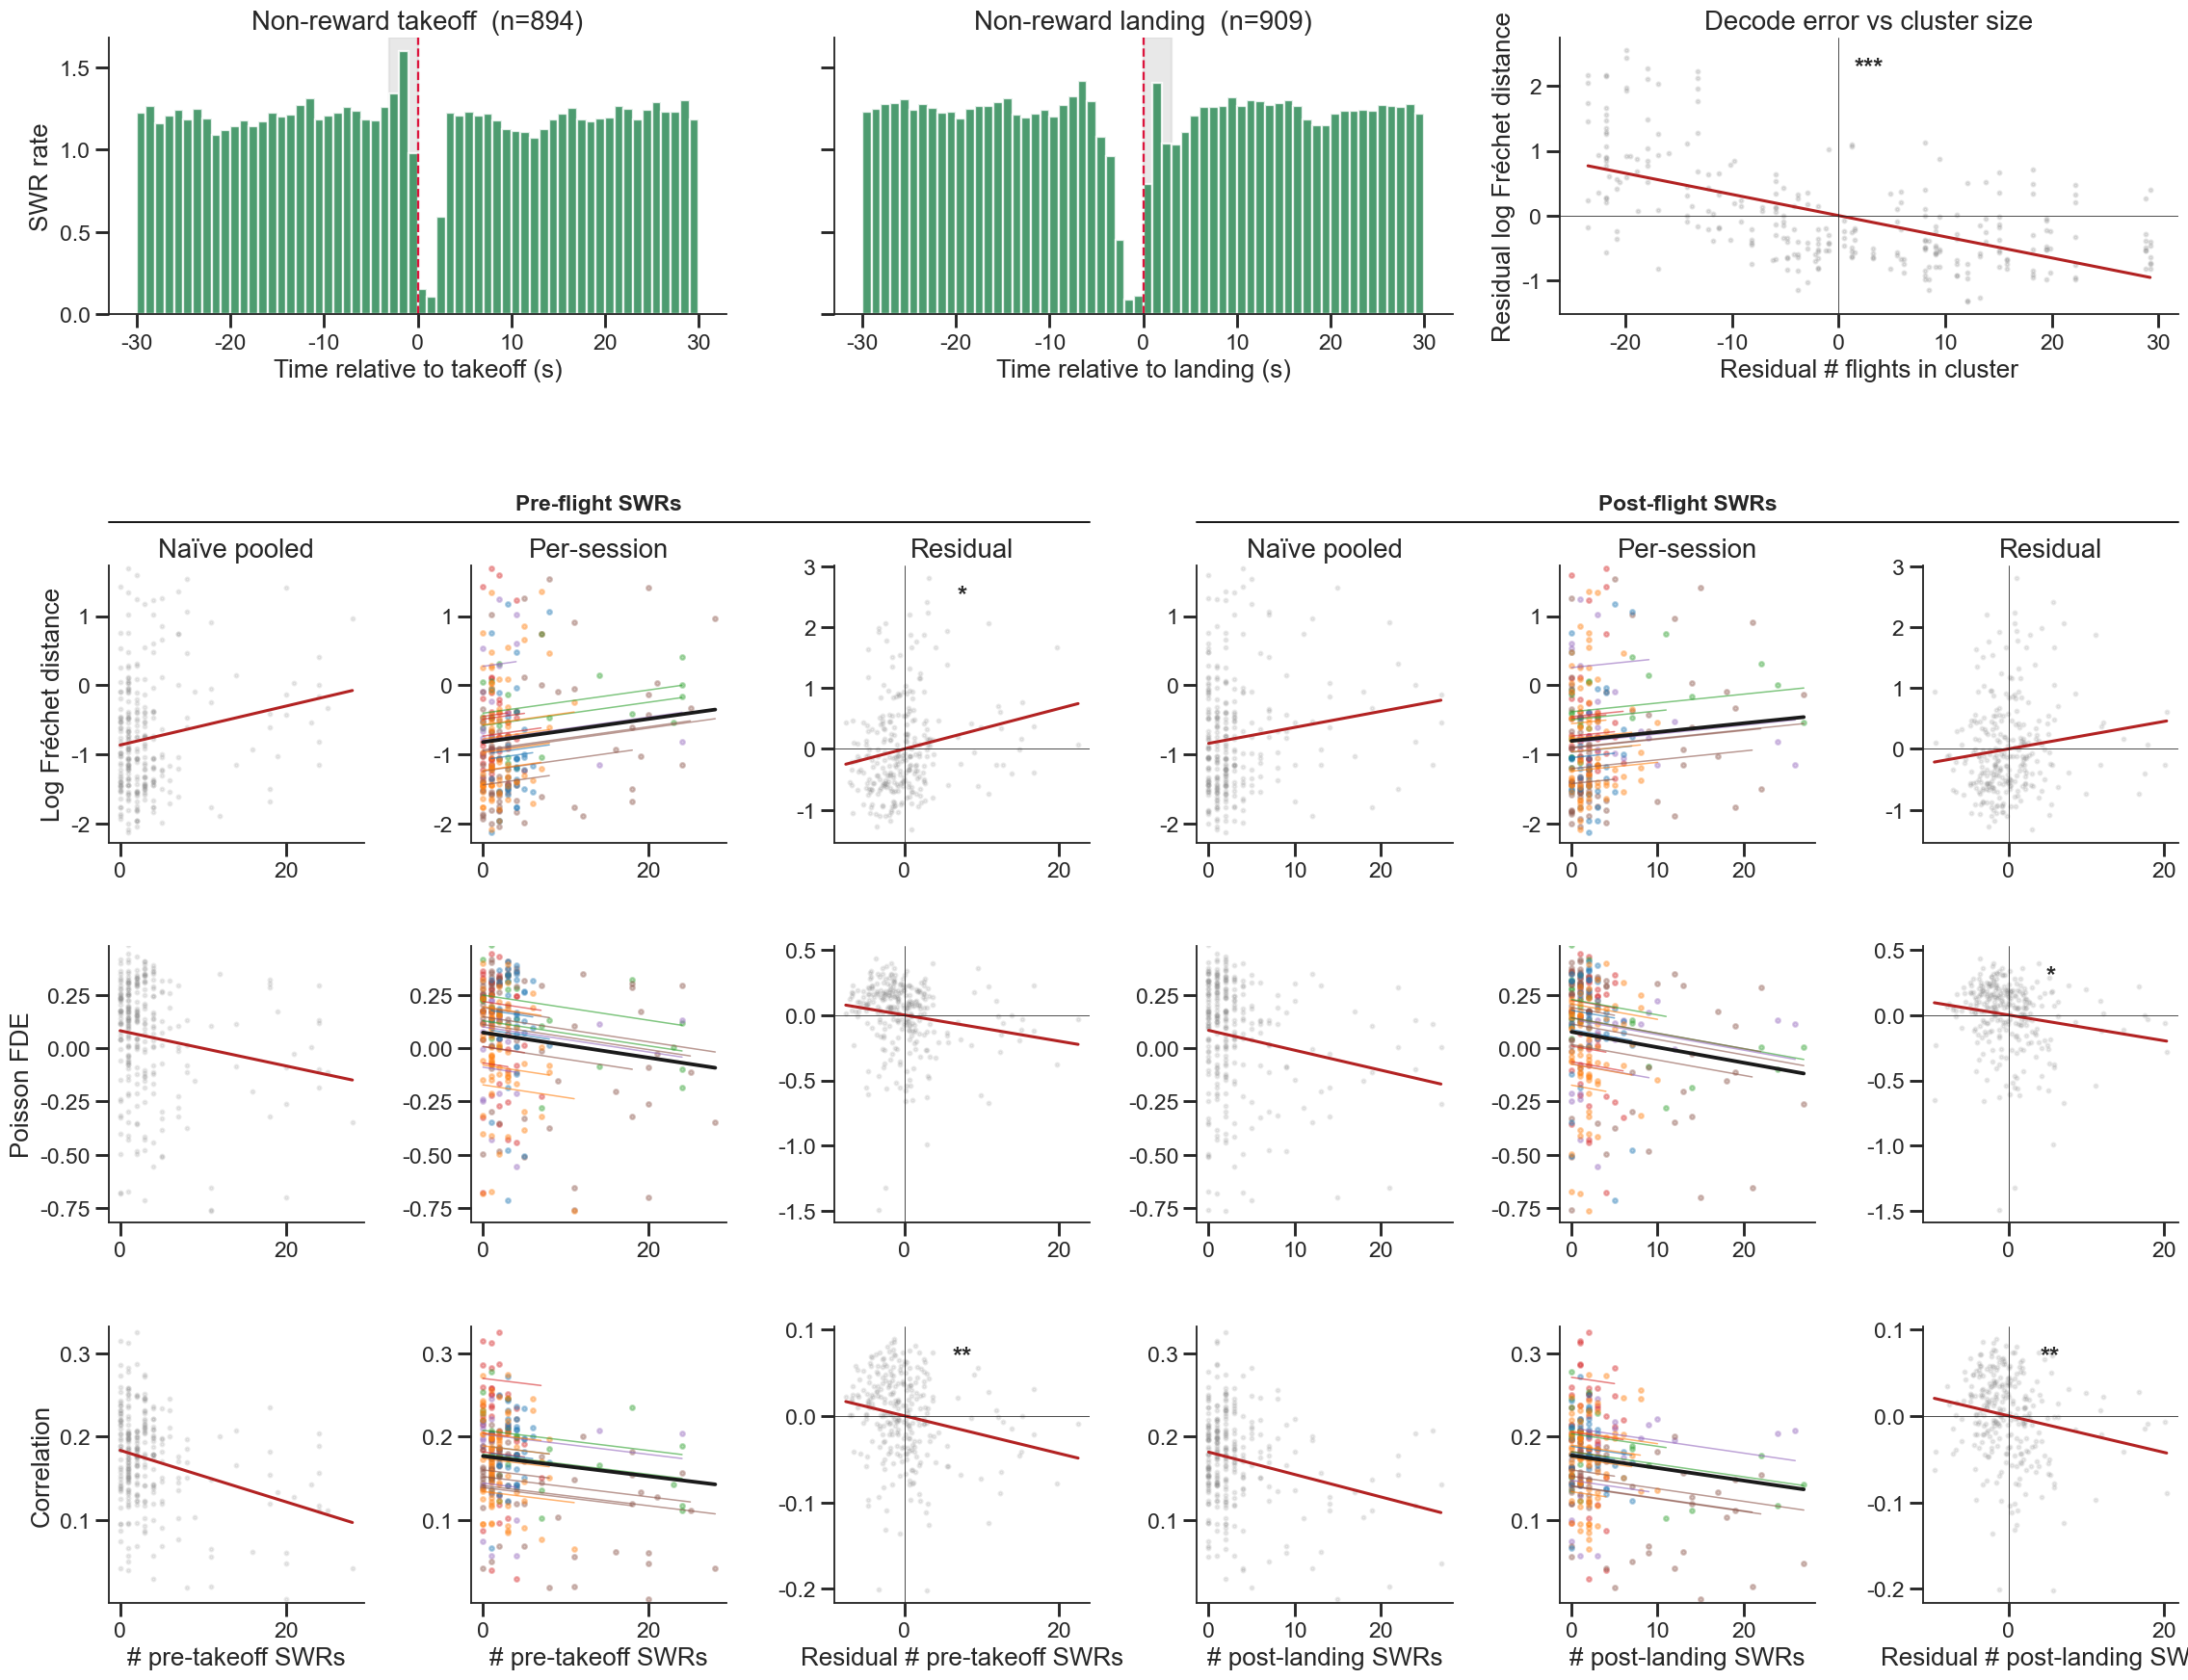

ED Fig 8 — mixed-model coefficients for #SWRs / cluster size:
panel                    outcome                    x      beta         p   n stars         P
   9c log Fréchet ~ cluster size # flights in cluster  -0.04205 1.677e-22 278   *** P < 0.001
   9d       log Fréchet distance   # pre-takeoff SWRs   0.01683   0.03375 278     * P = 0.034
   9d       log Fréchet distance  # post-landing SWRs   0.01276    0.1153 278       P = 0.115
   9e                Poisson FDE   # pre-takeoff SWRs -0.005901   0.05092 278       P = 0.051
   9e                Poisson FDE  # post-landing SWRs -0.007222   0.01927 278     * P = 0.019
   9f                Correlation   # pre-takeoff SWRs -0.001215  0.009948 278    ** P = 0.010
   9f                Correlation  # post-landing SWRs -0.001508  0.001309 278    ** P = 0.001


,panel,outcome,x,beta,p,n,stars,P
0,9c,log Fréchet ~ cluster size,# flights in cluster,-0.042051,1.676574e-22,278,***,P < 0.001
1,9d,log Fréchet distance,# pre-takeoff SWRs,0.016826,3.374710e-02,278,*,P = 0.034
2,9d,log Fréchet distance,# post-landing SWRs,0.012763,1.152506e-01,278,,P = 0.115
3,9e,Poisson FDE,# pre-takeoff SWRs,-0.005901,5.091527e-02,278,,P = 0.051
4,9e,Poisson FDE,# post-landing SWRs,-0.007222,1.926877e-02,278,*,P = 0.019
5,9f,Correlation,# pre-takeoff SWRs,-0.001215,9.948133e-03,278,**,P = 0.010
6,9f,Correlation,# post-landing SWRs,-0.001508,1.309064e-03,278,**,P = 0.001


In [49]:
# === Extended Data Figure 8 (a-g) on a single canvas ===
# Top row: a/b (non-reward peri-flight SWR PSTHs, takeoff & landing), c (decode error vs
# cluster size). Ladder rows (decode log Fréchet; encode FDE, corr): each outcome
# occupies one 6-col row, pre-flight (takeoff) triplet in cols 0-2, post-flight (landing)
# triplet in cols 3-5. Each triplet is [naïve pooled | per-session | Residual]. The per-
# session panel mirrors swr.ipynb's LMM visual: PARALLEL lines (shared fixed slope β from the
# mixed model, per-session random INTERCEPTS), not a free slope per session.
def lme_p(df, outcome, x):
    d = df.dropna(subset=[outcome, x, 'flight_frac']).copy()
    # String column instead of patsy `C()` — a notebook global `C` (cell 55) would
    # otherwise shadow patsy's categorical builtin inside the vc_formula.
    d['flight_type_str'] = d['flight_type_index'].astype(str)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        lme = smf.mixedlm(f'{outcome} ~ {x} + flight_frac', d, groups=d['session'],
                          vc_formula={'cluster': '0 + flight_type_str'}).fit(method='lbfgs', maxiter=400)
    return float(lme.params[x]), float(lme.pvalues[x]), len(d)


def ladder_triplet(axes3, df, outcome, ylabel, x, xlab, *,
                   show_titles=False, show_xlabel=False, show_ylabel=False):
    """[naïve pooled | per-session | Residual] for `outcome` vs `x`. β/p from the mixed
    model drive the per-session parallel lines and the Residual-panel significance stars."""
    d = df.dropna(subset=[outcome, x, 'flight_frac']).copy()
    # Data-driven display range for the two RAW panels (1-99th pct of the outcome, padded);
    # fits use raw values. Tighter than a fixed clip and adapts per outcome. Panels are not
    # sharey'd — the residual panel autoscales independently.
    q = np.nanquantile(d[outcome].values.astype(float), [0.01, 0.99])
    ylim = (q[0] - 0.05 * (q[1] - q[0]), q[1] + 0.05 * (q[1] - q[0])) if q[1] > q[0] else None
    beta, p, n = lme_p(d, outcome, x)

    # (0) naïve pooled: all flights pooled + single OLS fit.
    axes3[0].scatter(d[x], d[outcome], s=6, alpha=0.15, color='0.5', rasterized=True)
    cf = np.polyfit(d[x], d[outcome], 1); xs = np.linspace(d[x].min(), d[x].max(), 50)
    axes3[0].plot(xs, np.polyval(cf, xs), color='firebrick', lw=2)

    # (1) per-session: points coloured by bat + PARALLEL lines (shared LMM slope β, per-
    # session intercept = mean(y - β·x)); heavy black line = the pooled fixed-effect fit.
    for sn, g in d.groupby('session'):
        c = BAT_PALETTE.get(g['bat'].iloc[0], '0.5')
        axes3[1].scatter(g[x], g[outcome], s=9, color=c, alpha=0.35, rasterized=True)
        xg = np.array([g[x].min(), g[x].max()])
        axes3[1].plot(xg, (g[outcome] - beta * g[x]).mean() + beta * xg, color=c, lw=1, alpha=0.6)
    xg = np.array([d[x].min(), d[x].max()])
    axes3[1].plot(xg, (d[outcome] - beta * d[x]).mean() + beta * xg, 'k-', lw=2.5)

    # (2) Residual (added-variable): session + flight-fraction partialled out of both axes.
    Xc = sm.add_constant(pd.get_dummies(d['session'], drop_first=True).astype(float)
                         .assign(flight_frac=d['flight_frac'].values))
    ry = sm.OLS(d[outcome].values, Xc).fit().resid
    rx = sm.OLS(d[x].values, Xc).fit().resid
    axes3[2].scatter(rx, ry, s=6, alpha=0.15, color='0.5', rasterized=True)
    cf2 = np.polyfit(rx, ry, 1); xs2 = np.linspace(rx.min(), rx.max(), 50)
    axes3[2].plot(xs2, np.polyval(cf2, xs2), color='firebrick', lw=2)
    axes3[2].axhline(0, color='k', lw=0.5); axes3[2].axvline(0, color='k', lw=0.5)
    stars = ph.stars_for_p(p)
    if stars:
        axes3[2].text(0.5, 0.93, stars, transform=axes3[2].transAxes,
                      ha='center', va='top', fontsize=17, fontweight='bold')

    # Display range on the raw panels only; residual panel autoscales.
    if ylim is not None:
        axes3[0].set_ylim(*ylim); axes3[1].set_ylim(*ylim)
    # Shared y-label (one per row, on the far-left panel); x-labels only on the bottom row.
    if show_ylabel:
        axes3[0].set_ylabel(ylabel)
    if show_xlabel:
        axes3[0].set_xlabel(xlab); axes3[1].set_xlabel(xlab)
        axes3[2].set_xlabel(f'residual {xlab}')
    if show_titles:
        for ax, t in zip(axes3, ('naïve pooled', 'per-session', 'Residual')):
            ax.set_title(t, pad=6)
    return dict(outcome=ylabel, x=xlab, beta=beta, p=p, n=n)


# 5 grid rows: 0 = top panels, 1 = thin spacer (keeps the Pre/Post-flight headers clear of
# the top row), 2-4 = the three ladder outcomes. Explicit margins so nothing is clipped.
fig_ed9 = plt.figure(figsize=(21, 16.5))
gs_ed9 = fig_ed9.add_gridspec(5, 6, height_ratios=[1.0, 0.16, 1.0, 1.0, 1.0],
                              left=0.055, right=0.985, top=0.945, bottom=0.05,
                              hspace=0.45, wspace=0.42)

# --- Top row: a/b non-reward peri-flight SWR PSTHs; c decode error vs cluster size. ---
BW = 1.0
psth_bins = np.arange(-PSTH_WIN, PSTH_WIN + BW, BW)
psth_centers = psth_bins[:-1] + BW / 2


def nonrew_peri(edge_col, class_col):
    """Peri-flight SWR time-diffs pooled over non-reward flight edges (+ edge count)."""
    diffs, n_e = [], 0
    for sess, g in flights.groupby('session'):
        swr_t = swr_times_by_session.get(sess)
        if swr_t is None:
            continue
        e = g.loc[g[class_col] != 'reward', edge_col].values
        n_e += len(e)
        diffs.append(peri_event_diffs(e, swr_t, PSTH_WIN))
    dt = np.concatenate(diffs) if diffs else np.zeros(0)
    return dt, n_e


_ax_a = None
for j, (col, edge_col, class_col, short) in enumerate(
        [(slice(0, 2), 'start_t', 'toff_class', 'takeoff'),
         (slice(2, 4), 'stop_t', 'land_class', 'landing')]):
    ax = fig_ed9.add_subplot(gs_ed9[0, col], sharey=_ax_a)  # shared SWR-rate scale
    dt, n_e = nonrew_peri(edge_col, class_col)
    rate = np.histogram(dt, bins=psth_bins)[0] / (max(n_e, 1) * BW)
    lo, hi = (-W_PERI, 0) if short == 'takeoff' else (0, W_PERI)  # 3-s peri-flight window
    ax.axvspan(lo, hi, color='0.85', alpha=0.6, zorder=0)
    ax.bar(psth_centers, rate, width=BW, color='seagreen', alpha=0.85)
    ax.axvline(0, color='crimson', ls='--', lw=1.5)
    ax.set(xlabel=f'time relative to {short} (s)', title=f'non-reward {short}  (n={n_e})')
    if j == 0:                                   # one shared y-label for the pair
        ax.set_ylabel('SWR rate'); _ax_a = ax
    else:
        ax.tick_params(labelleft=False)

# c: decode error (log Fréchet) vs # flights in cluster, bat partialled out.
axc = fig_ed9.add_subplot(gs_ed9[0, slice(4, 6)])
dc = mf2.dropna(subset=['log_frechet', 'cluster_size']).copy()
Xc = sm.add_constant(pd.get_dummies(dc['bat'], drop_first=True).astype(float))
ry = sm.OLS(dc['log_frechet'].values, Xc).fit().resid
rx = sm.OLS(dc['cluster_size'].values.astype(float), Xc).fit().resid
axc.scatter(rx, ry, s=6, alpha=0.2, color='0.5', rasterized=True)
cf = np.polyfit(rx, ry, 1); xs = np.linspace(rx.min(), rx.max(), 50)
axc.plot(xs, np.polyval(cf, xs), color='firebrick', lw=2)
axc.axhline(0, color='k', lw=0.5); axc.axvline(0, color='k', lw=0.5)
beta_c, p_c, n_c = lme_p(dc.assign(pre_takeoff=dc['cluster_size']), 'log_frechet', 'cluster_size')
_sc = ph.stars_for_p(p_c)
if _sc:
    axc.text(0.5, 0.93, _sc, transform=axc.transAxes, ha='center', va='top',
             fontsize=17, fontweight='bold')
axc.set(xlabel='residual # flights in cluster', ylabel='residual log Fréchet distance',
        title='decode error vs cluster size')

# --- Ladder rows: decoding (log Fréchet) then encoding (FDE, corr). ---
ed9_p = [dict(panel='9c', outcome='log Fréchet ~ cluster size', x='# flights in cluster',
              beta=beta_c, p=p_c, n=n_c)]
ladder_specs = [('9d', 'log_frechet', 'log Fréchet distance'),
                ('9e', 'fde', 'Poisson FDE'), ('9f', 'corr', 'Correlation')]
sides = [('pre_takeoff', '# pre-takeoff SWRs'), ('post_landing', '# post-landing SWRs')]
for ri, (tag, col, lab) in enumerate(ladder_specs):
    grow = ri + 2                       # grid rows 2..4 (row 1 is the spacer)
    for s, (x, xlab) in enumerate(sides):
        axes3 = [fig_ed9.add_subplot(gs_ed9[grow, 3 * s + k]) for k in range(3)]
        rec = ladder_triplet(axes3, mf2, col, lab, x, xlab,
                             show_titles=(ri == 0), show_xlabel=(ri == len(ladder_specs) - 1),
                             show_ylabel=(s == 0))
        ed9_p.append(dict(panel=tag, **rec))

# Group headers spanning each triplet, in the spacer gap above the first ladder row, each
# underlined by a black rule that runs across the three columns it labels.
from matplotlib.lines import Line2D
_r1 = fig_ed9.axes[3:9]  # 3 top panels precede the 6 ladder panels of the first ladder row
for _grp, _axL, _axR in (('Pre-flight SWRs', _r1[0], _r1[2]),
                         ('Post-flight SWRs', _r1[3], _r1[5])):
    _x0, _x1 = _axL.get_position().x0, _axR.get_position().x1
    _ytop = _axL.get_position().y1
    fig_ed9.text((_x0 + _x1) / 2, _ytop + 0.030, _grp, ha='center', va='bottom',
                 fontsize=15, fontweight='bold')
    _rule = Line2D([_x0, _x1], [_ytop + 0.025] * 2, color='k', lw=1.3)
    _rule.set_transform(fig_ed9.transFigure); _rule.set_clip_on(False)
    fig_ed9.add_artist(_rule)

ph.save_fig(fig_ed9, 'edfig8_full'); plt.show()
print('ED Fig 8 — mixed-model coefficients for #SWRs / cluster size:'); ph.p_table(ed9_p)

## Extended Data Table 1 — Auxiliary masking-task sweep

Joint **Twin** model trained from scratch (1000 epochs, early stopping) at the
`base_6.3` hyperparameters (L4 / d64 / ff64, lr 4.5e-3, weight decay 3e-4, lam 0.61,
pos_weight 0.84), over `encode`+`decode` plus **every subset (0–4) of the four auxiliary
self-supervised masking tasks** `{within, cross, forecast, forecast_stim}` — 16
combinations. Scheme sampling weights are fixed at `w_encode`=1.93, `w_decode`=2.83, with
the **total auxiliary-task probability held constant** across combinations by setting
`w_aux = 0.67·3 / n_aux` (so `n_aux`=3 recovers 0.67 each). Models are selected on the
**validation** joint score `0.5·FDE/0.1 − 0.5·err/0.3`; the test column is shown for
reference. Reproduction / training code: `joint-encode-decode.ipynb` §6.8, which writes
`./out/joint/joint_scheme_sweep.pkl`. For reference, the warm-started fine-tune scores
test joint 0.127 and the `base_6.3` consensus 0.064.

In [50]:
# === Extended Data Table 1: auxiliary masking-task sweep ===
# Loads the 16-combo sweep produced by joint-encode-decode.ipynb section 6.8 and tabulates
# it. Each combo = encode+decode plus a subset of {within, cross, forecast, forecast_stim},
# trained from scratch (1000 ep, early stopping) at the base_6.3 hyperparameters; scheme
# weights w_encode=1.93, w_decode=2.83 fixed, total aux probability held constant via
# w_aux = 0.67*3/n_aux. Model selection is on validation joint (test shown for reference).
_sweep = pd.read_pickle('./out/joint/joint_scheme_sweep.pkl')
_rows = []
for _key, _rec in _sweep.items():
    _aux = [s for s in _rec['schemes'] if s not in ('encode', 'decode')]
    _rows.append({
        'auxiliary tasks': ' + '.join(_aux) if _aux else '(none)',
        'n_aux': _rec['n_aux'],
        'w_aux': round(_rec['w_aux'], 3),
        'decode err (m)': _rec['test']['err'],
        'encode FDE': _rec['test']['fde'],
        'joint (valid)': _rec['valid']['joint'],
        'joint (test)': _rec['test']['joint'],
    })
ed_table1 = (pd.DataFrame(_rows)
             .sort_values('joint (valid)', ascending=False)
             .reset_index(drop=True))
ed_table1.index += 1                       # 1-based rank
ed_table1.to_csv('out/figures/ed_table1_scheme_sweep.csv')
print(f'Extended Data Table 1 - auxiliary masking-task sweep of the {OUR_MODEL} model')
print('(model selection on validation joint; 16 combos, base_6.3 hyperparameters)')
ed_table1.round(4)

Extended Data Table 1 - auxiliary masking-task sweep of the Twin model
(model selection on validation joint; 16 combos, base_6.3 hyperparameters)


,auxiliary tasks,n_aux,w_aux,decode err (m),encode FDE,joint (valid),joint (test)
1,cross,1,2.010,0.2812,0.1093,0.0747,0.0781
2,within + cross + forecast + forecast_stim,4,0.503,0.2859,0.1139,0.0387,0.0929
3,within + forecast_stim,2,1.005,0.2878,0.1159,0.0309,0.0997
4,within + cross,2,1.005,0.2806,0.1099,0.0236,0.0815
5,cross + forecast_stim,2,1.005,0.2940,0.1084,0.0223,0.0518
6,cross + forecast,2,1.005,0.2900,0.1088,0.0108,0.0605
7,within + cross + forecast,3,0.670,0.2769,0.1129,0.0071,0.1032
8,(none),0,0.000,0.2951,0.1029,-0.0087,0.0228
9,within + forecast,2,1.005,0.3045,0.1052,-0.0094,0.0185
10,within + cross + forecast_stim,3,0.670,0.2863,0.1152,-0.0116,0.0989
